In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from pathlib import Path
from scipy.stats import spearmanr


In [2]:
# Centralized temporal configuration used across the notebook.
PERIODS = {
    "main": (2013, 2023),
    "demography_activity": (2021, 2025),
}

ANALYSIS_START_YEAR, ANALYSIS_END_YEAR = PERIODS["main"]
DEMOGRAPHY_START_YEAR, DEMOGRAPHY_END_YEAR = PERIODS["demography_activity"]
ELAPSED_ANALYSIS_YEARS = ANALYSIS_END_YEAR - ANALYSIS_START_YEAR

# Snapshot years for annual rankings (not separate growth-period definitions).
RANKING_YEARS = [ANALYSIS_START_YEAR, 2016, 2020, ANALYSIS_END_YEAR]


How has housing affordability evolved across the municipalities in the analysis sample, and how do housing costs relate to income, demographic conditions, and geographic context?

The analysis compares housing costs with municipal per-capita income. The 47-municipality sample includes municipalities with more than 30,000 residents. Barcelona's role in the wider housing market, including potential demand from international and remote workers, is a question for further analysis; these datasets do not directly measure informal housing activity or digital-nomad demand.

In [3]:
data_folder = Path(
    r"C:\Users\jejoc\Desktop\Ironhack\Final Project\Clean_data"
)

# municipality_code was standardized in the first notebook.
# Read code columns as text so leading zeros (e.g. "08015") are preserved.
analysis_universe = pd.read_csv(
    data_folder / "analysis_universe.csv",
    dtype={
        "municipality_code": "string",
        "municipality_code_habitatge": "string",
        "municipality_code_idescat": "string",
    },
)

distance_analysis = pd.read_csv(
    data_folder / "distance_analysis.csv",
    dtype={"municipality_code": "string"},
)

population_analysis = pd.read_csv(
    data_folder / "population_analysis.csv",
    dtype={"municipality_code": "string"},
)

sales_analysis = pd.read_csv(
    data_folder / "sales_analysis.csv",
    dtype={"municipality_code": "string"},
)

# Standardize the total sale-price column name (values are in thousand euros, k€).
if "price_total_k_eur" not in sales_analysis.columns and "price_total" in sales_analysis.columns:
    sales_analysis = sales_analysis.rename(
        columns={"price_total": "price_total_k_eur"}
    )

rent_analysis = pd.read_csv(
    data_folder / "rent_analysis.csv",
    dtype={"municipality_code": "string"},
)

rent_analysis["rent_growth_pct"] = (
    rent_analysis
    .sort_values(["municipality_code", "year"])
    .groupby("municipality_code")["rent_mean"]
    .pct_change()
    .mul(100)
    .reindex(rent_analysis.index)
)

income_analysis = pd.read_csv(
    data_folder / "income_analysis.csv",
    dtype={"municipality_code": "string"},
)

demographic_analysis = pd.read_csv(
    data_folder / "demographic_analysis.csv",
    dtype={"municipality_code": "string"},
)

activity_analysis = pd.read_csv(
    data_folder / "activity_analysis.csv",
    dtype={"municipality_code": "string"},
)

contracts_by_year = pd.read_csv(
    data_folder / "contracts_by_year.csv"
)

mortgages_by_year = pd.read_csv(
    data_folder / "mortgages_by_year.csv"
)

# Preserve the loaded cleaned datasets before deriving the main analysis window.
# Demographic and economic-activity datasets intentionally retain their 2021-2025 coverage.
population_analysis_all_years = population_analysis.copy()
sales_analysis_all_years = sales_analysis.copy()
rent_analysis_all_years = rent_analysis.copy()
income_analysis_all_years = income_analysis.copy()
contracts_by_year_all_years = contracts_by_year.copy()
mortgages_by_year_all_years = mortgages_by_year.copy()

# Use 2013-2023 for the main time-series and endpoint comparisons.
population_analysis = population_analysis_all_years.loc[
    population_analysis_all_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()
sales_analysis = sales_analysis_all_years.loc[
    sales_analysis_all_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()
rent_analysis = rent_analysis_all_years.loc[
    rent_analysis_all_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()
# Recompute year-over-year rent growth within the analysis window; 2013 has no in-window prior year.
rent_analysis["rent_growth_pct"] = (
    rent_analysis.sort_values(["municipality_code", "year"])
    .groupby("municipality_code")["rent_mean"]
    .pct_change()
    .mul(100)
    .reindex(rent_analysis.index)
)
income_analysis = income_analysis_all_years.loc[
    income_analysis_all_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()
contracts_by_year = contracts_by_year_all_years.loc[
    contracts_by_year_all_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()
mortgages_by_year = mortgages_by_year_all_years.loc[
    mortgages_by_year_all_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()


In [4]:
datasets = {
    "analysis_universe": analysis_universe,
    "population_analysis": population_analysis,
    "sales_analysis": sales_analysis,
    "rent_analysis": rent_analysis,
    "income_analysis": income_analysis,
    "demographic_analysis": demographic_analysis,
    "activity_analysis": activity_analysis,
    "contracts_by_year": contracts_by_year,
    "mortgages_by_year": mortgages_by_year,
    "distance_analysis": distance_analysis
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


analysis_universe: (47, 5)
population_analysis: (517, 4)
sales_analysis: (517, 18)
rent_analysis: (517, 7)
income_analysis: (517, 6)
demographic_analysis: (235, 8)
activity_analysis: (235, 6)
contracts_by_year: (11, 4)
mortgages_by_year: (11, 5)
distance_analysis: (47, 6)


In [5]:
# Validate canonical municipality keys, time coverage, and municipality-year uniqueness.
# municipality_code is already the canonical five-digit key from the first notebook.
expected_municipality_codes = set(
    analysis_universe["municipality_code"].dropna()
)
assert len(expected_municipality_codes) == 47, (
    "analysis_universe must contain 47 unique canonical municipality codes"
)
assert analysis_universe["municipality_code"].str.fullmatch(
    r"\d{5}", na=False
).all(), "analysis_universe contains non-canonical municipality codes"

canonical_key_datasets = {
    "distance_analysis": distance_analysis,
    "population_analysis": population_analysis,
    "sales_analysis": sales_analysis,
    "rent_analysis": rent_analysis,
    "income_analysis": income_analysis,
    "demographic_analysis": demographic_analysis,
    "activity_analysis": activity_analysis,
}
for name, frame in canonical_key_datasets.items():
    codes = frame["municipality_code"]
    invalid = codes.isna() | ~codes.str.fullmatch(r"\d{5}", na=False)
    assert not invalid.any(), (
        f"{name} contains missing or non-canonical municipality codes: "
        f"{codes[invalid].drop_duplicates().tolist()[:10]}"
    )
    observed_codes = set(codes.dropna())
    assert observed_codes == expected_municipality_codes, (
        f"{name} municipality codes do not match analysis_universe. "
        f"Missing={sorted(expected_municipality_codes - observed_codes)[:10]}, "
        f"extra={sorted(observed_codes - expected_municipality_codes)[:10]}"
    )

main_municipal_datasets = {
    "population_analysis": population_analysis,
    "sales_analysis": sales_analysis,
    "rent_analysis": rent_analysis,
    "income_analysis": income_analysis,
}
expected_main_years = set(range(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR + 1))

for name, frame in main_municipal_datasets.items():
    observed_years = set(frame["year"].dropna().astype(int))
    missing_years = sorted(expected_main_years - observed_years)
    duplicate_keys = frame.duplicated(["municipality_code", "year"]).sum()
    municipality_counts = frame.groupby("year")["municipality_code"].nunique()
    print(
        f"{name}: rows={len(frame)}, years={min(observed_years)}–{max(observed_years)}, "
        f"municipalities/year={municipality_counts.min()}–{municipality_counts.max()}, "
        f"duplicate municipality-year keys={duplicate_keys}, missing expected years={missing_years}"
    )
    assert not missing_years, f"{name} is missing expected main-period years: {missing_years}"
    assert duplicate_keys == 0, f"{name} contains duplicate municipality-year keys"
    assert municipality_counts.eq(47).all(), f"{name} does not contain 47 municipalities in every year"

expected_demographic_years = set(range(DEMOGRAPHY_START_YEAR, DEMOGRAPHY_END_YEAR + 1))
for name, frame in {"demographic_analysis": demographic_analysis, "activity_analysis": activity_analysis}.items():
    observed_years = set(frame["year"].dropna().astype(int))
    municipality_counts = frame.groupby("year")["municipality_code"].nunique()
    print(
        f"{name}: coverage={min(observed_years)}–{max(observed_years)}, rows={len(frame)}, "
        f"municipalities/year={municipality_counts.min()}–{municipality_counts.max()}"
    )
    assert observed_years == expected_demographic_years, (
        f"{name} coverage does not match the configured 2021-2025 period"
    )
    assert municipality_counts.eq(47).all(), (
        f"{name} does not contain all 47 municipalities in every year"
    )


population_analysis: rows=517, years=2013–2023, municipalities/year=47–47, duplicate municipality-year keys=0, missing expected years=[]
sales_analysis: rows=517, years=2013–2023, municipalities/year=47–47, duplicate municipality-year keys=0, missing expected years=[]
rent_analysis: rows=517, years=2013–2023, municipalities/year=47–47, duplicate municipality-year keys=0, missing expected years=[]
income_analysis: rows=517, years=2013–2023, municipalities/year=47–47, duplicate municipality-year keys=0, missing expected years=[]
demographic_analysis: coverage=2021–2025, rows=235, municipalities/year=47–47
activity_analysis: coverage=2021–2025, rows=235, municipalities/year=47–47


# Exploratory Data Analysis (EDA)

This section combines the cleaned datasets to examine housing affordability and differences across the 47 municipalities with populations above 30,000. Rental contracts and mortgage totals are regional aggregates rather than municipality-level data.

## Population
- Undestrand if there is a population growth.

In [6]:
population_analysis.info()


<class 'pandas.core.frame.DataFrame'>
Index: 517 entries, 0 to 516
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   municipality_code  517 non-null    string
 1   municipality       517 non-null    object
 2   year               517 non-null    int64 
 3   population         517 non-null    int64 
dtypes: int64(2), object(1), string(1)
memory usage: 20.2+ KB


In [7]:
population_evolution = (
    population_analysis
    .groupby("year")["population"]
    .sum()
    .reset_index(name="population")
)

# Calculate year-over-year population growth.
population_evolution["annual_growth_pct"] = (
    population_evolution["population"].pct_change() * 100
)

# Calculate cumulative growth relative to 2013.
population_evolution["cumulative_growth_pct"] = (
    (
        population_evolution["population"]
        / population_evolution.loc[
            population_evolution["year"] == ANALYSIS_START_YEAR,
            "population",
        ].iloc[0]
        - 1
    )
    * 100
)


In [8]:
population_evolution.style.format(
    {
        "population": "{:,.0f}",
        "annual_growth_pct": "{:+.2f}%",
        "cumulative_growth_pct": "{:+.2f}%",
    }
)


,year,population,annual_growth_pct,cumulative_growth_pct
0,2013,"4,922,607",+nan%,+0.00%
1,2014,"4,899,561",-0.47%,-0.47%
2,2015,"4,893,782",-0.12%,-0.59%
3,2016,"4,909,920",+0.33%,-0.26%
4,2017,"4,935,970",+0.53%,+0.27%
5,2018,"4,965,211",+0.59%,+0.87%
6,2019,"5,017,464",+1.05%,+1.93%
7,2020,"5,092,168",+1.49%,+3.44%
8,2021,"5,053,287",-0.76%,+2.65%
9,2022,"5,060,147",+0.14%,+2.79%


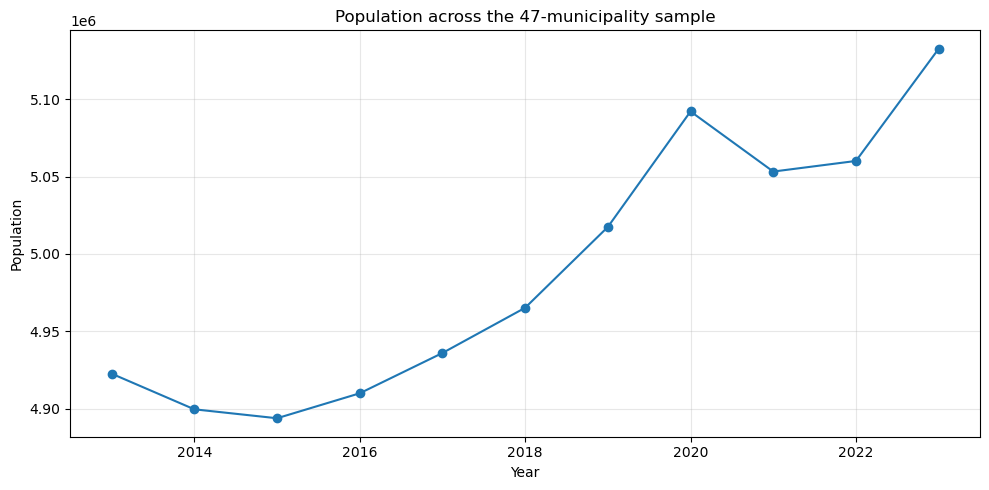

In [9]:
ax = population_evolution.plot(
    x="year",
    y="population",
    kind="line",
    marker="o",
    figsize=(10, 5),
    legend=False,
)
ax.set_title("Population across the 47-municipality sample")
ax.set_xlabel("Year")
ax.set_ylabel("Population")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


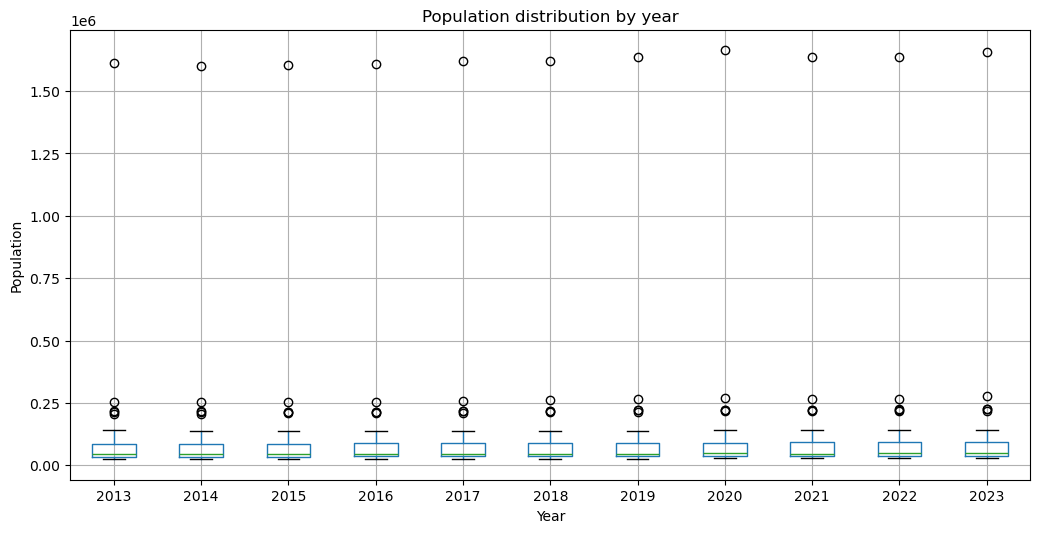

In [10]:
population_analysis.boxplot(
    column="population",
    by="year",
    figsize=(12, 6),
)

plt.title("Population distribution by year")
plt.suptitle("")
plt.xlabel("Year")
plt.ylabel("Population")
plt.show()


In [11]:
population_analysis_no_bcn = population_analysis[
    population_analysis["municipality"] != "Barcelona"
].copy()


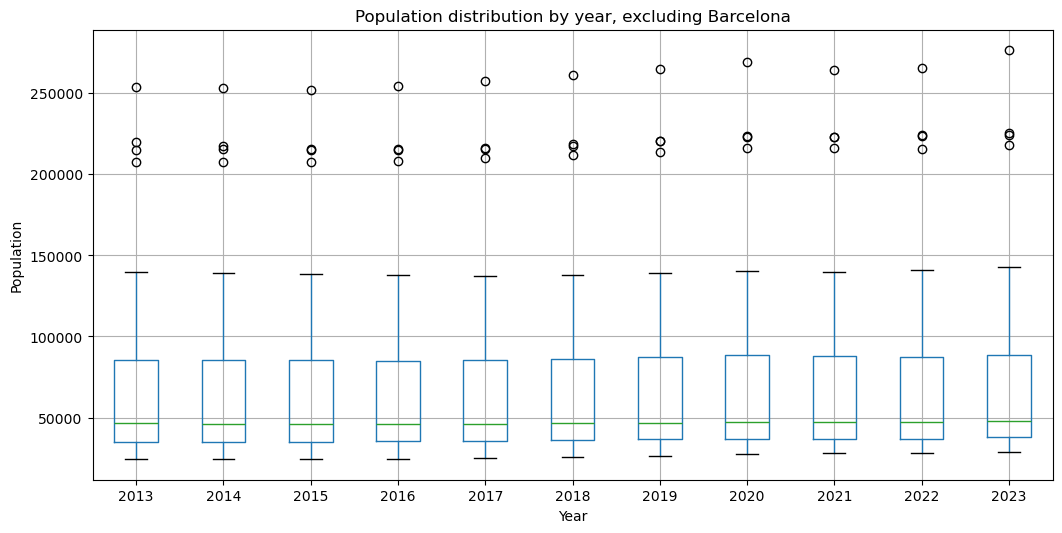

In [12]:
population_analysis_no_bcn.boxplot(
    column="population",
    by="year",
    figsize=(12, 6),
)

plt.title("Population distribution by year, excluding Barcelona")
plt.suptitle("")
plt.xlabel("Year")
plt.ylabel("Population")
plt.show()


In [13]:
population_plot = (
    population_analysis
    .pivot(
        index="year",
        columns="municipality",
        values="population"
    )
)

population_plot


municipality,Badalona,Barberà del Vallès,Barcelona,Blanes,Calafell,Cambrils,Castelldefels,Cerdanyola del Vallès,Cornellà de Llobregat,Esplugues de Llobregat,...,Santa Coloma de Gramenet,Sitges,Tarragona,Terrassa,Tortosa,"Vendrell, el",Vic,Viladecans,Vilafranca del Penedès,Vilanova i la Geltrú
year,,,,,,,,,,,,,,,,,,,,,
2013,219708,32580,1611822,39660,24563,33775,63077,57642,86687,46667,...,120029,29140,133545,215055,33992,36747,41647,65444,38929,66275
2014,217210,32550,1602386,39293,24333,33301,63255,57402,86234,46133,...,118738,28171,132199,215517,33932,36719,41956,65358,39221,65941
2015,215654,32545,1604555,39132,24256,32915,63891,57413,86376,45626,...,116950,28269,131255,215214,33864,36558,42498,65549,39224,65684
2016,215634,32832,1608746,39060,24289,33273,64892,57543,86072,45733,...,117153,28478,131094,215121,33743,36482,43287,65779,39365,65972
2017,215848,32860,1620809,38813,24898,32855,65954,57723,86610,45890,...,117597,28527,131507,216428,33445,36568,43964,65993,39532,66077
2018,217741,32839,1620343,38790,25444,33362,66375,57740,87173,46355,...,118821,28969,132299,218535,33510,37153,45040,66168,40055,66274
2019,220440,33091,1636762,39028,26538,33898,67004,57403,88592,46680,...,119215,29307,134515,220556,33372,37606,46214,66611,39746,67086
2020,223166,33334,1664182,39914,27601,34734,67460,57855,89936,47150,...,120443,29553,136496,223627,33439,38373,47630,67197,40154,67733
2021,223006,33016,1636732,40274,28463,35064,67226,57217,89300,46777,...,119289,30217,135436,223011,33572,38891,47319,66707,39969,67458


In [14]:
population_barcelona = (
    population_analysis
    .assign(
        group=lambda frame: np.where(
            frame["municipality"].eq("Barcelona"),
            "Barcelona",
            "Other municipalities",
        )
    )
    .groupby(["year", "group"])["population"]
    .sum()
    .unstack()
    .reset_index()
)

population_barcelona["Total"] = (
    population_barcelona["Barcelona"]
    + population_barcelona["Other municipalities"]
)
population_barcelona["Barcelona_pct"] = (
    population_barcelona["Barcelona"] / population_barcelona["Total"] * 100
)
population_barcelona["Other_municipalities_pct"] = (
    population_barcelona["Other municipalities"]
    / population_barcelona["Total"]
    * 100
)


In [15]:
population_barcelona.style.format(
    {
        "Barcelona": "{:,.0f}",
        "Other municipalities": "{:,.0f}",
        "Total": "{:,.0f}",
        "Barcelona_pct": "{:.2f}%",
        "Other_municipalities_pct": "{:.2f}%",
    }
)


group,year,Barcelona,Other municipalities,Total,Barcelona_pct,Other_municipalities_pct
0,2013,"1,611,822","3,310,785","4,922,607",32.74%,67.26%
1,2014,"1,602,386","3,297,175","4,899,561",32.70%,67.30%
2,2015,"1,604,555","3,289,227","4,893,782",32.79%,67.21%
3,2016,"1,608,746","3,301,174","4,909,920",32.77%,67.23%
4,2017,"1,620,809","3,315,161","4,935,970",32.84%,67.16%
5,2018,"1,620,343","3,344,868","4,965,211",32.63%,67.37%
6,2019,"1,636,762","3,380,702","5,017,464",32.62%,67.38%
7,2020,"1,664,182","3,427,986","5,092,168",32.68%,67.32%
8,2021,"1,636,732","3,416,555","5,053,287",32.39%,67.61%
9,2022,"1,636,193","3,423,954","5,060,147",32.33%,67.67%


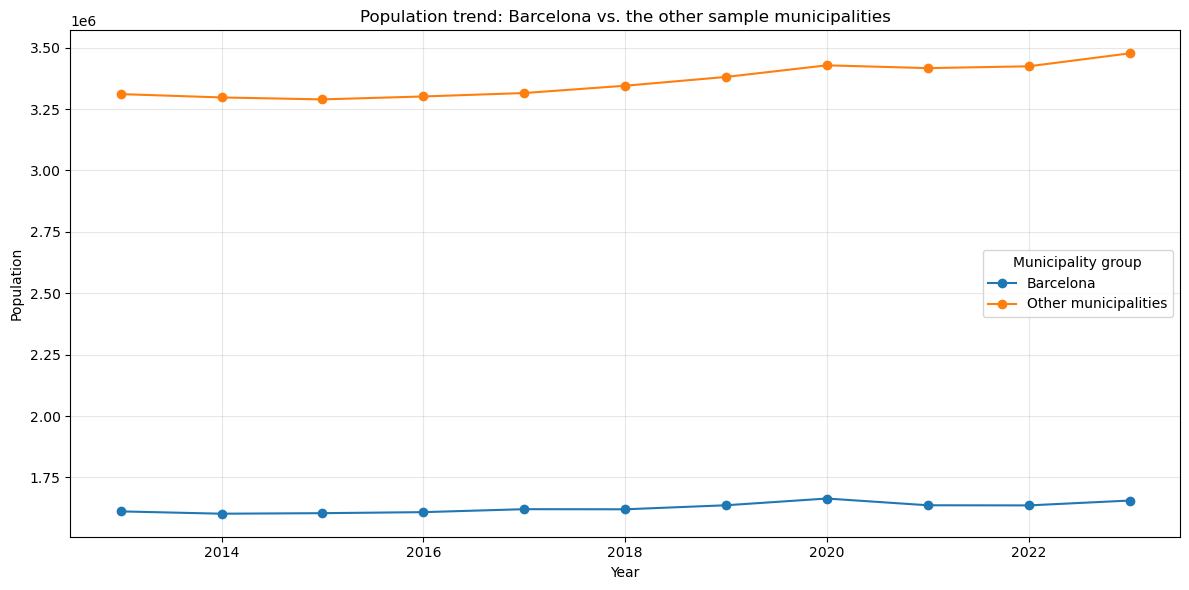

In [16]:
population_barcelona.plot(
    x="year",
    y=["Barcelona", "Other municipalities"],
    kind="line",
    marker="o",
    figsize=(12, 6),
)

plt.title("Population trend: Barcelona vs. the other sample municipalities")
plt.xlabel("Year")
plt.ylabel("Population")
plt.legend(title="Municipality group")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:
population_barcelona_index = population_barcelona.copy()

population_barcelona_index["Barcelona_index"] = (
    population_barcelona_index["Barcelona"]
    / population_barcelona_index.loc[
        population_barcelona_index["year"] == ANALYSIS_START_YEAR,
        "Barcelona",
    ].iloc[0]
    * 100
)
population_barcelona_index["Other_municipalities_index"] = (
    population_barcelona_index["Other municipalities"]
    / population_barcelona_index.loc[
        population_barcelona_index["year"] == ANALYSIS_START_YEAR,
        "Other municipalities",
    ].iloc[0]
    * 100
)


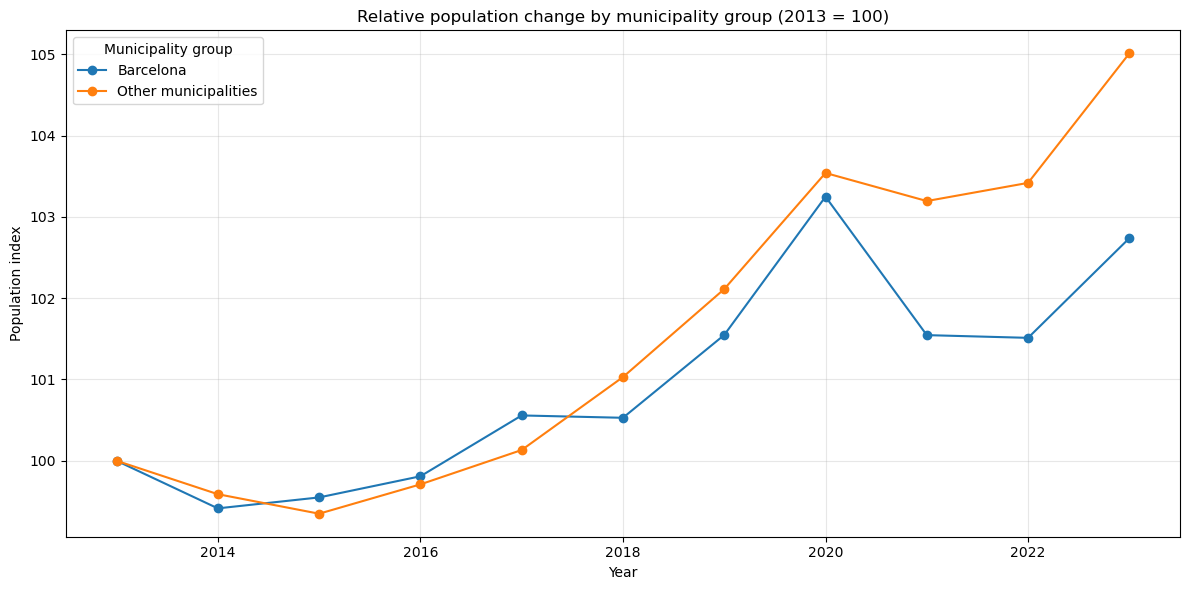

In [18]:
population_index_plot = population_barcelona_index[
    ["year", "Barcelona_index", "Other_municipalities_index"]
].rename(
    columns={
        "Barcelona_index": "Barcelona",
        "Other_municipalities_index": "Other municipalities",
    }
)

population_index_plot.plot(
    x="year",
    y=["Barcelona", "Other municipalities"],
    kind="line",
    marker="o",
    figsize=(12, 6),
)

plt.title("Relative population change by municipality group (2013 = 100)")
plt.xlabel("Year")
plt.ylabel("Population index")
plt.legend(title="Municipality group")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:
# Rank municipalities by population growth.


In [20]:
population_growth_municipality = (
    population_analysis
    .pivot(
        index="municipality",
        columns="year",
        values="population"
    )
    .reset_index()
)

population_growth_municipality


year,municipality,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Badalona,219708,217210,215654,215634,215848,217741,220440,223166,223006,223506,224301
1,Barberà del Vallès,32580,32550,32545,32832,32860,32839,33091,33334,33016,33082,33353
2,Barcelona,1611822,1602386,1604555,1608746,1620809,1620343,1636762,1664182,1636732,1636193,1655956
3,Blanes,39660,39293,39132,39060,38813,38790,39028,39914,40274,40579,41517
4,Calafell,24563,24333,24256,24289,24898,25444,26538,27601,28463,29102,30482
5,Cambrils,33775,33301,32915,33273,32855,33362,33898,34734,35064,35675,36441
6,Castelldefels,63077,63255,63891,64892,65954,66375,67004,67460,67226,67307,68327
7,Cerdanyola del Vallès,57642,57402,57413,57543,57723,57740,57403,57855,57217,57291,57752
8,Cornellà de Llobregat,86687,86234,86376,86072,86610,87173,88592,89936,89300,89039,90076
9,Esplugues de Llobregat,46667,46133,45626,45733,45890,46355,46680,47150,46777,46414,46968


In [21]:
population_growth_municipality["absolute_change"] = (
    population_growth_municipality[ANALYSIS_END_YEAR]
    - population_growth_municipality[ANALYSIS_START_YEAR]
)

population_growth_municipality["cumulative_growth_pct"] = (
    (
        population_growth_municipality[ANALYSIS_END_YEAR]
        / population_growth_municipality[ANALYSIS_START_YEAR]
        - 1
    ) * 100
)

elapsed_years = ELAPSED_ANALYSIS_YEARS
ratio = (
    population_growth_municipality[ANALYSIS_END_YEAR]
    / population_growth_municipality[ANALYSIS_START_YEAR].where(
        population_growth_municipality[ANALYSIS_START_YEAR].ne(0)
    )
)
population_growth_municipality["annualized_growth_pct"] = (
    ratio.pow(1 / elapsed_years) - 1
) * 100

top_10_growth = (
    population_growth_municipality
    .nlargest(10, "cumulative_growth_pct")
    [["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "absolute_change",
      "cumulative_growth_pct", "annualized_growth_pct"]]
    .reset_index(drop=True)
)

top_10_growth.style.format({
    ANALYSIS_START_YEAR: "{:,.0f}",
    ANALYSIS_END_YEAR: "{:,.0f}",
    "absolute_change": "{:+,.0f}",
    "cumulative_growth_pct": "{:+.2f}%",
    "annualized_growth_pct": "{:+.2f}%",
})


year,municipality,2013,2023,absolute_change,cumulative_growth_pct,annualized_growth_pct
0,Calafell,"24,563","30,482","+5,919",+24.10%,+2.18%
1,Vic,"41,647","48,235","+6,588",+15.82%,+1.48%
2,Sant Cugat del Vallès,"86,108","97,579","+11,471",+13.32%,+1.26%
3,Salou,"26,752","30,087","+3,335",+12.47%,+1.18%
4,Olot,"33,981","38,003","+4,022",+11.84%,+1.12%
5,Sant Pere de Ribes,"28,730","31,702","+2,972",+10.34%,+0.99%
6,Pineda de Mar,"26,157","28,840","+2,683",+10.26%,+0.98%
7,Salt,"30,247","33,337","+3,090",+10.22%,+0.98%
8,Sitges,"29,140","32,086","+2,946",+10.11%,+0.97%
9,"Hospitalet de Llobregat, l'","254,056","276,617","+22,561",+8.88%,+0.85%


In [22]:
# The municipality growth table is created in the preceding cell using the full analysis period.
top_10_growth_pct = (
    population_growth_municipality
    .nlargest(10, "cumulative_growth_pct")
    [["municipality", "cumulative_growth_pct", "annualized_growth_pct"]]
    .reset_index(drop=True)
)

top_10_growth_pct.style.format({
    "cumulative_growth_pct": "{:+.2f}%",
    "annualized_growth_pct": "{:+.2f}%",
})


year,municipality,cumulative_growth_pct,annualized_growth_pct
0,Calafell,+24.10%,+2.18%
1,Vic,+15.82%,+1.48%
2,Sant Cugat del Vallès,+13.32%,+1.26%
3,Salou,+12.47%,+1.18%
4,Olot,+11.84%,+1.12%
5,Sant Pere de Ribes,+10.34%,+0.99%
6,Pineda de Mar,+10.26%,+0.98%
7,Salt,+10.22%,+0.98%
8,Sitges,+10.11%,+0.97%
9,"Hospitalet de Llobregat, l'",+8.88%,+0.85%


In [23]:
# Use the same cumulative and annualized metrics for the opposite end of the ranking.
bottom_10_growth_pct = population_growth_municipality.nsmallest(10, "cumulative_growth_pct")


In [24]:
bottom_10_growth_pct[
    ["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR,
     "cumulative_growth_pct", "annualized_growth_pct"]
].style.format({
    ANALYSIS_START_YEAR: "{:,.0f}",
    ANALYSIS_END_YEAR: "{:,.0f}",
    "cumulative_growth_pct": "{:+.2f}%",
    "annualized_growth_pct": "{:+.2f}%",
})


year,municipality,2013,2023,cumulative_growth_pct,annualized_growth_pct
37,Santa Coloma de Gramenet,"120,029","119,195",-0.69%,-0.07%
20,Mollet del Vallès,"51,954","51,692",-0.50%,-0.05%
7,Cerdanyola del Vallès,"57,642","57,752",+0.19%,+0.02%
32,Sant Boi de Llobregat,"83,408","83,667",+0.31%,+0.03%
9,Esplugues de Llobregat,"46,667","46,968",+0.64%,+0.06%
17,Lloret de Mar,"40,803","41,159",+0.87%,+0.09%
25,Reus,"106,790","108,535",+1.63%,+0.16%
44,Viladecans,"65,444","66,615",+1.79%,+0.18%
0,Badalona,"219,708","224,301",+2.09%,+0.21%
16,Lleida,"139,809","142,990",+2.28%,+0.23%


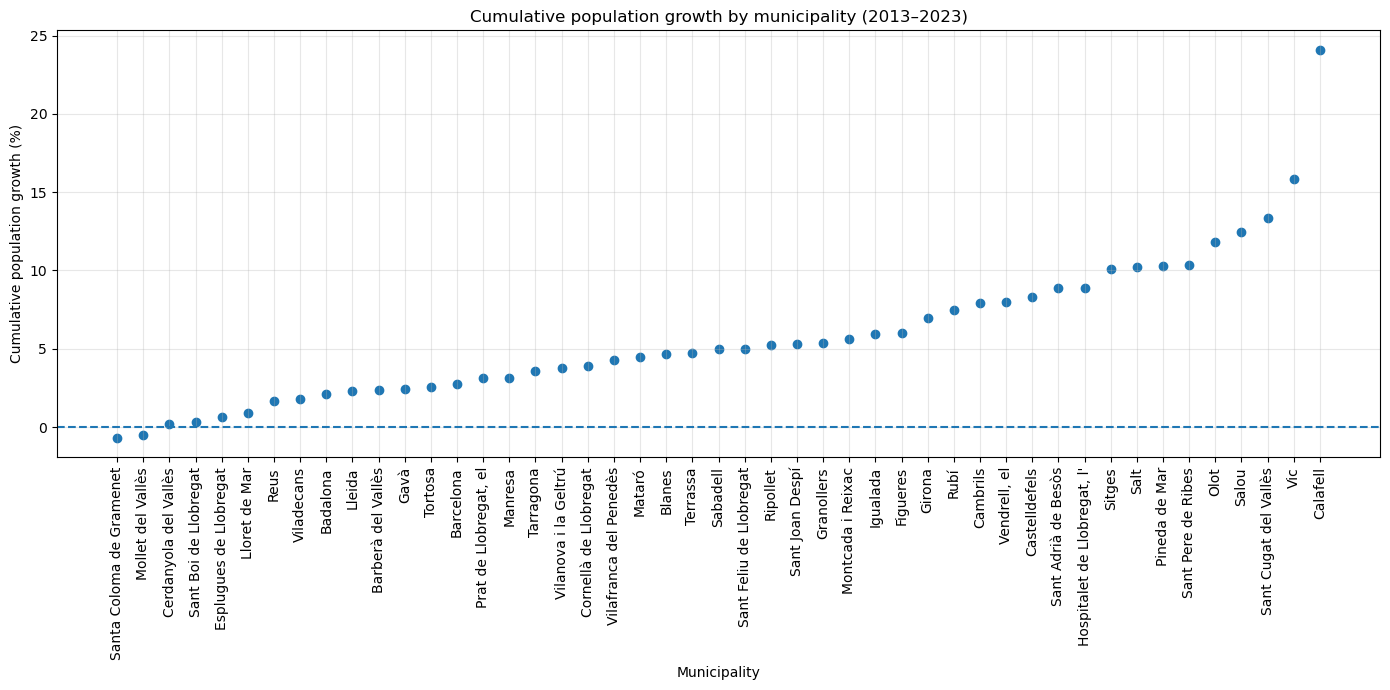

In [25]:
population_growth_plot = (
    population_growth_municipality
    .sort_values("cumulative_growth_pct")
    .copy()
)

plt.figure(figsize=(14, 7))
plt.scatter(
    population_growth_plot["municipality"],
    population_growth_plot["cumulative_growth_pct"],
)
plt.axhline(0, linestyle="--")
plt.title(f"Cumulative population growth by municipality ({ANALYSIS_START_YEAR}–{ANALYSIS_END_YEAR})")
plt.xlabel("Municipality")
plt.ylabel("Cumulative population growth (%)")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Housing Market

In [26]:
sales_analysis["municipality"] = (
    sales_analysis["municipality"]
    .replace("Tarragona (1)", "Tarragona")
)


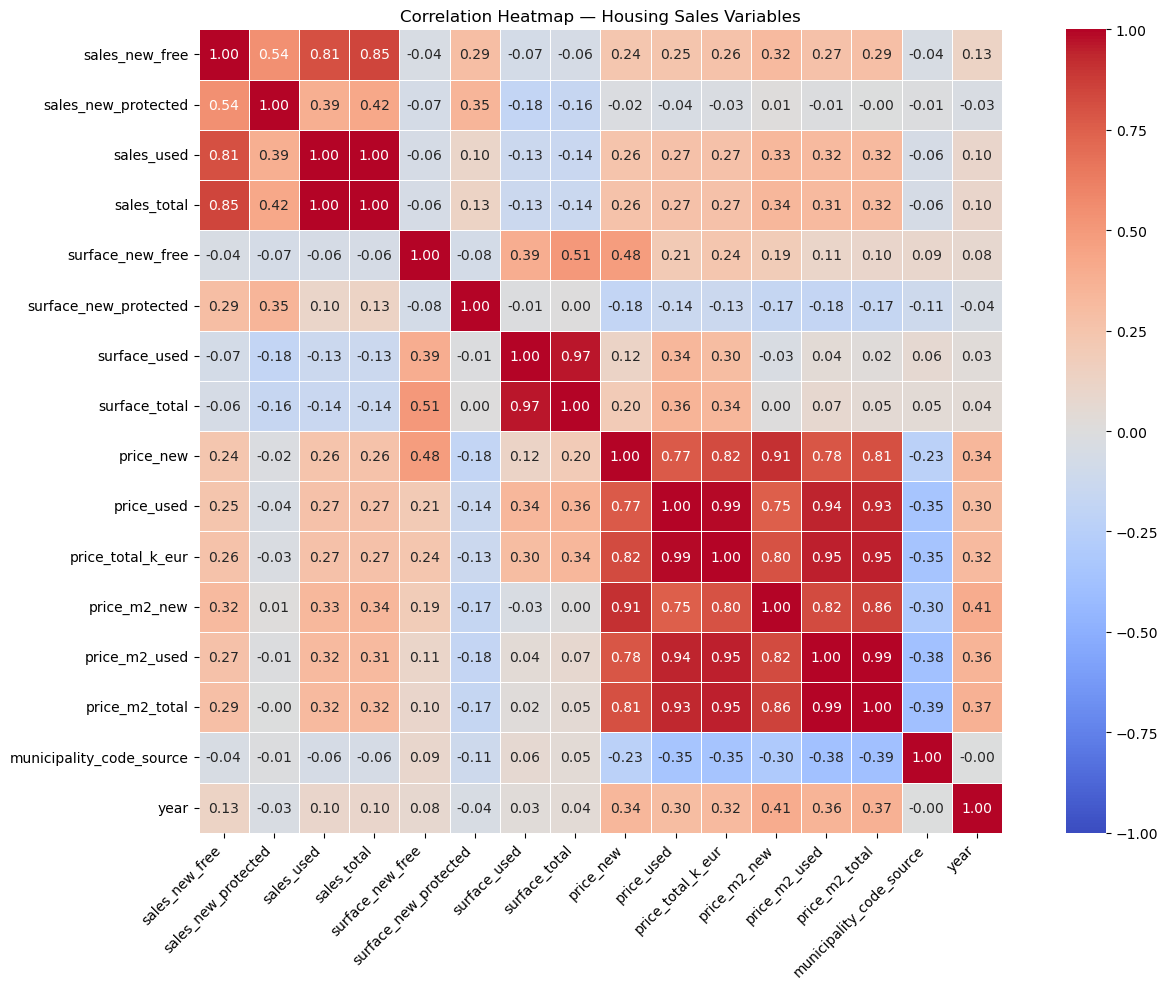

In [27]:
# Select numerical variables from the housing sales dataset
sales_numeric = sales_analysis.select_dtypes(include="number")

# Calculate the Pearson correlation matrix
correlation_matrix = sales_numeric.corr(method="pearson")

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Housing Sales Variables")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:
sales_analysis.head()


,municipality_code,sales_new_free,sales_new_protected,sales_used,sales_total,surface_new_free,surface_new_protected,surface_used,surface_total,price_new,price_used,price_total_k_eur,price_m2_new,price_m2_used,price_m2_total,municipality_code_source,year,municipality
0,08015,154,24,662,840,88.68,66.69,74.04,76.50,184.44551,131.78783,142.91143,2016.17,1725.55,1786.94,8015,2013,Badalona
1,08252,66,6,106,178,97.33,76.00,94.48,94.89,150.12309,119.27174,132.07400,1622.47,1239.43,1398.38,8252,2013,Barberà del Vallès
2,08019,1120,87,7701,8908,84.17,73.12,81.37,81.64,279.49070,243.12966,248.96199,3197.49,2627.54,2718.96,8019,2013,Barcelona
3,17023,77,0,264,341,56.68,0.00,72.71,69.01,127.43898,158.94593,151.53253,2254.34,2044.83,2094.13,17023,2013,Blanes
4,43037,213,5,154,372,91.87,60.20,100.71,94.94,122.75471,122.55700,122.67491,1455.09,1331.18,1405.08,43037,2013,Calafell


In [29]:
sales_analysis[
    [
        "year",
        "sales_new_free",
        "sales_new_protected",
        "sales_used",
        "sales_total"
    ]
].describe()


,year,sales_new_free,sales_new_protected,sales_used,sales_total
count,517.00000,517.000000,517.000000,517.000000,517.000000
mean,2018.00000,144.493230,12.698259,806.678917,963.870406
std,3.16534,198.063245,26.878456,1728.967739,1903.775231
min,2013.00000,0.000000,0.000000,4.000000,75.000000
25%,2015.00000,31.000000,0.000000,268.000000,346.000000
50%,2018.00000,75.000000,3.000000,415.000000,510.000000
75%,2021.00000,177.000000,11.000000,717.000000,848.000000
max,2023.00000,1493.000000,258.000000,14511.000000,16029.000000


In [30]:
top_10_sales_2023 = (
    sales_analysis[
        sales_analysis["year"] == ANALYSIS_END_YEAR
    ]
    .sort_values("sales_total", ascending=False)
    .head(10)
    [["municipality", "sales_total"]]
    .reset_index(drop=True)
)

top_10_sales_2023


,municipality,sales_total
0,Barcelona,14899
1,"Hospitalet de Llobregat, l'",2941
2,Badalona,2598
3,Sabadell,2509
4,Terrassa,2433
5,Tarragona,1909
6,Lleida,1709
7,Reus,1506
8,Mataró,1270
9,Santa Coloma de Gramenet,1231


In [31]:
sales_total = (
    sales_analysis
    .groupby("year", as_index=False)["sales_total"]
    .sum()
)

sales_total["growth_abs"] = sales_total["sales_total"].diff()
sales_total["growth_pct"] = sales_total["sales_total"].pct_change() * 100

baseline_2013 = sales_total.loc[
    sales_total["year"] == ANALYSIS_START_YEAR, "sales_total"
].iloc[0]

sales_total["growth_2013_abs"] = sales_total["sales_total"] - baseline_2013
sales_total["growth_2013_pct"] = (sales_total["sales_total"] / baseline_2013 - 1) * 100


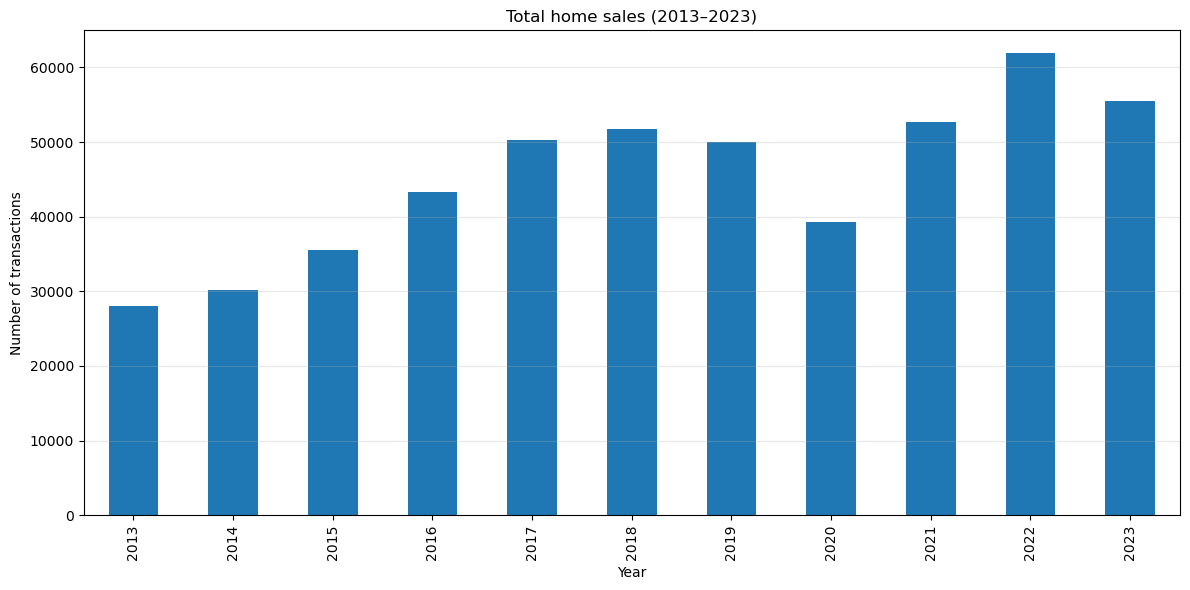

In [32]:
sales_total.plot(
    x="year",
    y="sales_total",
    kind="bar",
    figsize=(12, 6),
    legend=False
)

plt.title("Total home sales (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Number of transactions")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [33]:
# Compare municipal sales at the beginning and end of the full analysis period.
required_years = [ANALYSIS_START_YEAR, ANALYSIS_END_YEAR]
available_years = set(sales_analysis["year"].dropna().astype(int))
missing_years = set(required_years) - available_years
if missing_years:
    raise ValueError(f"Sales data are missing required endpoint years: {sorted(missing_years)}")

sales_periods = (
    sales_analysis.loc[sales_analysis["year"].isin(required_years)]
    .pivot(
        index=["municipality_code", "municipality"],
        columns="year",
        values="sales_total",
    )
    .reset_index()
)


### Full-period change in sales (2013–2023)

Cumulative and annualized changes use the same 2013–2023 endpoints; annual year-on-year analysis remains available in the series above.


In [34]:
# Cumulative and annualized changes use the same endpoint years for every municipality.
elapsed_years = ELAPSED_ANALYSIS_YEARS
start_values = sales_periods[ANALYSIS_START_YEAR]
end_values = sales_periods[ANALYSIS_END_YEAR]
ratio = end_values.div(start_values.where(start_values.ne(0)))

sales_periods["absolute_change"] = end_values - start_values
sales_periods["cumulative_growth_pct"] = (ratio - 1) * 100
sales_periods["annualized_growth_pct"] = (ratio.pow(1 / elapsed_years) - 1) * 100


In [35]:
display(
    sales_periods[
        ["municipality_code", "municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR,
         "absolute_change", "cumulative_growth_pct", "annualized_growth_pct"]
    ].head(10).style.format({
        ANALYSIS_START_YEAR: "{:,.0f}",
        ANALYSIS_END_YEAR: "{:,.0f}",
        "absolute_change": "{:+,.0f}",
        "cumulative_growth_pct": "{:+.2f}%",
        "annualized_growth_pct": "{:+.2f}%",
    })
)


year,municipality_code,municipality,2013,2023,absolute_change,cumulative_growth_pct,annualized_growth_pct
0,08015,Badalona,840,"2,598","+1,758",+209.29%,+11.95%
1,08019,Barcelona,"8,908","14,899","+5,991",+67.25%,+5.28%
2,08056,Castelldefels,262,654,+392,+149.62%,+9.58%
3,08073,Cornellà de Llobregat,290,773,+483,+166.55%,+10.30%
4,08077,Esplugues de Llobregat,290,390,+100,+34.48%,+3.01%
5,08089,Gavà,232,507,+275,+118.53%,+8.13%
6,08096,Granollers,313,602,+289,+92.33%,+6.76%
7,08101,"Hospitalet de Llobregat, l'","1,442","2,941","+1,499",+103.95%,+7.39%
8,08102,Igualada,159,393,+234,+147.17%,+9.47%
9,08113,Manresa,538,940,+402,+74.72%,+5.74%


In [36]:
top_10_sales_growth = sales_periods.nlargest(10, "cumulative_growth_pct").copy()
display(
    top_10_sales_growth[
        ["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR,
         "cumulative_growth_pct", "annualized_growth_pct"]
    ].reset_index(drop=True).style.format({
        ANALYSIS_START_YEAR: "{:,.0f}", ANALYSIS_END_YEAR: "{:,.0f}",
        "cumulative_growth_pct": "{:+.2f}%", "annualized_growth_pct": "{:+.2f}%",
    })
)


year,municipality,2013,2023,cumulative_growth_pct,annualized_growth_pct
0,Sant Joan Despí,75,661,+781.33%,+24.31%
1,Santa Coloma de Gramenet,319,"1,231",+285.89%,+14.46%
2,Vilanova i la Geltrú,248,944,+280.65%,+14.30%
3,Sant Feliu de Llobregat,177,567,+220.34%,+12.35%
4,Badalona,840,"2,598",+209.29%,+11.95%
5,"Prat de Llobregat, el",202,624,+208.91%,+11.94%
6,Sant Pere de Ribes,153,433,+183.01%,+10.96%
7,Montcada i Reixac,126,347,+175.40%,+10.66%
8,Tortosa,159,436,+174.21%,+10.61%
9,Cornellà de Llobregat,290,773,+166.55%,+10.30%


In [37]:
bottom_10_sales_growth = sales_periods.nsmallest(10, "cumulative_growth_pct").copy()
display(
    bottom_10_sales_growth[
        ["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR,
         "cumulative_growth_pct", "annualized_growth_pct"]
    ].reset_index(drop=True).style.format({
        ANALYSIS_START_YEAR: "{:,.0f}", ANALYSIS_END_YEAR: "{:,.0f}",
        "cumulative_growth_pct": "{:+.2f}%", "annualized_growth_pct": "{:+.2f}%",
    })
)


year,municipality,2013,2023,cumulative_growth_pct,annualized_growth_pct
0,Sant Cugat del Vallès,607,681,+12.19%,+1.16%
1,"Vendrell, el",581,732,+25.99%,+2.34%
2,Vic,359,478,+33.15%,+2.90%
3,Esplugues de Llobregat,290,390,+34.48%,+3.01%
4,Figueres,376,532,+41.49%,+3.53%
5,Olot,215,340,+58.14%,+4.69%
6,Sitges,379,611,+61.21%,+4.89%
7,Cambrils,457,737,+61.27%,+4.90%
8,Barcelona,"8,908","14,899",+67.25%,+5.28%
9,Terrassa,"1,405","2,433",+73.17%,+5.64%


In [38]:
# Rank municipalities by absolute transaction-count change, keeping it distinct from percentage growth.
top_10_sales_absolute_change = sales_periods.nlargest(10, "absolute_change").copy()
display(
    top_10_sales_absolute_change[
        ["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "absolute_change",
         "cumulative_growth_pct"]
    ].reset_index(drop=True).style.format({
        ANALYSIS_START_YEAR: "{:,.0f}", ANALYSIS_END_YEAR: "{:,.0f}",
        "absolute_change": "{:+,.0f}", "cumulative_growth_pct": "{:+.2f}%",
    })
)


year,municipality,2013,2023,absolute_change,cumulative_growth_pct
0,Barcelona,"8,908","14,899","+5,991",+67.25%
1,Badalona,840,"2,598","+1,758",+209.29%
2,"Hospitalet de Llobregat, l'","1,442","2,941","+1,499",+103.95%
3,Sabadell,"1,278","2,509","+1,231",+96.32%
4,Terrassa,"1,405","2,433","+1,028",+73.17%
5,Tarragona,941,"1,909",+968,+102.87%
6,Reus,584,"1,506",+922,+157.88%
7,Santa Coloma de Gramenet,319,"1,231",+912,+285.89%
8,Lleida,800,"1,709",+909,+113.62%
9,Vilanova i la Geltrú,248,944,+696,+280.65%


In [39]:
# Side-by-side summary of the municipalities at both ends of cumulative sales growth.
sales_growth_extremes = pd.concat(
    [
        top_10_sales_growth.assign(rank_group="Top 10 cumulative growth"),
        bottom_10_sales_growth.assign(rank_group="Bottom 10 cumulative growth"),
    ],
    ignore_index=True,
).sort_values(["rank_group", "cumulative_growth_pct"], ascending=[True, False])

display(
    sales_growth_extremes[
        ["rank_group", "municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR,
         "absolute_change", "cumulative_growth_pct", "annualized_growth_pct"]
    ].reset_index(drop=True).round(2)
)


year,rank_group,municipality,2013,2023,absolute_change,cumulative_growth_pct,annualized_growth_pct
0,Bottom 10 cumulative growth,Terrassa,1405,2433,1028,73.17,5.64
1,Bottom 10 cumulative growth,Barcelona,8908,14899,5991,67.25,5.28
2,Bottom 10 cumulative growth,Cambrils,457,737,280,61.27,4.90
3,Bottom 10 cumulative growth,Sitges,379,611,232,61.21,4.89
4,Bottom 10 cumulative growth,Olot,215,340,125,58.14,4.69
5,Bottom 10 cumulative growth,Figueres,376,532,156,41.49,3.53
6,Bottom 10 cumulative growth,Esplugues de Llobregat,290,390,100,34.48,3.01
7,Bottom 10 cumulative growth,Vic,359,478,119,33.15,2.90
8,Bottom 10 cumulative growth,"Vendrell, el",581,732,151,25.99,2.34
9,Bottom 10 cumulative growth,Sant Cugat del Vallès,607,681,74,12.19,1.16


### Absolute sales counts

In [40]:
top10_by_period = []

for year in RANKING_YEARS:
    top10 = (
        sales_analysis.loc[sales_analysis["year"] == year]
        .sort_values("sales_total", ascending=False)
        .head(10)[["municipality", "sales_total"]]
        .copy()
    )
    top10["year"] = year
    top10["rank"] = range(1, len(top10) + 1)
    top10_by_period.append(top10)

top10_by_period = pd.concat(top10_by_period, ignore_index=True)


In [41]:
top10_municipalities = (
    top10_by_period["municipality"]
    .unique()
    .tolist()
)


In [42]:
sales_top10_periods = (
    sales_analysis.loc[
        sales_analysis["municipality"].isin(top10_municipalities)
        & sales_analysis["year"].isin(RANKING_YEARS)
    ]
    .pivot(index="municipality", columns="year", values="sales_total")
    .reset_index()
)

sales_top10_periods = sales_top10_periods.sort_values(ANALYSIS_END_YEAR, ascending=False).reset_index(drop=True)
sales_top10_periods


year,municipality,2013,2016,2020,2023
0,Barcelona,8908,14266,9861,14899
1,"Hospitalet de Llobregat, l'",1442,2089,2127,2941
2,Badalona,840,1772,1919,2598
3,Sabadell,1278,2061,1962,2509
4,Terrassa,1405,2166,2121,2433
5,Tarragona,941,1198,1233,1909
6,Lleida,800,1063,1138,1709
7,Reus,584,942,1052,1506
8,Mataró,597,1007,908,1270
9,Santa Coloma de Gramenet,319,705,709,1231


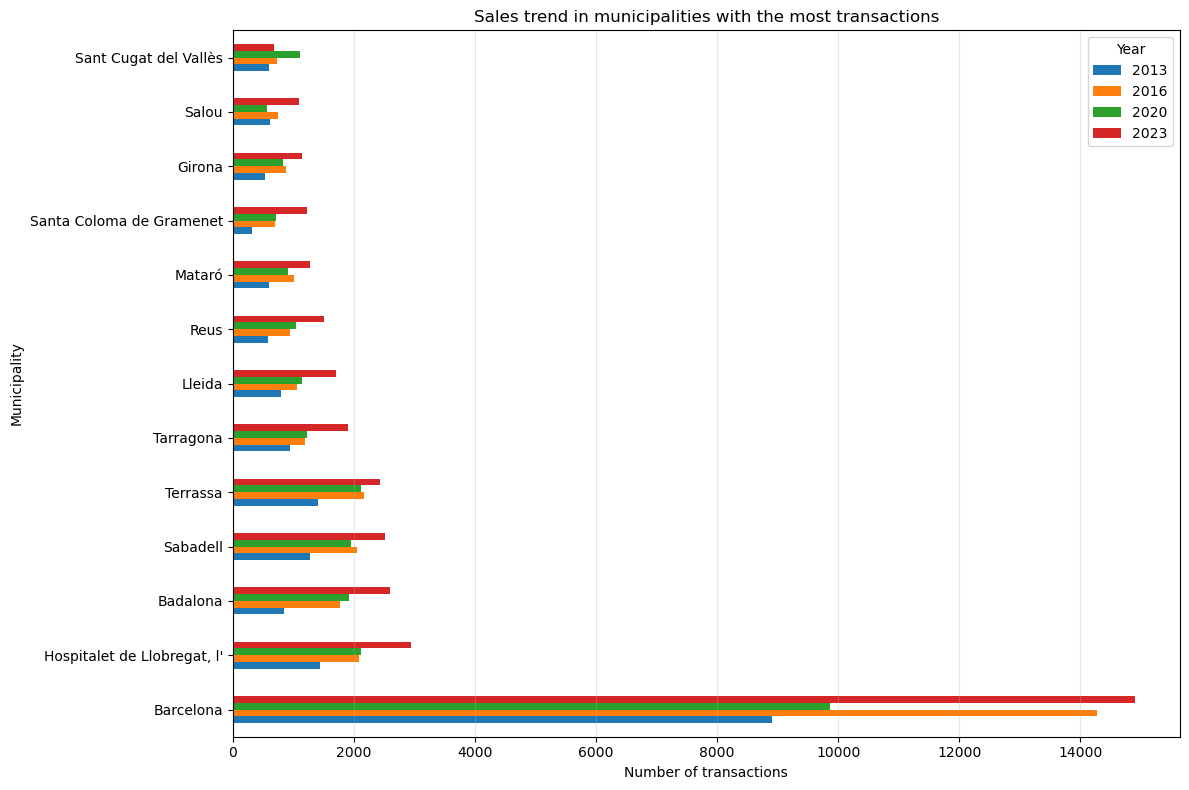

In [43]:
sales_top10_periods.plot(
    x="municipality",
    y=RANKING_YEARS,
    kind="barh",
    figsize=(12, 8),
)

plt.title("Sales trend in municipalities with the most transactions")
plt.xlabel("Number of transactions")
plt.ylabel("Municipality")
plt.legend(title="Year")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:
barcelona_sales_share = (
    sales_analysis
    .groupby("year")["sales_total"]
    .sum()
    .reset_index(name="sales_total_universe")
)

barcelona_sales = (
    sales_analysis[
        sales_analysis["municipality"] == "Barcelona"
    ][["year", "sales_total"]]
    .rename(columns={"sales_total": "sales_barcelona"})
)

barcelona_sales_share = barcelona_sales_share.merge(
    barcelona_sales,
    on="year",
    how="left"
)

barcelona_sales_share["barcelona_share_pct"] = (
    barcelona_sales_share["sales_barcelona"]
    / barcelona_sales_share["sales_total_universe"]
    * 100
)

barcelona_sales_share


,year,sales_total_universe,sales_barcelona,barcelona_share_pct
0,2013,28009,8908,31.804063
1,2014,30122,10606,35.210145
2,2015,35538,12229,34.411053
3,2016,43368,14266,32.895222
4,2017,50289,15676,31.171827
5,2018,51682,13791,26.684339
6,2019,50008,13409,26.813710
7,2020,39237,9861,25.131891
8,2021,52658,13803,26.212541
9,2022,61867,16029,25.908804


In [45]:
barcelona_total = barcelona_sales_share["sales_barcelona"].sum()
universe_total = barcelona_sales_share["sales_total_universe"].sum()

barcelona_share_total = (
    barcelona_total / universe_total * 100
)

barcelona_total, universe_total, barcelona_share_total


(np.int64(143477), np.int64(498321), np.float64(28.79208381745903))

In [46]:
barcelona_sales_share[
    ["year", "sales_barcelona", "sales_total_universe", "barcelona_share_pct"]
].style.format({
    "sales_barcelona": "{:,.0f}",
    "sales_total_universe": "{:,.0f}",
    "barcelona_share_pct": "{:.2f}%"
})


,year,sales_barcelona,sales_total_universe,barcelona_share_pct
0,2013,"8,908","28,009",31.80%
1,2014,"10,606","30,122",35.21%
2,2015,"12,229","35,538",34.41%
3,2016,"14,266","43,368",32.90%
4,2017,"15,676","50,289",31.17%
5,2018,"13,791","51,682",26.68%
6,2019,"13,409","50,008",26.81%
7,2020,"9,861","39,237",25.13%
8,2021,"13,803","52,658",26.21%
9,2022,"16,029","61,867",25.91%


In [47]:
# Explore whether Barcelona's average sale price is associated with its share of sample transactions.


## Housing Prices

In [48]:
sales_evolution = (
    sales_analysis
    .groupby("year")
    .agg(
        sales_total=("sales_total", "sum"),
        price_m2_mean=("price_m2_total", "mean"),
        price_mean=("price_total_k_eur", "mean")
    )
    .reset_index()
)

sales_evolution["sales_growth_%"] = (
    sales_evolution["sales_total"]
    .pct_change() * 100
)

sales_evolution["price_m2_growth_%"] = (
    sales_evolution["price_m2_mean"]
    .pct_change() * 100
)

sales_evolution["price_growth_%"] = (
    sales_evolution["price_mean"]
    .pct_change() * 100
)

sales_evolution.round(2)


,year,sales_total,price_m2_mean,price_mean,sales_growth_%,price_m2_growth_%,price_growth_%
0,2013,28009,1686.98,147.23,NaN,NaN,NaN
1,2014,30122,1591.36,140.52,7.54,-5.67,-4.56
2,2015,35538,1616.09,142.26,17.98,1.55,1.24
3,2016,43368,1695.20,146.86,22.03,4.90,3.23
4,2017,50289,1808.58,156.01,15.96,6.69,6.23
5,2018,51682,1983.14,169.23,2.77,9.65,8.48
6,2019,50008,2118.86,180.34,-3.24,6.84,6.56
7,2020,39237,2209.50,193.58,-21.54,4.28,7.34
8,2021,52658,2284.36,201.11,34.20,3.39,3.89
9,2022,61867,2391.53,208.98,17.49,4.69,3.92


### Total sale price

In [49]:
price_stats_2023 = sales_analysis.loc[
    sales_analysis["year"] == ANALYSIS_END_YEAR,
    ["price_total_k_eur", "price_m2_total"],
].agg(["min", "max", "mean", "median", lambda values: values.mode().iloc[0]])

price_stats_2023.index = ["Minimum", "Maximum", "Mean", "Median", "Mode"]
price_stats_2023


,price_total_k_eur,price_m2_total
Minimum,83.276060,841.490000
Maximum,530.189080,5020.770000
Mean,206.101777,2419.551064
Median,181.971210,2230.210000
Mode,83.276060,841.490000


In [50]:
price_2013 = sales_evolution.loc[
    sales_evolution["year"] == ANALYSIS_START_YEAR, "price_mean"
].iloc[0]
price_2023 = sales_evolution.loc[
    sales_evolution["year"] == ANALYSIS_END_YEAR, "price_mean"
].iloc[0]

growth_absolute = price_2023 - price_2013
growth_percentage = (price_2023 / price_2013 - 1) * 100

print(f"Absolute increase: {growth_absolute:,.2f} thousand €")
print(f"Percentage increase: {growth_percentage:.2f}%")


Absolute increase: 58.87 thousand €
Percentage increase: 39.99%


In [51]:
# Potential follow-up: compare nominal sale-price growth with inflation.


In [52]:
price_evolution_municipality = (
    sales_analysis[
        ["municipality_code", "municipality", "year",
         "price_total_k_eur", "price_m2_total"]
    ]
    .sort_values(["municipality", "year"])
    .copy()
)


In [53]:
price_2013_2023 = (
    price_evolution_municipality
    .pivot(
        index=["municipality_code", "municipality"],
        columns="year",
        values=["price_total_k_eur", "price_m2_total"]
    )
)

price_2013_2023.columns = [
    f"{variable}_{year}"
    for variable, year in price_2013_2023.columns
]

price_2013_2023 = price_2013_2023.reset_index()


In [54]:
price_2013_2023["price_growth_abs"] = (
    price_2013_2023["price_total_k_eur_2023"]
    - price_2013_2023["price_total_k_eur_2013"]
)

price_2013_2023["price_growth_pct"] = (
    (
        price_2013_2023["price_total_k_eur_2023"]
        / price_2013_2023["price_total_k_eur_2013"]
        - 1
    ) * 100
)

price_2013_2023["price_m2_growth_abs"] = (
    price_2013_2023["price_m2_total_2023"]
    - price_2013_2023["price_m2_total_2013"]
)

price_2013_2023["price_m2_growth_pct"] = (
    (
        price_2013_2023["price_m2_total_2023"]
        / price_2013_2023["price_m2_total_2013"]
        - 1
    ) * 100
)


In [55]:
top_10_expensive = (
    price_2013_2023
    .sort_values("price_total_k_eur_2023", ascending=False)
    .head(10)
    [["municipality",
      "price_total_k_eur_2013",
      "price_total_k_eur_2023",
      "price_growth_abs",
      "price_growth_pct"]]
)

top_10_expensive.style.format({
    "price_total_k_eur_2013": "{:,.2f} k€",
    "price_total_k_eur_2023": "{:,.2f} k€",
    "price_growth_abs": "{:+,.2f} k€",
    "price_growth_pct": "{:+.2f}%"
})


,municipality,price_total_k_eur_2013,price_total_k_eur_2023,price_growth_abs,price_growth_pct
20,Sant Cugat del Vallès,310.54 k€,530.19 k€,+219.65 k€,+70.73%
27,Sitges,346.79 k€,516.79 k€,+169.99 k€,+49.02%
4,Esplugues de Llobregat,216.05 k€,396.58 k€,+180.53 k€,+83.56%
1,Barcelona,248.96 k€,374.27 k€,+125.30 k€,+50.33%
2,Castelldefels,235.81 k€,355.72 k€,+119.91 k€,+50.85%
5,Gavà,241.91 k€,290.88 k€,+48.97 k€,+20.25%
26,Cerdanyola del Vallès,203.17 k€,288.73 k€,+85.56 k€,+42.12%
23,Sant Pere de Ribes,195.86 k€,263.44 k€,+67.58 k€,+34.50%
21,Sant Feliu de Llobregat,197.69 k€,258.42 k€,+60.73 k€,+30.72%
32,Vilanova i la Geltrú,143.45 k€,237.77 k€,+94.31 k€,+65.75%


In [56]:
top_10_growth_price_pct = (
    price_2013_2023
    .sort_values("price_growth_pct", ascending=False)
    .head(10)
    [["municipality",
      "price_total_k_eur_2013",
      "price_total_k_eur_2023",
      "price_growth_abs",
      "price_growth_pct"]]
)

top_10_growth_price_pct.style.format({
    "price_total_k_eur_2013": "{:,.2f} k€",
    "price_total_k_eur_2023": "{:,.2f} k€",
    "price_growth_abs": "{:+,.2f} k€",
    "price_growth_pct": "{:+.2f}%"
})


,municipality,price_total_k_eur_2013,price_total_k_eur_2023,price_growth_abs,price_growth_pct
29,Vic,90.46 k€,179.65 k€,+89.19 k€,+98.59%
4,Esplugues de Llobregat,216.05 k€,396.58 k€,+180.53 k€,+83.56%
28,Terrassa,91.75 k€,165.80 k€,+74.05 k€,+80.71%
3,Cornellà de Llobregat,99.58 k€,177.00 k€,+77.42 k€,+77.75%
10,Mataró,113.14 k€,194.31 k€,+81.17 k€,+71.74%
20,Sant Cugat del Vallès,310.54 k€,530.19 k€,+219.65 k€,+70.73%
14,"Prat de Llobregat, el",130.77 k€,221.90 k€,+91.13 k€,+69.68%
32,Vilanova i la Geltrú,143.45 k€,237.77 k€,+94.31 k€,+65.75%
11,Mollet del Vallès,101.69 k€,166.75 k€,+65.06 k€,+63.98%
16,Rubí,112.97 k€,183.51 k€,+70.54 k€,+62.45%


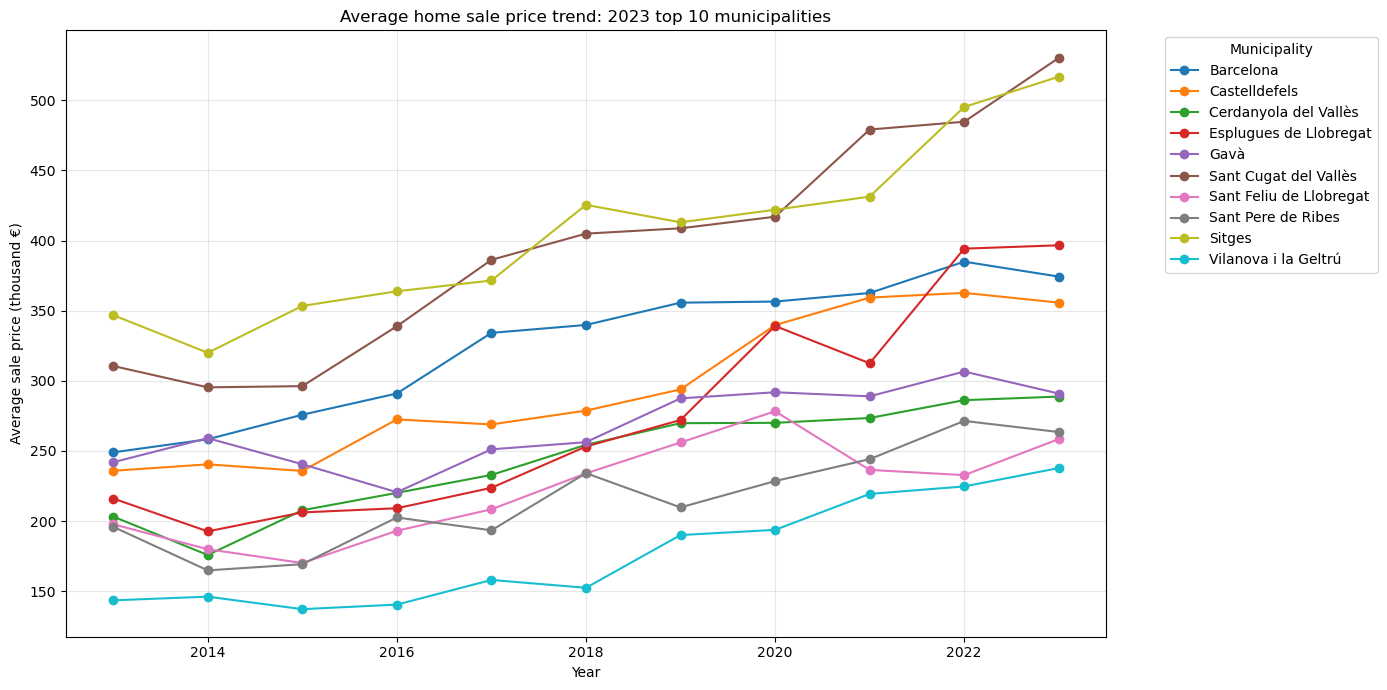

In [57]:
top10_expensive_price_evolution = (
    sales_analysis.loc[
        sales_analysis["municipality"].isin(top_10_expensive["municipality"])
    ]
    .pivot(index="year", columns="municipality", values="price_total_k_eur")
)
top10_expensive_price_evolution.plot(
    kind="line",
    marker="o",
    figsize=(14, 7),
)

plt.title("Average home sale price trend: 2023 top 10 municipalities")
plt.xlabel("Year")
plt.ylabel("Average sale price (thousand €)")
plt.legend(title="Municipality", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [58]:
sales_price_2023_plot = (
    sales_analysis.loc[sales_analysis["year"].eq(ANALYSIS_END_YEAR)]
    [["municipality", "price_total_k_eur"]]
    .copy()
    .assign(price_total_eur=lambda df: df["price_total_k_eur"] * 1000)
    .sort_values("price_total_eur")
    .reset_index(drop=True)
)

assert len(sales_price_2023_plot) == 47


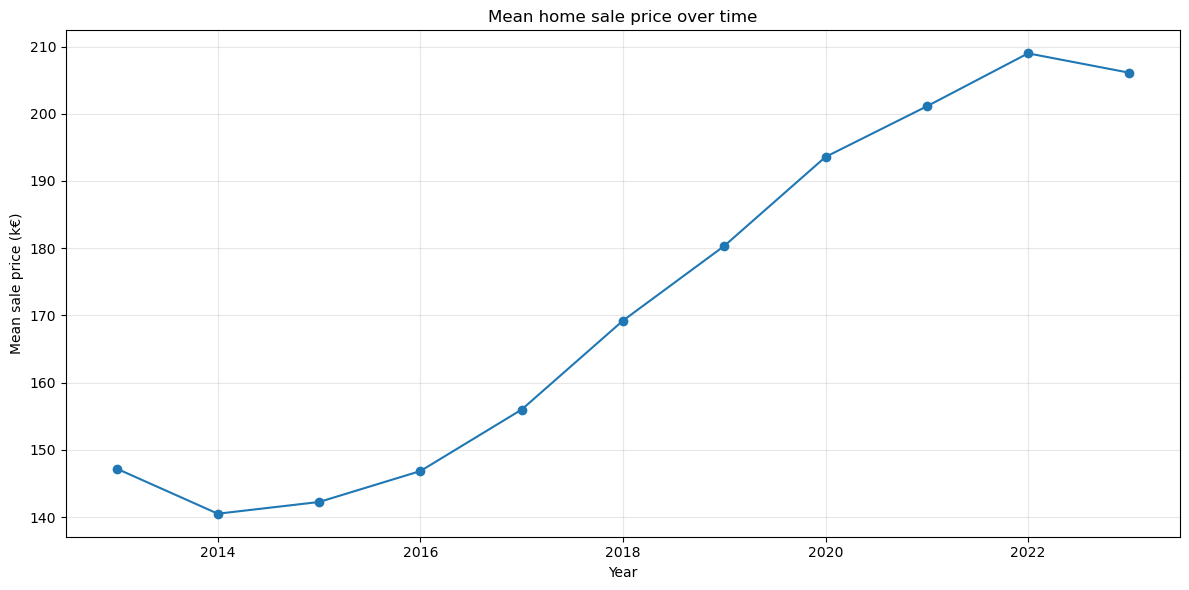

In [59]:
ax = sales_evolution.plot(
    x="year",
    y="price_mean",
    kind="line",
    marker="o",
    figsize=(12, 6),
    legend=False,
)
ax.set_title("Mean home sale price over time")
ax.set_xlabel("Year")
ax.set_ylabel("Mean sale price (k€)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


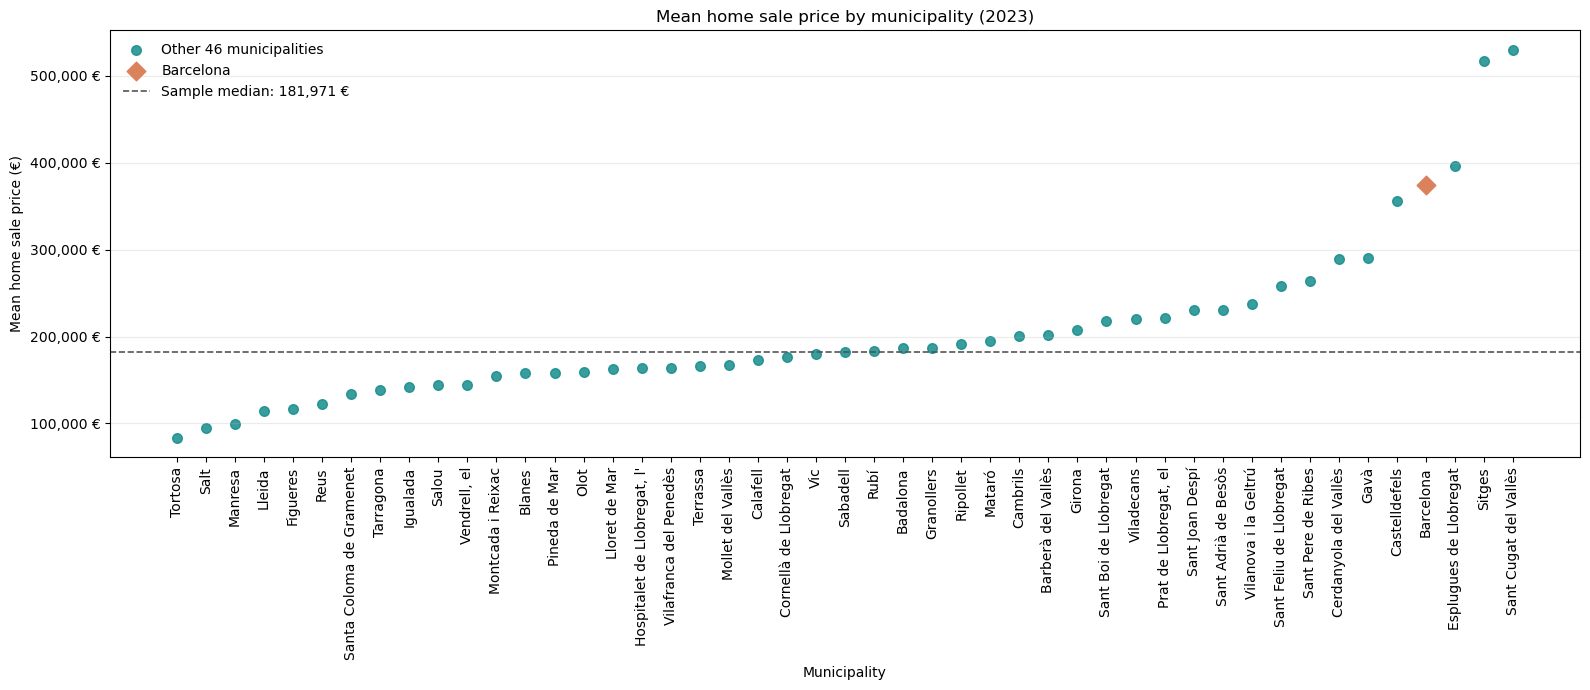

In [60]:
municipality_positions = np.arange(len(sales_price_2023_plot))
barcelona_mask = sales_price_2023_plot["municipality"].str.casefold().eq("barcelona")

fig, ax = plt.subplots(figsize=(16, 7))
ax.scatter(
    municipality_positions[~barcelona_mask.to_numpy()],
    sales_price_2023_plot.loc[~barcelona_mask, "price_total_eur"],
    color="#168C8C",
    s=48,
    alpha=0.85,
    label="Other 46 municipalities",
)
ax.scatter(
    municipality_positions[barcelona_mask.to_numpy()],
    sales_price_2023_plot.loc[barcelona_mask, "price_total_eur"],
    color="#D9825B",
    marker="D",
    s=90,
    zorder=3,
    label="Barcelona",
)

median_price_2023 = sales_price_2023_plot["price_total_eur"].median()
ax.axhline(
    median_price_2023,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Sample median: {median_price_2023:,.0f} €",
)
ax.set_xticks(municipality_positions)
ax.set_xticklabels(sales_price_2023_plot["municipality"], rotation=90)
ax.set_title("Mean home sale price by municipality (2023)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Mean home sale price (€)")
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f} €")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()


### Price per square metre

In [61]:
price_m2_2013 = sales_evolution.loc[
    sales_evolution["year"] == ANALYSIS_START_YEAR, "price_m2_mean"
].iloc[0]
price_m2_2023 = sales_evolution.loc[
    sales_evolution["year"] == ANALYSIS_END_YEAR, "price_m2_mean"
].iloc[0]

growth_m2_absolute = price_m2_2023 - price_m2_2013
growth_m2_percentage = (price_m2_2023 / price_m2_2013 - 1) * 100

print(f"Absolute increase: {growth_m2_absolute:,.2f} €/m²")
print(f"Percentage increase: {growth_m2_percentage:.2f}%")


Absolute increase: 732.57 €/m²
Percentage increase: 43.43%


In [62]:
top_10_expensive_m2 = (
    price_2013_2023
    .sort_values("price_m2_total_2023", ascending=False)
    .head(10)
    [["municipality",
      "price_m2_total_2013",
      "price_m2_total_2023",
      "price_m2_growth_abs",
      "price_m2_growth_pct"]]
)

top_10_expensive_m2.style.format({
    "price_m2_total_2013": "{:,.2f} €/m²",
    "price_m2_total_2023": "{:,.2f} €/m²",
    "price_m2_growth_abs": "{:+,.2f} €/m²",
    "price_m2_growth_pct": "{:+.2f}%"
})


,municipality,price_m2_total_2013,price_m2_total_2023,price_m2_growth_abs,price_m2_growth_pct
27,Sitges,"3,407.86 €/m²","5,020.77 €/m²","+1,612.91 €/m²",+47.33%
20,Sant Cugat del Vallès,"2,658.92 €/m²","4,648.39 €/m²","+1,989.47 €/m²",+74.82%
1,Barcelona,"2,718.96 €/m²","4,370.96 €/m²","+1,652.00 €/m²",+60.76%
4,Esplugues de Llobregat,"2,470.56 €/m²","4,136.81 €/m²","+1,666.25 €/m²",+67.44%
2,Castelldefels,"2,560.56 €/m²","4,118.36 €/m²","+1,557.80 €/m²",+60.84%
21,Sant Feliu de Llobregat,"2,109.73 €/m²","3,303.11 €/m²","+1,193.38 €/m²",+56.57%
5,Gavà,"2,363.05 €/m²","3,292.84 €/m²",+929.79 €/m²,+39.35%
22,Sant Joan Despí,"2,330.92 €/m²","3,092.40 €/m²",+761.48 €/m²,+32.67%
14,"Prat de Llobregat, el","1,675.87 €/m²","2,986.63 €/m²","+1,310.76 €/m²",+78.21%
26,Cerdanyola del Vallès,"1,984.90 €/m²","2,953.47 €/m²",+968.57 €/m²,+48.80%


In [63]:
top_10_growth_m2_pct = (
    price_2013_2023
    .sort_values("price_m2_growth_pct", ascending=False)
    .head(10)
    [["municipality",
      "price_m2_total_2013",
      "price_m2_total_2023",
      "price_m2_growth_abs",
      "price_m2_growth_pct"]]
)

top_10_growth_m2_pct.style.format({
    "price_m2_total_2013": "{:,.2f} €/m²",
    "price_m2_total_2023": "{:,.2f} €/m²",
    "price_m2_growth_abs": "{:+,.2f} €/m²",
    "price_m2_growth_pct": "{:+.2f}%"
})


,municipality,price_m2_total_2013,price_m2_total_2023,price_m2_growth_abs,price_m2_growth_pct
29,Vic,"1,052.43 €/m²","1,981.87 €/m²",+929.44 €/m²,+88.31%
14,"Prat de Llobregat, el","1,675.87 €/m²","2,986.63 €/m²","+1,310.76 €/m²",+78.21%
20,Sant Cugat del Vallès,"2,658.92 €/m²","4,648.39 €/m²","+1,989.47 €/m²",+74.82%
3,Cornellà de Llobregat,"1,555.25 €/m²","2,691.58 €/m²","+1,136.33 €/m²",+73.06%
10,Mataró,"1,355.86 €/m²","2,317.20 €/m²",+961.34 €/m²,+70.90%
28,Terrassa,"1,179.44 €/m²","1,993.34 €/m²",+813.90 €/m²,+69.01%
4,Esplugues de Llobregat,"2,470.56 €/m²","4,136.81 €/m²","+1,666.25 €/m²",+67.44%
32,Vilanova i la Geltrú,"1,692.97 €/m²","2,822.77 €/m²","+1,129.80 €/m²",+66.73%
16,Rubí,"1,256.75 €/m²","2,078.42 €/m²",+821.67 €/m²,+65.38%
25,Barberà del Vallès,"1,398.38 €/m²","2,311.14 €/m²",+912.76 €/m²,+65.27%


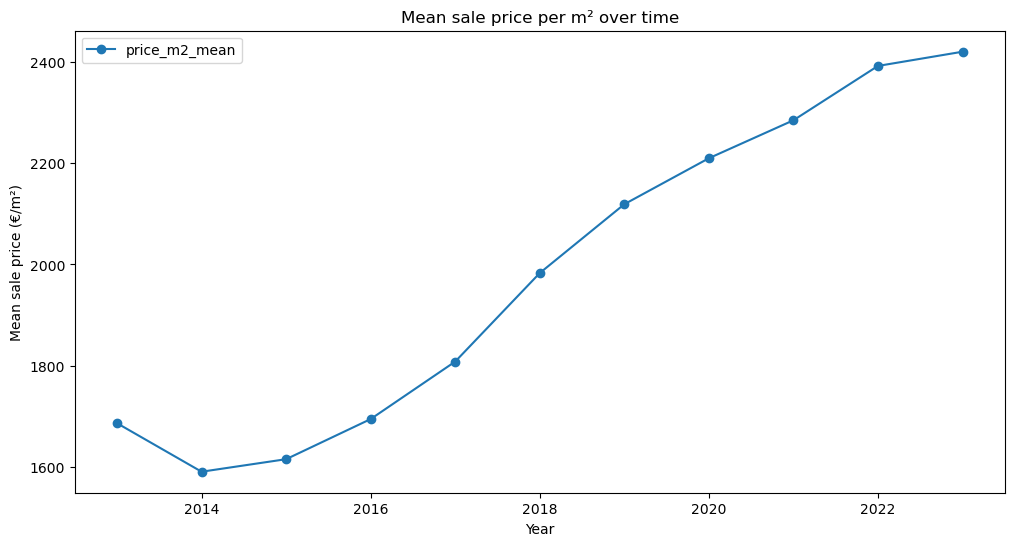

In [64]:
sales_evolution.plot(
    x="year",
    y="price_m2_mean",
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Mean sale price per m² over time")
plt.xlabel("Year")
plt.ylabel("Mean sale price (€/m²)")
plt.show()


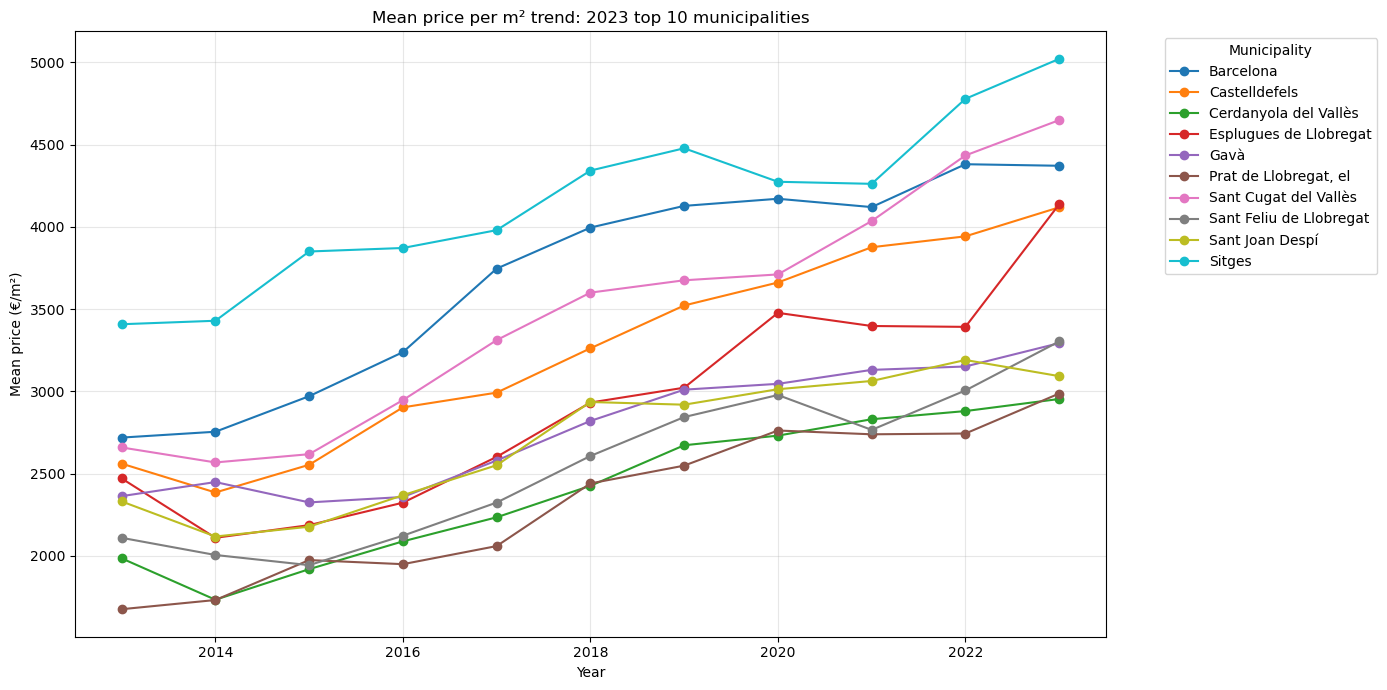

In [65]:
top10_expensive_m2_evolution = (
    sales_analysis.loc[
        sales_analysis["municipality"].isin(top_10_expensive_m2["municipality"])
    ]
    .pivot(index="year", columns="municipality", values="price_m2_total")
)
top10_expensive_m2_evolution.plot(
    kind="line",
    marker="o",
    figsize=(14, 7),
)

plt.title("Mean price per m² trend: 2023 top 10 municipalities")
plt.xlabel("Year")
plt.ylabel("Mean price (€/m²)")
plt.legend(title="Municipality", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


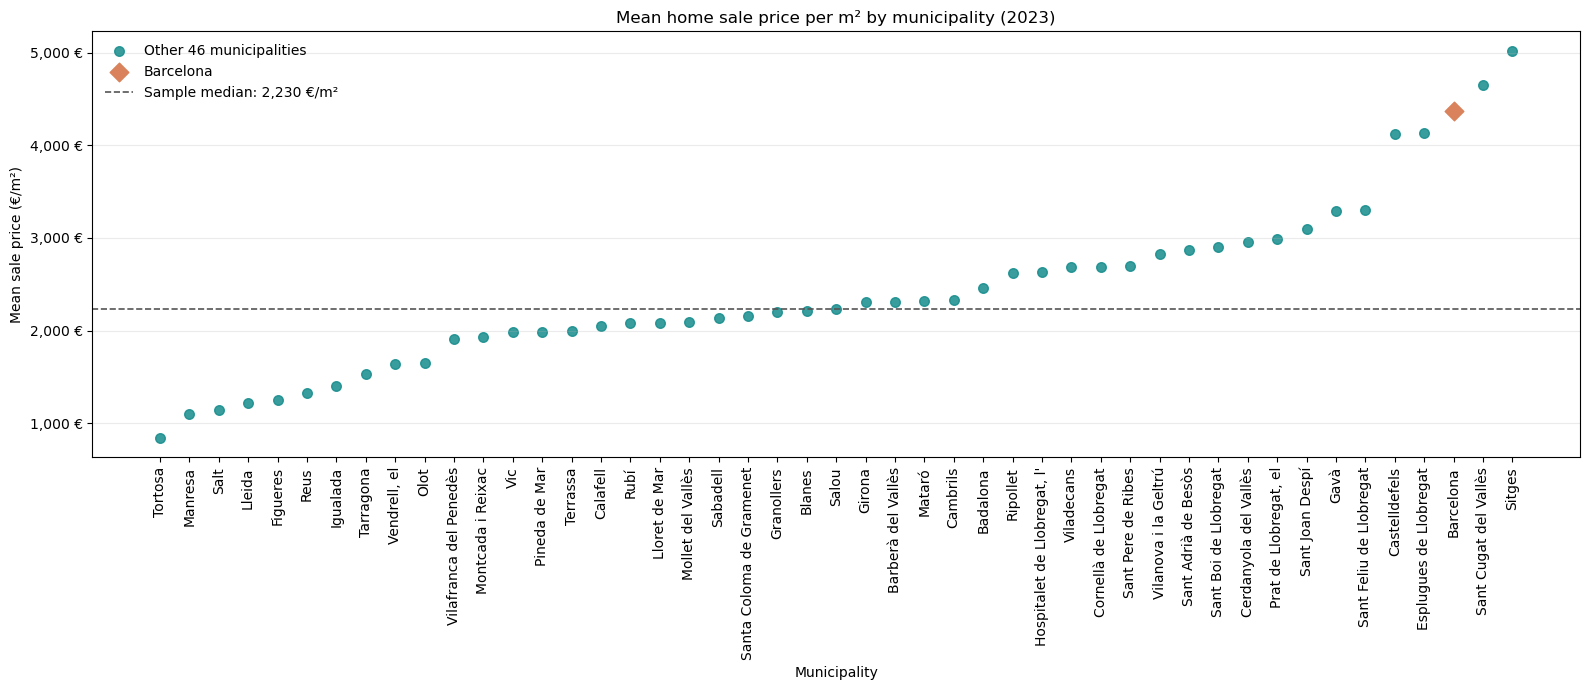

Municipalities represented: 47


In [66]:
sales_m2_2023_plot = (
    sales_analysis.loc[sales_analysis["year"] == ANALYSIS_END_YEAR]
    .copy()
    .sort_values("price_m2_total")
    .reset_index(drop=True)
)

assert sales_m2_2023_plot["municipality_code"].nunique() == 47
assert sales_m2_2023_plot["municipality"].nunique() == 47

positions = np.arange(len(sales_m2_2023_plot))
barcelona_mask = sales_m2_2023_plot["municipality"].str.casefold().eq("barcelona")
median_price_m2_2023 = sales_m2_2023_plot["price_m2_total"].median()

fig, ax = plt.subplots(figsize=(16, 7))
ax.scatter(
    positions[~barcelona_mask.to_numpy()],
    sales_m2_2023_plot.loc[~barcelona_mask, "price_m2_total"],
    color="#168C8C",
    s=48,
    alpha=0.85,
    label="Other 46 municipalities",
)
ax.scatter(
    positions[barcelona_mask.to_numpy()],
    sales_m2_2023_plot.loc[barcelona_mask, "price_m2_total"],
    color="#D9825B",
    marker="D",
    s=90,
    zorder=3,
    label="Barcelona",
)
ax.axhline(
    median_price_m2_2023,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Sample median: {median_price_m2_2023:,.0f} €/m²",
)
ax.set_xticks(positions)
ax.set_xticklabels(sales_m2_2023_plot["municipality"], rotation=90)
ax.set_title("Mean home sale price per m² by municipality (2023)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Mean sale price (€/m²)")
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f} €")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

print(f"Municipalities represented: {sales_m2_2023_plot['municipality'].nunique()}")


In [67]:
# Sales activity is summarized by new free-market, new protected, used, and total transactions.


In [68]:
sales_stats_2023 = sales_analysis.loc[
    sales_analysis["year"] == ANALYSIS_END_YEAR,
    "sales_total",
].agg(["min", "max", "mean", "median", lambda values: values.mode().iloc[0]])

sales_stats_2023.index = ["Minimum", "Maximum", "Mean", "Median", "Mode"]
sales_stats_2023


Minimum      328.000000
Maximum    14899.000000
Mean        1181.765957
Median       645.000000
Mode         328.000000
Name: sales_total, dtype: float64

In [69]:
# Compare top municipalities by housing type.


In [70]:
sales_new_free = (
    sales_analysis
    .groupby("year")["sales_new_free"]
    .sum()
    .reset_index(name="sales")
)

sales_new_free["growth_abs"] = sales_new_free["sales"].diff()

sales_new_free["growth_pct"] = (
    sales_new_free["sales"].pct_change() * 100
)

sales_new_free["growth_2013_abs"] = (
    sales_new_free["sales"]
    - sales_new_free.loc[
        sales_new_free["year"] == ANALYSIS_START_YEAR,
        "sales"
    ].iloc[0]
)

sales_new_free["growth_2013_pct"] = (
    (
        sales_new_free["sales"]
        / sales_new_free.loc[
            sales_new_free["year"] == ANALYSIS_START_YEAR,
            "sales"
        ].iloc[0]
        - 1
    ) * 100
)


In [71]:
sales_new_protected = (
    sales_analysis
    .groupby("year")["sales_new_protected"]
    .sum()
    .reset_index(name="sales")
)

sales_new_protected["growth_abs"] = (
    sales_new_protected["sales"].diff()
)

sales_new_protected["growth_pct"] = (
    sales_new_protected["sales"].pct_change() * 100
)

sales_new_protected["growth_2013_abs"] = (
    sales_new_protected["sales"]
    - sales_new_protected.loc[
        sales_new_protected["year"] == ANALYSIS_START_YEAR,
        "sales"
    ].iloc[0]
)

sales_new_protected["growth_2013_pct"] = (
    (
        sales_new_protected["sales"]
        / sales_new_protected.loc[
            sales_new_protected["year"] == ANALYSIS_START_YEAR,
            "sales"
        ].iloc[0]
        - 1
    ) * 100
)


In [72]:
sales_used = (
    sales_analysis
    .groupby("year")["sales_used"]
    .sum()
    .reset_index(name="sales")
)

sales_used["growth_abs"] = (
    sales_used["sales"].diff()
)

sales_used["growth_pct"] = (
    sales_used["sales"].pct_change() * 100
)

sales_used["growth_2013_abs"] = (
    sales_used["sales"]
    - sales_used.loc[
        sales_used["year"] == ANALYSIS_START_YEAR,
        "sales"
    ].iloc[0]
)

sales_used["growth_2013_pct"] = (
    (
        sales_used["sales"]
        / sales_used.loc[
            sales_used["year"] == ANALYSIS_START_YEAR,
            "sales"
        ].iloc[0]
        - 1
    ) * 100
)


In [73]:
# Total sales and growth metrics were calculated in the Housing Market section above.


In [74]:
sales_types_evolution = pd.DataFrame(
    {
        "year": sales_new_free["year"],
        "New free-market": sales_new_free["sales"],
        "New protected": sales_new_protected["sales"],
        "Used": sales_used["sales"],
        "Total": sales_total["sales_total"],
    }
)

sales_types_evolution


,year,New free-market,New protected,Used,Total
0,2013,7160,758,20091,28009
1,2014,5784,557,23781,30122
2,2015,4418,609,30511,35538
3,2016,4814,482,38072,43368
4,2017,5712,745,43832,50289
5,2018,6651,832,44199,51682
6,2019,6628,523,42857,50008
7,2020,6370,384,32483,39237
8,2021,8615,509,43534,52658
9,2022,9799,578,51490,61867


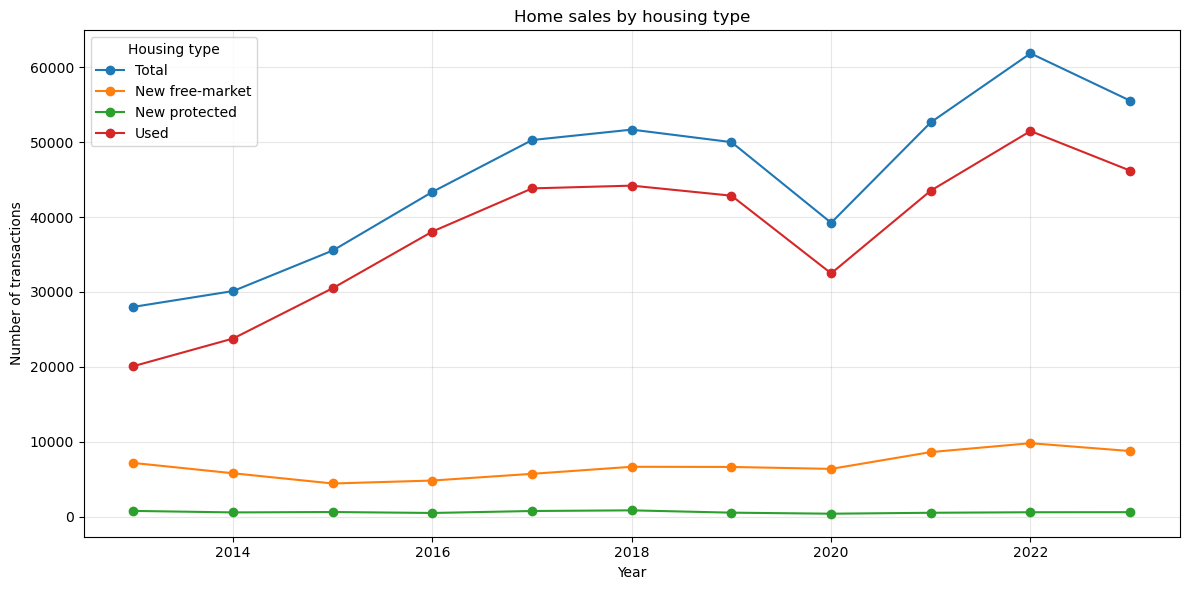

In [75]:
sales_types_evolution.plot(
    x="year",
    y=["Total", "New free-market", "New protected", "Used"],
    kind="line",
    marker="o",
    figsize=(12, 6),
)

plt.title("Home sales by housing type")
plt.xlabel("Year")
plt.ylabel("Number of transactions")
plt.legend(title="Housing type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [76]:
sales_annual_growth = pd.DataFrame({
    "year": sales_new_free["year"],
    "New free": sales_new_free["growth_pct"],
    "New protected": sales_new_protected["growth_pct"],
    "Used": sales_used["growth_pct"],
    "Total": sales_total["growth_pct"]
})

sales_annual_growth


,year,New free,New protected,Used,Total
0,2013,NaN,NaN,NaN,NaN
1,2014,-19.217877,-26.517150,18.366433,7.544004
2,2015,-23.616874,9.335727,28.299903,17.980214
3,2016,8.963332,-20.853859,24.781226,22.032754
4,2017,18.653926,54.564315,15.129229,15.958771
5,2018,16.439076,11.677852,0.837288,2.769989
6,2019,-0.345813,-37.139423,-3.036268,-3.239039
7,2020,-3.892577,-26.577438,-24.206081,-21.538554
8,2021,35.243328,32.552083,34.020872,34.204960
9,2022,13.743471,13.555992,18.275371,17.488321


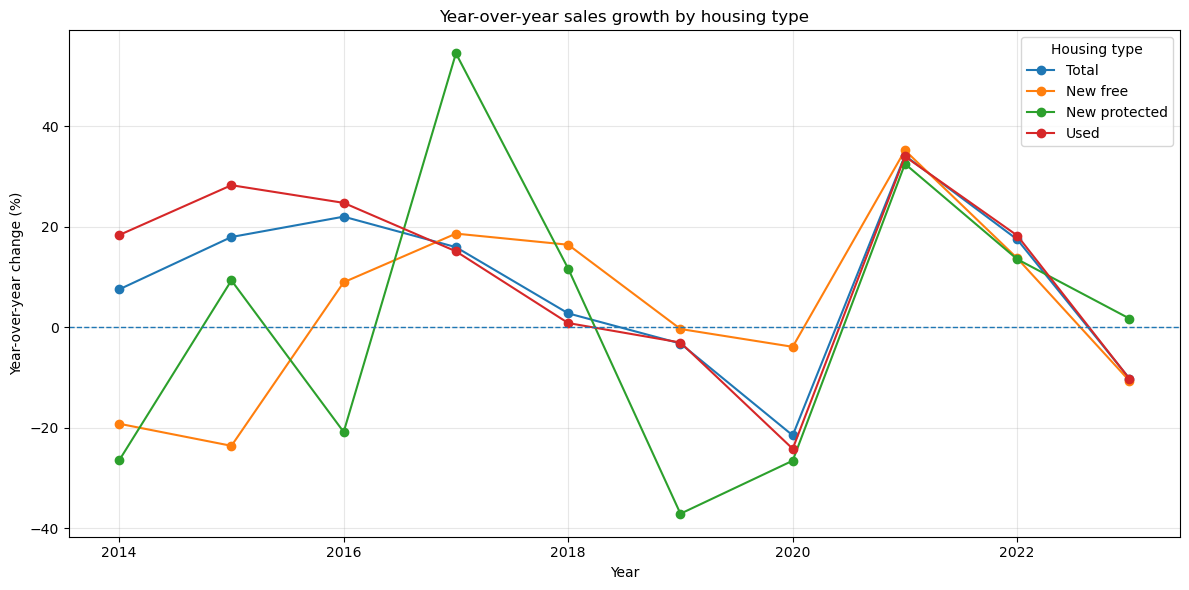

In [77]:
sales_annual_growth.plot(
    x="year",
    y=["Total", "New free", "New protected", "Used"],
    kind="line",
    marker="o",
    figsize=(12, 6),
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Year-over-year sales growth by housing type")
plt.xlabel("Year")
plt.ylabel("Year-over-year change (%)")
plt.legend(title="Housing type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [78]:
# Compare housing-type sales between the configured start and end years.
start_year_label = str(ANALYSIS_START_YEAR)
end_year_label = str(ANALYSIS_END_YEAR)
sales_growth = pd.DataFrame(
    {
        "Type": ["New free-market", "New protected", "Used", "Total"],
        start_year_label: [
            sales_new_free.loc[sales_new_free["year"] == ANALYSIS_START_YEAR, "sales"].iloc[0],
            sales_new_protected.loc[sales_new_protected["year"] == ANALYSIS_START_YEAR, "sales"].iloc[0],
            sales_used.loc[sales_used["year"] == ANALYSIS_START_YEAR, "sales"].iloc[0],
            sales_total.loc[sales_total["year"] == ANALYSIS_START_YEAR, "sales_total"].iloc[0],
        ],
        end_year_label: [
            sales_new_free.loc[sales_new_free["year"] == ANALYSIS_END_YEAR, "sales"].iloc[0],
            sales_new_protected.loc[sales_new_protected["year"] == ANALYSIS_END_YEAR, "sales"].iloc[0],
            sales_used.loc[sales_used["year"] == ANALYSIS_END_YEAR, "sales"].iloc[0],
            sales_total.loc[sales_total["year"] == ANALYSIS_END_YEAR, "sales_total"].iloc[0],
        ],
    }
)
sales_growth["growth_abs"] = sales_growth[end_year_label] - sales_growth[start_year_label]
sales_growth["growth_pct"] = (sales_growth[end_year_label] / sales_growth[start_year_label] - 1) * 100

sales_growth.style.format(
    {
        start_year_label: "{:,.0f}",
        end_year_label: "{:,.0f}",
        "growth_abs": "{:+,.0f}",
        "growth_pct": "{:+.2f}%",
    }
)


,Type,2013,2023,growth_abs,growth_pct
0,New free-market,"7,160","8,752","+1,592",+22.23%
1,New protected,758,588,-170,-22.43%
2,Used,"20,091","46,203","+26,112",+129.97%
3,Total,"28,009","55,543","+27,534",+98.30%


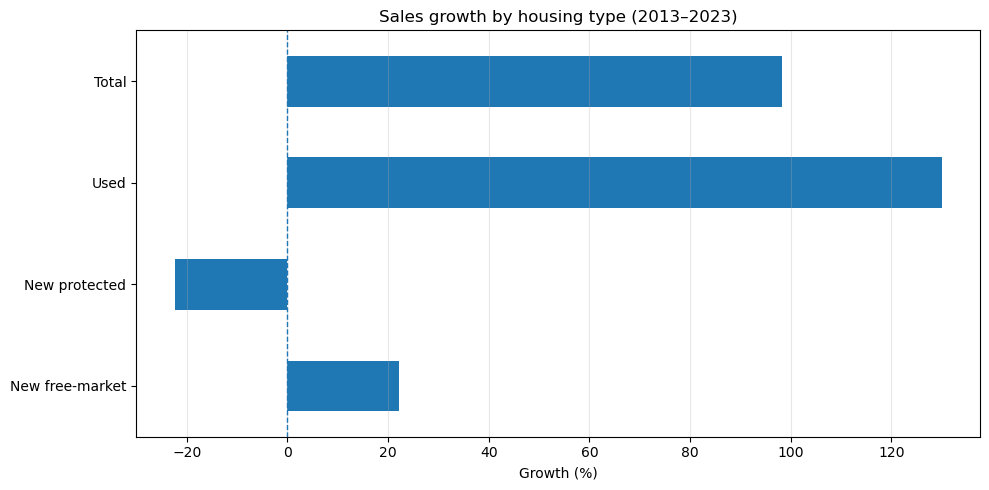

In [79]:
sales_growth.plot(
    x="Type",
    y="growth_pct",
    kind="barh",
    figsize=(10, 5),
    legend=False,
)

plt.axvline(0, linestyle="--", linewidth=1)
plt.title("Sales growth by housing type (2013–2023)")
plt.xlabel("Growth (%)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [80]:
def get_top10_by_period(
    df: pd.DataFrame,
    column: str,
    years: list[int],
) -> pd.DataFrame:
    """Return the top ten municipalities for each requested snapshot year."""
    results = []
    for year in years:
        top10 = (
            df.loc[df["year"] == year]
            .sort_values(column, ascending=False)
            .head(10)[["municipality", column]]
            .copy()
        )
        top10["year"] = year
        top10["rank"] = range(1, len(top10) + 1)
        results.append(top10)
    return pd.concat(results, ignore_index=True)


In [81]:
# Annual ranking snapshots reuse RANKING_YEARS from the central configuration; no second definition is needed.


### Total sales ranking over time

Top 10 municipalities by total home sales in the snapshot years defined centrally in `RANKING_YEARS` (2013, 2017, 2021, and 2023).


In [82]:
top10_total = get_top10_by_period(
    sales_analysis,
    "sales_total",
    RANKING_YEARS
)

ranking_top10 = (
    top10_total
    .pivot(
        index="municipality",
        columns="year",
        values="rank"
    )
    .reset_index()
)


In [83]:
top10_new_free = get_top10_by_period(
    sales_analysis,
    "sales_new_free",
    RANKING_YEARS
)

top10_used = get_top10_by_period(
    sales_analysis,
    "sales_used",
    RANKING_YEARS
)

top10_new_protected = get_top10_by_period(
    sales_analysis,
    "sales_new_protected",
    RANKING_YEARS
)


In [84]:
def ranking_evolution(top10_data: pd.DataFrame) -> pd.DataFrame:
    """Pivot yearly top-ten rankings into one row per municipality."""
    return (
        top10_data
        .pivot(
            index="municipality",
            columns="year",
            values="rank",
        )
        .reset_index()
    )


In [85]:
def plot_ranking_evolution(ranking_data: pd.DataFrame, title: str) -> None:
    """Plot municipality ranks over time, with rank one at the top."""
    ranking_data = ranking_data.set_index("municipality").T

    ranking_data.plot(
        kind="line",
        marker="o",
        figsize=(14, 8),
    )

    plt.gca().invert_yaxis()
    plt.title(title)
    plt.xlabel("Year")
    plt.ylabel("Rank")
    plt.xticks(range(len(RANKING_YEARS)), RANKING_YEARS)
    plt.yticks(range(1, 11))
    plt.grid(True, alpha=0.3)
    plt.legend(
        title="Municipality",
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
    )
    plt.tight_layout()
    plt.show()


In [86]:
ranking_new_free = ranking_evolution(top10_new_free)

ranking_used = ranking_evolution(top10_used)

ranking_new_protected = ranking_evolution(top10_new_protected)


### New free-market housing

In [87]:
ranking_new_free.sort_values(
    ANALYSIS_END_YEAR,
    na_position="last"
)


year,municipality,2013,2016,2020,2023
1,Barcelona,1.0,1.0,1.0,1.0
0,Badalona,NaN,2.0,2.0,2.0
9,Sabadell,6.0,3.0,5.0,3.0
4,"Hospitalet de Llobregat, l'",5.0,NaN,4.0,4.0
13,Sant Joan Despí,NaN,NaN,NaN,5.0
14,Tarragona,9.0,NaN,NaN,6.0
5,Lleida,7.0,5.0,6.0,7.0
7,Mataró,NaN,9.0,NaN,8.0
2,Calafell,10.0,4.0,NaN,9.0
16,Vilanova i la Geltrú,NaN,NaN,NaN,10.0


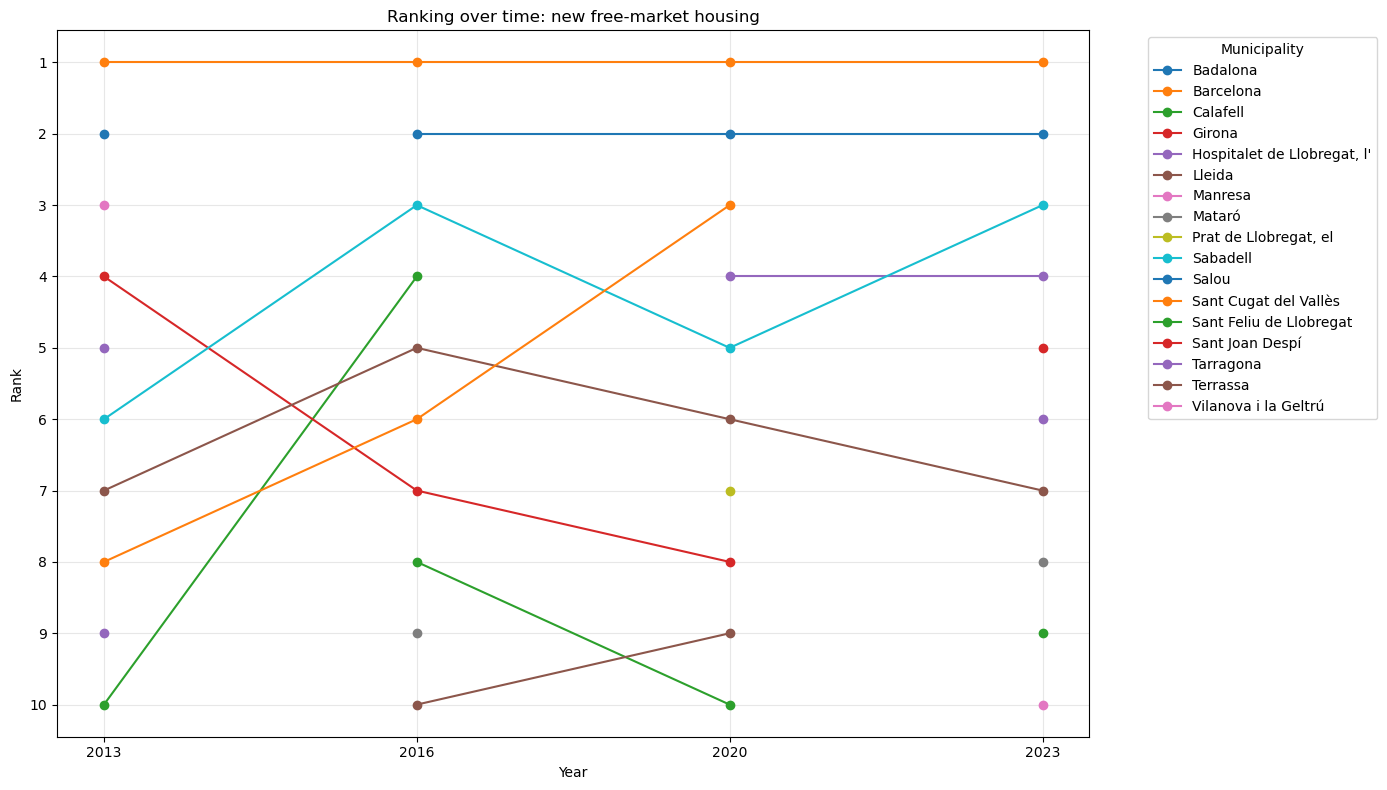

In [88]:
plot_ranking_evolution(
    ranking_new_free,
    "Ranking over time: new free-market housing",
)


### Existing housing

In [89]:
ranking_used.sort_values(
    ANALYSIS_END_YEAR,
    na_position="last"
)


year,municipality,2013,2016,2020,2023
1,Barcelona,1.0,1.0,1.0,1.0
3,"Hospitalet de Llobregat, l'",3.0,3.0,3.0,2.0
10,Terrassa,2.0,2.0,2.0,3.0
7,Sabadell,4.0,4.0,4.0,4.0
0,Badalona,5.0,5.0,6.0,5.0
9,Tarragona,6.0,6.0,5.0,6.0
6,Reus,NaN,8.0,7.0,7.0
4,Lleida,10.0,9.0,8.0,8.0
8,Santa Coloma de Gramenet,NaN,10.0,10.0,9.0
5,Mataró,7.0,7.0,9.0,10.0


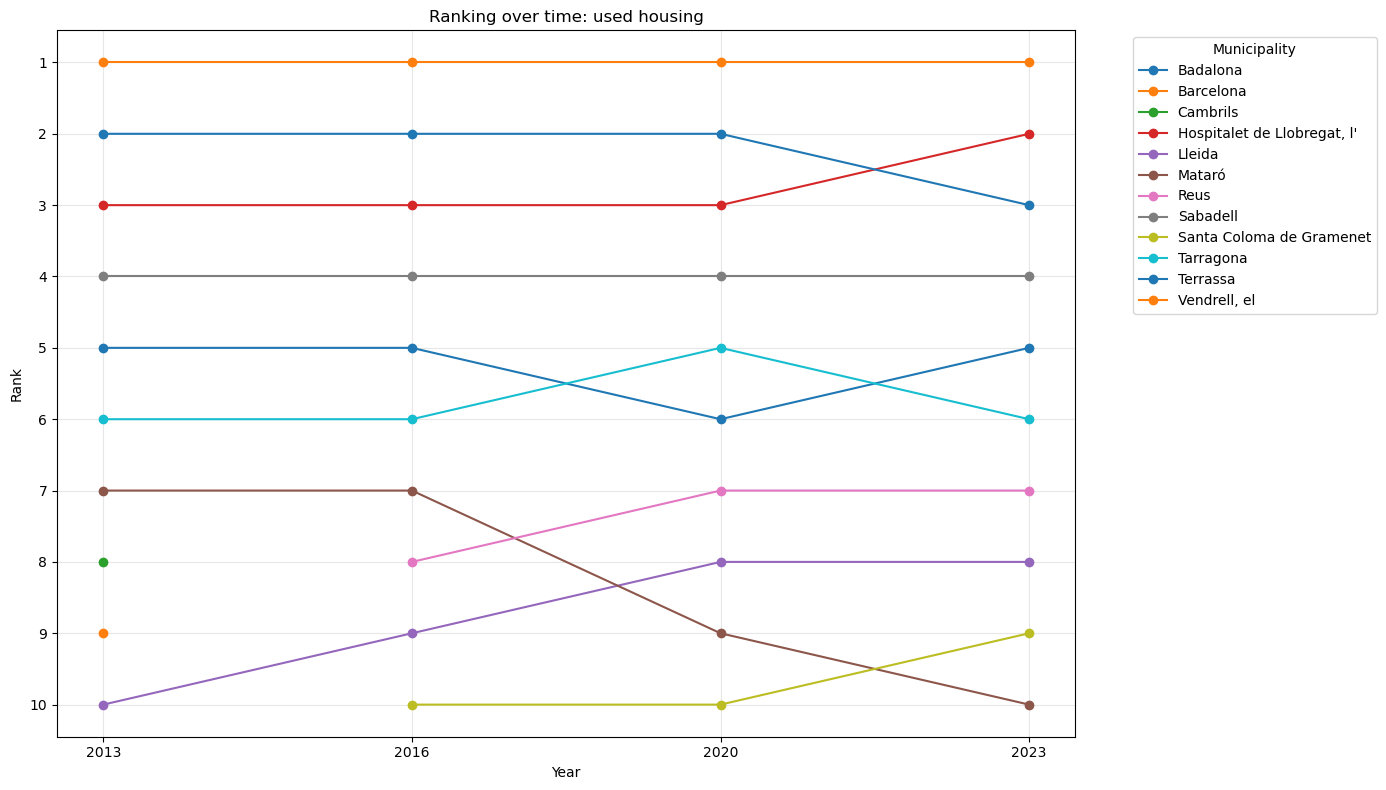

In [90]:
plot_ranking_evolution(
    ranking_used,
    "Ranking over time: used housing",
)


### New protected housing

In [91]:
ranking_new_protected.sort_values(
    ANALYSIS_END_YEAR,
    na_position="last"
)


year,municipality,2013,2016,2020,2023
6,Lleida,3.0,2.0,2.0,1.0
3,Gavà,NaN,NaN,NaN,2.0
1,Barcelona,2.0,1.0,5.0,3.0
8,Reus,4.0,8.0,7.0,4.0
0,Badalona,NaN,3.0,3.0,5.0
9,Sabadell,7.0,4.0,4.0,6.0
5,"Hospitalet de Llobregat, l'",5.0,NaN,1.0,7.0
15,Tarragona,6.0,NaN,NaN,8.0
10,Salt,NaN,10.0,9.0,9.0
7,Olot,NaN,NaN,NaN,10.0


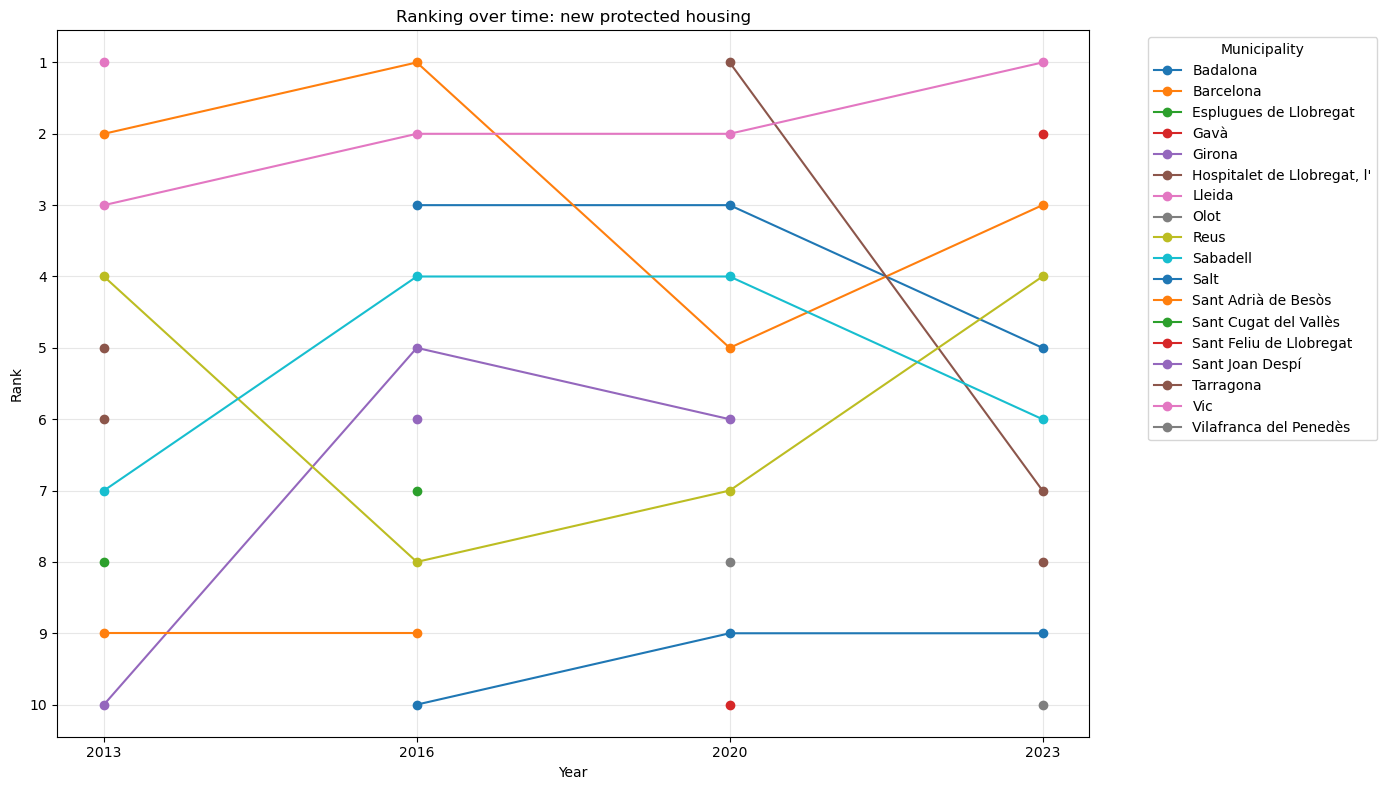

In [92]:
plot_ranking_evolution(
    ranking_new_protected,
    "Ranking over time: new protected housing",
)


## Rental Market

In [93]:
print("Dataset shape:", rent_analysis.shape)
print("\nColumns:")
print(rent_analysis.columns.tolist())
print("\nData types:")
rent_analysis.info()
print("\nSample rows with year-over-year rent growth:")
display(
    rent_analysis[
        ["municipality_code", "municipality", "year", "rent_mean", "rent_growth_pct"]
    ].head()
)


Dataset shape: (517, 7)

Columns:
['municipality_code', 'municipality', 'comarca', 'rent_mean', 'municipality_code_source', 'year', 'rent_growth_pct']

Data types:
<class 'pandas.core.frame.DataFrame'>
Index: 517 entries, 47 to 563
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   municipality_code         517 non-null    string 
 1   municipality              517 non-null    object 
 2   comarca                   517 non-null    object 
 3   rent_mean                 517 non-null    float64
 4   municipality_code_source  517 non-null    int64  
 5   year                      517 non-null    int64  
 6   rent_growth_pct           470 non-null    float64
dtypes: float64(2), int64(2), object(2), string(1)
memory usage: 32.3+ KB

Sample rows with year-over-year rent growth:


,municipality_code,municipality,year,rent_mean,rent_growth_pct
47,08015,Badalona,2023,848.905793,5.059842
48,08252,Barberà del Vallès,2023,756.793780,7.404099
49,08019,Barcelona,2023,1136.399961,10.667406
50,17023,Blanes,2023,597.641958,7.837641
51,43037,Calafell,2023,679.071963,5.428129


In [94]:
print("\nSummary statistics for mean monthly rent:")
display(rent_analysis["rent_mean"].describe())



Summary statistics for mean monthly rent:


count     517.000000
mean      610.167693
std       173.801138
min       314.328201
25%       485.632096
50%       581.138109
75%       702.768790
max      1341.571260
Name: rent_mean, dtype: float64

In [95]:
rent_analysis.groupby("year")["rent_mean"].describe().round(2)


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2013,47.0,505.12,113.10,320.62,431.36,492.57,554.57,868.67
2014,47.0,500.35,118.98,317.70,427.66,477.98,560.86,858.32
2015,47.0,514.04,126.81,314.33,428.04,495.96,563.37,897.54
2016,47.0,542.89,141.94,327.78,446.37,531.15,597.70,996.07
2017,47.0,584.37,161.35,337.72,472.55,561.03,646.83,1095.85
2018,47.0,624.21,163.45,346.42,510.29,616.33,701.17,1149.55
2019,47.0,659.37,164.81,376.08,528.63,647.20,724.63,1134.23
2020,47.0,671.27,167.75,373.93,542.03,651.03,747.60,1177.85
2021,47.0,651.24,162.81,378.30,540.02,635.89,721.50,1175.42


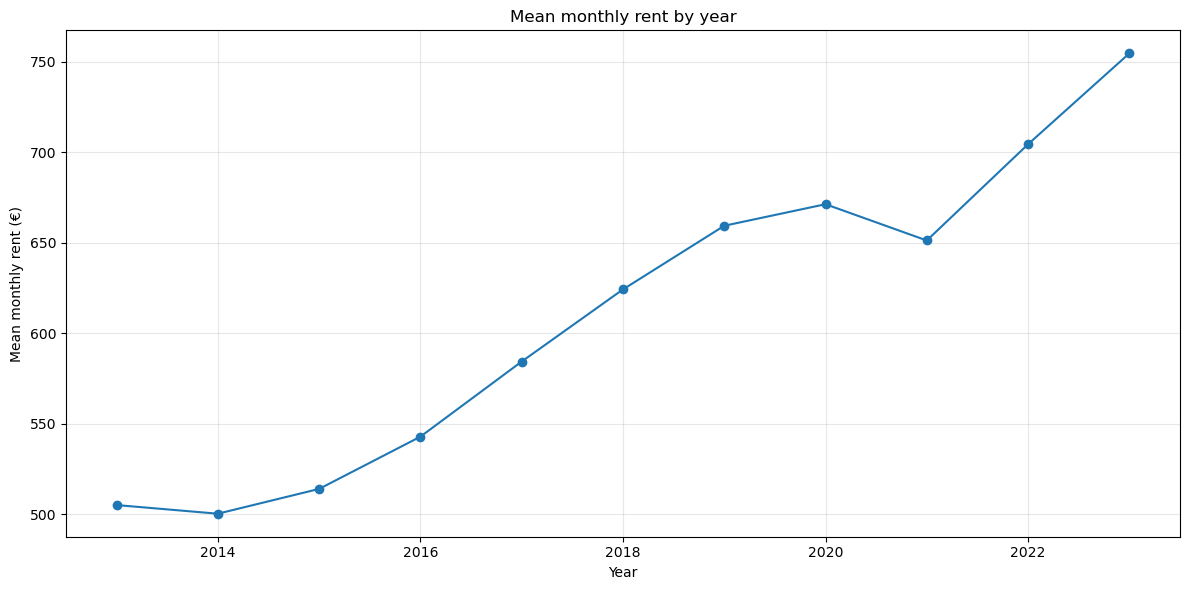

In [96]:
rent_mean_by_year = (
    rent_analysis
    .groupby("year", as_index=False)["rent_mean"]
    .mean()
)

ax = rent_mean_by_year.plot(
    x="year",
    y="rent_mean",
    kind="line",
    marker="o",
    figsize=(12, 6),
    legend=False,
)
ax.set_title("Mean monthly rent by year")
ax.set_xlabel("Year")
ax.set_ylabel("Mean monthly rent (€)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


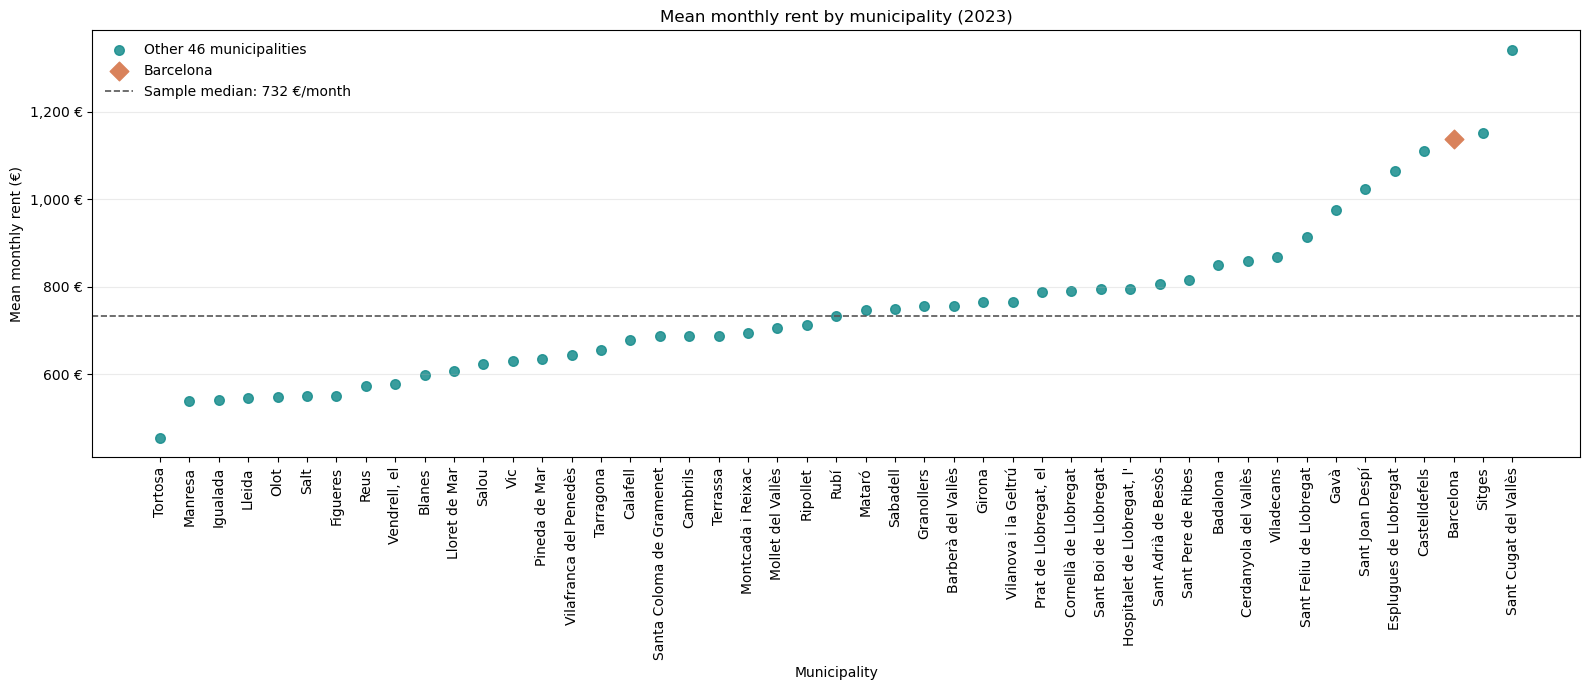

Municipalities represented: 47


In [97]:
rent_2023_plot = (
    rent_analysis.loc[rent_analysis["year"] == ANALYSIS_END_YEAR]
    .copy()
    .sort_values("rent_mean")
    .reset_index(drop=True)
)

assert rent_2023_plot["municipality_code"].nunique() == 47
assert rent_2023_plot["municipality"].nunique() == 47

positions = np.arange(len(rent_2023_plot))
barcelona_mask = rent_2023_plot["municipality"].str.casefold().eq("barcelona")
median_rent_2023 = rent_2023_plot["rent_mean"].median()

fig, ax = plt.subplots(figsize=(16, 7))
ax.scatter(
    positions[~barcelona_mask.to_numpy()],
    rent_2023_plot.loc[~barcelona_mask, "rent_mean"],
    color="#168C8C",
    s=48,
    alpha=0.85,
    label="Other 46 municipalities",
)
ax.scatter(
    positions[barcelona_mask.to_numpy()],
    rent_2023_plot.loc[barcelona_mask, "rent_mean"],
    color="#D9825B",
    marker="D",
    s=90,
    zorder=3,
    label="Barcelona",
)
ax.axhline(
    median_rent_2023,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Sample median: {median_rent_2023:,.0f} €/month",
)
ax.set_xticks(positions)
ax.set_xticklabels(rent_2023_plot["municipality"], rotation=90)
ax.set_title("Mean monthly rent by municipality (2023)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Mean monthly rent (€)")
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f} €")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()
print(f"Municipalities represented: {rent_2023_plot['municipality_code'].nunique()}")


In [98]:
rent_growth_by_year = rent_mean_by_year.copy()
rent_growth_by_year["annual_growth_pct"] = rent_growth_by_year["rent_mean"].pct_change() * 100

rent_2013_mean = rent_growth_by_year.loc[
    rent_growth_by_year["year"] == ANALYSIS_START_YEAR, "rent_mean"
].iloc[0]
rent_growth_by_year["growth_since_2013_pct"] = (
    (rent_growth_by_year["rent_mean"] / rent_2013_mean - 1) * 100
)
rent_total_growth_pct = (
    (rent_growth_by_year.loc[rent_growth_by_year["year"] == ANALYSIS_END_YEAR, "rent_mean"].iloc[0]
     / rent_2013_mean)
    - 1
) * 100

display(
    rent_growth_by_year[
        ["year", "rent_mean", "annual_growth_pct", "growth_since_2013_pct"]
    ].style.format(
        {
            "year": "{:.0f}",
            "rent_mean": "{:,.2f} €",
            "annual_growth_pct": "{:+.2f}%",
            "growth_since_2013_pct": "{:+.2f}%",
        },
        na_rep="—",
    ).set_caption("Annual and cumulative growth in mean rent")
)
print(f"Total change in mean rent, 2013–2023: {rent_total_growth_pct:+.2f}%")


,year,rent_mean,annual_growth_pct,growth_since_2013_pct
0,2013,505.12 €,—,+0.00%
1,2014,500.35 €,-0.94%,-0.94%
2,2015,514.04 €,+2.74%,+1.77%
3,2016,542.89 €,+5.61%,+7.48%
4,2017,584.37 €,+7.64%,+15.69%
5,2018,624.21 €,+6.82%,+23.58%
6,2019,659.37 €,+5.63%,+30.54%
7,2020,671.27 €,+1.81%,+32.89%
8,2021,651.24 €,-2.98%,+28.93%
9,2022,704.40 €,+8.16%,+39.45%


Total change in mean rent, 2013–2023: +49.39%


,year,contracts,annual_growth_pct
8,2013,"150,200",—
9,2014,"149,733",-0.31%
10,2015,"141,767",-5.32%
11,2016,"142,714",+0.67%
12,2017,"156,936",+9.97%
13,2018,"167,953",+7.02%
14,2019,"162,520",-3.23%
15,2020,"135,509",-16.62%
16,2021,"167,842",+23.86%
17,2022,"152,770",-8.98%


Total change in contracts, 2013–2023: -11.46% (150,200 to 132,988 contracts)


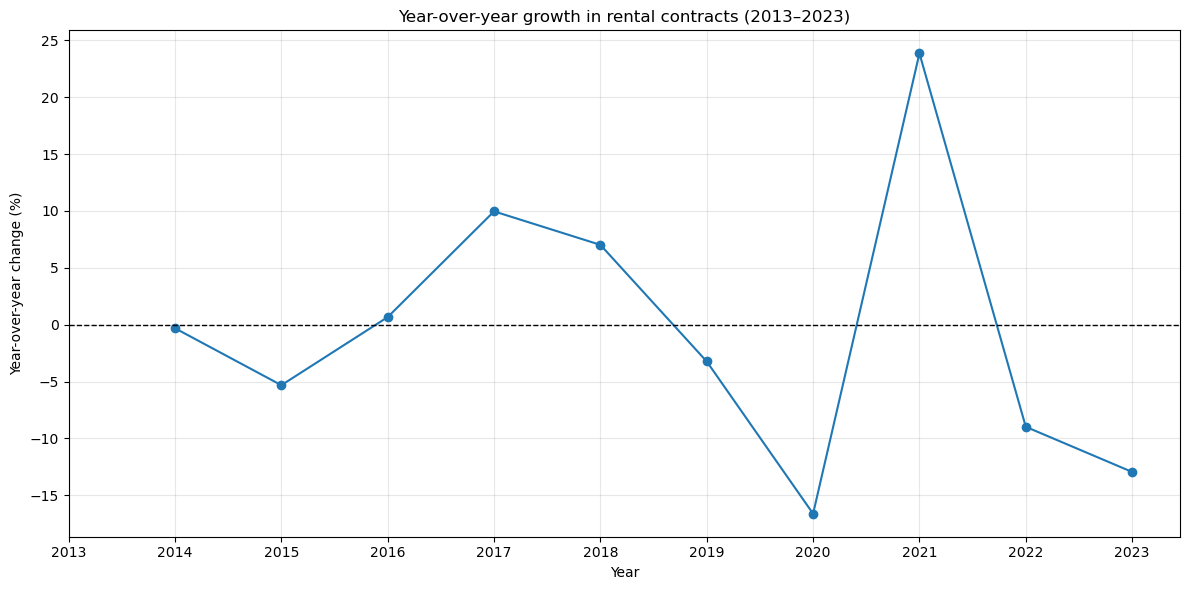

In [99]:
contracts_complete_years = (
    contracts_by_year.loc[contracts_by_year["year_complete"]]
    .sort_values("year")
    .copy()
)
contracts_complete_years["annual_growth_pct"] = (
    contracts_complete_years["contracts"].pct_change() * 100
)
contracts_growth_by_year = contracts_complete_years.loc[
    contracts_complete_years["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].copy()
contracts_growth_table = contracts_growth_by_year[
    ["year", "contracts", "annual_growth_pct"]
].copy()

display(
    contracts_growth_table.style.format(
        {
            "year": "{:.0f}",
            "contracts": "{:,.0f}",
            "annual_growth_pct": "{:+.2f}%",
        },
        na_rep="—",
    ).set_caption("Rental contracts and annual growth (2013–2023)")
)

contracts_2013 = contracts_complete_years.loc[
    contracts_complete_years["year"] == ANALYSIS_START_YEAR, "contracts"
].iloc[0]
contracts_2023 = contracts_complete_years.loc[
    contracts_complete_years["year"] == ANALYSIS_END_YEAR, "contracts"
].iloc[0]
contracts_total_change_pct = (contracts_2023 / contracts_2013 - 1) * 100
print(
    f"Total change in contracts, 2013–2023: {contracts_total_change_pct:+.2f}% "
    f"({contracts_2013:,.0f} to {contracts_2023:,.0f} contracts)"
)

ax = contracts_growth_by_year.plot(
    x="year",
    y="annual_growth_pct",
    kind="line",
    marker="o",
    figsize=(12, 6),
    legend=False,
)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_title("Year-over-year growth in rental contracts (2013–2023)")
ax.set_xlabel("Year")
ax.set_ylabel("Year-over-year change (%)")
ax.set_xticks(contracts_growth_by_year["year"])
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


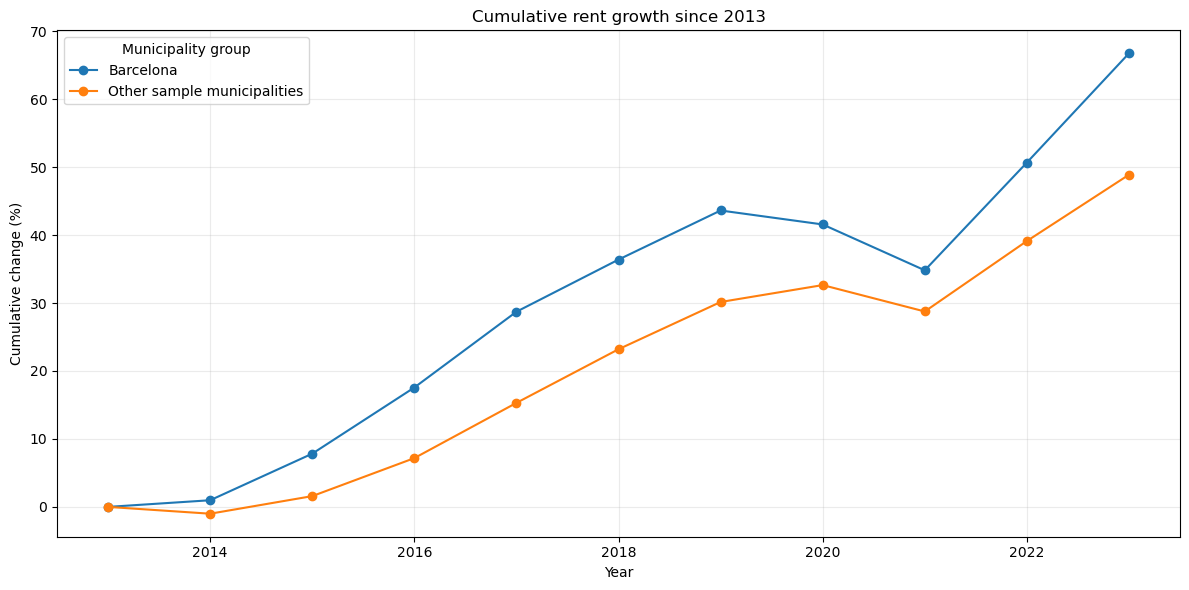

,Year,Barcelona: annual change (%),Other municipalities: annual change (%),Barcelona: cumulative change since 2013 (%),Other municipalities: cumulative change since 2013 (%)
0,2013,—,—,+0.00%,+0.00%
1,2014,+0.98%,-1.00%,+0.98%,-1.00%
2,2015,+6.79%,+2.61%,+7.83%,+1.59%
3,2016,+9.03%,+5.50%,+17.57%,+7.18%
4,2017,+9.48%,+7.58%,+28.72%,+15.30%
5,2018,+5.96%,+6.85%,+36.39%,+23.20%
6,2019,+5.30%,+5.64%,+43.61%,+30.15%
7,2020,-1.43%,+1.91%,+41.56%,+32.64%
8,2021,-4.76%,-2.93%,+34.81%,+28.75%
9,2022,+11.76%,+8.05%,+50.66%,+39.12%


Total rent growth, 2013–2023 | Barcelona: +66.74% | Other sample municipalities: +48.87%


In [100]:
rent_by_group = (
    rent_analysis
    .assign(
        group=np.where(
            rent_analysis["municipality"].eq("Barcelona"),
            "Barcelona",
            "Other sample municipalities",
        )
    )
    .groupby(["year", "group"])["rent_mean"]
    .mean()
    .unstack()
    .sort_index()
)
rent_by_group = rent_by_group[["Barcelona", "Other sample municipalities"]]
rent_annual_growth_by_group = rent_by_group.pct_change() * 100
rent_cumulative_growth_by_group = rent_by_group.div(rent_by_group.loc[ANALYSIS_START_YEAR]).sub(1) * 100

ax = rent_cumulative_growth_by_group.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
)
ax.set_title("Cumulative rent growth since 2013")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative change (%)")
ax.legend(title="Municipality group")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

rent_growth_comparison = pd.DataFrame({
    "Year": rent_by_group.index,
    "Barcelona: annual change (%)": rent_annual_growth_by_group["Barcelona"].values,
    "Other municipalities: annual change (%)": rent_annual_growth_by_group["Other sample municipalities"].values,
    "Barcelona: cumulative change since 2013 (%)": rent_cumulative_growth_by_group["Barcelona"].values,
    "Other municipalities: cumulative change since 2013 (%)": rent_cumulative_growth_by_group["Other sample municipalities"].values,
})

display(
    rent_growth_comparison.style.format(
        {
            "Year": "{:.0f}",
            "Barcelona: annual change (%)": "{:+.2f}%",
            "Other municipalities: annual change (%)": "{:+.2f}%",
            "Barcelona: cumulative change since 2013 (%)": "{:+.2f}%",
            "Other municipalities: cumulative change since 2013 (%)": "{:+.2f}%",
        },
        na_rep="—",
    ).set_caption("Mean rent growth: Barcelona vs. the other sample municipalities")
)
print(
    "Total rent growth, 2013–2023 | "
    f"Barcelona: {rent_cumulative_growth_by_group.loc[ANALYSIS_END_YEAR, 'Barcelona']:+.2f}% | "
    "Other sample municipalities: "
    f"{rent_cumulative_growth_by_group.loc[ANALYSIS_END_YEAR, 'Other sample municipalities']:+.2f}%"
)


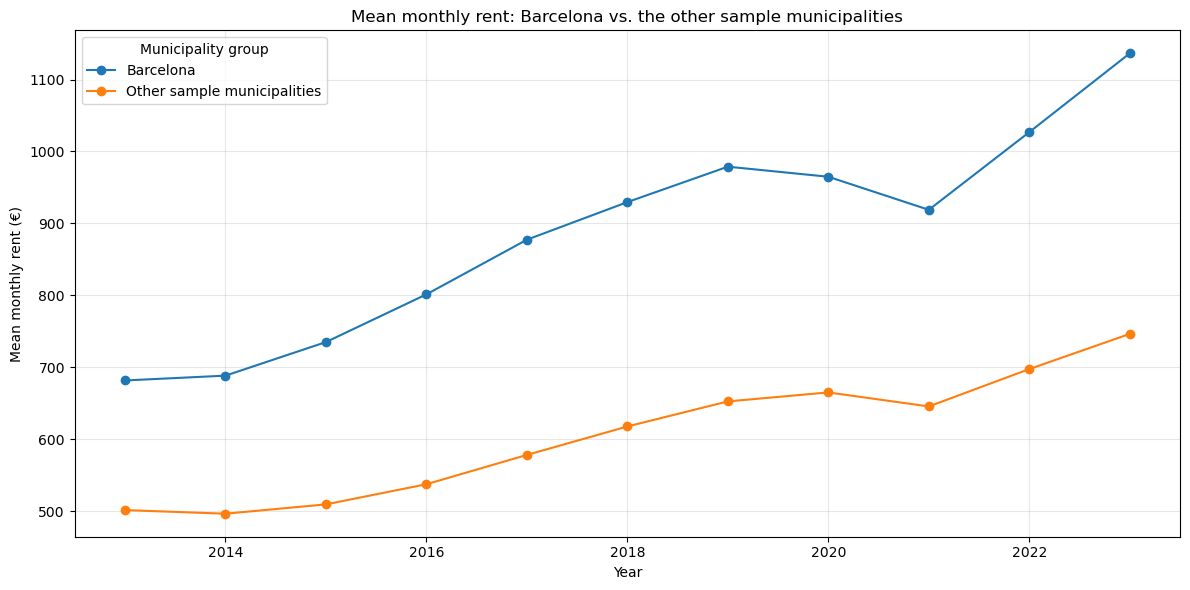

,Year,Barcelona: mean rent (€/month),Other municipalities: mean rent (€/month),Barcelona: increase since 2013 (€),Other municipalities: increase since 2013 (€)
0,2013,681.56 €,501.28 €,+0.00 €,+0.00 €
1,2014,688.23 €,496.27 €,+6.68 €,-5.02 €
2,2015,734.94 €,509.24 €,+53.38 €,+7.95 €
3,2016,801.28 €,537.27 €,+119.73 €,+35.98 €
4,2017,877.28 €,578.00 €,+195.72 €,+76.72 €
5,2018,929.57 €,617.57 €,+248.01 €,+116.29 €
6,2019,978.81 €,652.42 €,+297.25 €,+151.14 €
7,2020,964.81 €,664.89 €,+283.25 €,+163.61 €
8,2021,918.84 €,645.42 €,+237.28 €,+144.14 €
9,2022,"1,026.86 €",697.39 €,+345.30 €,+196.10 €


Absolute rent increase, 2013–2023 | Barcelona: +454.84 €/month | Other sample municipalities: +245.00 €/month


In [101]:
rent_absolute_growth_by_group = rent_by_group.sub(rent_by_group.loc[ANALYSIS_START_YEAR])

ax = rent_by_group.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
)
ax.set_title("Mean monthly rent: Barcelona vs. the other sample municipalities")
ax.set_xlabel("Year")
ax.set_ylabel("Mean monthly rent (€)")
ax.legend(title="Municipality group")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rent_absolute_comparison = pd.DataFrame(
    {
        "Year": rent_by_group.index,
        "Barcelona: mean rent (€/month)": rent_by_group["Barcelona"].values,
        "Other municipalities: mean rent (€/month)": rent_by_group["Other sample municipalities"].values,
        "Barcelona: increase since 2013 (€)": rent_absolute_growth_by_group["Barcelona"].values,
        "Other municipalities: increase since 2013 (€)": rent_absolute_growth_by_group["Other sample municipalities"].values,
    }
)
display(
    rent_absolute_comparison.style.format(
        {
            "Year": "{:.0f}",
            "Barcelona: mean rent (€/month)": "{:,.2f} €",
            "Other municipalities: mean rent (€/month)": "{:,.2f} €",
            "Barcelona: increase since 2013 (€)": "{:+,.2f} €",
            "Other municipalities: increase since 2013 (€)": "{:+,.2f} €",
        }
    ).set_caption("Mean monthly rent and absolute change since 2013")
)
print(
    "Absolute rent increase, 2013–2023 | "
    f"Barcelona: {rent_absolute_growth_by_group.loc[ANALYSIS_END_YEAR, 'Barcelona']:+,.2f} €/month | "
    "Other sample municipalities: "
    f"{rent_absolute_growth_by_group.loc[ANALYSIS_END_YEAR, 'Other sample municipalities']:+,.2f} €/month"
)


In [102]:
rent_2013_2023_by_municipality = (
    rent_analysis.loc[rent_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])]
    .pivot(
        index=["municipality_code", "municipality"],
        columns="year",
        values="rent_mean",
    )
    .dropna(subset=[ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])
    .reset_index()
)
rent_2013_2023_by_municipality["growth_abs_eur"] = (
    rent_2013_2023_by_municipality[ANALYSIS_END_YEAR] - rent_2013_2023_by_municipality[ANALYSIS_START_YEAR]
)
rent_2013_2023_by_municipality["growth_pct"] = (
    (rent_2013_2023_by_municipality[ANALYSIS_END_YEAR] / rent_2013_2023_by_municipality[ANALYSIS_START_YEAR] - 1)
    * 100
)

top_10_rent_growth_pct = (
    rent_2013_2023_by_municipality
    .nlargest(10, "growth_pct")
    [["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "growth_abs_eur", "growth_pct"]]
    .reset_index(drop=True)
)
top_10_rent_growth_abs = (
    rent_2013_2023_by_municipality
    .nlargest(10, "growth_abs_eur")
    [["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "growth_abs_eur", "growth_pct"]]
    .reset_index(drop=True)
)

print("Top 10 municipalities by percentage rent growth, 2013–2023:")
display(
    top_10_rent_growth_pct.style.format(
        {ANALYSIS_START_YEAR: "{:,.2f} €", ANALYSIS_END_YEAR: "{:,.2f} €", "growth_abs_eur": "{:+,.2f} €", "growth_pct": "{:+.2f}%"}
    )
)
print("Top 10 municipalities by absolute rent increase, 2013–2023:")
display(
    top_10_rent_growth_abs.style.format(
        {ANALYSIS_START_YEAR: "{:,.2f} €", ANALYSIS_END_YEAR: "{:,.2f} €", "growth_abs_eur": "{:+,.2f} €", "growth_pct": "{:+.2f}%"}
    )
)


Top 10 municipalities by percentage rent growth, 2013–2023:


year,municipality,2013,2023,growth_abs_eur,growth_pct
0,Barcelona,681.56 €,"1,136.40 €",+454.84 €,+66.74%
1,Girona,471.80 €,764.55 €,+292.75 €,+62.05%
2,Vilafranca del Penedès,402.37 €,643.65 €,+241.28 €,+59.96%
3,Castelldefels,694.07 €,"1,109.95 €",+415.88 €,+59.92%
4,Sant Joan Despí,646.20 €,"1,024.28 €",+378.08 €,+58.51%
5,Esplugues de Llobregat,671.42 €,"1,063.77 €",+392.35 €,+58.43%
6,Olot,347.43 €,547.04 €,+199.61 €,+57.45%
7,Badalona,541.15 €,848.91 €,+307.76 €,+56.87%
8,Terrassa,440.53 €,687.70 €,+247.17 €,+56.11%
9,Sitges,737.91 €,"1,150.51 €",+412.59 €,+55.91%


Top 10 municipalities by absolute rent increase, 2013–2023:


year,municipality,2013,2023,growth_abs_eur,growth_pct
0,Sant Cugat del Vallès,868.67 €,"1,341.57 €",+472.90 €,+54.44%
1,Barcelona,681.56 €,"1,136.40 €",+454.84 €,+66.74%
2,Castelldefels,694.07 €,"1,109.95 €",+415.88 €,+59.92%
3,Sitges,737.91 €,"1,150.51 €",+412.59 €,+55.91%
4,Esplugues de Llobregat,671.42 €,"1,063.77 €",+392.35 €,+58.43%
5,Sant Joan Despí,646.20 €,"1,024.28 €",+378.08 €,+58.51%
6,Gavà,657.78 €,976.09 €,+318.30 €,+48.39%
7,Sant Feliu de Llobregat,597.67 €,913.11 €,+315.44 €,+52.78%
8,Badalona,541.15 €,848.91 €,+307.76 €,+56.87%
9,Girona,471.80 €,764.55 €,+292.75 €,+62.05%


In [103]:
top_10_rent_expensive_2023 = (
    rent_2013_2023_by_municipality
    .sort_values(ANALYSIS_END_YEAR, ascending=False)
    .head(10)
    [["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "growth_abs_eur", "growth_pct"]]
    .reset_index(drop=True)
)

print("Top 10 municipalities by mean monthly rent in 2023:")
display(
    top_10_rent_expensive_2023.style.format(
        {
            ANALYSIS_START_YEAR: "{:,.2f} €",
            ANALYSIS_END_YEAR: "{:,.2f} €",
            "growth_abs_eur": "{:+,.2f} €",
            "growth_pct": "{:+.2f}%",
        }
    )
)


Top 10 municipalities by mean monthly rent in 2023:


year,municipality,2013,2023,growth_abs_eur,growth_pct
0,Sant Cugat del Vallès,868.67 €,"1,341.57 €",+472.90 €,+54.44%
1,Sitges,737.91 €,"1,150.51 €",+412.59 €,+55.91%
2,Barcelona,681.56 €,"1,136.40 €",+454.84 €,+66.74%
3,Castelldefels,694.07 €,"1,109.95 €",+415.88 €,+59.92%
4,Esplugues de Llobregat,671.42 €,"1,063.77 €",+392.35 €,+58.43%
5,Sant Joan Despí,646.20 €,"1,024.28 €",+378.08 €,+58.51%
6,Gavà,657.78 €,976.09 €,+318.30 €,+48.39%
7,Sant Feliu de Llobregat,597.67 €,913.11 €,+315.44 €,+52.78%
8,Viladecans,606.42 €,867.01 €,+260.58 €,+42.97%
9,Cerdanyola del Vallès,578.80 €,859.18 €,+280.38 €,+48.44%


In [104]:
# Municipal rent change over the full analysis period only (2013–2023).
rent_period_values = (
    rent_analysis.loc[rent_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])]
    .pivot(
        index=["municipality_code", "municipality"],
        columns="year",
        values="rent_mean",
    )
    .dropna(subset=[ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])
    .sort_index()
)

start_rent = rent_period_values[ANALYSIS_START_YEAR]
end_rent = rent_period_values[ANALYSIS_END_YEAR]
elapsed_years = ELAPSED_ANALYSIS_YEARS
rent_ratio = end_rent.div(start_rent.where(start_rent.ne(0)))
rent_period_values["absolute_change_eur"] = end_rent - start_rent
rent_period_values["cumulative_growth_pct"] = (rent_ratio - 1) * 100
rent_period_values["annualized_growth_pct"] = (rent_ratio.pow(1 / elapsed_years) - 1) * 100

rent_period_summary = pd.DataFrame([{
    "Period": f"{ANALYSIS_START_YEAR}–{ANALYSIS_END_YEAR}",
    "Municipalities": rent_period_values.index.get_level_values("municipality").nunique(),
    "Mean starting rent (€/month)": start_rent.mean(),
    "Mean ending rent (€/month)": end_rent.mean(),
    "Mean absolute increase (€/month)": rent_period_values["absolute_change_eur"].mean(),
    "Mean municipal cumulative growth (%)": rent_period_values["cumulative_growth_pct"].mean(),
    "Mean annualized growth (%)": rent_period_values["annualized_growth_pct"].mean(),
    "Median municipal cumulative growth (%)": rent_period_values["cumulative_growth_pct"].median(),
}])

display(rent_period_summary.style.format({
    "Mean starting rent (€/month)": "{:,.2f} €",
    "Mean ending rent (€/month)": "{:,.2f} €",
    "Mean absolute increase (€/month)": "{:+,.2f} €",
    "Mean municipal cumulative growth (%)": "{:+.2f}%",
    "Mean annualized growth (%)": "{:+.2f}%",
    "Median municipal cumulative growth (%)": "{:+.2f}%",
}).set_caption("Municipal rent growth over the full analysis period"))

rent_growth_by_municipality = rent_period_values.reset_index()
print("Top 10 municipalities by cumulative rent growth:")
display(rent_growth_by_municipality.nlargest(10, "cumulative_growth_pct")[
    ["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "absolute_change_eur",
     "cumulative_growth_pct", "annualized_growth_pct"]
].round(2))
print("Bottom 10 municipalities by cumulative rent growth:")
display(rent_growth_by_municipality.nsmallest(10, "cumulative_growth_pct")[
    ["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "absolute_change_eur",
     "cumulative_growth_pct", "annualized_growth_pct"]
].round(2))


,Period,Municipalities,Mean starting rent (€/month),Mean ending rent (€/month),Mean absolute increase (€/month),Mean municipal cumulative growth (%),Mean annualized growth (%),Median municipal cumulative growth (%)
0,2013–2023,47,505.12 €,754.59 €,+249.47 €,+48.90%,+4.05%,+48.44%


Top 10 municipalities by cumulative rent growth:


year,municipality,2013,2023,absolute_change_eur,cumulative_growth_pct,annualized_growth_pct
1,Barcelona,681.56,1136.40,454.84,66.74,5.25
35,Girona,471.80,764.55,292.75,62.05,4.95
31,Vilafranca del Penedès,402.37,643.65,241.28,59.96,4.81
2,Castelldefels,694.07,1109.95,415.88,59.92,4.81
22,Sant Joan Despí,646.20,1024.28,378.08,58.51,4.71
4,Esplugues de Llobregat,671.42,1063.77,392.35,58.43,4.71
37,Olot,347.43,547.04,199.61,57.45,4.64
0,Badalona,541.15,848.91,307.76,56.87,4.61
28,Terrassa,440.53,687.70,247.17,56.11,4.55
27,Sitges,737.91,1150.51,412.59,55.91,4.54


Bottom 10 municipalities by cumulative rent growth:


year,municipality,2013,2023,absolute_change_eur,cumulative_growth_pct,annualized_growth_pct
12,Montcada i Reixac,513.62,694.11,180.49,35.14,3.06
34,Figueres,405.32,549.81,144.49,35.65,3.10
14,"Prat de Llobregat, el",575.80,787.32,211.51,36.73,3.18
36,Lloret de Mar,439.46,606.11,166.65,37.92,3.27
46,Salou,449.41,624.13,174.72,38.88,3.34
25,Barberà del Vallès,542.97,756.79,213.82,39.38,3.38
13,Pineda de Mar,451.77,634.19,182.42,40.38,3.45
15,Ripollet,505.12,712.38,207.26,41.03,3.50
33,Blanes,423.29,597.64,174.35,41.19,3.51
44,Tortosa,320.62,454.02,133.40,41.61,3.54


Municipality rankings by mean rent for selected snapshot years:


year,municipality,2013,2016,2020,2023
5,Sant Cugat del Vallès,1,1,1,1
8,Sitges,2,2,3,2
0,Barcelona,4,4,4,3
1,Castelldefels,3,3,2,4
3,Esplugues de Llobregat,5,6,6,5
7,Sant Joan Despí,7,7,7,6
4,Gavà,6,5,5,7
6,Sant Feliu de Llobregat,9,9,8,8
9,Viladecans,8,10,10,9
2,Cerdanyola del Vallès,10,8,9,10


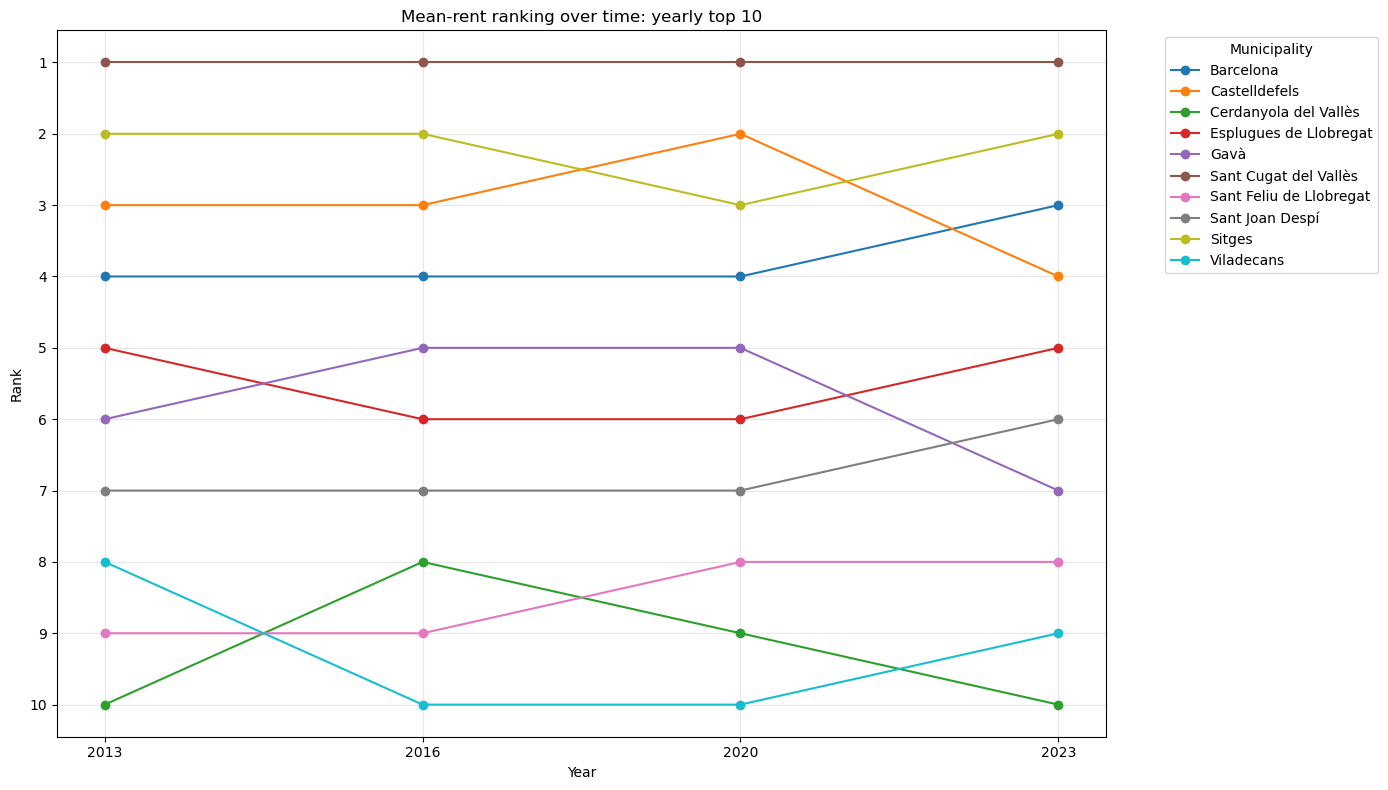

In [105]:
rent_top10_by_period = get_top10_by_period(rent_analysis, "rent_mean", RANKING_YEARS)
rent_ranking_top10 = ranking_evolution(rent_top10_by_period)

print("Municipality rankings by mean rent for selected snapshot years:")
display(
    rent_ranking_top10.sort_values(ANALYSIS_END_YEAR, na_position="last").style.format(
        {year: "{:.0f}" for year in RANKING_YEARS},
        na_rep="Outside top 10",
    )
)
plot_ranking_evolution(
    rent_ranking_top10,
    "Mean-rent ranking over time: yearly top 10",
)


In [106]:
rent_values_2023 = rent_analysis.loc[
    rent_analysis["year"] == ANALYSIS_END_YEAR,
    "rent_mean",
]

print("Summary statistics for mean monthly rent in 2023:")
display(rent_values_2023.describe().round(2))


Summary statistics for mean monthly rent in 2023:


count      47.00
mean      754.59
std       187.80
min       454.02
25%       627.04
50%       732.19
75%       810.79
max      1341.57
Name: rent_mean, dtype: float64

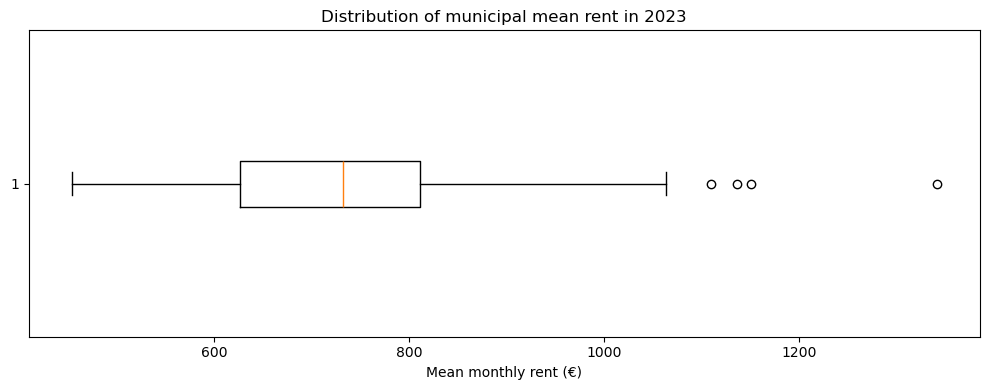

In [107]:
plt.figure(figsize=(10, 4))
plt.boxplot(rent_values_2023, vert=False)
plt.title("Distribution of municipal mean rent in 2023")
plt.xlabel("Mean monthly rent (€)")
plt.tight_layout()
plt.show()


## Income

In [108]:
print("\nSummary statistics for per-capita income:")
display(income_analysis["income_per_capita_eur"].describe())



Summary statistics for per-capita income:


count      517.000000
mean     16882.773694
std       2741.225192
min       9525.000000
25%      15300.000000
50%      16586.000000
75%      18150.000000
max      30434.000000
Name: income_per_capita_eur, dtype: float64

In [109]:
print("\nPer-capita income summary by year:")
income_stats_by_year = (
    income_analysis
    .groupby("year")["income_per_capita_eur"]
    .describe()
    .round(2)
)
display(income_stats_by_year)



Per-capita income summary by year:


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2013,47.0,15114.49,2096.81,9525.0,13925.0,15123.0,15978.0,20828.0
2014,47.0,15341.87,2133.37,10104.0,14069.0,15331.0,16248.5,21079.0
2015,47.0,15946.66,2360.54,10773.0,14567.0,15867.0,16840.0,22719.0
2016,47.0,16306.72,2470.95,11300.0,14979.5,16068.0,16967.5,24014.0
2017,47.0,16520.17,2512.11,11640.0,15241.0,16256.0,17241.5,24391.0
2018,47.0,16735.87,2481.36,11973.0,15491.0,16537.0,17458.0,24835.0
2019,47.0,17451.49,2651.38,12411.0,16049.5,17140.0,18019.5,26201.0
2020,47.0,16823.89,2531.27,11548.0,15460.5,16531.0,17597.5,25426.0
2021,47.0,17781.30,2429.16,12581.0,16546.0,17649.0,18578.0,25918.0


,year,unweighted_mean_municipal_income_eur,annual_change_eur,annual_growth_pct,change_since_2013_eur,growth_since_2013_pct,municipalities_with_data
0,2013,"15,114.49 €",—,—,+0.00 €,+0.00%,47
1,2014,"15,341.87 €",+227.38 €,+1.50%,+227.38 €,+1.50%,47
2,2015,"15,946.66 €",+604.79 €,+3.94%,+832.17 €,+5.51%,47
3,2016,"16,306.72 €",+360.06 €,+2.26%,"+1,192.23 €",+7.89%,47
4,2017,"16,520.17 €",+213.45 €,+1.31%,"+1,405.68 €",+9.30%,47
5,2018,"16,735.87 €",+215.70 €,+1.31%,"+1,621.38 €",+10.73%,47
6,2019,"17,451.49 €",+715.62 €,+4.28%,"+2,337.00 €",+15.46%,47
7,2020,"16,823.89 €",-627.60 €,-3.60%,"+1,709.40 €",+11.31%,47
8,2021,"17,781.30 €",+957.40 €,+5.69%,"+2,666.81 €",+17.64%,47
9,2022,"18,201.57 €",+420.28 €,+2.36%,"+3,087.09 €",+20.42%,47


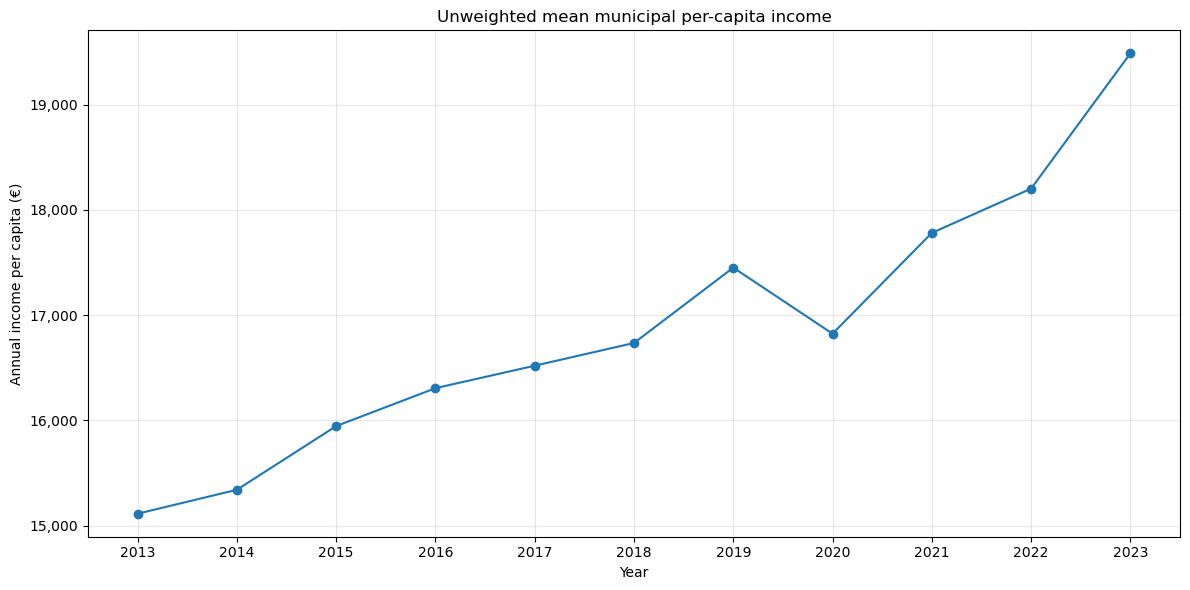

Cumulative change, 2013–2023: +4,371.98 €/person/year (+28.93%). The 2023 figure is provisional.


In [110]:
income_total_evolution = (
    income_analysis
    .groupby("year", as_index=False)
    .agg(
        unweighted_mean_municipal_income_eur=("income_per_capita_eur", "mean"),
        municipalities_with_data=("income_per_capita_eur", "count"),
    )
    .sort_values("year")
    .reset_index(drop=True)
)
income_total_evolution["annual_change_eur"] = (
    income_total_evolution["unweighted_mean_municipal_income_eur"].diff()
)
income_total_evolution["annual_growth_pct"] = (
    income_total_evolution["unweighted_mean_municipal_income_eur"].pct_change() * 100
)
income_total_evolution["change_since_2013_eur"] = (
    income_total_evolution["unweighted_mean_municipal_income_eur"]
    - income_total_evolution.loc[0, "unweighted_mean_municipal_income_eur"]
)
income_total_evolution["growth_since_2013_pct"] = (
    income_total_evolution["unweighted_mean_municipal_income_eur"]
    / income_total_evolution.loc[0, "unweighted_mean_municipal_income_eur"]
    - 1
) * 100

income_total_evolution_table = income_total_evolution[
    [
        "year",
        "unweighted_mean_municipal_income_eur",
        "annual_change_eur",
        "annual_growth_pct",
        "change_since_2013_eur",
        "growth_since_2013_pct",
        "municipalities_with_data",
    ]
]
display(
    income_total_evolution_table.style.format(
        {
            "year": "{:.0f}",
            "unweighted_mean_municipal_income_eur": "{:,.2f} €",
            "annual_change_eur": "{:+,.2f} €",
            "annual_growth_pct": "{:+.2f}%",
            "change_since_2013_eur": "{:+,.2f} €",
            "growth_since_2013_pct": "{:+.2f}%",
            "municipalities_with_data": "{:.0f}",
        },
        na_rep="—",
    ).set_caption("Unweighted mean municipal per-capita income in the analysis sample")
)

ax = income_total_evolution.plot(
    x="year",
    y="unweighted_mean_municipal_income_eur",
    kind="line",
    marker="o",
    figsize=(12, 6),
    legend=False,
)
ax.set_title("Unweighted mean municipal per-capita income")
ax.set_xlabel("Year")
ax.set_ylabel("Annual income per capita (€)")
ax.set_xticks(income_total_evolution["year"])
ax.grid(True, alpha=0.3)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
plt.tight_layout()
plt.show()

income_total_change_eur = (
    income_total_evolution.iloc[-1]["unweighted_mean_municipal_income_eur"]
    - income_total_evolution.iloc[0]["unweighted_mean_municipal_income_eur"]
)
income_total_growth_pct = income_total_evolution.iloc[-1]["growth_since_2013_pct"]
print(
    "Cumulative change, 2013–2023: "
    f"{income_total_change_eur:+,.2f} €/person/year "
    f"({income_total_growth_pct:+.2f}%). The 2023 figure is provisional."
)


### Barcelona vs. Other Sample Municipalities

The dataset reports annual per-capita income at the municipality level, not individual incomes. The analysis universe contains 47 municipalities with populations above 30,000. Barcelona is compared with the other 46 municipalities using an unweighted mean, median, and interquartile range; its percentile is calculated within this 47-municipality sample, not across all municipalities in Catalonia. Income data for 2023 are provisional.

,year,other_municipalities,barcelona_income_eur,rest_mean_eur,rest_median_eur,gap_vs_rest_mean_pct,gap_vs_rest_median_pct,income_percentile
0,2013,46,"19,474 €","15,020 €","15,104 €",+29.7%,+28.9%,97.9
1,2014,46,"19,691 €","15,247 €","15,316 €",+29.1%,+28.6%,97.9
2,2015,46,"20,556 €","15,846 €","15,850 €",+29.7%,+29.7%,97.9
3,2016,46,"21,132 €","16,202 €","16,064 €",+30.4%,+31.5%,95.7
4,2017,46,"21,371 €","16,415 €","16,245 €",+30.2%,+31.6%,95.7
5,2018,46,"21,538 €","16,631 €","16,532 €",+29.5%,+30.3%,95.7
6,2019,46,"22,483 €","17,342 €","17,092 €",+29.6%,+31.5%,93.6
7,2020,46,"21,121 €","16,730 €","16,528 €",+26.2%,+27.8%,95.7
8,2021,46,"22,136 €","17,687 €","17,642 €",+25.2%,+25.5%,97.9
9,2022,46,"23,003 €","18,097 €","17,872 €",+27.1%,+28.7%,95.7


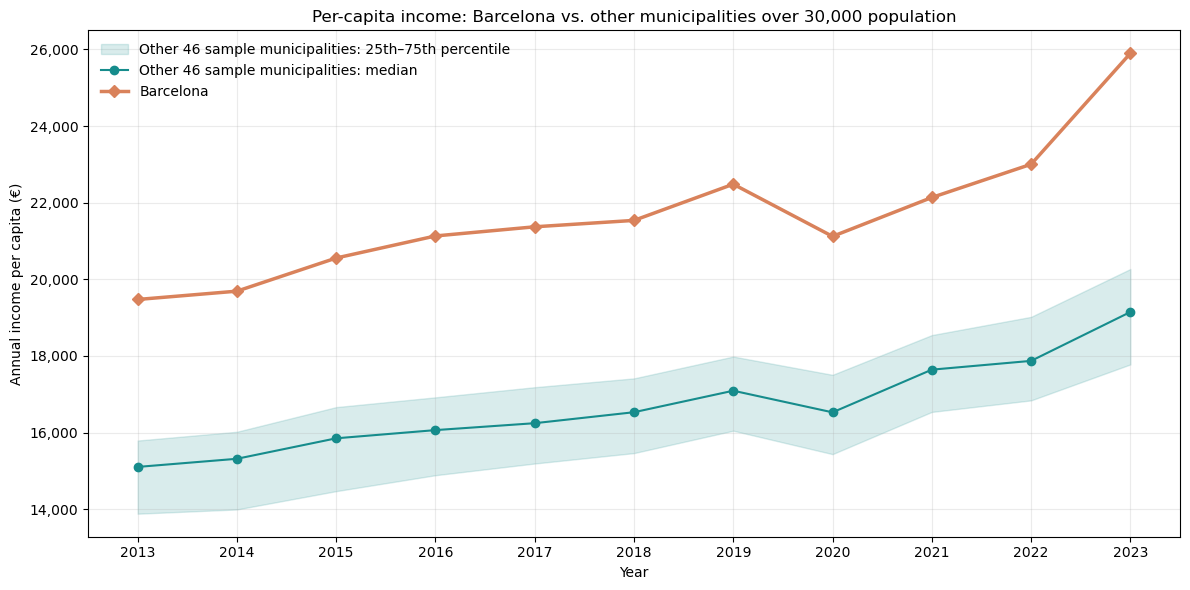

In 2023, Barcelona's per-capita income was 25,898 €, +33.9% vs. the mean of the other 46 municipalities in the >30,000 population sample, and at the 97.9th percentile within the 47-municipality sample. The 2023 figure is provisional.


In [111]:
barcelona_income_rows = income_analysis.loc[
    income_analysis["municipality"].str.casefold() == "barcelona",
    ["year", "income_per_capita_eur"],
].rename(columns={"income_per_capita_eur": "barcelona_income_eur"})

other_municipalities_income = income_analysis.loc[
    income_analysis["municipality"].str.casefold() != "barcelona"
].copy()

other_income_stats = (
    other_municipalities_income.groupby("year")["income_per_capita_eur"]
    .agg(
        other_municipalities="count",
        rest_mean_eur="mean",
        rest_median_eur="median",
        rest_q25_eur=lambda values: values.quantile(0.25),
        rest_q75_eur=lambda values: values.quantile(0.75),
    )
    .reset_index()
)

income_percentiles = income_analysis.assign(
    income_percentile=(
        income_analysis.groupby("year")["income_per_capita_eur"]
        .rank(method="average", pct=True)
        * 100
    )
)
barcelona_percentiles = income_percentiles.loc[
    income_percentiles["municipality"].str.casefold() == "barcelona",
    ["year", "income_percentile"],
]

income_barcelona_comparison = (
    other_income_stats
    .merge(barcelona_income_rows, on="year", validate="one_to_one")
    .merge(barcelona_percentiles, on="year", validate="one_to_one")
)
income_barcelona_comparison["gap_vs_rest_mean_eur"] = (
    income_barcelona_comparison["barcelona_income_eur"]
    - income_barcelona_comparison["rest_mean_eur"]
)
income_barcelona_comparison["gap_vs_rest_mean_pct"] = (
    income_barcelona_comparison["gap_vs_rest_mean_eur"]
    / income_barcelona_comparison["rest_mean_eur"]
    * 100
)
income_barcelona_comparison["gap_vs_rest_median_pct"] = (
    (
        income_barcelona_comparison["barcelona_income_eur"]
        / income_barcelona_comparison["rest_median_eur"]
        - 1
    )
    * 100
)

income_barcelona_comparison_table = income_barcelona_comparison[
    [
        "year",
        "other_municipalities",
        "barcelona_income_eur",
        "rest_mean_eur",
        "rest_median_eur",
        "gap_vs_rest_mean_pct",
        "gap_vs_rest_median_pct",
        "income_percentile",
    ]
]

display(
    income_barcelona_comparison_table.style.format(
        {
            "year": "{:.0f}",
            "other_municipalities": "{:.0f}",
            "barcelona_income_eur": "{:,.0f} €",
            "rest_mean_eur": "{:,.0f} €",
            "rest_median_eur": "{:,.0f} €",
            "gap_vs_rest_mean_pct": "{:+.1f}%",
            "gap_vs_rest_median_pct": "{:+.1f}%",
            "income_percentile": "{:.1f}",
        }
    ).set_caption(
        "Per-capita income: Barcelona vs. the other 46 municipalities "
        "in the >30,000 population sample"
    )
)

fig, ax = plt.subplots(figsize=(12, 6))
comparison_years = income_barcelona_comparison["year"].to_numpy()
ax.fill_between(
    comparison_years,
    income_barcelona_comparison["rest_q25_eur"].to_numpy(),
    income_barcelona_comparison["rest_q75_eur"].to_numpy(),
    color="#168C8C",
    alpha=0.16,
    label="Other 46 sample municipalities: 25th–75th percentile",
)
ax.plot(
    comparison_years,
    income_barcelona_comparison["rest_median_eur"],
    color="#168C8C",
    marker="o",
    label="Other 46 sample municipalities: median",
)
ax.plot(
    comparison_years,
    income_barcelona_comparison["barcelona_income_eur"],
    color="#D9825B",
    marker="D",
    linewidth=2.5,
    label="Barcelona",
)
ax.set_title("Per-capita income: Barcelona vs. other municipalities over 30,000 population")
ax.set_xlabel("Year")
ax.set_ylabel("Annual income per capita (€)")
ax.set_xticks(comparison_years)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
ax.grid(True, alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

latest_income_comparison = income_barcelona_comparison.iloc[-1]
print(
    f"In {int(latest_income_comparison['year'])}, Barcelona's per-capita income "
    f"was {latest_income_comparison['barcelona_income_eur']:,.0f} €, "
    f"{latest_income_comparison['gap_vs_rest_mean_pct']:+.1f}% vs. the mean "
    f"of the other 46 municipalities in the >30,000 population sample, "
    f"and at the {latest_income_comparison['income_percentile']:.1f}th "
    "percentile within the 47-municipality sample. The 2023 figure is provisional."
)


In [112]:
income_top10_2023 = (
    income_analysis[income_analysis["year"] == ANALYSIS_END_YEAR]
    .nlargest(10, "income_per_capita_eur")
    [["municipality", "income_per_capita_eur"]]
    .reset_index(drop=True)
)

display(income_top10_2023)


,municipality,income_per_capita_eur
0,Sant Cugat del Vallès,30434.0
1,Barcelona,25898.0
2,Sitges,24823.0
3,Sant Joan Despí,23030.0
4,Esplugues de Llobregat,22939.0
5,Cerdanyola del Vallès,22561.0
6,Sant Feliu de Llobregat,22381.0
7,Castelldefels,22337.0
8,Gavà,21866.0
9,Granollers,20642.0


In [113]:
income_bottom10_2023 = (
    income_analysis[income_analysis["year"] == ANALYSIS_END_YEAR]
    .nsmallest(10, "income_per_capita_eur")
    [["municipality", "income_per_capita_eur"]]
    .reset_index(drop=True)
)

display(income_bottom10_2023)


,municipality,income_per_capita_eur
0,Salt,13633.0
1,Lloret de Mar,14009.0
2,Figueres,15572.0
3,Salou,16118.0
4,Calafell,16248.0
5,Santa Coloma de Gramenet,16649.0
6,Blanes,16740.0
7,Pineda de Mar,16901.0
8,Tortosa,17275.0
9,Sant Adrià de Besòs,17283.0


In [114]:
income_growth = (
    income_analysis[income_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])]
    .pivot(
        index="municipality",
        columns="year",
        values="income_per_capita_eur"
    )
    .reset_index()
)

income_growth["income_change_eur"] = (
    income_growth[ANALYSIS_END_YEAR] - income_growth[ANALYSIS_START_YEAR]
)

income_growth["income_growth_pct"] = (
    (income_growth[ANALYSIS_END_YEAR] / income_growth[ANALYSIS_START_YEAR] - 1) * 100
)

income_growth = income_growth.sort_values(
    "income_growth_pct",
    ascending=False
).round(2)

display(income_growth)


year,municipality,2013,2023,income_change_eur,income_growth_pct
17,Lloret de Mar,9525.0,14009.0,4484.0,47.08
33,Sant Cugat del Vallès,20828.0,30434.0,9606.0,46.12
38,Sitges,16991.0,24823.0,7832.0,46.09
29,Salou,11479.0,16118.0,4639.0,40.41
46,Vilanova i la Geltrú,14895.0,20613.0,5718.0,38.39
19,Mataró,13840.0,18465.0,4625.0,33.42
13,Granollers,15491.0,20642.0,5151.0,33.25
2,Barcelona,19474.0,25898.0,6424.0,32.99
12,Girona,15607.0,20608.0,5001.0,32.04
40,Terrassa,15084.0,19895.0,4811.0,31.89


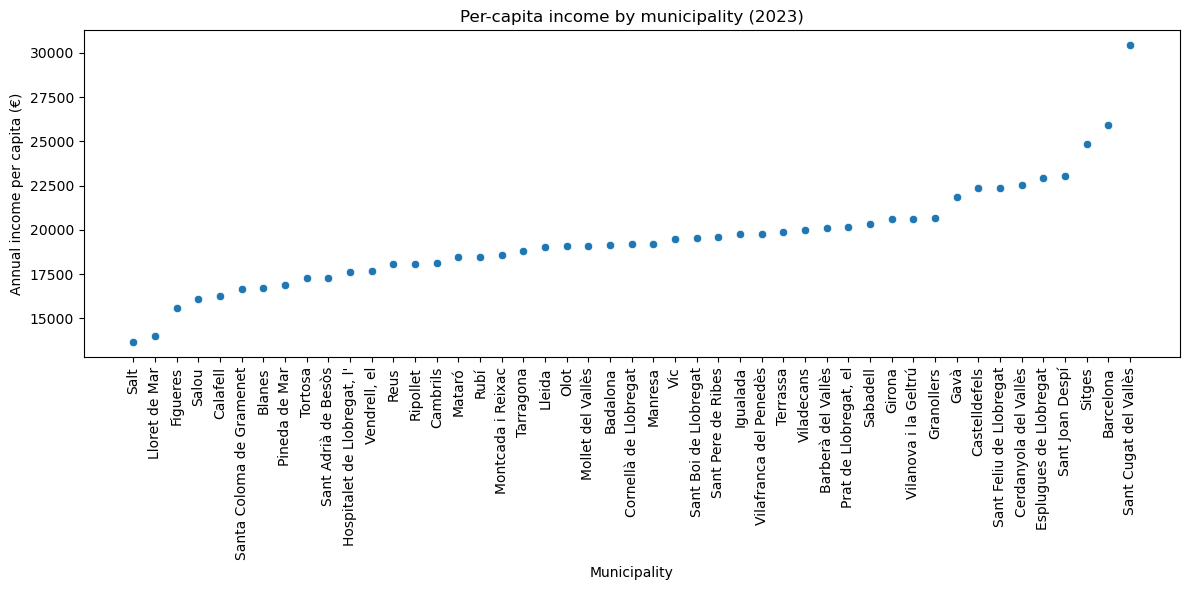

In [115]:
income_2023 = (
    income_analysis.loc[income_analysis["year"] == ANALYSIS_END_YEAR]
    .sort_values("income_per_capita_eur")
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(
    data=income_2023,
    x="municipality",
    y="income_per_capita_eur",
    ax=ax,
)
ax.tick_params(axis="x", labelrotation=90)
ax.set_title("Per-capita income by municipality (2023)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Annual income per capita (€)")
plt.tight_layout()
plt.show()


## Demographic Profile (2021–2025)

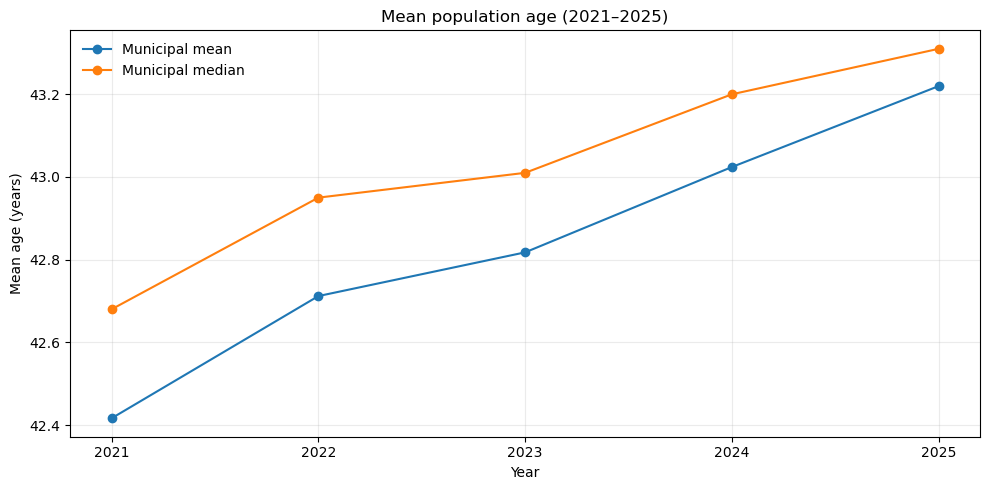

In [116]:
demographic_evolution = (
    demographic_analysis
    .groupby("year")["AGE_MEAN"]
    .agg(["mean", "median"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    demographic_evolution["year"],
    demographic_evolution["mean"],
    marker="o",
    label="Municipal mean",
)
ax.plot(
    demographic_evolution["year"],
    demographic_evolution["median"],
    marker="o",
    label="Municipal median",
)
ax.set_title("Mean population age (2021–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean age (years)")
ax.set_xticks(demographic_evolution["year"])
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


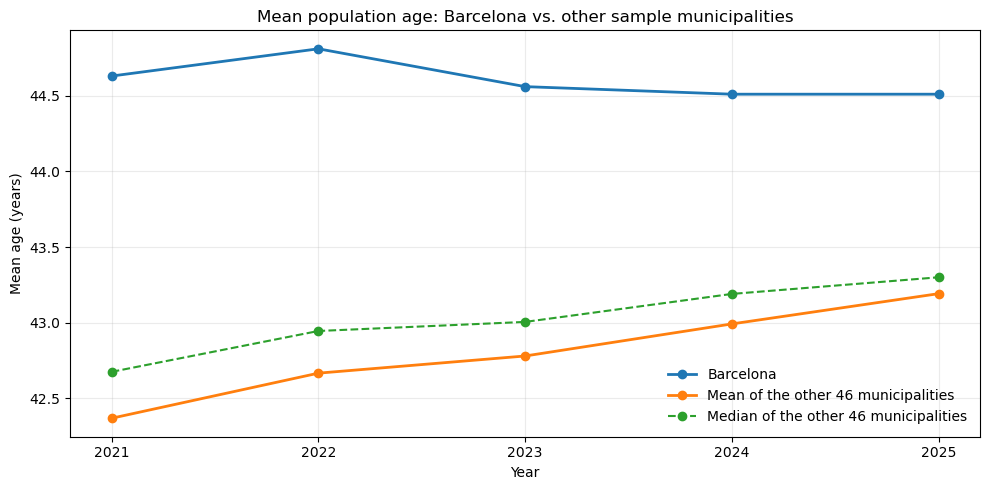

In [117]:
# Separate Barcelona from the other municipalities in the sample.
demographic_analysis["municipality"] = demographic_analysis["municipality"].str.strip()
barcelona_age = demographic_analysis.loc[
    demographic_analysis["municipality"].str.casefold() == "barcelona",
    ["year", "AGE_MEAN"],
].copy()
other_municipalities_age = demographic_analysis.loc[
    demographic_analysis["municipality"].str.casefold() != "barcelona"
]
other_age_evolution = (
    other_municipalities_age
    .groupby("year")["AGE_MEAN"]
    .agg(["mean", "median"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    barcelona_age["year"],
    barcelona_age["AGE_MEAN"],
    marker="o",
    linewidth=2,
    label="Barcelona",
)
ax.plot(
    other_age_evolution["year"],
    other_age_evolution["mean"],
    marker="o",
    linewidth=2,
    label="Mean of the other 46 municipalities",
)
ax.plot(
    other_age_evolution["year"],
    other_age_evolution["median"],
    marker="o",
    linestyle="--",
    label="Median of the other 46 municipalities",
)
ax.set_title("Mean population age: Barcelona vs. other sample municipalities")
ax.set_xlabel("Year")
ax.set_ylabel("Mean age (years)")
ax.set_xticks(sorted(demographic_analysis["year"].unique()))
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


In [118]:
demographic_2025 = demographic_analysis.loc[
    demographic_analysis["year"] == 2025
].copy()

youngest_5 = (
    demographic_2025
    .nsmallest(5, "AGE_MEAN")
    [["municipality", "AGE_MEAN"]]
    .reset_index(drop=True)
)
oldest_5 = (
    demographic_2025
    .nlargest(5, "AGE_MEAN")
    [["municipality", "AGE_MEAN"]]
    .reset_index(drop=True)
)

print("Five municipalities with the lowest mean age:")
display(youngest_5.round(2))
print("Five municipalities with the highest mean age:")
display(oldest_5.round(2))


Five municipalities with the lowest mean age:


,municipality,AGE_MEAN
0,Salt,38.09
1,Figueres,40.82
2,Sant Cugat del Vallès,40.86
3,Vic,41.06
4,Girona,41.52


Five municipalities with the highest mean age:


,municipality,AGE_MEAN
0,Pineda de Mar,45.43
1,Esplugues de Llobregat,45.42
2,Sitges,45.21
3,Cerdanyola del Vallès,44.97
4,Vilanova i la Geltrú,44.93


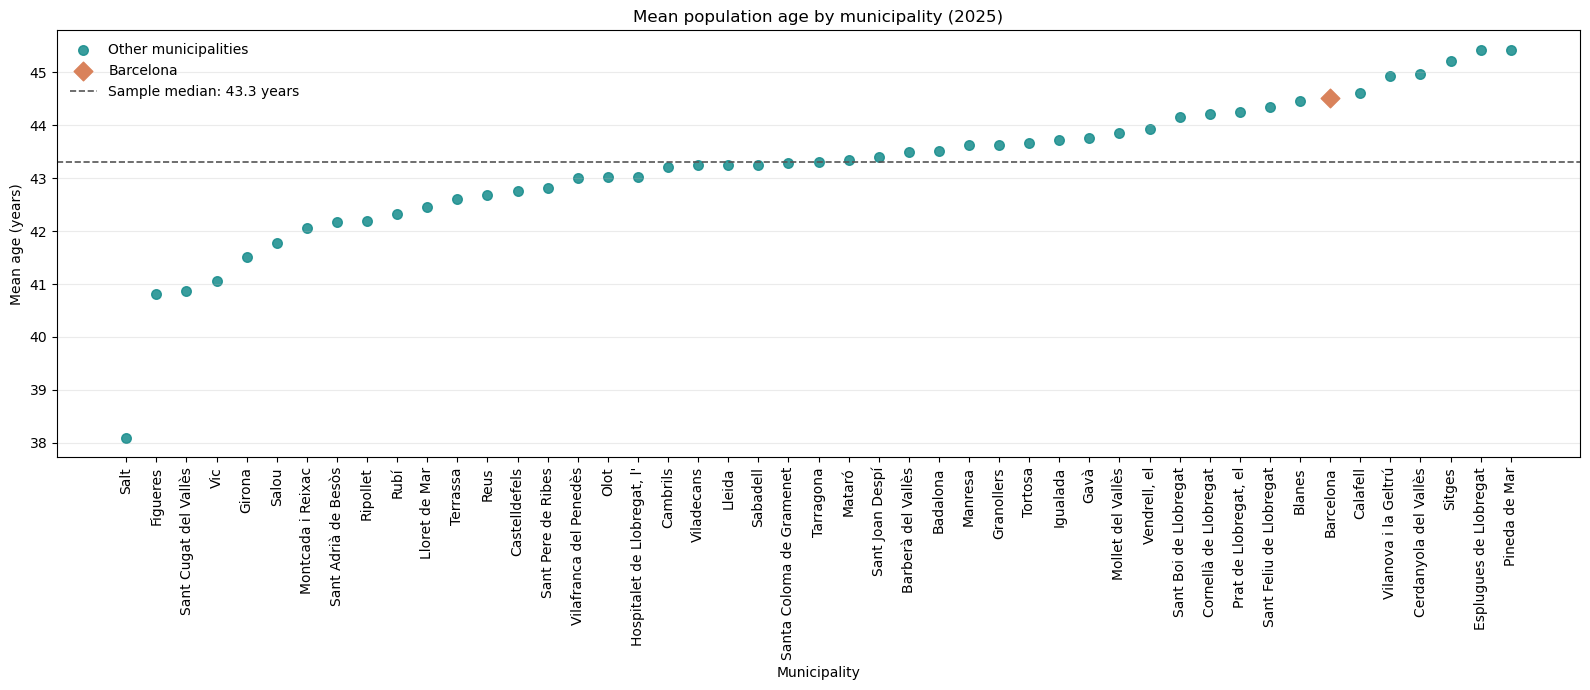

In [119]:
demographic_age_2025 = (
    demographic_analysis.loc[demographic_analysis["year"] == 2025]
    .sort_values("AGE_MEAN")
    .reset_index(drop=True)
)
positions = np.arange(len(demographic_age_2025))
barcelona_mask = demographic_age_2025["municipality"].str.casefold().eq("barcelona")
median_age = demographic_age_2025["AGE_MEAN"].median()

fig, ax = plt.subplots(figsize=(16, 7))
ax.scatter(
    positions[~barcelona_mask.to_numpy()],
    demographic_age_2025.loc[~barcelona_mask, "AGE_MEAN"],
    color="#168C8C",
    s=48,
    alpha=0.85,
    label="Other municipalities",
)
ax.scatter(
    positions[barcelona_mask.to_numpy()],
    demographic_age_2025.loc[barcelona_mask, "AGE_MEAN"],
    color="#D9825B",
    marker="D",
    s=90,
    zorder=3,
    label="Barcelona",
)
ax.axhline(
    median_age,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Sample median: {median_age:.1f} years",
)
ax.set_xticks(positions)
ax.set_xticklabels(demographic_age_2025["municipality"], rotation=90)
ax.set_title("Mean population age by municipality (2025)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Mean age (years)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


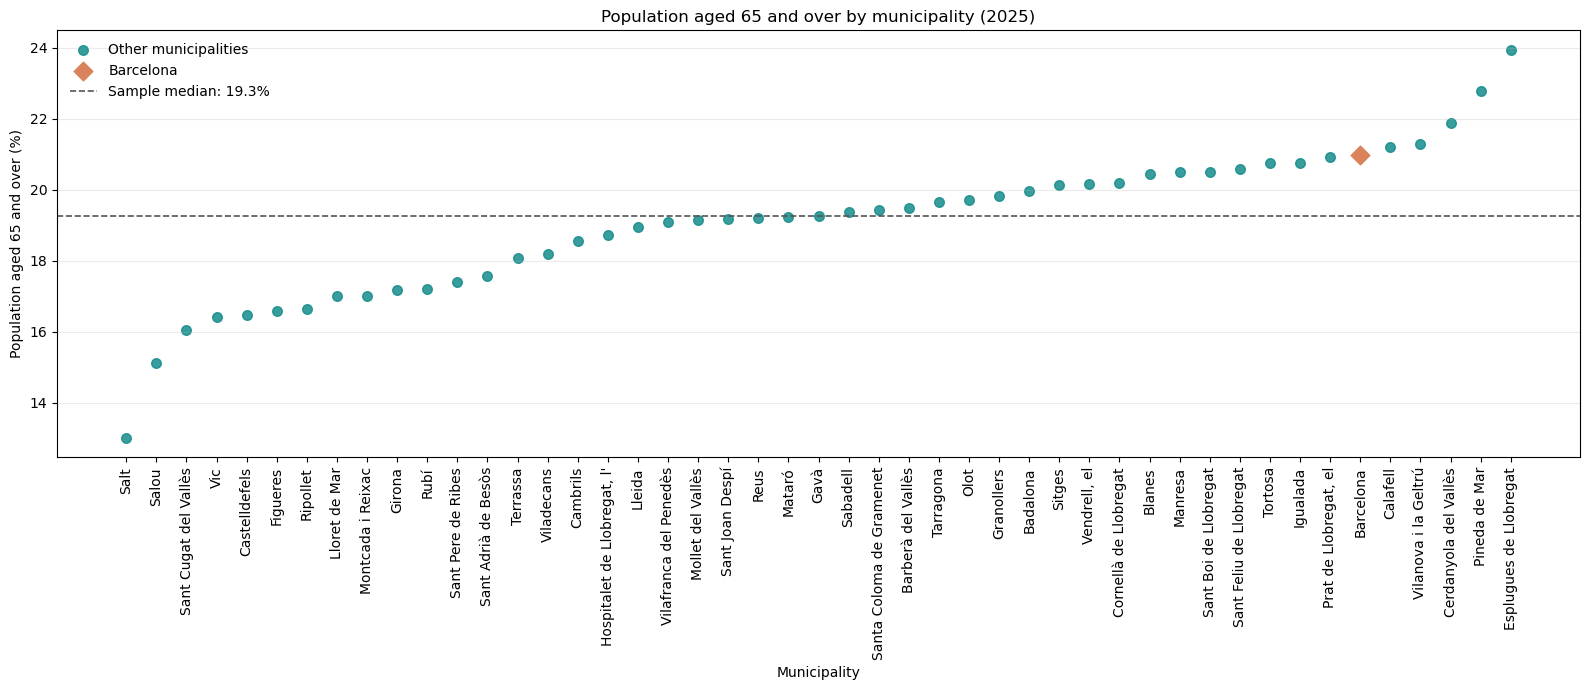

In [120]:
demographic_2025 = (
    demographic_analysis.loc[demographic_analysis["year"] == 2025]
    .sort_values("PP_Y_GE65")
    .reset_index(drop=True)
)
assert demographic_2025["municipality_code"].nunique() == 47

positions = np.arange(len(demographic_2025))
barcelona_mask = demographic_2025["municipality"].str.casefold().eq("barcelona")
median_age65 = demographic_2025["PP_Y_GE65"].median()

fig, ax = plt.subplots(figsize=(16, 7))
ax.scatter(
    positions[~barcelona_mask.to_numpy()],
    demographic_2025.loc[~barcelona_mask, "PP_Y_GE65"],
    color="#168C8C",
    s=48,
    alpha=0.85,
    label="Other municipalities",
)
ax.scatter(
    positions[barcelona_mask.to_numpy()],
    demographic_2025.loc[barcelona_mask, "PP_Y_GE65"],
    color="#D9825B",
    marker="D",
    s=90,
    zorder=3,
    label="Barcelona",
)
ax.axhline(
    median_age65,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Sample median: {median_age65:.1f}%",
)
ax.set_xticks(positions)
ax.set_xticklabels(demographic_2025["municipality"], rotation=90)
ax.set_title("Population aged 65 and over by municipality (2025)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Population aged 65 and over (%)")
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


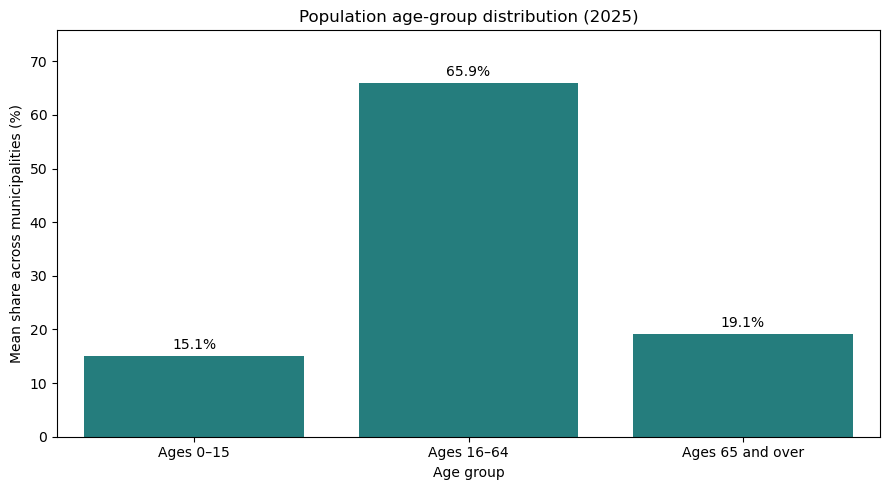

In [121]:
age_distribution_2025 = (
    demographic_analysis.loc[
        demographic_analysis["year"] == 2025,
        ["PP_Y00_15", "OPP_Y16_64", "PP_Y_GE65"],
    ]
    .mean()
    .rename(
        {
            "PP_Y00_15": "Ages 0–15",
            "OPP_Y16_64": "Ages 16–64",
            "PP_Y_GE65": "Ages 65 and over",
        }
    )
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=age_distribution_2025.index, y=age_distribution_2025.values, color="#168C8C")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Population age-group distribution (2025)")
plt.xlabel("Age group")
plt.ylabel("Mean share across municipalities (%)")
plt.ylim(0, age_distribution_2025.max() * 1.15)
plt.tight_layout()
plt.show()


### Population ageing | Explore how the share of residents aged 65 and over changes across the sample.

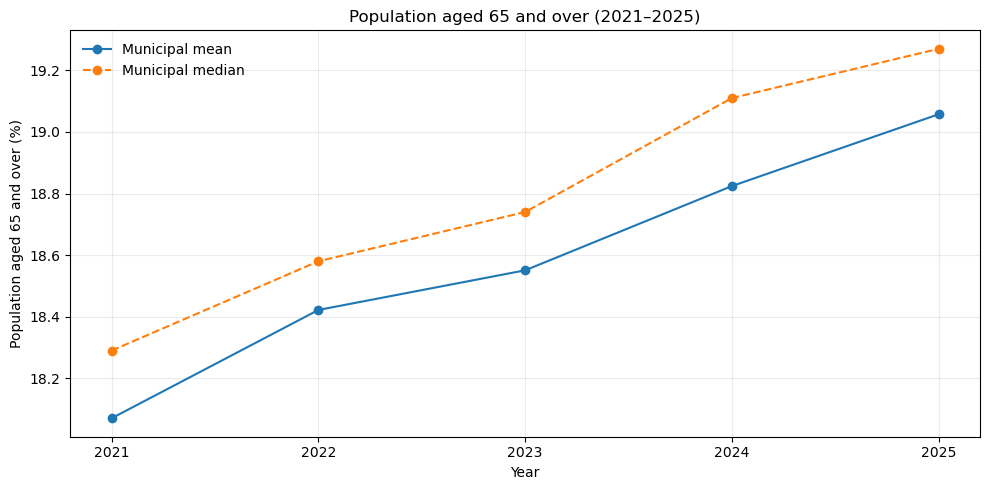

In [122]:
aging_evolution = (
    demographic_analysis
    .groupby("year")["PP_Y_GE65"]
    .agg(["mean", "median"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    aging_evolution["year"],
    aging_evolution["mean"],
    marker="o",
    label="Municipal mean",
)
ax.plot(
    aging_evolution["year"],
    aging_evolution["median"],
    marker="o",
    linestyle="--",
    label="Municipal median",
)
ax.set_title("Population aged 65 and over (2021–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Population aged 65 and over (%)")
ax.set_xticks(aging_evolution["year"])
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## Economic Activity (2021–2025)

In [123]:
activity_analysis["unemployment_rate"] = (
    activity_analysis["PO_UNE"]
    / activity_analysis["PO_ACTT"]
    * 100
)

activity_analysis["employment_rate_active"] = (
    activity_analysis["PO_EMP"]
    / activity_analysis["PO_ACTT"]
    * 100
)

display(
    activity_analysis[
        ["municipality", "year", "PO_EMP", "PO_UNE",
         "PO_ACTT", "unemployment_rate", "employment_rate_active"]
    ].head(10).round(2)
)


,municipality,year,PO_EMP,PO_UNE,PO_ACTT,unemployment_rate,employment_rate_active
0,Badalona,2021,88146.0,15586.0,103732.0,15.03,84.97
1,Badalona,2022,91796.0,12476.0,104272.0,11.96,88.04
2,Badalona,2023,94130.0,11585.0,105715.0,10.96,89.04
3,Badalona,2024,96077.0,11486.0,107563.0,10.68,89.32
4,Badalona,2025,88146.0,15586.0,103732.0,15.03,84.97
5,Barberà del Vallès,2021,14535.0,1918.0,16453.0,11.66,88.34
6,Barberà del Vallès,2022,15027.0,1516.0,16543.0,9.16,90.84
7,Barberà del Vallès,2023,15296.0,1418.0,16714.0,8.48,91.52
8,Barberà del Vallès,2024,15576.0,1408.0,16984.0,8.29,91.71
9,Barberà del Vallès,2025,14535.0,1918.0,16453.0,11.66,88.34


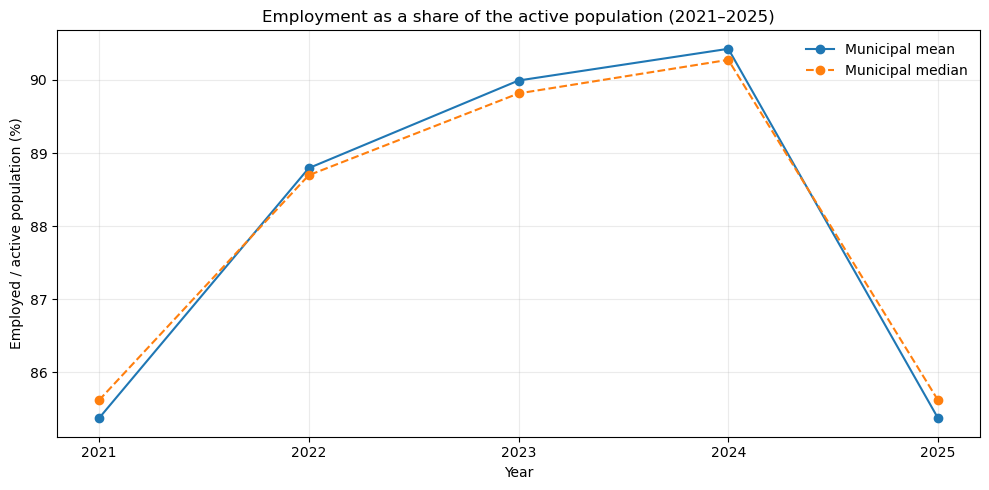

In [124]:
employment_rate_evolution = (
    activity_analysis
    .groupby("year")["employment_rate_active"]
    .agg(["mean", "median"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    employment_rate_evolution["year"],
    employment_rate_evolution["mean"],
    marker="o",
    label="Municipal mean",
)
ax.plot(
    employment_rate_evolution["year"],
    employment_rate_evolution["median"],
    marker="o",
    linestyle="--",
    label="Municipal median",
)
ax.set_title("Employment as a share of the active population (2021–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Employed / active population (%)")
ax.set_xticks(employment_rate_evolution["year"])
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


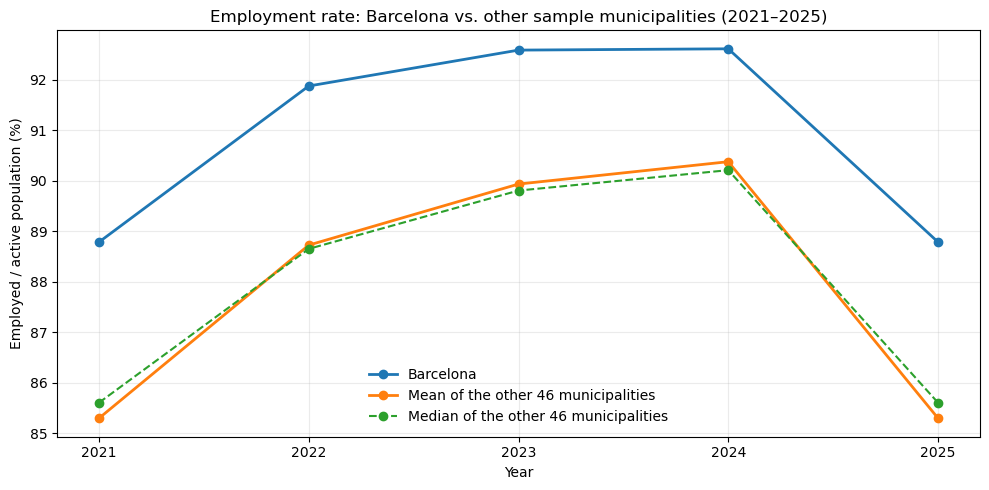

In [125]:
barcelona_employment = activity_analysis.loc[
    activity_analysis["municipality"].str.casefold() == "barcelona",
    ["year", "employment_rate_active"],
].copy()
other_municipalities_employment = activity_analysis.loc[
    activity_analysis["municipality"].str.casefold() != "barcelona"
]
other_employment_evolution = (
    other_municipalities_employment
    .groupby("year")["employment_rate_active"]
    .agg(["mean", "median"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    barcelona_employment["year"],
    barcelona_employment["employment_rate_active"],
    marker="o",
    linewidth=2,
    label="Barcelona",
)
ax.plot(
    other_employment_evolution["year"],
    other_employment_evolution["mean"],
    marker="o",
    linewidth=2,
    label="Mean of the other 46 municipalities",
)
ax.plot(
    other_employment_evolution["year"],
    other_employment_evolution["median"],
    marker="o",
    linestyle="--",
    label="Median of the other 46 municipalities",
)
ax.set_title("Employment rate: Barcelona vs. other sample municipalities (2021–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Employed / active population (%)")
ax.set_xticks(sorted(activity_analysis["year"].unique()))
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


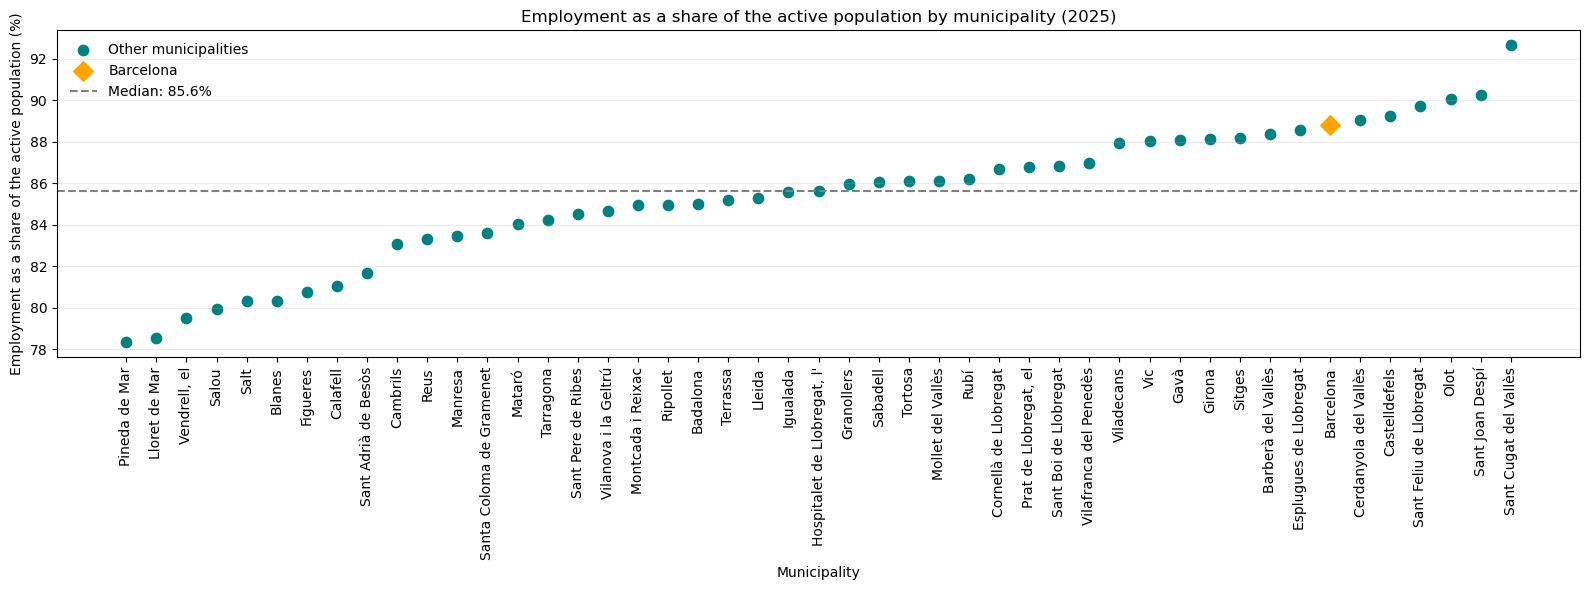

In [126]:
# Filter 2025 data and sort municipalities by employment rate
employment_2025 = (
    activity_analysis[activity_analysis["year"] == 2025]
    .sort_values("employment_rate_active")
    .reset_index(drop=True)
)

# Confirm that all 47 municipalities are included
assert employment_2025["municipality_code"].nunique() == 47

# X-axis positions
positions = range(len(employment_2025))

# Identify Barcelona
barcelona_mask = (
    employment_2025["municipality"].str.casefold() == "barcelona"
)

# Calculate the median
median_employment = employment_2025["employment_rate_active"].median()

# Create the plot
fig, ax = plt.subplots(figsize=(16, 6))

ax.scatter(
    [p for p, is_barcelona in zip(positions, barcelona_mask) if not is_barcelona],
    employment_2025.loc[~barcelona_mask, "employment_rate_active"],
    color="teal",
    s=55,
    label="Other municipalities"
)

ax.scatter(
    [p for p, is_barcelona in zip(positions, barcelona_mask) if is_barcelona],
    employment_2025.loc[barcelona_mask, "employment_rate_active"],
    color="orange",
    marker="D",
    s=100,
    label="Barcelona",
    zorder=3
)

ax.axhline(
    median_employment,
    color="gray",
    linestyle="--",
    label=f"Median: {median_employment:.1f}%"
)

ax.set_title("Employment as a share of the active population by municipality (2025)")
ax.set_xlabel("Municipality")
ax.set_ylabel("Employment as a share of the active population (%)")
ax.set_xticks(list(positions))
ax.set_xticklabels(employment_2025["municipality"], rotation=90)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


Further analysis could assess employment conditions alongside distance to the main urban centres.

In [127]:
activity_2025 = activity_analysis.loc[activity_analysis["year"] == 2025].copy()

top5_unemployment = (
    activity_2025
    .nlargest(5, "unemployment_rate")
    [["municipality", "PO_UNE", "PO_ACTT", "unemployment_rate"]]
    .reset_index(drop=True)
)
bottom5_unemployment = (
    activity_2025
    .nsmallest(5, "unemployment_rate")
    [["municipality", "PO_UNE", "PO_ACTT", "unemployment_rate"]]
    .reset_index(drop=True)
)

print("Five municipalities with the highest unemployment rate (2025):")
display(top5_unemployment.round(2))
print("Five municipalities with the lowest unemployment rate (2025):")
display(bottom5_unemployment.round(2))


Five municipalities with the highest unemployment rate (2025):


,municipality,PO_UNE,PO_ACTT,unemployment_rate
0,Pineda de Mar,2649.0,12218.0,21.68
1,Lloret de Mar,2977.0,13866.0,21.47
2,"Vendrell, el",3625.0,17691.0,20.49
3,Salou,2309.0,11503.0,20.07
4,Salt,2827.0,14370.0,19.67


Five municipalities with the lowest unemployment rate (2025):


,municipality,PO_UNE,PO_ACTT,unemployment_rate
0,Sant Cugat del Vallès,3359.0,45663.0,7.36
1,Sant Joan Despí,1667.0,17060.0,9.77
2,Olot,1736.0,17443.0,9.95
3,Sant Feliu de Llobregat,2295.0,22314.0,10.29
4,Castelldefels,3495.0,32462.0,10.77


## Mortgages (Catalonia-wide data)

In [128]:
mortgages_analysis = (
    mortgages_by_year.loc[mortgages_by_year["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)]
    .copy()
    .reset_index(drop=True)
)

print(
    "Coverage period:",
    mortgages_analysis["year"].min(),
    "to",
    mortgages_analysis["year"].max(),
)
print("Number of annual records:", len(mortgages_analysis))
display(mortgages_analysis)


Coverage period: 2013 to 2023
Number of annual records: 11


,year,mortgages_thousands,provisional,capital_billion_eur,mortgages_estimated
0,2013,45.2,False,5.9,45200
1,2014,43.6,False,6.2,43600
2,2015,54.3,False,8.1,54300
3,2016,60.2,False,9.6,60200
4,2017,67.0,False,10.8,67000
5,2018,75.3,False,12.5,75300
6,2019,75.0,False,13.3,75000
7,2020,71.9,False,14.0,71900
8,2021,88.7,False,16.0,88700
9,2022,101.2,False,19.3,101200


In [129]:
mortgages_analysis = mortgages_analysis.copy()
mortgages_analysis["average_mortgage_eur"] = (
    mortgages_analysis["capital_billion_eur"]
    * 1_000_000_000
    / mortgages_analysis["mortgages_estimated"]
)

mortgage_stats = mortgages_analysis[
    [
        "mortgages_estimated",
        "capital_billion_eur",
        "average_mortgage_eur",
    ]
].describe().T

display(mortgage_stats.round(2))


,count,mean,std,min,25%,50%,75%,max
mortgages_estimated,11.0,69518.18,17866.44,43600.00,57250.00,71900.00,78800.00,101200.00
capital_billion_eur,11.0,11.93,4.25,5.90,8.85,12.50,14.75,19.30
average_mortgage_eur,11.0,167277.05,21035.26,130530.97,154319.85,166002.66,184359.34,194714.88


In [130]:
mortgages_analysis["average_mortgage_eur"] = mortgages_analysis["average_mortgage_eur"].round(2)

display(
    mortgages_analysis[
        ["year", "mortgages_estimated", "capital_billion_eur", "average_mortgage_eur"]
    ]
)


,year,mortgages_estimated,capital_billion_eur,average_mortgage_eur
0,2013,45200,5.9,130530.97
1,2014,43600,6.2,142201.83
2,2015,54300,8.1,149171.27
3,2016,60200,9.6,159468.44
4,2017,67000,10.8,161194.03
5,2018,75300,12.5,166002.66
6,2019,75000,13.3,177333.33
7,2020,71900,14.0,194714.88
8,2021,88700,16.0,180383.31
9,2022,101200,19.3,190711.46


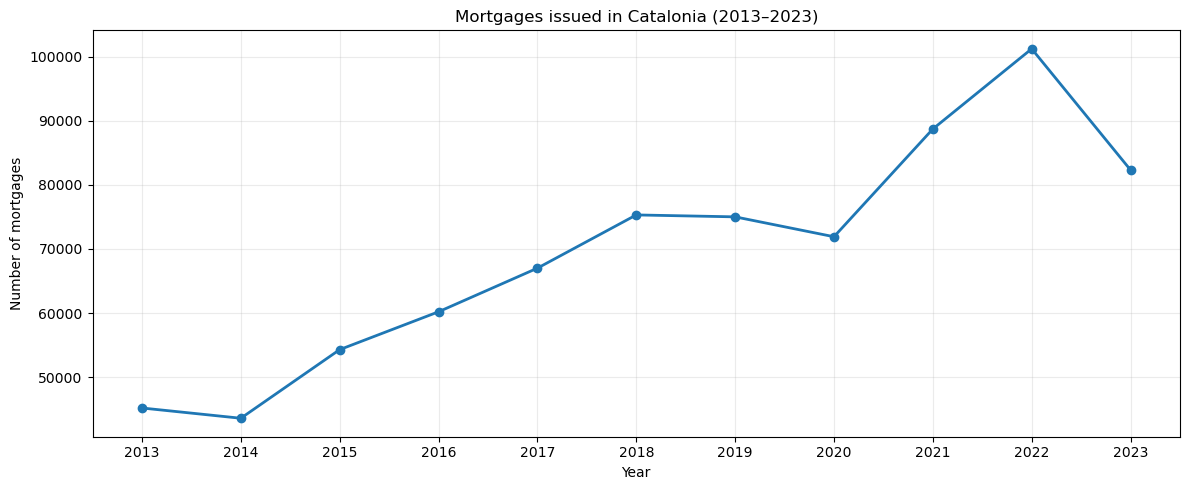

In [131]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    mortgages_analysis["year"],
    mortgages_analysis["mortgages_estimated"],
    marker="o",
    linewidth=2,
)
ax.set_title("Mortgages issued in Catalonia (2013–2023)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of mortgages")
ax.set_xticks(mortgages_analysis["year"])
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


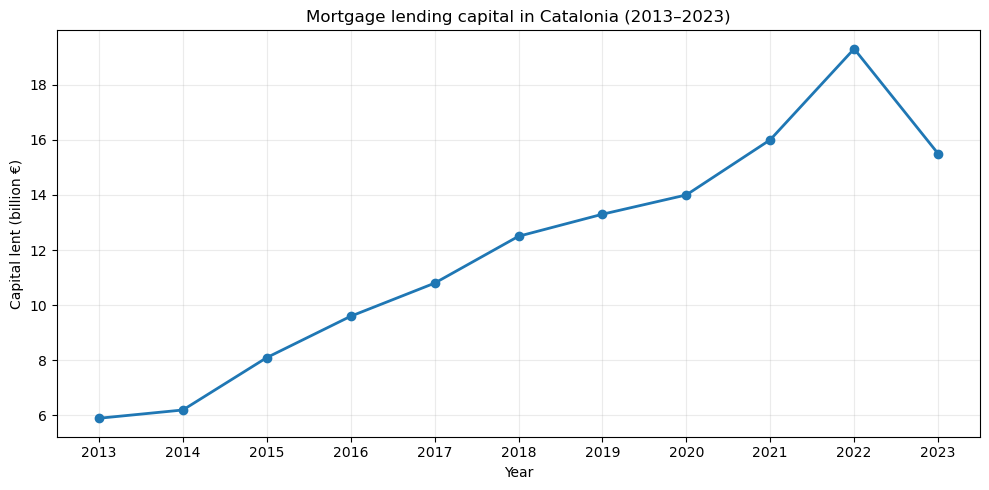

In [132]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    mortgages_analysis["year"],
    mortgages_analysis["capital_billion_eur"],
    marker="o",
    linewidth=2,
)
ax.set_title("Mortgage lending capital in Catalonia (2013–2023)")
ax.set_xlabel("Year")
ax.set_ylabel("Capital lent (billion €)")
ax.set_xticks(mortgages_analysis["year"])
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


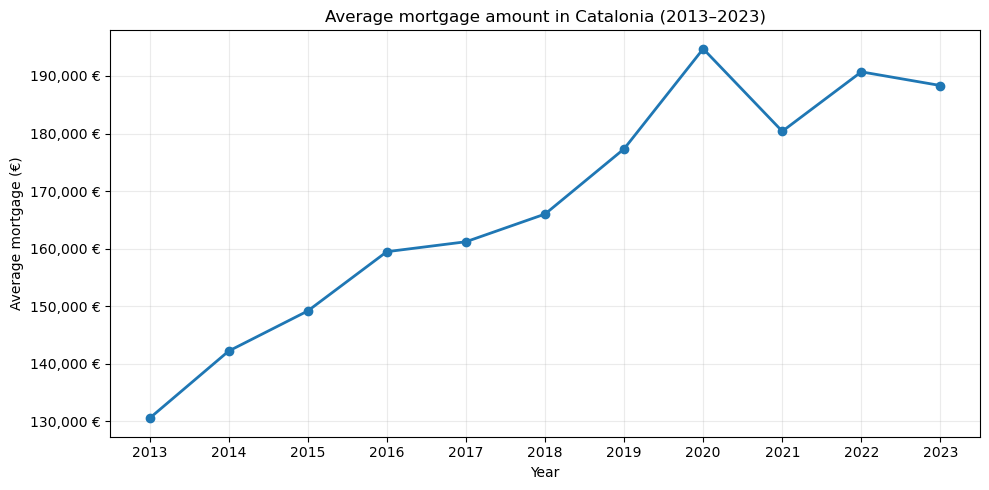

In [133]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    mortgages_analysis["year"],
    mortgages_analysis["average_mortgage_eur"],
    marker="o",
    linewidth=2,
)
ax.set_title("Average mortgage amount in Catalonia (2013–2023)")
ax.set_xlabel("Year")
ax.set_ylabel("Average mortgage (€)")
ax.set_xticks(mortgages_analysis["year"])
ax.grid(alpha=0.25)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f} €")
)
plt.tight_layout()
plt.show()


## Geographic Distance

Road distance from each municipality to the four reference cities (Barcelona, Girona, Tarragona, and Lleida). Distances are based on the selected OSRM routes and geocoded municipality coordinates.

In [134]:
distance_columns = {
    "Barcelona": "distance_to_barcelona_km",
    "Girona": "distance_to_girona_km",
    "Tarragona": "distance_to_tarragona_km",
    "Lleida": "distance_to_lleida_km",
}

distance_analysis_eda = distance_analysis.copy()
distance_analysis_eda["nearest_city"] = (
    distance_analysis_eda[list(distance_columns.values())]
    .idxmin(axis=1)
    .map({column: city for city, column in distance_columns.items()})
)
distance_analysis_eda["nearest_city_distance_km"] = (
    distance_analysis_eda[list(distance_columns.values())].min(axis=1)
)

distance_analysis_eda[
    ["municipality", "nearest_city", "nearest_city_distance_km"]
].sort_values("nearest_city_distance_km").head(10)


,municipality,nearest_city,nearest_city_distance_km
1,Barcelona,Barcelona,0.0000
43,Tarragona,Tarragona,0.0000
39,Lleida,Lleida,0.0000
35,Girona,Girona,0.0000
38,Salt,Girona,3.0547
18,Sant Adrià de Besòs,Barcelona,8.2061
4,Esplugues de Llobregat,Barcelona,9.7772
24,Santa Coloma de Gramenet,Barcelona,11.2034
46,Salou,Tarragona,11.4730
7,"Hospitalet de Llobregat, l'",Barcelona,11.5371


In [135]:
distance_metric_columns = [
    "distance_to_barcelona_km",
    "distance_to_girona_km",
    "distance_to_tarragona_km",
    "distance_to_lleida_km",
]

distance_stats = distance_analysis[distance_metric_columns].describe().T.rename(
    columns={
        "count": "municipalities",
        "mean": "mean_km",
        "std": "std_km",
        "min": "min_km",
        "25%": "q1_km",
        "50%": "median_km",
        "75%": "q3_km",
        "max": "max_km",
    }
)
distance_stats.round(2)


,municipalities,mean_km,std_km,min_km,q1_km,median_km,q3_km,max_km
distance_to_barcelona_km,47.0,51.60,43.60,0.0,18.99,34.29,71.50,179.41
distance_to_girona_km,47.0,111.41,54.39,0.0,89.15,105.01,137.24,271.23
distance_to_tarragona_km,47.0,98.37,49.10,0.0,79.27,96.36,109.41,225.89
distance_to_lleida_km,47.0,149.69,41.64,0.0,134.65,149.16,161.12,238.49


In [136]:
distance_analysis_eda["nearest_distance_km"] = (
    distance_analysis_eda[distance_metric_columns].min(axis=1)
)
distance_analysis_eda["farthest_distance_km"] = (
    distance_analysis_eda[distance_metric_columns].max(axis=1)
)

distance_analysis_eda[
    ["municipality", "nearest_distance_km", "farthest_distance_km"]
].sort_values("nearest_distance_km", ascending=False).head(10)


,municipality,nearest_distance_km,farthest_distance_km
44,Tortosa,88.2287,271.2277
29,Vic,71.3093,157.4844
8,Igualada,68.1386,143.1740
9,Manresa,64.9334,118.0991
37,Olot,56.2307,194.8136
31,Vilafranca del Penedès,52.4259,135.9227
32,Vilanova i la Geltrú,47.7220,144.7954
13,Pineda de Mar,45.7489,204.9112
23,Sant Pere de Ribes,42.7200,139.7935
34,Figueres,42.3432,238.4906


# Multivariable Analisys

## Crate a Data frame

In [137]:
# Municipality codes were standardized in the first notebook.
# Use municipality_code directly; do not create or transform a secondary key.

print(
    "Duplicate sales municipality-year keys:",
    sales_analysis.duplicated(subset=["municipality_code", "year"]).sum()
)
print(
    "Duplicate population municipality-year keys:",
    population_analysis.duplicated(subset=["municipality_code", "year"]).sum()
)

sales_codes = set(sales_analysis["municipality_code"].dropna())
population_codes = set(population_analysis["municipality_code"].dropna())
matching_codes = sales_codes & population_codes

print("Matching municipality codes:", len(matching_codes))
assert sales_codes == population_codes, (
    "Sales and population datasets do not contain the same municipality codes."
)


Duplicate sales municipality-year keys: 0
Duplicate population municipality-year keys: 0
Matching municipality codes: 47


In [138]:

# Create the analytical dataset from the original DataFrames
housing_analysis = sales_analysis.merge(
    population_analysis[
        ["municipality", "year", "population"]
    ],
    on=["municipality", "year"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Validate the merge
print("Shape:", housing_analysis.shape)

print("\nMerge results:")
print(housing_analysis["_merge"].value_counts())

print(
    "\nDuplicate municipality-year keys:",
    housing_analysis.duplicated(
        subset=["municipality", "year"]
    ).sum()
)

print(
    "\nMissing population values:",
    housing_analysis["population"].isna().sum()
)

# Remove the temporary validation column
housing_analysis.drop(columns="_merge", inplace=True)


Shape: (517, 20)

Merge results:
_merge
both          517
left_only       0
right_only      0
Name: count, dtype: int64

Duplicate municipality-year keys: 0

Missing population values: 0


In [139]:

# Select rental variables to integrate
rent_to_merge = rent_analysis[
    ["municipality", "year", "comarca", "rent_mean", "rent_growth_pct"]
].copy()

# Merge rental data into the analytical dataset
housing_analysis = housing_analysis.merge(
    rent_to_merge,
    on=["municipality", "year"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Validate the integration
print("Shape:", housing_analysis.shape)

print("\nMerge results:")
print(housing_analysis["_merge"].value_counts())

print(
    "\nDuplicate municipality-year keys:",
    housing_analysis.duplicated(
        subset=["municipality", "year"]
    ).sum()
)

print("\nMissing values in rental variables:")
print(housing_analysis[["rent_mean", "rent_growth_pct"]].isna().sum())

# Remove temporary validation column
housing_analysis.drop(columns="_merge", inplace=True)


Shape: (517, 23)

Merge results:
_merge
both          517
left_only       0
right_only      0
Name: count, dtype: int64

Duplicate municipality-year keys: 0

Missing values in rental variables:
rent_mean           0
rent_growth_pct    47
dtype: int64


In [140]:

# Select the income variables needed for the analysis
income_to_merge = income_analysis[
    [
        "municipality",
        "year",
        "income_thousand_eur",
        "income_per_capita_eur",
        "income_index_catalonia"
    ]
].copy()

# Merge income data into the analytical dataset
housing_analysis = housing_analysis.merge(
    income_to_merge,
    on=["municipality", "year"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Validate the integration
print("Shape:", housing_analysis.shape)

print("\nMerge results:")
print(housing_analysis["_merge"].value_counts())

print(
    "\nDuplicate municipality-year keys:",
    housing_analysis.duplicated(
        subset=["municipality", "year"]
    ).sum()
)

print("\nMissing income values:")
print(
    housing_analysis[
        [
            "income_thousand_eur",
            "income_per_capita_eur",
            "income_index_catalonia"
        ]
    ].isna().sum()
)

print("\nIncome coverage by year:")
print(
    housing_analysis.groupby("year")["income_per_capita_eur"]
    .apply(lambda s: s.notna().sum())
)

# Remove the temporary validation column
housing_analysis.drop(columns="_merge", inplace=True)


Shape: (517, 26)

Merge results:
_merge
both          517
left_only       0
right_only      0
Name: count, dtype: int64

Duplicate municipality-year keys: 0

Missing income values:
income_thousand_eur       0
income_per_capita_eur     0
income_index_catalonia    0
dtype: int64

Income coverage by year:
year
2013    47
2014    47
2015    47
2016    47
2017    47
2018    47
2019    47
2020    47
2021    47
2022    47
2023    47
Name: income_per_capita_eur, dtype: int64


In [141]:

# Review the current analytical dataset

print("Shape:", housing_analysis.shape)

print("\nColumns:")
print(housing_analysis.columns.tolist())

print("\nData types:")
print(housing_analysis.dtypes)

print("\nDuplicate municipality-year keys:")
print(
    housing_analysis.duplicated(
        subset=["municipality", "year"]
    ).sum()
)


Shape: (517, 25)

Columns:
['municipality_code', 'sales_new_free', 'sales_new_protected', 'sales_used', 'sales_total', 'surface_new_free', 'surface_new_protected', 'surface_used', 'surface_total', 'price_new', 'price_used', 'price_total_k_eur', 'price_m2_new', 'price_m2_used', 'price_m2_total', 'municipality_code_source', 'year', 'municipality', 'population', 'comarca', 'rent_mean', 'rent_growth_pct', 'income_thousand_eur', 'income_per_capita_eur', 'income_index_catalonia']

Data types:
municipality_code           string[python]
sales_new_free                       int64
sales_new_protected                  int64
sales_used                           int64
sales_total                          int64
surface_new_free                   float64
surface_new_protected              float64
surface_used                       float64
surface_total                      float64
price_new                          float64
price_used                         float64
price_total_k_eur                  

In [142]:

# Final data quality check
print("Duplicate municipality-year keys:",
      housing_analysis.duplicated(
          subset=["municipality", "year"]
      ).sum())

print("\nMissing values in key analytical variables:")
print(
    housing_analysis[
        [
            "price_m2_total",
            "rent_mean",
            "population",
            "income_per_capita_eur"
        ]
    ].isna().sum()
)

print("\nObservations by year:")
print(housing_analysis.groupby("year").size())


Duplicate municipality-year keys: 0

Missing values in key analytical variables:
price_m2_total           0
rent_mean                0
population               0
income_per_capita_eur    0
dtype: int64

Observations by year:
year
2013    47
2014    47
2015    47
2016    47
2017    47
2018    47
2019    47
2020    47
2021    47
2022    47
2023    47
dtype: int64


In [143]:

# Create the dataset for bivariate analysis (2013–2023)
bivariate_analysis = housing_analysis.loc[
    housing_analysis["income_per_capita_eur"].notna()
].copy()

# Validate the dataset
print("Shape:", bivariate_analysis.shape)

print("\nYear coverage:")
print(
    bivariate_analysis["year"].min(),
    "-",
    bivariate_analysis["year"].max()
)

print("\nUnique municipalities:")
print(bivariate_analysis["municipality"].nunique())

print("\nMissing values in key variables:")
print(
    bivariate_analysis[
        [
            "price_m2_total",
            "rent_mean",
            "income_per_capita_eur"
        ]
    ].isna().sum()
)

print("\nDuplicate municipality-year keys:")
print(
    bivariate_analysis.duplicated(
        subset=["municipality", "year"]
    ).sum()
)


Shape: (517, 25)

Year coverage:
2013 - 2023

Unique municipalities:
47

Missing values in key variables:
price_m2_total           0
rent_mean                0
income_per_capita_eur    0
dtype: int64

Duplicate municipality-year keys:
0


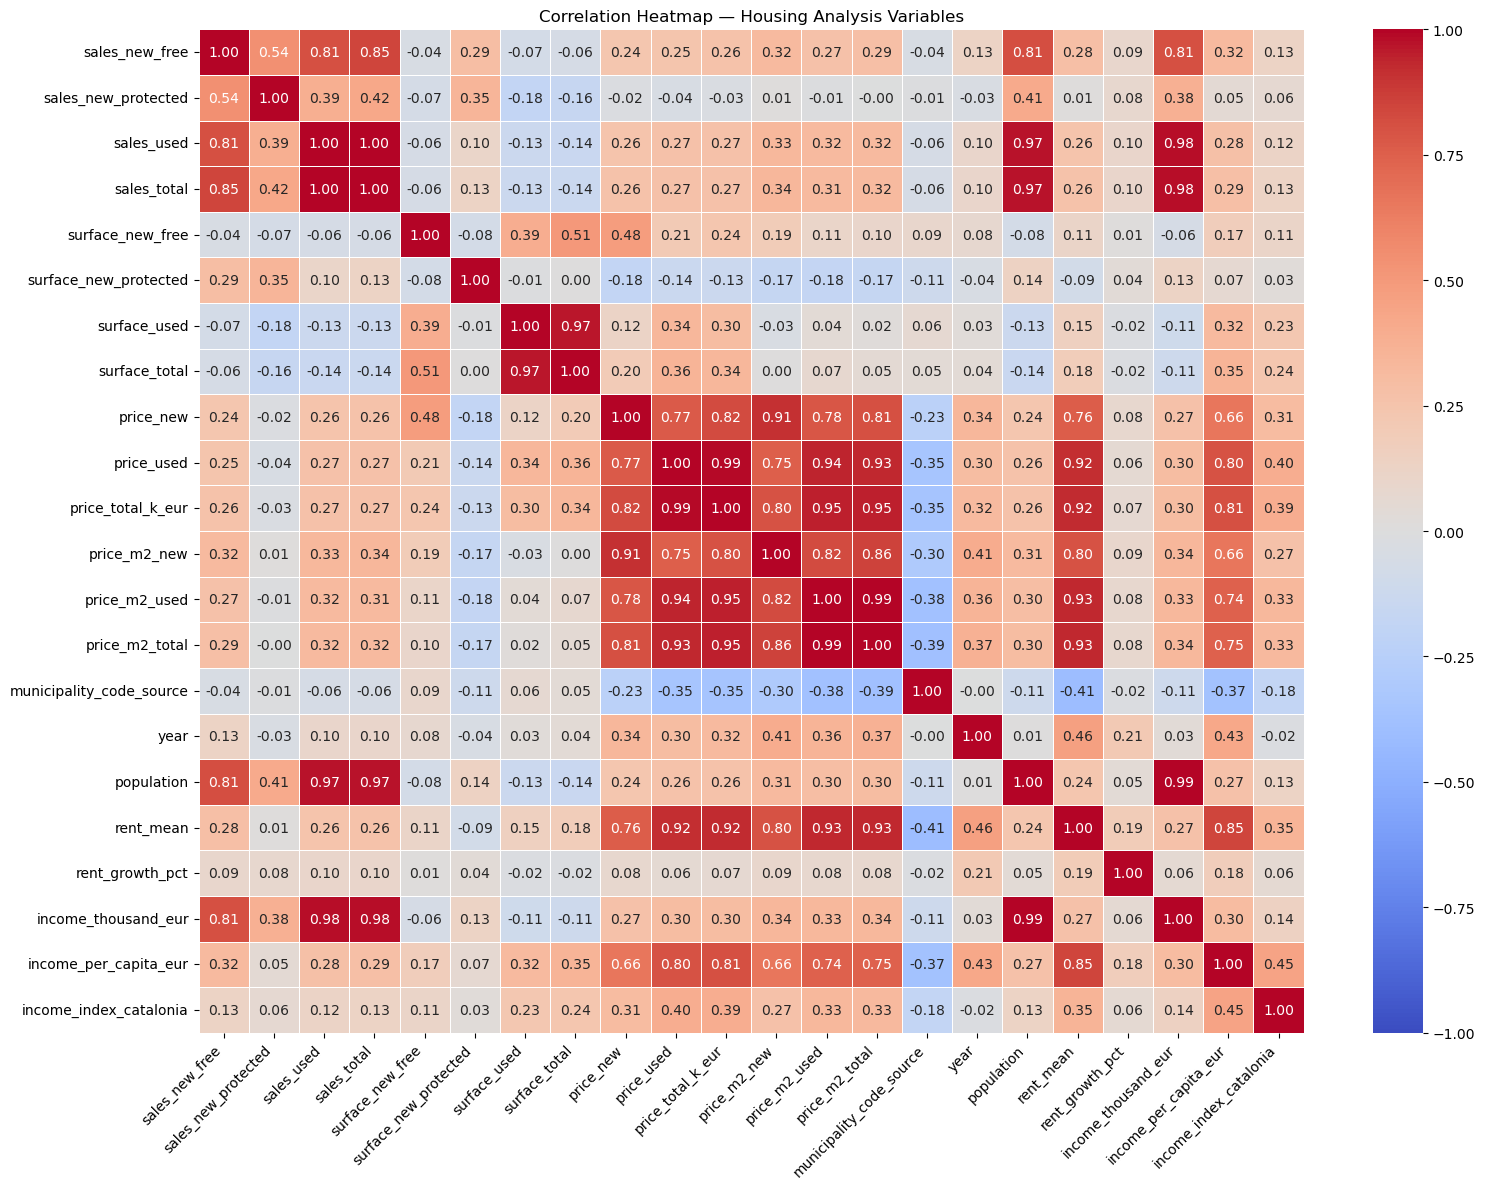

In [144]:
# Select numeric variables, excluding municipality codes
numeric_vars = (
    housing_analysis
    .select_dtypes(include="number")
    .columns
    .drop("municipality_code", errors="ignore")
)

# Calculate the correlation matrix
correlation_matrix = housing_analysis[numeric_vars].corr()

# Plot the heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Housing Analysis Variables")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [145]:
# Calculate municipality-level growth between 2013 and 2023
# Use the same municipality-year dataset and column names throughout the analysis.

growth_period = (
    bivariate_analysis.loc[
        bivariate_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR]),
        [
            "municipality",
            "year",
            "price_total_k_eur",
            "price_m2_total",
            "income_per_capita_eur",
        ],
    ]
    .pivot(
        index="municipality",
        columns="year",
        values=[
            "price_total_k_eur",
            "price_m2_total",
            "income_per_capita_eur",
        ],
    )
)

growth_by_municipality = pd.DataFrame(index=growth_period.index)

# Preserve endpoint values for interpretation and validation.
growth_by_municipality["price_total_k_eur_2013"] = growth_period[("price_total_k_eur", ANALYSIS_START_YEAR)]
growth_by_municipality["price_total_k_eur_2023"] = growth_period[("price_total_k_eur", ANALYSIS_END_YEAR)]
growth_by_municipality["price_m2_2013"] = growth_period[("price_m2_total", ANALYSIS_START_YEAR)]
growth_by_municipality["price_m2_2023"] = growth_period[("price_m2_total", ANALYSIS_END_YEAR)]
growth_by_municipality["income_2013"] = growth_period[("income_per_capita_eur", ANALYSIS_START_YEAR)]
growth_by_municipality["income_2023"] = growth_period[("income_per_capita_eur", ANALYSIS_END_YEAR)]

# Percentage growth in average total property sale price (k€).
growth_by_municipality["property_price_growth_pct"] = (
    growth_by_municipality["price_total_k_eur_2023"]
    .div(growth_by_municipality["price_total_k_eur_2013"])
    .sub(1)
    .mul(100)
)

# Percentage growth in sale price per square metre.
growth_by_municipality["price_m2_growth_pct"] = (
    growth_by_municipality["price_m2_2023"]
    .div(growth_by_municipality["price_m2_2013"])
    .sub(1)
    .mul(100)
)

# Percentage growth in income per capita.
growth_by_municipality["income_growth_pct"] = (
    growth_by_municipality["income_2023"]
    .div(growth_by_municipality["income_2013"])
    .sub(1)
    .mul(100)
)

# Difference in growth rates, expressed in percentage points.
growth_by_municipality["price_income_gap_pp"] = (
    growth_by_municipality["price_m2_growth_pct"]
    - growth_by_municipality["income_growth_pct"]
)

growth_by_municipality.index.name = "municipality"
growth_by_municipality = growth_by_municipality.replace([np.inf, -np.inf], np.nan)

print("Municipalities with endpoint data:", len(growth_by_municipality))
print("Missing growth values:")
print(
    growth_by_municipality[
        [
            "property_price_growth_pct",
            "price_m2_growth_pct",
            "income_growth_pct",
            "price_income_gap_pp",
        ]
    ].isna().sum()
)

display(growth_by_municipality.head())


Municipalities with endpoint data: 47
Missing growth values:
property_price_growth_pct    0
price_m2_growth_pct          0
income_growth_pct            0
price_income_gap_pp          0
dtype: int64


,price_total_k_eur_2013,price_total_k_eur_2023,price_m2_2013,price_m2_2023,income_2013,income_2023,property_price_growth_pct,price_m2_growth_pct,income_growth_pct,price_income_gap_pp
municipality,,,,,,,,,,
Badalona,142.91143,186.98393,1786.94,2462.57,15224.0,19114.0,30.839031,37.809328,25.551760,12.257567
Barberà del Vallès,132.07400,201.64814,1398.38,2311.14,16102.0,20086.0,52.678150,65.272673,24.742268,40.530405
Barcelona,248.96199,374.26615,2718.96,4370.96,19474.0,25898.0,50.330639,60.758525,32.987573,27.770952
Blanes,151.53253,157.69005,2094.13,2215.29,12785.0,16740.0,4.063497,5.785696,30.934689,-25.148993
Calafell,122.67491,173.35682,1405.08,2051.37,13341.0,16248.0,41.313998,45.996669,21.789971,24.206698


# Sales

### price vs amount of sales

In [146]:
# Calculate total home sales by municipality (2013–2023)
total_sales = (
    sales_analysis[
        sales_analysis["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
    ]
    .groupby("municipality", as_index=False)["sales_total"]
    .sum()
)

# Calculate average population by municipality
avg_population = (
    population_analysis[
        population_analysis["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
    ]
    .groupby("municipality", as_index=False)["population"]
    .mean()
    .rename(columns={"population": "avg_population"})
)

# Calculate total home sales per 1,000 inhabitants
sales_per_capita = total_sales.merge(
    avg_population,
    on="municipality",
    how="inner"
)

sales_per_capita["sales_per_1000"] = (
    sales_per_capita["sales_total"]
    / sales_per_capita["avg_population"]
    * 1000
)

sales_per_capita.head()


,municipality,sales_total,avg_population,sales_per_1000
0,Badalona,21158,2.196558e+05,96.323422
1,Barberà del Vallès,3587,3.291655e+04,108.972553
2,Barcelona,143477,1.627135e+06,88.177682
3,Blanes,5675,3.964182e+04,143.156905
4,Calafell,6833,2.636082e+04,259.210467


In [147]:
# Combine housing sales intensity with housing price growth
sales_price_growth = (
    growth_by_municipality.reset_index()[
        ["municipality", "price_m2_growth_pct"]
    ]
    .merge(
        sales_per_capita[
            ["municipality", "sales_per_1000"]
        ],
        on="municipality",
        how="inner"
    )
)

print("Number of municipalities:", len(sales_price_growth))
sales_price_growth.head()


Number of municipalities: 47


,municipality,price_m2_growth_pct,sales_per_1000
0,Badalona,37.809328,96.323422
1,Barberà del Vallès,65.272673,108.972553
2,Barcelona,60.758525,88.177682
3,Blanes,5.785696,143.156905
4,Calafell,45.996669,259.210467


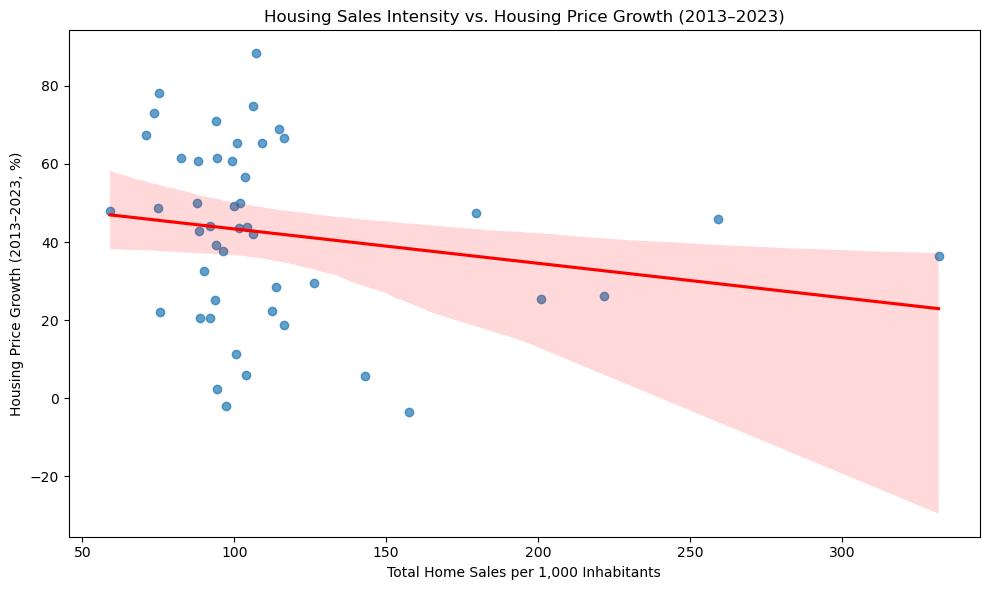

Spearman correlation: -0.230
P-value: 0.119316
Number of municipalities: 47


In [148]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=sales_price_growth,
    x="sales_per_1000",
    y="price_m2_growth_pct",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("Housing Sales Intensity vs. Housing Price Growth (2013–2023)")
plt.xlabel("Total Home Sales per 1,000 Inhabitants")
plt.ylabel("Housing Price Growth (2013–2023, %)")
plt.tight_layout()
plt.show()

rho, p_value = spearmanr(
    sales_price_growth["sales_per_1000"],
    sales_price_growth["price_m2_growth_pct"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Number of municipalities: {len(sales_price_growth)}")


No important evidence

In [149]:
# Review municipality-level growth metrics (2013–2023)
# The growth table is created once in the preceding calculation cell.
display(
    growth_by_municipality
    .sort_values("price_income_gap_pp", ascending=False)
    .round(2)
)


,price_total_k_eur_2013,price_total_k_eur_2023,price_m2_2013,price_m2_2023,income_2013,income_2023,property_price_growth_pct,price_m2_growth_pct,income_growth_pct,price_income_gap_pp
municipality,,,,,,,,,,
Vic,90.46,179.65,1052.43,1981.87,15250.0,19508.0,98.59,88.31,27.92,60.39
"Prat de Llobregat, el",130.77,221.90,1675.87,2986.63,16459.0,20168.0,69.68,78.21,22.53,55.68
Cornellà de Llobregat,99.58,177.00,1555.25,2691.58,15519.0,19180.0,77.75,73.06,23.59,49.47
Esplugues de Llobregat,216.05,396.58,2470.56,4136.81,18375.0,22939.0,83.56,67.44,24.84,42.61
Rubí,112.97,183.51,1256.75,2078.42,14877.0,18483.0,62.45,65.38,24.24,41.14
Barberà del Vallès,132.07,201.65,1398.38,2311.14,16102.0,20086.0,52.68,65.27,24.74,40.53
Mataró,113.14,194.31,1355.86,2317.20,13840.0,18465.0,71.74,70.90,33.42,37.48
Terrassa,91.75,165.80,1179.44,1993.34,15084.0,19895.0,80.71,69.01,31.89,37.11
Mollet del Vallès,101.69,166.75,1298.19,2096.15,15213.0,19106.0,63.98,61.47,25.59,35.88


### Price vs Income

In [150]:

correlation = bivariate_analysis[
    ["price_total_k_eur", "income_per_capita_eur"]
].corr(method="pearson")

correlation


,price_total_k_eur,income_per_capita_eur
price_total_k_eur,1.00000,0.80526
income_per_capita_eur,0.80526,1.00000


In [151]:

yearly_correlation = (
    bivariate_analysis
    .groupby("year")
    .apply(
        lambda group: group["price_total_k_eur"].corr(
            group["income_per_capita_eur"]
        ),
        include_groups=False
    )
    .reset_index(name="correlation")
)

yearly_correlation


,year,correlation
0,2013,0.629566
1,2014,0.653250
2,2015,0.728218
3,2016,0.796534
4,2017,0.823517
5,2018,0.833126
6,2019,0.850717
7,2020,0.855260
8,2021,0.827970
9,2022,0.836599


The correlation between price and income per capita growth over the years.

In [152]:

annual_macro = (
    bivariate_analysis
    .groupby("year", as_index=False)
    .agg(
        avg_price_m2=("price_m2_total", "mean"),
        avg_income_per_capita=("income_per_capita_eur", "mean")
    )
)

annual_macro


,year,avg_price_m2,avg_income_per_capita
0,2013,1686.979149,15114.489362
1,2014,1591.356596,15341.872340
2,2015,1616.086170,15946.659574
3,2016,1695.199149,16306.723404
4,2017,1808.581915,16520.170213
5,2018,1983.135957,16735.872340
6,2019,2118.857234,17451.489362
7,2020,2209.495106,16823.893617
8,2021,2284.357872,17781.297872
9,2022,2391.527234,18201.574468


In [153]:
# Calculate annual averages for 2013 and 2023
annual_growth = (
    bivariate_analysis[
        bivariate_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])
    ]
    .groupby("year")
    .agg(
        avg_property_price=("price_total_k_eur", "mean"),
        avg_price_m2=("price_m2_total", "mean"),
        avg_income_per_capita=("income_per_capita_eur", "mean")
    )
)

# Build comparison table
growth_table = pd.DataFrame({
    "Variable": [
        "Average property sale price (k€)",
        "Housing price per m² (€/m²)",
        "Income per capita (€)"
    ],
    "Value in 2013": [
        annual_growth.loc[ANALYSIS_START_YEAR, "avg_property_price"],
        annual_growth.loc[ANALYSIS_START_YEAR, "avg_price_m2"],
        annual_growth.loc[ANALYSIS_START_YEAR, "avg_income_per_capita"]
    ],
    "Value in 2023": [
        annual_growth.loc[ANALYSIS_END_YEAR, "avg_property_price"],
        annual_growth.loc[ANALYSIS_END_YEAR, "avg_price_m2"],
        annual_growth.loc[ANALYSIS_END_YEAR, "avg_income_per_capita"]
    ]
})

growth_table["Growth (%)"] = (
    (growth_table["Value in 2023"] - growth_table["Value in 2013"])
    / growth_table["Value in 2013"] * 100
)

growth_table.round(2)


,Variable,Value in 2013,Value in 2023,Growth (%)
0,Average property sale price (k€),147.23,206.10,39.99
1,Housing price per m² (€/m²),1686.98,2419.55,43.43
2,Income per capita (€),15114.49,19486.47,28.93


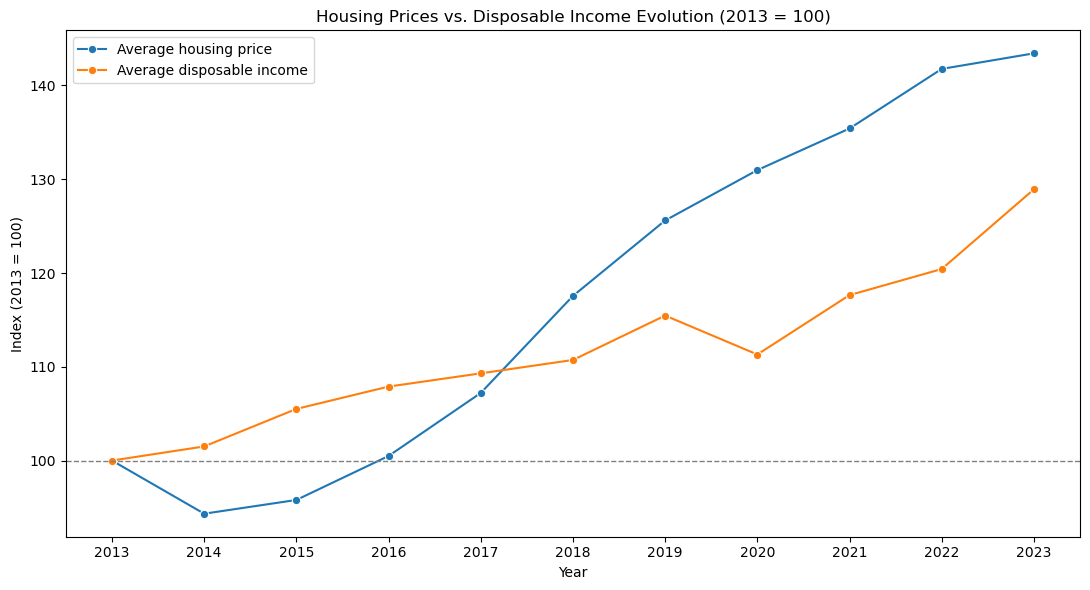

In [154]:

annual_macro["price_index"] = (
    annual_macro["avg_price_m2"]
    / annual_macro.loc[annual_macro["year"] == ANALYSIS_START_YEAR, "avg_price_m2"].iloc[0]
    * 100
)

annual_macro["income_index"] = (
    annual_macro["avg_income_per_capita"]
    / annual_macro.loc[annual_macro["year"] == ANALYSIS_START_YEAR, "avg_income_per_capita"].iloc[0]
    * 100
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=annual_macro,
    x="year",
    y="price_index",
    marker="o",
    label="Average housing price"
)

sns.lineplot(
    data=annual_macro,
    x="year",
    y="income_index",
    marker="o",
    label="Average disposable income"
)

plt.axhline(100, linestyle="--", linewidth=1, color="gray")
plt.title("Housing Prices vs. Disposable Income Evolution (2013 = 100)")
plt.xlabel("Year")
plt.ylabel("Index (2013 = 100)")
plt.xticks(annual_macro["year"])
plt.legend()
plt.tight_layout()
plt.show()


In [155]:
# The annual affordability-ratio analysis is consolidated in the section below.
# Use the price and income indices in cells 179–181 for the overall trend,
# and the municipal cost-to-income indices in cells 193 and 239–241 for relative changes.


In [156]:

annual_trend = (
    bivariate_analysis
    .groupby("year", as_index=False)
    .agg(
        avg_price_m2=("price_m2_total", "mean"),
        avg_income=("income_per_capita_eur", "mean")
    )
    .sort_values("year")
)

annual_trend["price_growth_pct"] = (
    annual_trend["avg_price_m2"].pct_change() * 100
)

annual_trend["income_growth_pct"] = (
    annual_trend["avg_income"].pct_change() * 100
)

annual_trend["growth_gap_pp"] = (
    annual_trend["price_growth_pct"]
    - annual_trend["income_growth_pct"]
)

annual_trend.round(2)


,year,avg_price_m2,avg_income,price_growth_pct,income_growth_pct,growth_gap_pp
0,2013,1686.98,15114.49,NaN,NaN,NaN
1,2014,1591.36,15341.87,-5.67,1.50,-7.17
2,2015,1616.09,15946.66,1.55,3.94,-2.39
3,2016,1695.20,16306.72,4.90,2.26,2.64
4,2017,1808.58,16520.17,6.69,1.31,5.38
5,2018,1983.14,16735.87,9.65,1.31,8.35
6,2019,2118.86,17451.49,6.84,4.28,2.57
7,2020,2209.50,16823.89,4.28,-3.60,7.87
8,2021,2284.36,17781.30,3.39,5.69,-2.30
9,2022,2391.53,18201.57,4.69,2.36,2.33


In [157]:
annual_macro.loc[
    annual_macro["year"] == ANALYSIS_END_YEAR,
    ["year", "avg_price_m2", "price_index", "avg_income_per_capita", "income_index"]
]


,year,avg_price_m2,price_index,avg_income_per_capita,income_index
10,2023,2419.551064,143.425072,19486.468085,128.925745


The indexed comparison uses 2013 as the baseline (2013 = 100), allowing price and income trends to be compared despite their different units. Between 2013 and 2023, the average price per square metre increased by approximately 43%, while average income per capita increased by approximately 29%. This indicates that sale prices grew faster than income in the municipalities included in the analysis. It is evidence of increasing housing costs relative to income, but it is not a direct measure of household affordability and does not establish causality.


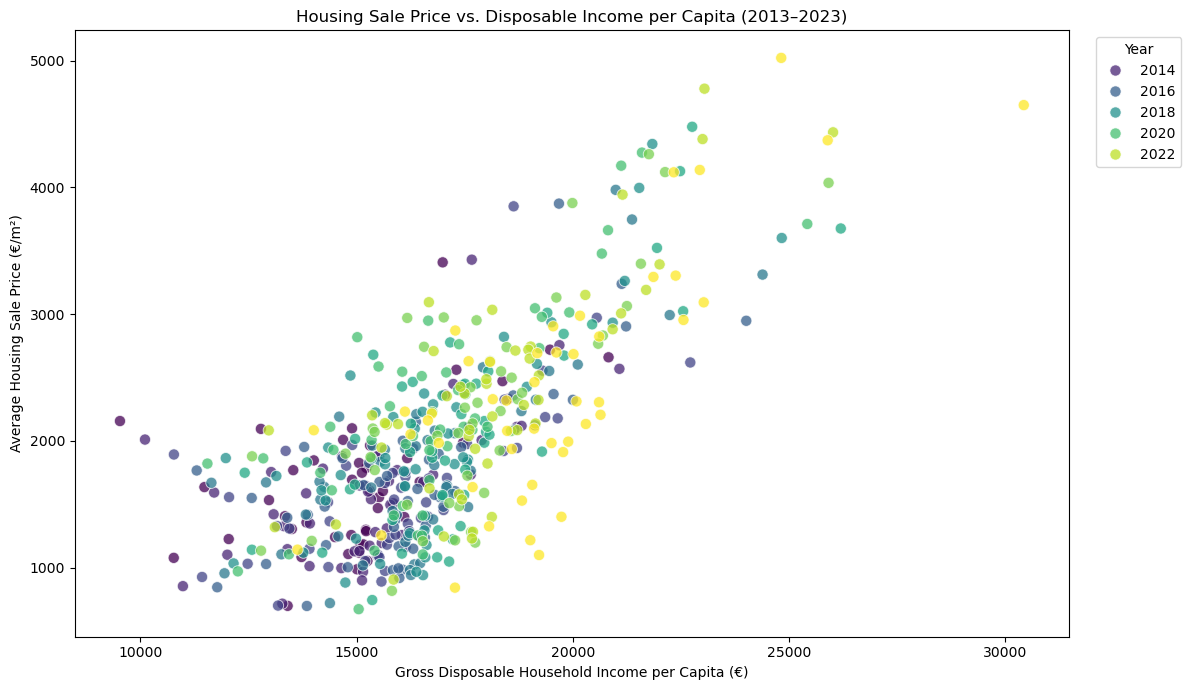

In [158]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=bivariate_analysis,
    x="income_per_capita_eur",
    y="price_m2_total",
    hue="year",
    palette="viridis",
    alpha=0.75,
    s=65
)

plt.title("Housing Sale Price vs. Disposable Income per Capita (2013–2023)")
plt.xlabel("Gross Disposable Household Income per Capita (€)")
plt.ylabel("Average Housing Sale Price (€/m²)")
plt.legend(
    title="Year",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


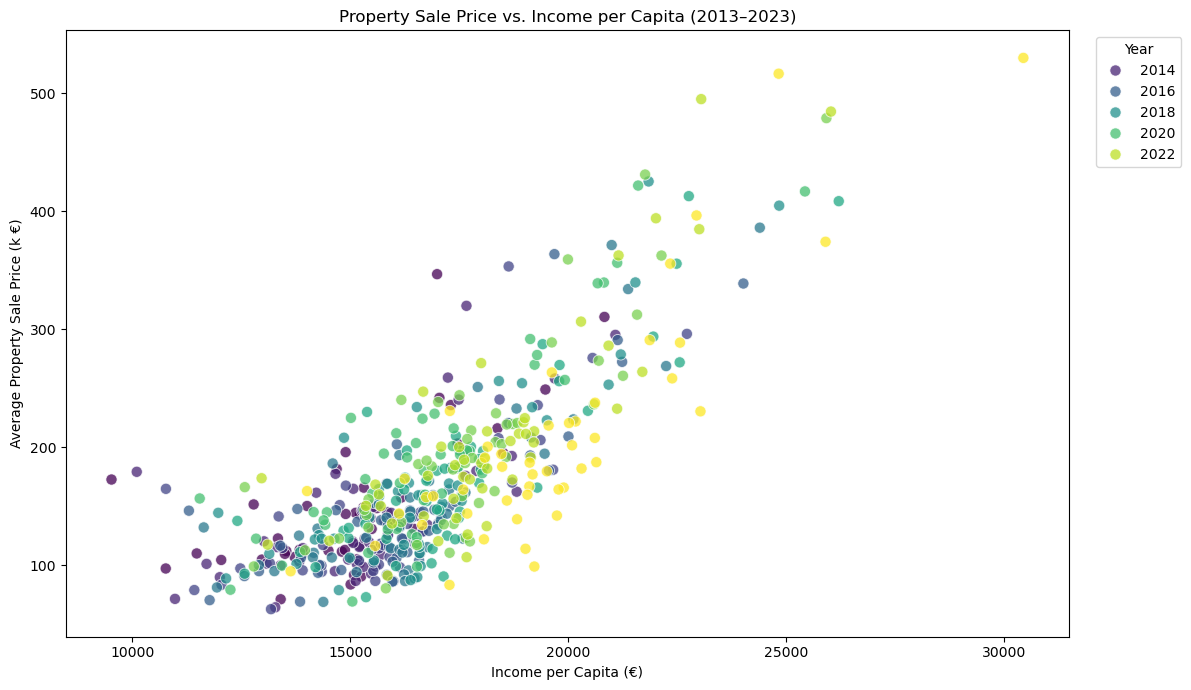

In [159]:

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=bivariate_analysis,
    x="income_per_capita_eur",
    y="price_total_k_eur",
    hue="year",
    palette="viridis",
    alpha=0.75,
    s=65
)

plt.title("Property Sale Price vs. Income per Capita (2013–2023)")
plt.xlabel("Income per Capita (€)")
plt.ylabel("Average Property Sale Price (k €)")
plt.legend(
    title="Year",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


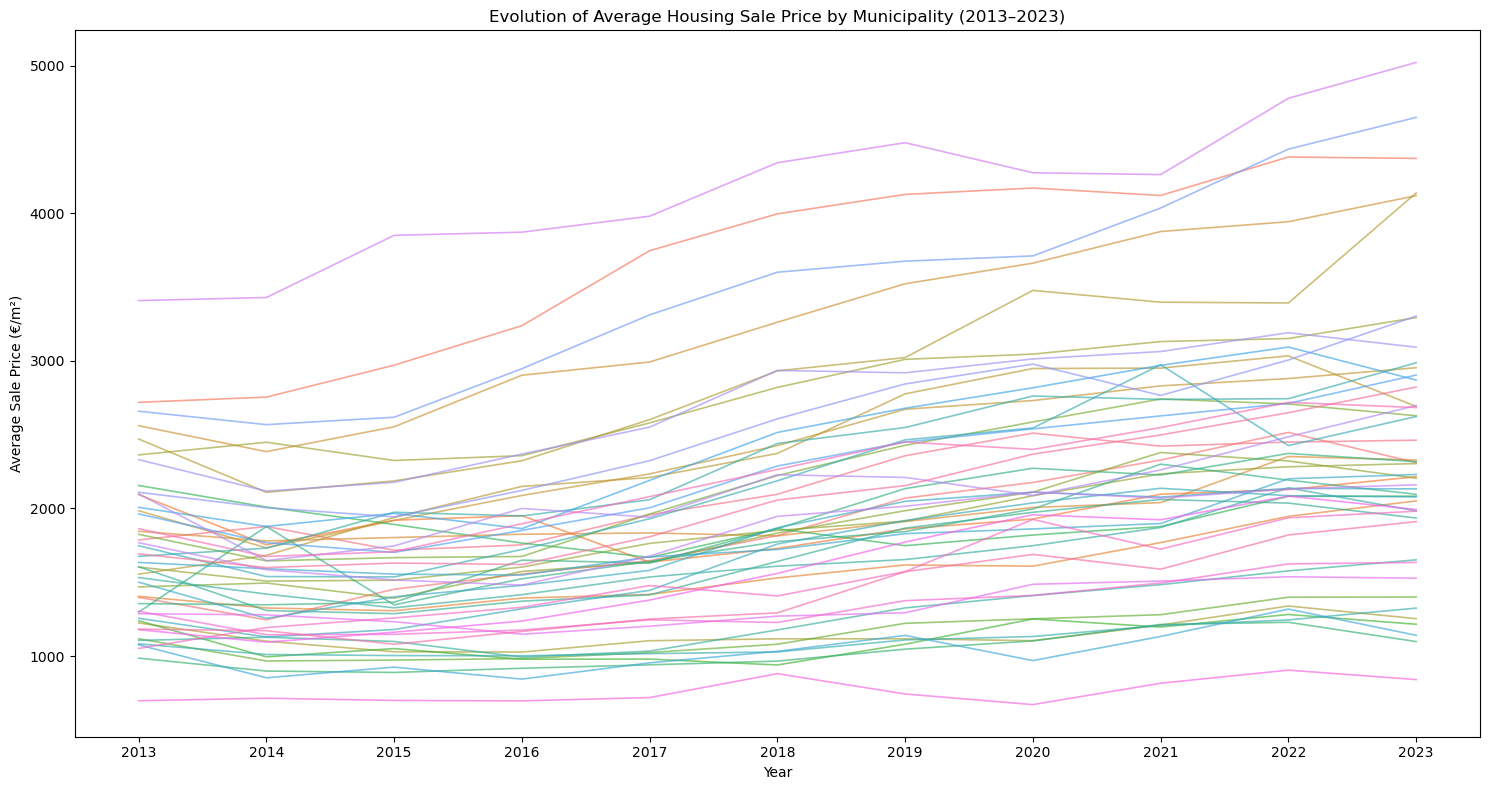

In [160]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))

sns.lineplot(
    data=housing_analysis,
    x="year",
    y="price_m2_total",
    hue="municipality",
    estimator=None,
    alpha=0.65,
    linewidth=1.2,
    legend=False
)

plt.title("Evolution of Average Housing Sale Price by Municipality (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Average Sale Price (€/m²)")
plt.xticks(sorted(housing_analysis["year"].unique()))
plt.tight_layout()
plt.show()


### Research question
Could the distance to Barcelona or to another major urban centre be associated with differences in the gap between housing-price growth and income growth? The following analysis is exploratory and cannot establish a causal effect.


In [161]:

# Add municipality distances to the growth analysis
growth_distance = (
    growth_by_municipality
    .reset_index()
    .merge(
        distance_analysis[
            [
                "municipality",
                "distance_to_barcelona_km",
                "distance_to_girona_km",
                "distance_to_tarragona_km",
                "distance_to_lleida_km"
            ]
        ],
        on="municipality",
        how="left",
        validate="one_to_one"
    )
)

print("Shape:", growth_distance.shape)
print("Missing distances:")
print(
    growth_distance[
        [
            "distance_to_barcelona_km",
            "distance_to_girona_km",
            "distance_to_tarragona_km",
            "distance_to_lleida_km"
        ]
    ].isna().sum()
)

growth_distance.head()


Shape: (47, 15)
Missing distances:
distance_to_barcelona_km    0
distance_to_girona_km       0
distance_to_tarragona_km    0
distance_to_lleida_km       0
dtype: int64


,municipality,price_total_k_eur_2013,price_total_k_eur_2023,price_m2_2013,price_m2_2023,income_2013,income_2023,property_price_growth_pct,price_m2_growth_pct,income_growth_pct,price_income_gap_pp,distance_to_barcelona_km,distance_to_girona_km,distance_to_tarragona_km,distance_to_lleida_km
0,Badalona,142.91143,186.98393,1786.94,2462.57,15224.0,19114.0,30.839031,37.809328,25.551760,12.257567,11.9809,90.4004,106.2319,160.3240
1,Barberà del Vallès,132.07400,201.64814,1398.38,2311.14,16102.0,20086.0,52.678150,65.272673,24.742268,40.530405,21.3275,90.3167,102.6417,148.3405
2,Barcelona,248.96199,374.26615,2718.96,4370.96,19474.0,25898.0,50.330639,60.758525,32.987573,27.770952,0.0000,102.6975,96.3642,156.0042
3,Blanes,151.53253,157.69005,2094.13,2215.29,12785.0,16740.0,4.063497,5.785696,30.934689,-25.148993,71.6994,41.6698,172.5532,218.9033
4,Calafell,122.67491,173.35682,1405.08,2051.37,13341.0,16248.0,41.313998,45.996669,21.789971,24.206698,64.6819,168.5116,34.4339,110.1848


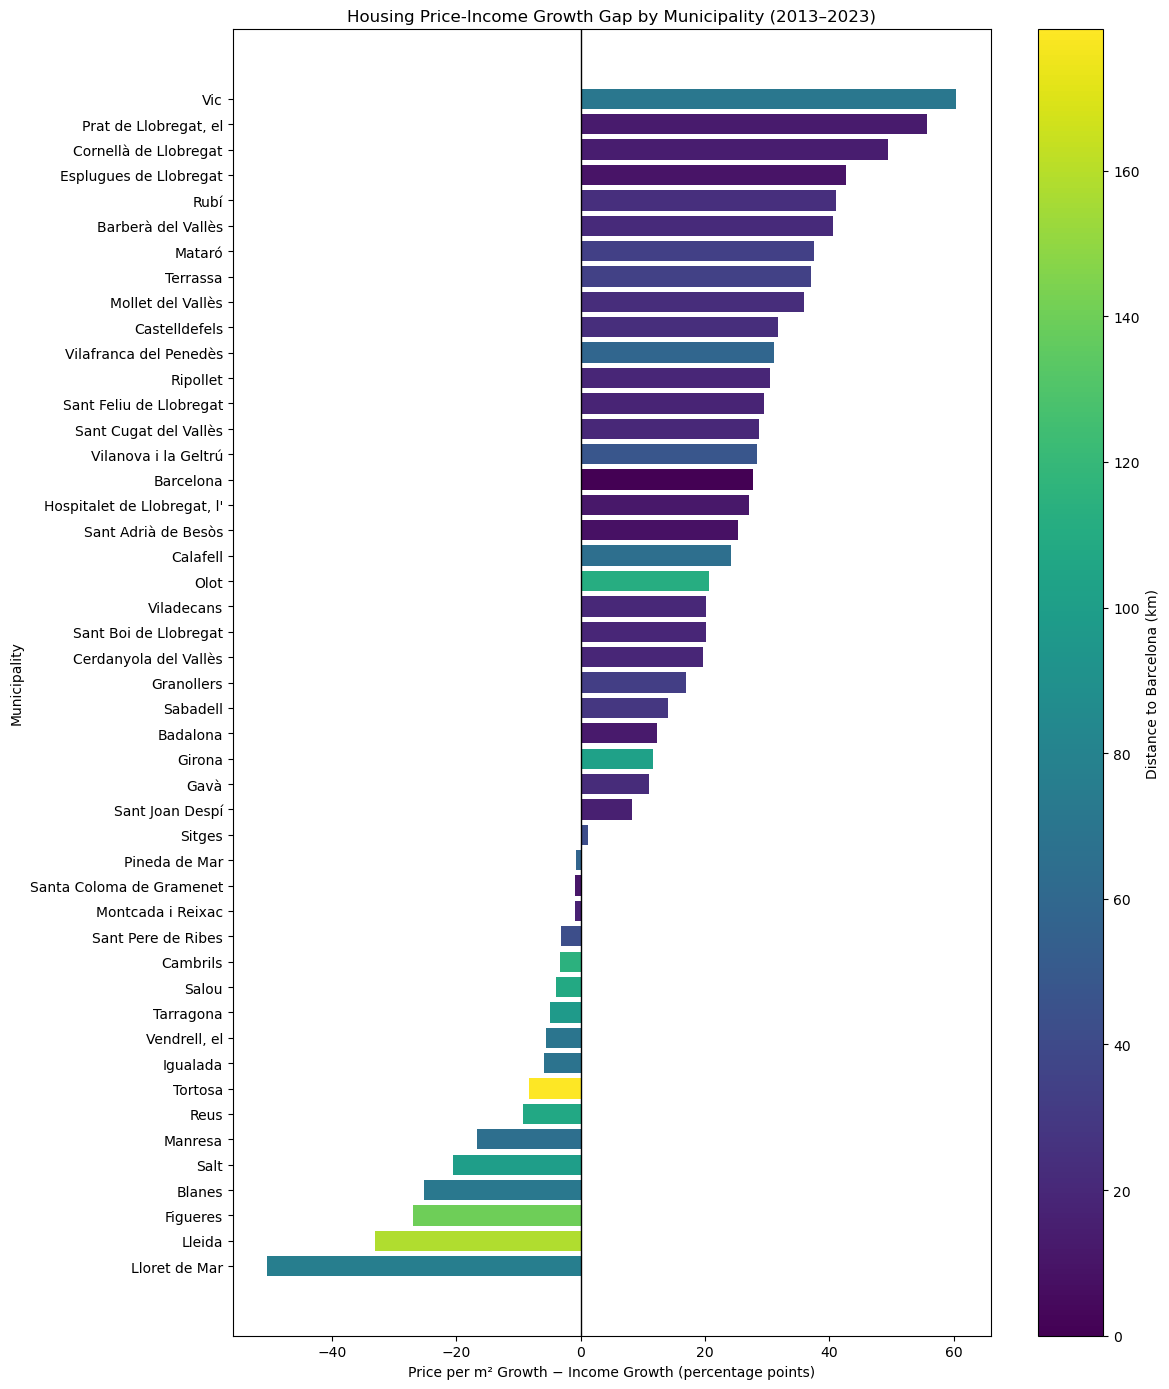

In [162]:
plot_data = (
    growth_distance
    .sort_values("price_income_gap_pp", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 14))

distance_values = plot_data["distance_to_barcelona_km"]
norm = mpl.colors.Normalize(
    vmin=distance_values.min(),
    vmax=distance_values.max()
)
cmap = plt.get_cmap("viridis")
bar_colors = cmap(norm(distance_values))

ax.barh(
    plot_data["municipality"],
    plot_data["price_income_gap_pp"],
    color=bar_colors,
)
ax.axvline(0, color="black", linewidth=1)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, label="Distance to Barcelona (km)")

ax.set_title("Housing Price-Income Growth Gap by Municipality (2013–2023)")
ax.set_xlabel("Price per m² Growth − Income Growth (percentage points)")
ax.set_ylabel("Municipality")

plt.tight_layout()
plt.show()


Largest increases in the relative purchase cost-to-income index (2013–2023):


year,municipality,2013,2023,change_pct
43,Vic,0.0690,0.1016,+47.21%
24,"Prat de Llobregat, el",0.1018,0.1481,+45.44%
8,Cornellà de Llobregat,0.1002,0.1403,+40.03%
9,Esplugues de Llobregat,0.1345,0.1803,+34.13%
27,Rubí,0.0845,0.1125,+33.12%


Smallest increases / largest decreases in the index (2013–2023):


year,municipality,2013,2023,change_pct
17,Lloret de Mar,0.2263,0.1487,-34.29%
16,Lleida,0.0855,0.0639,-25.24%
10,Figueres,0.1017,0.0805,-20.84%
3,Blanes,0.1638,0.1323,-19.21%
30,Salt,0.1000,0.0837,-16.26%


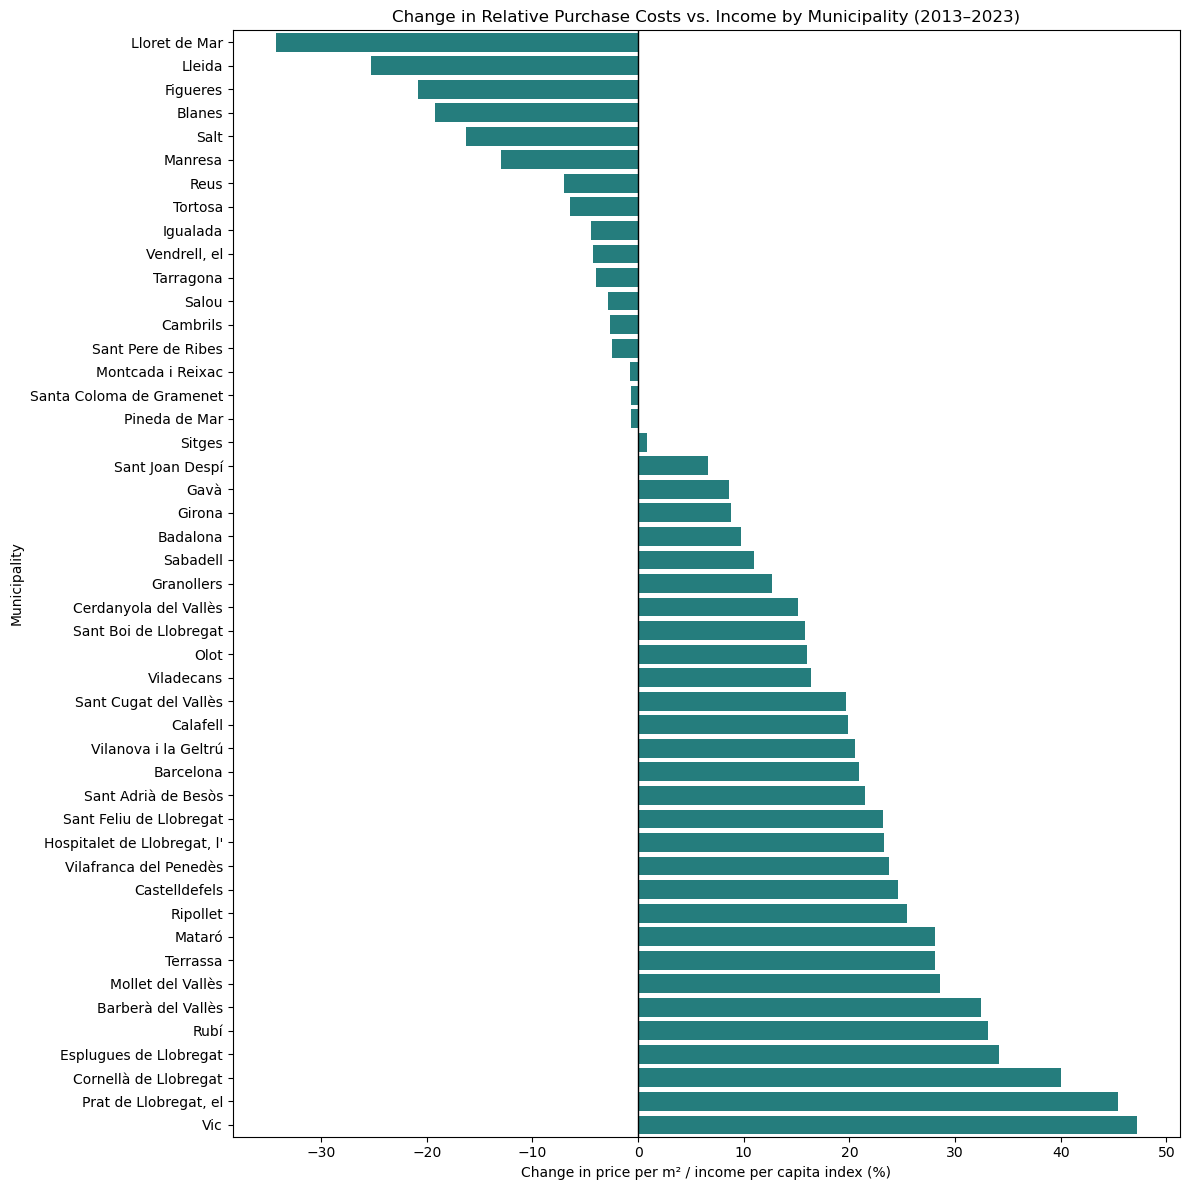

In [163]:
# Compare municipal changes in the price-per-m² / income-per-capita index (2013–2023).
# This is a relative index, not a direct estimate of the share of income spent on housing.
affordability_analysis = bivariate_analysis.loc[
    bivariate_analysis["income_per_capita_eur"].notna()
].copy()

affordability_analysis["purchase_cost_income_index"] = (
    affordability_analysis["price_m2_total"]
    / affordability_analysis["income_per_capita_eur"]
)

affordability_comparison = (
    affordability_analysis[
        affordability_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])
    ]
    .pivot(
        index="municipality",
        columns="year",
        values="purchase_cost_income_index"
    )
    .reset_index()
)

# Retain municipalities with both endpoint observations; do not impute missing years.
affordability_comparison["change_pct"] = (
    affordability_comparison[ANALYSIS_END_YEAR]
    / affordability_comparison[ANALYSIS_START_YEAR]
    - 1
) * 100

affordability_comparison = affordability_comparison.dropna(
    subset=[ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "change_pct"]
).sort_values("change_pct", ascending=False)

print("Largest increases in the relative purchase cost-to-income index (2013–2023):")
display(
    affordability_comparison[["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "change_pct"]]
    .head(5)
    .style.format({ANALYSIS_START_YEAR: "{:.4f}", ANALYSIS_END_YEAR: "{:.4f}", "change_pct": "{:+.2f}%"})
)

print("Smallest increases / largest decreases in the index (2013–2023):")
display(
    affordability_comparison[["municipality", ANALYSIS_START_YEAR, ANALYSIS_END_YEAR, "change_pct"]]
    .tail(5)
    .sort_values("change_pct")
    .style.format({ANALYSIS_START_YEAR: "{:.4f}", ANALYSIS_END_YEAR: "{:.4f}", "change_pct": "{:+.2f}%"})
)

plot_data = affordability_comparison.sort_values("change_pct")

plt.figure(figsize=(12, 12))
sns.barplot(data=plot_data, x="change_pct", y="municipality", color="#168C8C")
plt.axvline(0, color="black", linewidth=1)
plt.title("Change in Relative Purchase Costs vs. Income by Municipality (2013–2023)")
plt.xlabel("Change in price per m² / income per capita index (%)")
plt.ylabel("Municipality")
plt.tight_layout()
plt.show()


In [164]:

distance_cols = [
    "distance_to_barcelona_km",
    "distance_to_girona_km",
    "distance_to_tarragona_km",
    "distance_to_lleida_km"
]

growth_distance["nearest_centre_distance_km"] = (
    growth_distance[distance_cols].min(axis=1)
)

growth_distance["nearest_centre"] = (
    growth_distance[distance_cols]
    .idxmin(axis=1)
    .str.replace("distance_to_", "", regex=False)
    .str.replace("_km", "", regex=False)
    .str.title()
)

growth_distance[
    [
        "municipality",
        "nearest_centre",
        "nearest_centre_distance_km",
        "price_income_gap_pp"
    ]
].head(10)


,municipality,nearest_centre,nearest_centre_distance_km,price_income_gap_pp
0,Badalona,Barcelona,11.9809,12.257567
1,Barberà del Vallès,Barcelona,21.3275,40.530405
2,Barcelona,Barcelona,0.0000,27.770952
3,Blanes,Girona,41.6698,-25.148993
4,Calafell,Tarragona,34.4339,24.206698
5,Cambrils,Tarragona,22.2305,-3.393349
6,Castelldefels,Barcelona,23.5322,31.774869
7,Cerdanyola del Vallès,Barcelona,19.0174,19.603765
8,Cornellà de Llobregat,Barcelona,14.6353,49.473700
9,Esplugues de Llobregat,Barcelona,9.7772,42.606128


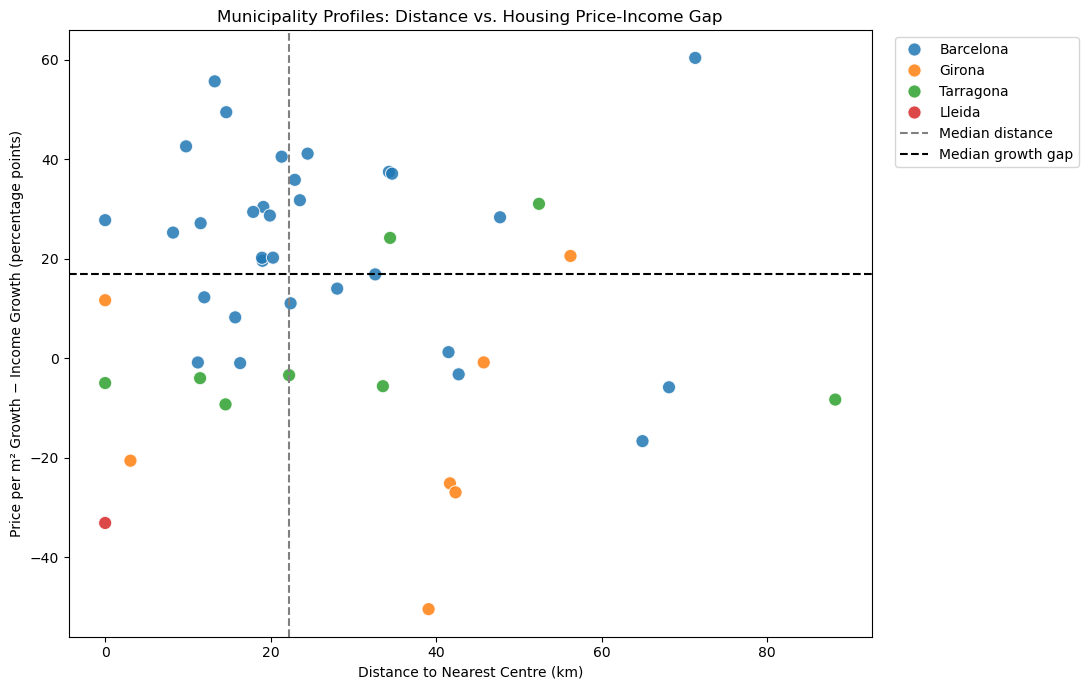

Median distance: 22.23 km
Median growth gap: 16.87 percentage points


In [165]:
plot_data = growth_distance.dropna(
    subset=[
        "nearest_centre_distance_km",
        "price_income_gap_pp"
    ]
).copy()

# Median thresholds
distance_median = plot_data["nearest_centre_distance_km"].median()
gap_median = plot_data["price_income_gap_pp"].median()

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_data,
    x="nearest_centre_distance_km",
    y="price_income_gap_pp",
    hue="nearest_centre",
    s=90,
    alpha=0.85
)

plt.axvline(
    distance_median,
    color="gray",
    linestyle="--",
    label="Median distance"
)

plt.axhline(
    gap_median,
    color="black",
    linestyle="--",
    label="Median growth gap"
)

plt.title("Municipality Profiles: Distance vs. Housing Price-Income Gap")
plt.xlabel("Distance to Nearest Centre (km)")
plt.ylabel("Price per m² Growth − Income Growth (percentage points)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Median distance:", round(distance_median, 2), "km")
print("Median growth gap:", round(gap_median, 2), "percentage points")


La diferencia entre el ingreso y el precio por m2 se hace mayor a medida que uno se acerca a barcelona exceptuando el crecimiento de Vic

In [166]:

plot_data["distance_quartile"] = pd.qcut(
    plot_data["nearest_centre_distance_km"],
    q=4,
    labels=["Q1 - Closest", "Q2", "Q3", "Q4 - Farthest"],
    duplicates="drop"
)

plot_data["gap_quartile"] = pd.qcut(
    plot_data["price_income_gap_pp"],
    q=4,
    labels=["Q1 - Lowest gap", "Q2", "Q3", "Q4 - Highest gap"],
    duplicates="drop"
)

plot_data[
    [
        "municipality",
        "nearest_centre_distance_km",
        "price_income_gap_pp",
        "distance_quartile",
        "gap_quartile"
    ]
].sort_values("price_income_gap_pp", ascending=False)


,municipality,nearest_centre_distance_km,price_income_gap_pp,distance_quartile,gap_quartile
43,Vic,71.3093,60.392401,Q4 - Farthest,Q4 - Highest gap
24,"Prat de Llobregat, el",13.2388,55.678921,Q1 - Closest,Q4 - Highest gap
8,Cornellà de Llobregat,14.6353,49.473700,Q2,Q4 - Highest gap
9,Esplugues de Llobregat,9.7772,42.606128,Q1 - Closest,Q4 - Highest gap
27,Rubí,24.4654,41.141787,Q3,Q4 - Highest gap
1,Barberà del Vallès,21.3275,40.530405,Q2,Q4 - Highest gap
19,Mataró,34.2922,37.484971,Q3,Q4 - Highest gap
40,Terrassa,34.6780,37.112603,Q3,Q4 - Highest gap
20,Mollet del Vallès,22.9199,35.877164,Q3,Q4 - Highest gap
6,Castelldefels,23.5322,31.774869,Q3,Q4 - Highest gap


### Understand if the places with more construction have a bigger gap


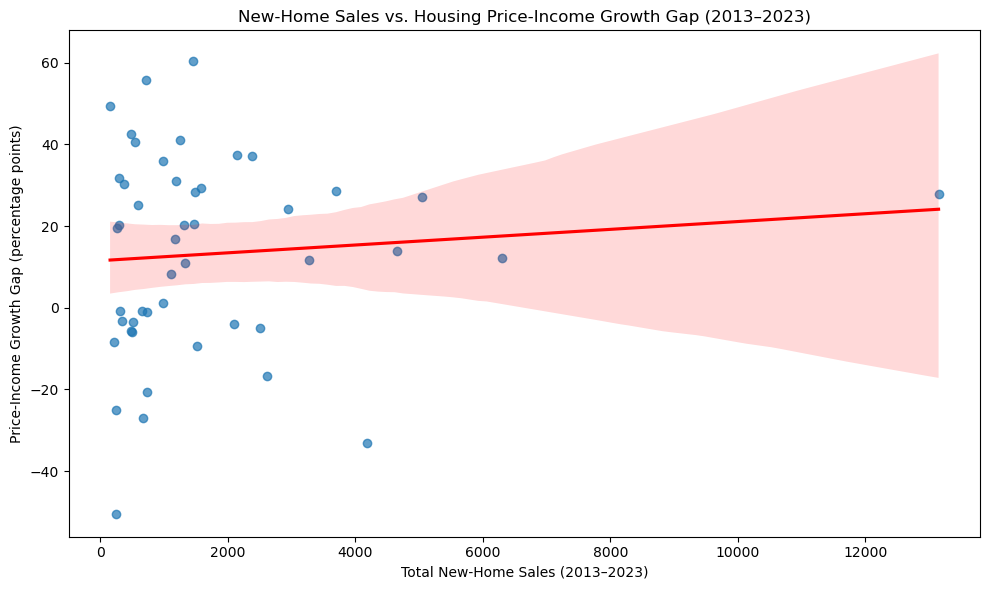

Spearman correlation: 0.093
Number of municipalities: 47


In [167]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Calculate total new-home sales by municipality (2013–2023)
new_sales = (
    sales_analysis[sales_analysis["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)]
    .assign(
        new_sales_total=lambda df:
            df["sales_new_free"].fillna(0)
            + df["sales_new_protected"].fillna(0)
    )
    .groupby("municipality", as_index=False)["new_sales_total"]
    .sum()
)

# Convert municipality index into a column
growth_data = growth_by_municipality.reset_index()

# Combine the housing price-income gap with new-home sales
gap_new_sales = growth_data[
    ["municipality", "price_income_gap_pp"]
].merge(
    new_sales,
    on="municipality",
    how="inner"
)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=gap_new_sales,
    x="new_sales_total",
    y="price_income_gap_pp",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("New-Home Sales vs. Housing Price-Income Growth Gap (2013–2023)")
plt.xlabel("Total New-Home Sales (2013–2023)")
plt.ylabel("Price-Income Growth Gap (percentage points)")
plt.tight_layout()
plt.show()

# Spearman correlation test
rho, p_value = spearmanr(
    gap_new_sales["new_sales_total"],
    gap_new_sales["price_income_gap_pp"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"Number of municipalities: {len(gap_new_sales)}")


Results and Interpretation

Spearman's correlation showed a very weak, non-significant positive association between new-home sales and the housing price-income growth gap (ρ = 0.093, p = 0.533, n = 47).

In [168]:
# Review sales intensity calculated earlier in the housing-price analysis
display(sales_per_capita.head())


,municipality,sales_total,avg_population,sales_per_1000
0,Badalona,21158,2.196558e+05,96.323422
1,Barberà del Vallès,3587,3.291655e+04,108.972553
2,Barcelona,143477,1.627135e+06,88.177682
3,Blanes,5675,3.964182e+04,143.156905
4,Calafell,6833,2.636082e+04,259.210467


In [169]:
# Combine sales intensity with the housing price-income growth gap
growth_data = growth_by_municipality.reset_index()

sales_gap_analysis = growth_data[
    ["municipality", "price_income_gap_pp"]
].merge(
    sales_per_capita[
        ["municipality", "sales_per_1000"]
    ],
    on="municipality",
    how="inner"
)

print("Number of municipalities:", len(sales_gap_analysis))
sales_gap_analysis.head()


Number of municipalities: 47


,municipality,price_income_gap_pp,sales_per_1000
0,Badalona,12.257567,96.323422
1,Barberà del Vallès,40.530405,108.972553
2,Barcelona,27.770952,88.177682
3,Blanes,-25.148993,143.156905
4,Calafell,24.206698,259.210467


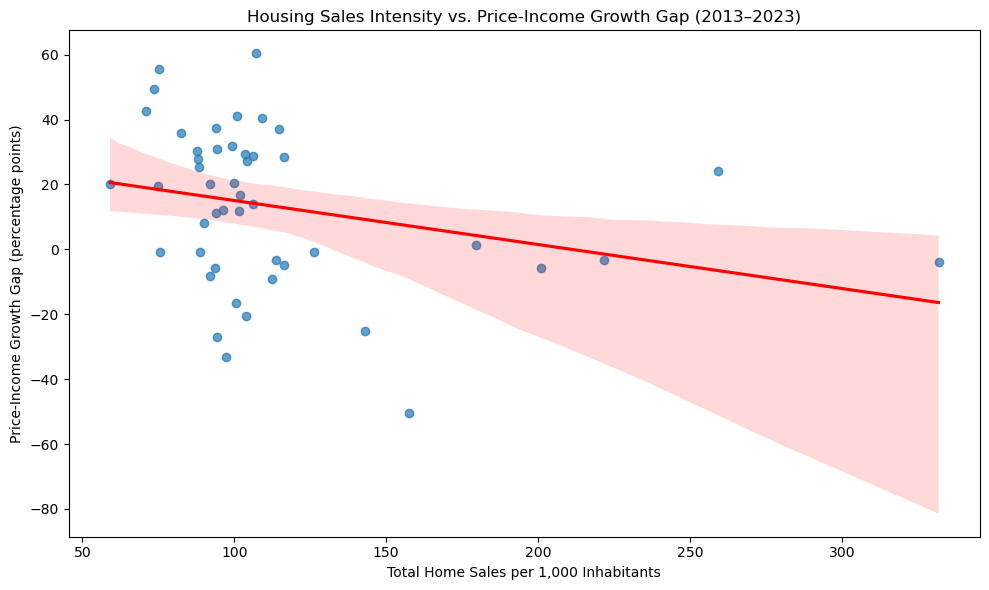

Spearman correlation: -0.325
Number of municipalities: 47


In [170]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.figure(figsize=(10, 6))

sns.regplot(
    data=sales_gap_analysis,
    x="sales_per_1000",
    y="price_income_gap_pp",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("Housing Sales Intensity vs. Price-Income Growth Gap (2013–2023)")
plt.xlabel("Total Home Sales per 1,000 Inhabitants")
plt.ylabel("Price-Income Growth Gap (percentage points)")
plt.tight_layout()
plt.show()

rho, p_value = spearmanr(
    sales_gap_analysis["sales_per_1000"],
    sales_gap_analysis["price_income_gap_pp"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"Number of municipalities: {len(sales_gap_analysis)}")


### Results and Interpretation

The Spearman correlation (-0.325) shows that municipalities with more housing sales per 1,000 inhabitants tend to have a lower gap between housing price growth and income growth.

This suggests that higher sales activity is not necessarily linked to greater housing affordability pressure.

## Age vs GAP (2021 - 2023)

In [171]:
# The demographic profile is described for 2021-2025; for comparison with housing growth ending in 2023, use only the overlapping 2021-2023 observations.
# Calculate the average share of population aged 65+ (2021–2023)
demographic_summary = (
    demographic_analysis[
        demographic_analysis["year"].between(2021, 2023)
    ]
    .groupby("municipality", as_index=False)["PP_Y_GE65"]
    .mean()
    .rename(columns={"PP_Y_GE65": "share_population_65_plus"})
)

# Combine demographic data with the housing price-income gap
demographic_gap = (
    growth_by_municipality.reset_index()[
        ["municipality", "price_income_gap_pp"]
    ]
    .merge(demographic_summary, on="municipality", how="inner")
)

print("Number of municipalities:", len(demographic_gap))
demographic_gap.head()


Number of municipalities: 47


,municipality,price_income_gap_pp,share_population_65_plus
0,Badalona,12.257567,19.483333
1,Barberà del Vallès,40.530405,18.090000
2,Barcelona,27.770952,21.350000
3,Blanes,-25.148993,19.616667
4,Calafell,24.206698,20.530000


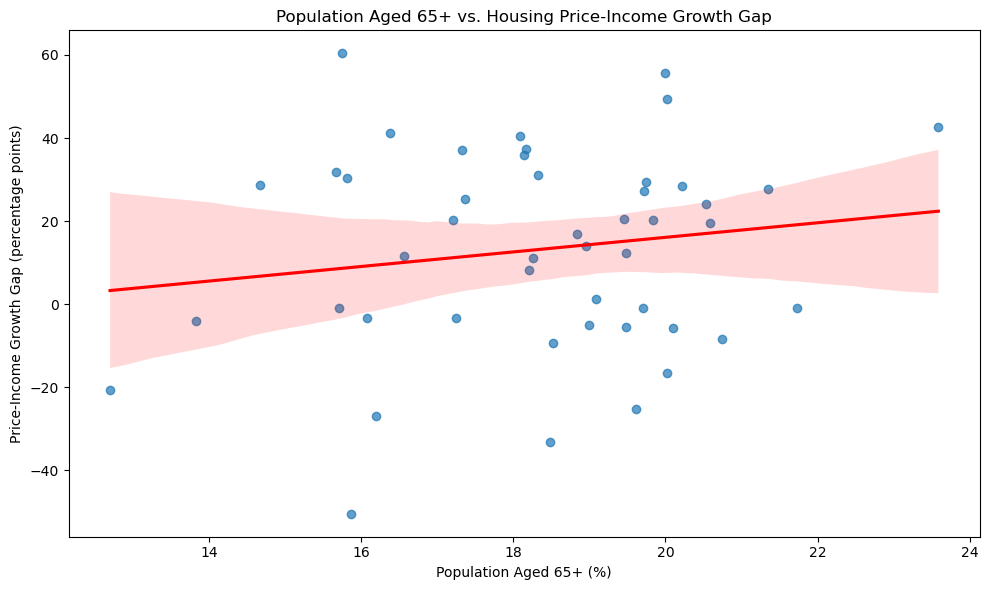

Spearman correlation: 0.035
P-value: 0.815136
Number of municipalities: 47


In [172]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=demographic_gap,
    x="share_population_65_plus",
    y="price_income_gap_pp",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("Population Aged 65+ vs. Housing Price-Income Growth Gap")
plt.xlabel("Population Aged 65+ (%)")
plt.ylabel("Price-Income Growth Gap (percentage points)")
plt.tight_layout()
plt.show()

rho, p_value = spearmanr(
    demographic_gap["share_population_65_plus"],
    demographic_gap["price_income_gap_pp"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Number of municipalities: {len(demographic_gap)}")


No relation

## Employment vs Housing price

In [173]:
# Economic activity is described for 2021-2025; for comparison with housing growth ending in 2023, use only the overlapping 2021-2023 observations.
# Summarize unemployment rates for the same 2021–2023 period, then combine with price growth.
unemployment_gap = (
    activity_analysis.loc[
        activity_analysis["year"].between(2021, 2023)
    ]
    .groupby("municipality", as_index=False)
    .agg(avg_unemployment_rate=("unemployment_rate", "mean"))
)

unemployment_price = (
    growth_by_municipality.reset_index()[
        ["municipality", "price_m2_growth_pct"]
    ]
    .merge(
        unemployment_gap[
            ["municipality", "avg_unemployment_rate"]
        ],
        on="municipality",
        how="inner",
        validate="one_to_one",
    )
)

print("Municipalities in unemployment-price analysis:", len(unemployment_price))
unemployment_price.head()


Municipalities in unemployment-price analysis: 47


,municipality,price_m2_growth_pct,avg_unemployment_rate
0,Badalona,37.809328,12.649609
1,Barberà del Vallès,65.272673,9.768450
2,Barcelona,60.758525,8.915049
3,Blanes,5.785696,15.638583
4,Calafell,45.996669,15.716387


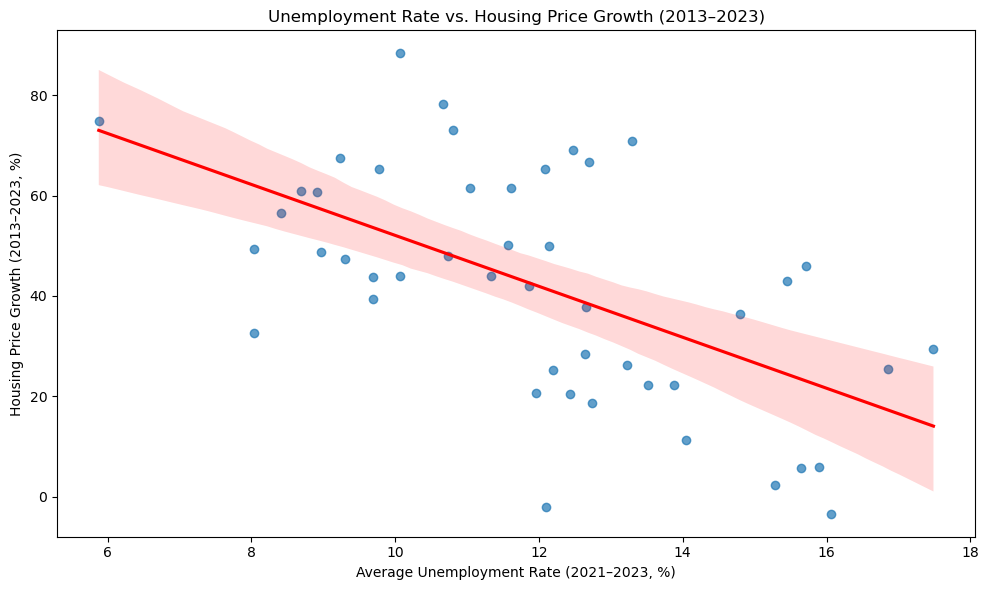

Spearman correlation: -0.574
P-value: 0.000025
Number of municipalities: 47


In [174]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=unemployment_price,
    x="avg_unemployment_rate",
    y="price_m2_growth_pct",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.title("Unemployment Rate vs. Housing Price Growth (2013–2023)")
plt.xlabel("Average Unemployment Rate (2021–2023, %)")
plt.ylabel("Housing Price Growth (2013–2023, %)")
plt.tight_layout()
plt.show()

rho, p_value = spearmanr(
    unemployment_price["avg_unemployment_rate"],
    unemployment_price["price_m2_growth_pct"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Number of municipalities: {len(unemployment_price)}")


### Results and Interpretation

The Spearman correlation (-0.574) shows a moderate negative association between unemployment rates and housing price growth.

Municipalities with higher unemployment rates tended to experience lower housing price growth between 2013 and 2023.

## OVERVIEW

In [175]:
# Top 5 municipalities by housing price growth
print("Highest housing price growth:")
display(
    growth_by_municipality
    .sort_values("property_price_growth_pct", ascending=False)
    .head(5)
)

# Bottom 5 municipalities by housing price growth
print("Lowest housing price growth:")
display(
    growth_by_municipality
    .sort_values("property_price_growth_pct", ascending=True)
    .head(5)
)


Highest housing price growth:


,price_total_k_eur_2013,price_total_k_eur_2023,price_m2_2013,price_m2_2023,income_2013,income_2023,property_price_growth_pct,price_m2_growth_pct,income_growth_pct,price_income_gap_pp
municipality,,,,,,,,,,
Vic,90.46057,179.64891,1052.43,1981.87,15250.0,19508.0,98.593608,88.313712,27.921311,60.392401
Esplugues de Llobregat,216.05145,396.58076,2470.56,4136.81,18375.0,22939.0,83.558481,67.444223,24.838095,42.606128
Terrassa,91.74825,165.79895,1179.44,1993.34,15084.0,19895.0,80.710749,69.007326,31.894723,37.112603
Cornellà de Llobregat,99.57899,176.99995,1555.25,2691.58,15519.0,19180.0,77.748288,73.064138,23.590438,49.473700
Mataró,113.14168,194.31069,1355.86,2317.20,13840.0,18465.0,71.741033,70.902601,33.417630,37.484971


Lowest housing price growth:


,price_total_k_eur_2013,price_total_k_eur_2023,price_m2_2013,price_m2_2023,income_2013,income_2023,property_price_growth_pct,price_m2_growth_pct,income_growth_pct,price_income_gap_pp
municipality,,,,,,,,,,
Lloret de Mar,172.64076,162.85892,2155.95,2083.45,9525.0,14009.0,-5.666008,-3.362787,47.076115,-50.438902
Salt,97.20110,94.86269,1076.61,1141.32,10769.0,13633.0,-2.405744,6.010533,26.594856,-20.584323
Lleida,112.32304,113.90710,1240.29,1216.08,14500.0,19018.0,1.410272,-1.951963,31.158621,-33.110584
Montcada i Reixac,148.87036,154.81101,1605.80,1935.58,15300.0,18591.0,3.990485,20.536804,21.509804,-0.973000
Blanes,151.53253,157.69005,2094.13,2215.29,12785.0,16740.0,4.063497,5.785696,30.934689,-25.148993


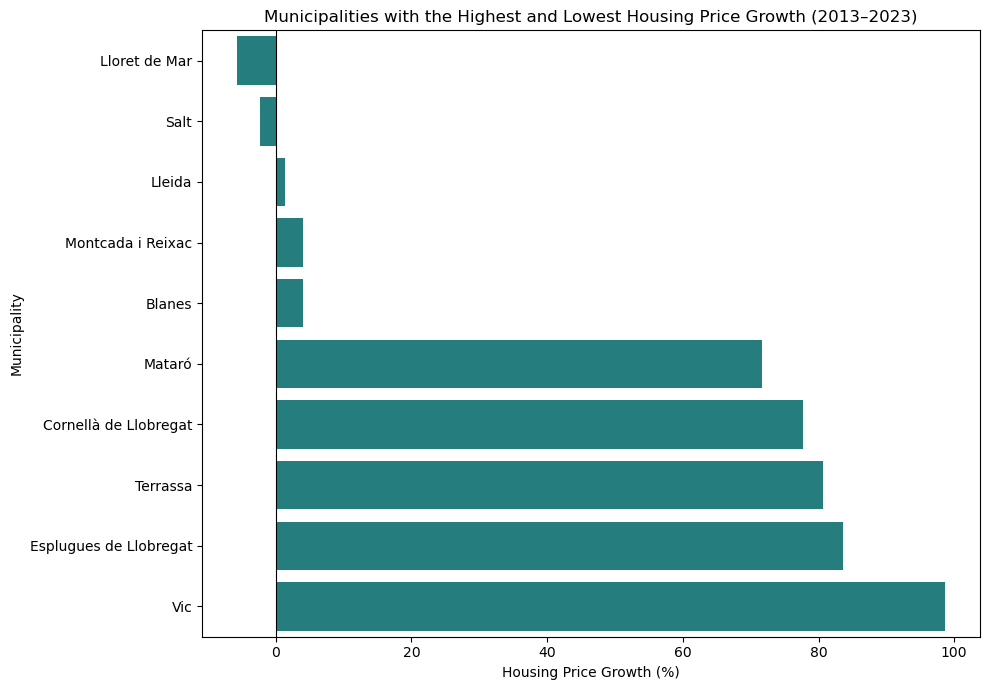

In [176]:
import matplotlib.pyplot as plt
import seaborn as sns

growth_data = growth_by_municipality.reset_index()

top_5 = growth_data.nlargest(5, "property_price_growth_pct")
bottom_5 = growth_data.nsmallest(5, "property_price_growth_pct")

extreme_municipalities = (
    __import__("pandas").concat([top_5, bottom_5])
    .sort_values("property_price_growth_pct")
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=extreme_municipalities,
    x="property_price_growth_pct",
    y="municipality",
    color="#168C8C",
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Municipalities with the Highest and Lowest Housing Price Growth (2013–2023)")
plt.xlabel("Housing Price Growth (%)")
plt.ylabel("Municipality")
plt.tight_layout()
plt.show()


## Hypothesis Testing: Income vs. Housing Prices

**Research question:** Is there a statistically significant association between income per capita and housing prices per square metre across the 47 municipalities from 2013 to 2023?

- **H₀ (Null hypothesis):** There is no monotonic association between income per capita and housing prices per square metre.
- **H₁ (Alternative hypothesis):** There is a monotonic association between income per capita and housing prices per square metre.

**Variables:**
- Income per capita (`income_per_capita_eur`)
- Average housing price per square metre (`price_m2_total`)

**Method:** Spearman's rank correlation test, using a significance level of α = 0.05.

The test evaluates the strength and direction of the association between the variables. It does not establish causation.

In [177]:
from scipy.stats import spearmanr

# Select observations with valid values
df_test = bivariate_analysis[
    ["income_per_capita_eur", "price_m2_total"]
].dropna()

# Spearman correlation test
rho, p_value = spearmanr(
    df_test["income_per_capita_eur"],
    df_test["price_m2_total"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Number of observations: {len(df_test)}")


Spearman correlation: 0.679
P-value: 0.000000
Number of observations: 517


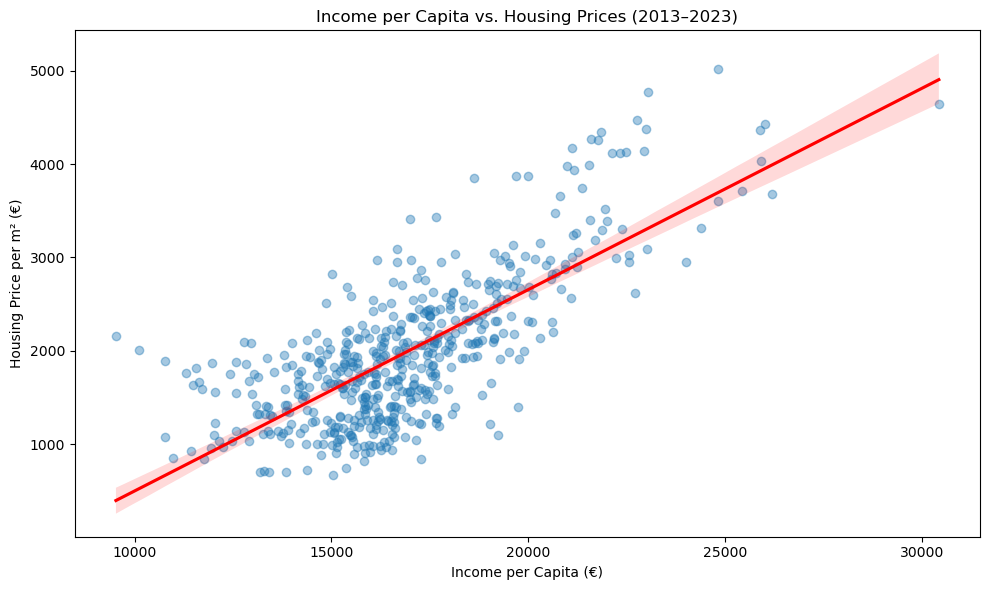

In [178]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.regplot(
    data=bivariate_analysis,
    x="income_per_capita_eur",
    y="price_m2_total",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Income per Capita vs. Housing Prices (2013–2023)")
plt.xlabel("Income per Capita (€)")
plt.ylabel("Housing Price per m² (€)")
plt.tight_layout()
plt.show()


* There gap between income and house pricing is growing over the years. So probably the dificulty of buying a house will increse for most of the people. 

## Hypothesis Testing: Distance to Barcelona and Housing Price-Income Gap

**Research question:** Is distance to Barcelona associated with the housing price-income growth gap across the 47 municipalities (2013–2023)?

- **H₀:** There is no monotonic association between the two variables.
- **H₁:** There is a monotonic association between the two variables.

**Method:** Spearman's rank correlation test, with a significance level of α = 0.05.

The test identifies an association, not causation.


In [179]:
# Select variables and remove missing values
test_data = (
    growth_distance[
        ["distance_to_barcelona_km", "price_income_gap_pp"]
    ]
    .dropna()
)

# Spearman correlation hypothesis test
rho, p_value = spearmanr(
    test_data["distance_to_barcelona_km"],
    test_data["price_income_gap_pp"]
)

print(f"Number of municipalities: {len(test_data)}")
print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Result: Reject the null hypothesis (H0).")
else:
    print("Result: Fail to reject the null hypothesis (H0).")


Number of municipalities: 47
Spearman correlation: -0.573
P-value: 0.0000
Result: Reject the null hypothesis (H0).


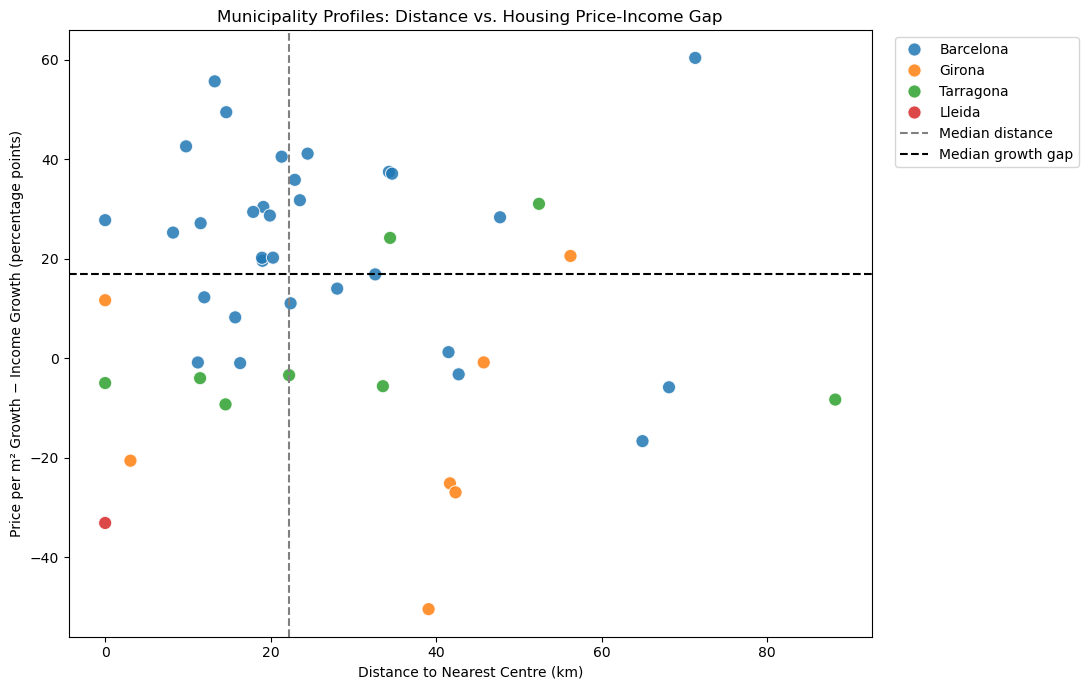

Median distance: 22.23 km
Median growth gap: 16.87 percentage points


In [180]:
plot_data = growth_distance.dropna(
    subset=[
        "nearest_centre_distance_km",
        "price_income_gap_pp"
    ]
).copy()

# Median thresholds
distance_median = plot_data["nearest_centre_distance_km"].median()
gap_median = plot_data["price_income_gap_pp"].median()

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_data,
    x="nearest_centre_distance_km",
    y="price_income_gap_pp",
    hue="nearest_centre",
    s=90,
    alpha=0.85
)

plt.axvline(
    distance_median,
    color="gray",
    linestyle="--",
    label="Median distance"
)

plt.axhline(
    gap_median,
    color="black",
    linestyle="--",
    label="Median growth gap"
)

plt.title("Municipality Profiles: Distance vs. Housing Price-Income Gap")
plt.xlabel("Distance to Nearest Centre (km)")
plt.ylabel("Price per m² Growth − Income Growth (percentage points)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Median distance:", round(distance_median, 2), "km")
print("Median growth gap:", round(gap_median, 2), "percentage points")


* The price of the properties relies on the distance to Barcelona center. 

# RENT VS BUY

In [181]:
# Calculate annual average housing purchase and rental prices
purchase_rent_trend = (
    housing_analysis
    .groupby("year", as_index=False)
    .agg(
        purchase_price_m2=("price_m2_total", "mean"),
        rent_mean=("rent_mean", "mean")
    )
)

# Calculate year-over-year growth rates
purchase_rent_trend["purchase_growth_pct"] = (
    purchase_rent_trend["purchase_price_m2"].pct_change() * 100
)

purchase_rent_trend["rent_growth_pct"] = (
    purchase_rent_trend["rent_mean"].pct_change() * 100
)

purchase_rent_trend


,year,purchase_price_m2,rent_mean,purchase_growth_pct,rent_growth_pct
0,2013,1686.979149,505.120368,NaN,NaN
1,2014,1591.356596,500.350692,-5.668271,-0.944265
2,2015,1616.086170,514.039900,1.553993,2.735923
3,2016,1695.199149,542.885789,4.895344,5.611605
4,2017,1808.581915,584.368978,6.688463,7.641237
5,2018,1983.135957,624.211760,9.651431,6.818086
6,2019,2118.857234,659.368387,6.843771,5.632164
7,2020,2209.495106,671.274861,4.277677,1.805739
8,2021,2284.357872,651.237721,3.388230,-2.984938
9,2022,2391.527234,704.398777,4.691444,8.163080


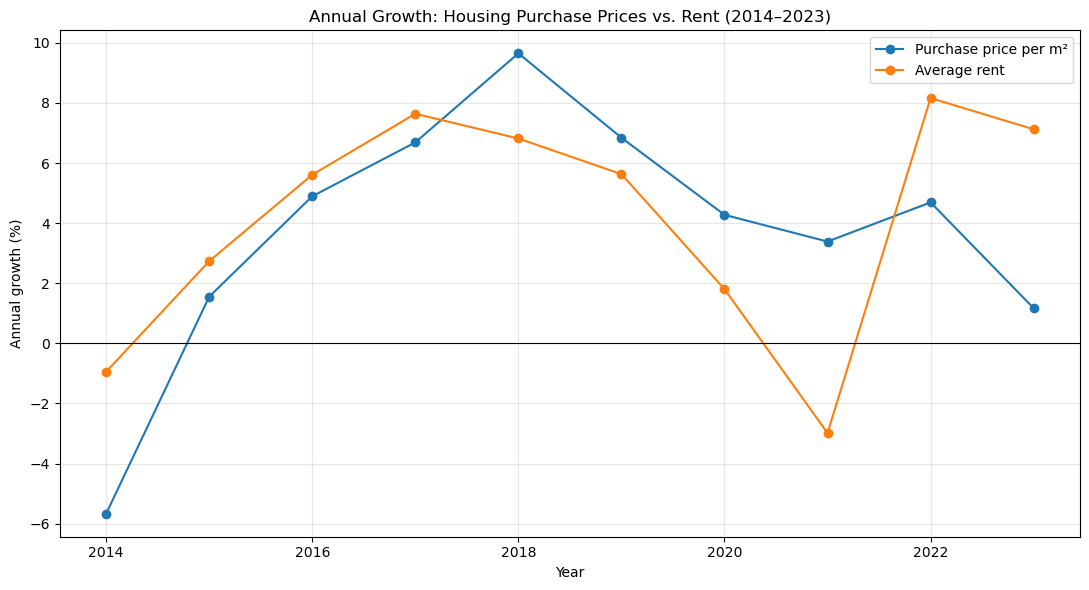

In [182]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    purchase_rent_trend["year"],
    purchase_rent_trend["purchase_growth_pct"],
    marker="o",
    label="Purchase price per m²"
)

plt.plot(
    purchase_rent_trend["year"],
    purchase_rent_trend["rent_growth_pct"],
    marker="o",
    label="Average rent"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Annual Growth: Housing Purchase Prices vs. Rent (2014–2023)")
plt.xlabel("Year")
plt.ylabel("Annual growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [183]:
# Calculate cumulative growth from 2013 to 2023
first_year = purchase_rent_trend.iloc[0]
last_year = purchase_rent_trend.iloc[-1]

purchase_cumulative_growth = (
    last_year["purchase_price_m2"] / first_year["purchase_price_m2"] - 1
) * 100

rent_cumulative_growth = (
    last_year["rent_mean"] / first_year["rent_mean"] - 1
) * 100

print(f"Purchase price growth (2013–2023): {purchase_cumulative_growth:.2f}%")
print(f"Average rent growth (2013–2023): {rent_cumulative_growth:.2f}%")


Purchase price growth (2013–2023): 43.43%
Average rent growth (2013–2023): 49.39%


In [184]:
# Compare purchase and rental data in 2013 and 2023
display(
    housing_analysis[
        housing_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])
    ][
        [
            "municipality",
            "year",
            "rent_mean",
            "price_m2_total",
            "surface_total"
        ]
    ].head(10)
)


,municipality,year,rent_mean,price_m2_total,surface_total
0,Badalona,2013,541.145986,1786.94,76.50
1,Barberà del Vallès,2013,542.971971,1398.38,94.89
2,Barcelona,2013,681.556675,2718.96,81.64
3,Blanes,2013,423.290241,2094.13,69.01
4,Calafell,2013,447.500489,1405.08,94.94
5,Cambrils,2013,473.170971,1845.55,85.77
6,Castelldefels,2013,694.069418,2560.56,96.21
7,Cerdanyola del Vallès,2013,578.802244,1984.90,99.72
8,Cornellà de Llobregat,2013,532.574978,1555.25,67.89
9,Esplugues de Llobregat,2013,671.422668,2470.56,83.55


In [185]:
# Select 2013 and 2023 observations
purchase_rent_ratio = housing_analysis[
    housing_analysis["year"].isin([ANALYSIS_START_YEAR, ANALYSIS_END_YEAR])
].copy()

# Estimate years of rent equivalent to the purchase price
purchase_rent_ratio["estimated_purchase_price"] = (
    purchase_rent_ratio["price_m2_total"]
    * purchase_rent_ratio["surface_total"]
)

purchase_rent_ratio["annual_rent"] = (
    purchase_rent_ratio["rent_mean"] * 12
)

purchase_rent_ratio["years_of_rent"] = (
    purchase_rent_ratio["estimated_purchase_price"]
    / purchase_rent_ratio["annual_rent"]
)

display(
    purchase_rent_ratio[
        [
            "municipality",
            "year",
            "estimated_purchase_price",
            "annual_rent",
            "years_of_rent"
        ]
    ].head(10)
)


,municipality,year,estimated_purchase_price,annual_rent,years_of_rent
0,Badalona,2013,136700.9100,6493.751837,21.051145
1,Barberà del Vallès,2013,132692.2782,6515.663650,20.365121
2,Barcelona,2013,221975.8944,8178.680097,27.140797
3,Blanes,2013,144515.9113,5079.482896,28.450910
4,Calafell,2013,133398.2952,5370.005864,24.841369
5,Cambrils,2013,158292.8235,5678.051654,27.878018
6,Castelldefels,2013,246351.4776,8328.833013,29.578151
7,Cerdanyola del Vallès,2013,197934.2280,6945.626923,28.497676
8,Cornellà de Llobregat,2013,105585.9225,6390.899731,16.521292
9,Esplugues de Llobregat,2013,206415.2880,8057.072018,25.619144


In [186]:
#PER metric (How many years of rent cost the house)


In [187]:
# Calculate the average estimated Price-to-Rent Ratio by year
per_general = (
    purchase_rent_ratio
    .groupby("year", as_index=False)
    .agg(
        mean_per=("years_of_rent", "mean"),
        median_per=("years_of_rent", "median")
    )
)

per_general["change_pct"] = (
    per_general["mean_per"].pct_change() * 100
)

display(per_general)


,year,mean_per,median_per,change_pct
0,2013,23.775394,22.737118,NaN
1,2023,22.350265,22.225562,-5.994132


In [188]:
# Calculate the estimated Price-to-Rent Ratio by municipality and year
per_annual = housing_analysis.copy()

per_annual["estimated_purchase_price"] = (
    per_annual["price_m2_total"] * per_annual["surface_total"]
)

per_annual["annual_rent"] = per_annual["rent_mean"] * 12

per_annual["years_of_rent"] = (
    per_annual["estimated_purchase_price"]
    / per_annual["annual_rent"]
)

# Calculate annual mean and median PER
per_annual_trend = (
    per_annual
    .groupby("year", as_index=False)
    .agg(
        mean_per=("years_of_rent", "mean"),
        median_per=("years_of_rent", "median")
    )
)

# Calculate annual change in the mean PER
per_annual_trend["annual_change_pct"] = (
    per_annual_trend["mean_per"].pct_change() * 100
)

display(per_annual_trend)


,year,mean_per,median_per,annual_change_pct
0,2013,23.775394,22.737118,NaN
1,2014,22.723006,22.406345,-4.426373
2,2015,22.280304,20.954185,-1.948255
3,2016,21.836402,21.184103,-1.992351
4,2017,21.576538,20.873816,-1.190051
5,2018,22.084660,20.956509,2.354975
6,2019,22.420902,22.249459,1.522513
7,2020,23.651125,23.393111,5.486947
8,2021,25.377589,24.787407,7.299713
9,2022,24.387623,23.830607,-3.900945


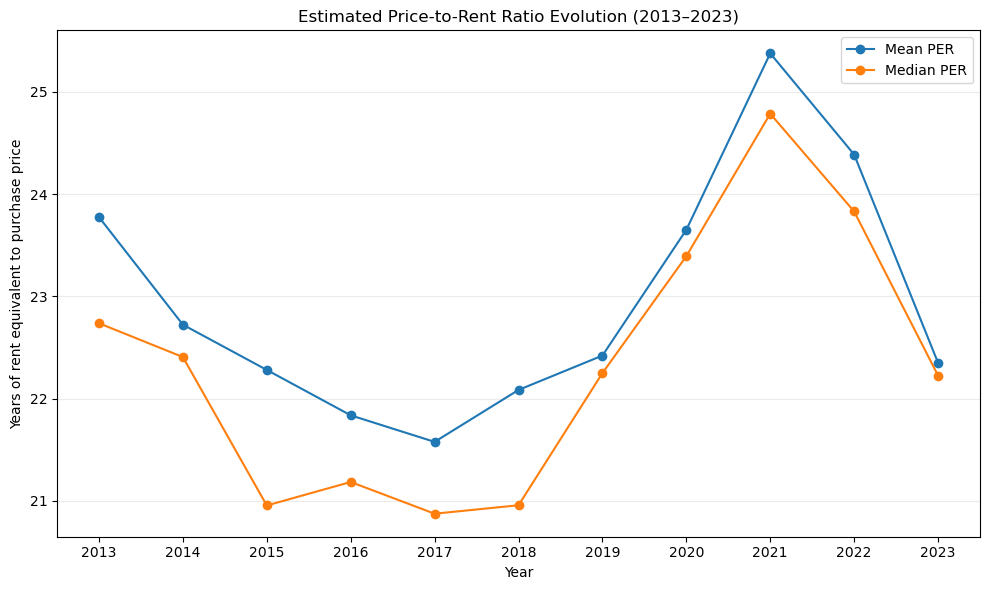

In [189]:
# Visualize the annual estimated Price-to-Rent Ratio (PER)
plt.figure(figsize=(10, 6))

plt.plot(
    per_annual_trend["year"],
    per_annual_trend["mean_per"],
    marker="o",
    label="Mean PER",
)

plt.plot(
    per_annual_trend["year"],
    per_annual_trend["median_per"],
    marker="o",
    label="Median PER",
)

plt.title("Estimated Price-to-Rent Ratio Evolution (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Years of rent equivalent to purchase price")
plt.xticks(per_annual_trend["year"])
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


In [190]:
# Compare Barcelona city with the other municipalities
per_annual["area"] = per_annual["municipality"].apply(
    lambda x: "Barcelona" if x == "Barcelona" else "Rest of municipalities"
)

per_barcelona_comparison = (
    per_annual
    .groupby(["year", "area"], as_index=False)
    .agg(mean_per=("years_of_rent", "mean"))
)

display(per_barcelona_comparison.head(6))


,year,area,mean_per
0,2013,Barcelona,27.140797
1,2013,Rest of municipalities,23.702233
2,2014,Barcelona,27.715330
3,2014,Rest of municipalities,22.614477
4,2015,Barcelona,27.542283
5,2015,Rest of municipalities,22.165913


In [191]:
# Compare the estimated Price-to-Rent Ratio by municipality
per_by_municipality = (
    purchase_rent_ratio
    .pivot(
        index="municipality",
        columns="year",
        values="years_of_rent"
    )
    .reset_index()
)

per_by_municipality["change_years"] = (
    per_by_municipality[ANALYSIS_END_YEAR] - per_by_municipality[ANALYSIS_START_YEAR]
)

per_by_municipality["change_pct"] = (
    per_by_municipality["change_years"]
    / per_by_municipality[ANALYSIS_START_YEAR]
    * 100
)

print("Largest increases in PER:")
display(
    per_by_municipality
    .sort_values("change_pct", ascending=False)
    .head(5)
)

print("Largest decreases in PER:")
display(
    per_by_municipality
    .sort_values("change_pct", ascending=True)
    .head(5)
)


Largest increases in PER:


year,municipality,2013,2023,change_years,change_pct
43,Vic,18.010159,24.132995,6.122836,33.996571
20,Mollet del Vallès,16.801621,21.996949,5.195327,30.921584
24,"Prat de Llobregat, el",19.395980,23.974453,4.578473,23.605269
40,Terrassa,18.170284,21.449488,3.279204,18.047069
19,Mataró,18.899326,21.966746,3.067421,16.230317


Largest decreases in PER:


year,municipality,2013,2023,change_years,change_pct
16,Lleida,23.948057,16.764209,-7.183848,-29.997623
17,Lloret de Mar,34.962432,24.531480,-10.430952,-29.834744
30,Salt,19.712121,14.477027,-5.235094,-26.557742
18,Manresa,19.641476,14.689296,-4.952179,-25.212869
35,Sant Joan Despí,24.336083,18.424003,-5.912080,-24.293475


In [192]:
display(
    per_by_municipality[
        ["municipality", "change_pct"]
    ]
    .sort_values("change_pct", ascending=False)
    .head()
)


year,municipality,change_pct
43,Vic,33.996571
20,Mollet del Vallès,30.921584
24,"Prat de Llobregat, el",23.605269
40,Terrassa,18.047069
19,Mataró,16.230317


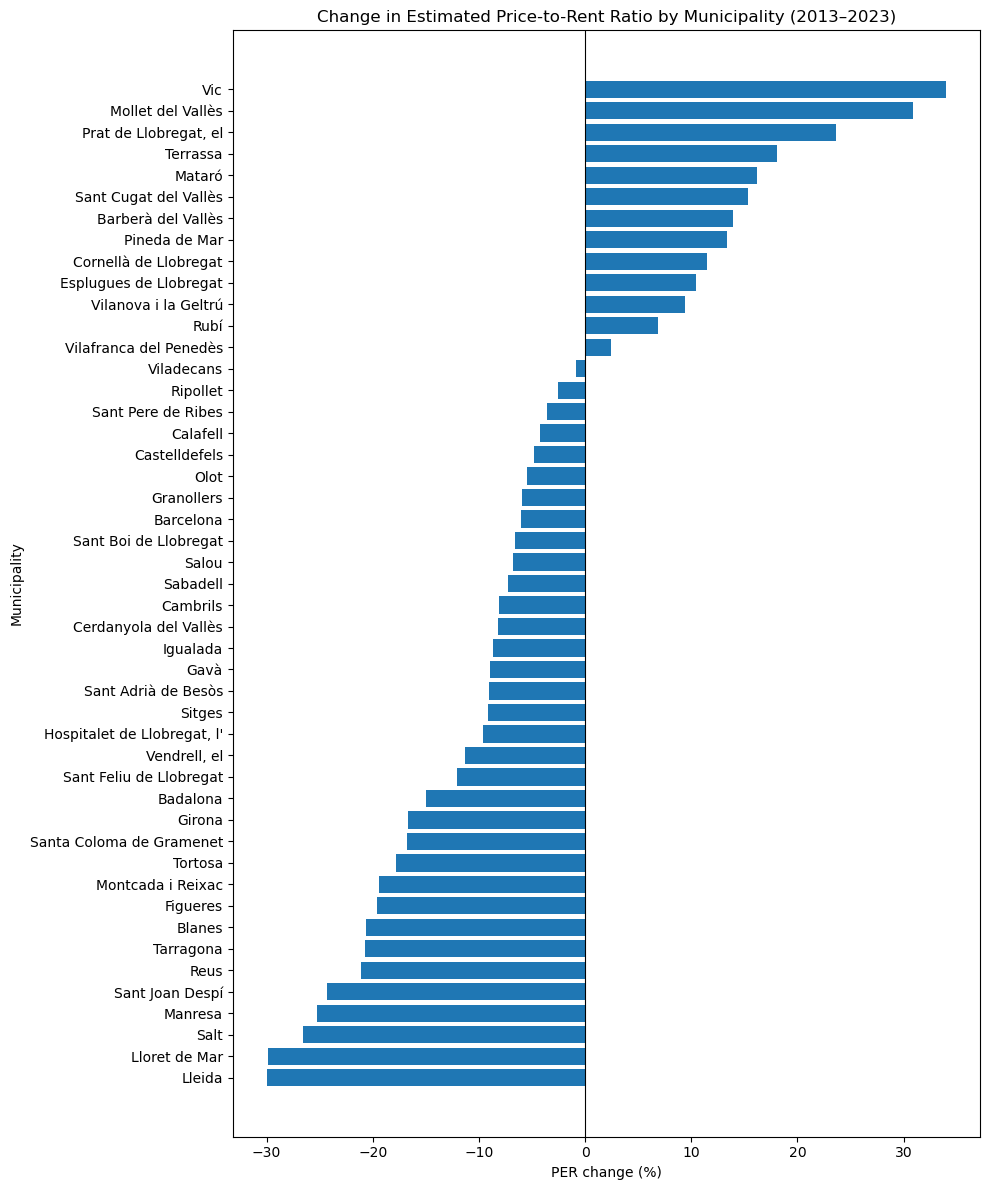

In [193]:
import matplotlib.pyplot as plt

plot_data = per_by_municipality.sort_values("change_pct")

plt.figure(figsize=(10, 12))

plt.barh(
    plot_data["municipality"],
    plot_data["change_pct"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Change in Estimated Price-to-Rent Ratio by Municipality (2013–2023)")
plt.xlabel("PER change (%)")
plt.ylabel("Municipality")
plt.tight_layout()
plt.show()


## Housing Costs Relative to Income

The following indices compare the evolution of housing costs with income per capita. They are relative indicators, not direct estimates of household expenditure or mortgage affordability. Income data are available through 2023, so this section ends in 2023. Coverage is reported by year and is not artificially harmonised.


In [194]:
# Relative housing-cost indicators for municipality-years with income data.
affordability_analysis = housing_analysis.loc[
    housing_analysis["income_per_capita_eur"].notna()
].copy()

affordability_analysis["purchase_cost_income_index"] = (
    affordability_analysis["price_m2_total"]
    / affordability_analysis["income_per_capita_eur"]
)

affordability_analysis["rental_cost_income_index"] = (
    affordability_analysis["rent_mean"] * 12
    / affordability_analysis["income_per_capita_eur"]
)

display(
    affordability_analysis[
        ["municipality", "year", "purchase_cost_income_index", "rental_cost_income_index"]
    ].head()
)


,municipality,year,purchase_cost_income_index,rental_cost_income_index
0,Badalona,2013,0.117377,0.426547
1,Barberà del Vallès,2013,0.086845,0.404649
2,Barcelona,2013,0.139620,0.419979
3,Blanes,2013,0.163796,0.397300
4,Calafell,2013,0.105320,0.402519


In [195]:
# Annual mean of municipal relative-cost indicators; coverage may vary by year.
annual_affordability_comparison = (
    affordability_analysis
    .groupby("year", as_index=False)
    .agg(
        purchase_cost_income_index=("purchase_cost_income_index", "mean"),
        rental_cost_income_index=("rental_cost_income_index", "mean"),
        municipalities=("municipality", "nunique")
    )
    .sort_values("year")
)

baseline_rows = annual_affordability_comparison.loc[
    annual_affordability_comparison["year"] == ANALYSIS_START_YEAR
]
if baseline_rows.empty:
    raise ValueError("The 2013 baseline is missing from the income-linked data.")
baseline = baseline_rows.iloc[0]

annual_affordability_comparison["purchase_change_pct"] = (
    annual_affordability_comparison["purchase_cost_income_index"]
    / baseline["purchase_cost_income_index"] - 1
) * 100

annual_affordability_comparison["rental_change_pct"] = (
    annual_affordability_comparison["rental_cost_income_index"]
    / baseline["rental_cost_income_index"] - 1
) * 100

display(
    annual_affordability_comparison.style.format({
        "purchase_cost_income_index": "{:.4f}",
        "rental_cost_income_index": "{:.4f}",
        "purchase_change_pct": "{:+.2f}%",
        "rental_change_pct": "{:+.2f}%",
        "municipalities": "{:.0f}"
    })
)


,year,purchase_cost_income_index,rental_cost_income_index,municipalities,purchase_change_pct,rental_change_pct
0,2013,0.1117,0.4003,47,+0.00%,+0.00%
1,2014,0.1033,0.3900,47,-7.46%,-2.57%
2,2015,0.1005,0.3846,47,-9.99%,-3.93%
3,2016,0.1026,0.3965,47,-8.16%,-0.97%
4,2017,0.1077,0.4205,47,-3.55%,+5.03%
5,2018,0.1164,0.4441,47,+4.27%,+10.92%
6,2019,0.1194,0.4505,47,+6.90%,+12.53%
7,2020,0.1292,0.4756,47,+15.71%,+18.79%
8,2021,0.1266,0.4365,47,+13.32%,+9.03%
9,2022,0.1293,0.4613,47,+15.81%,+15.22%


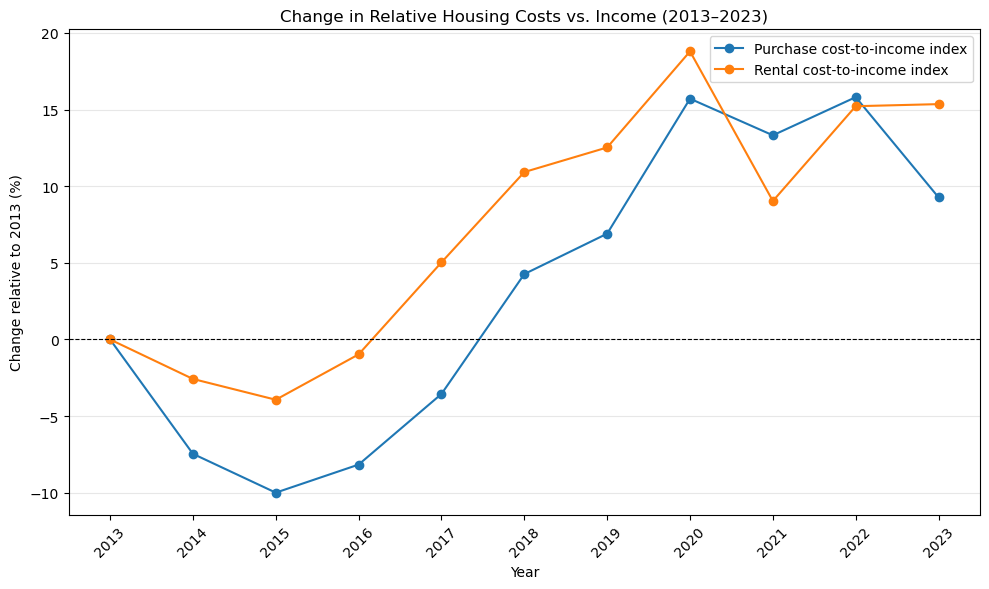

In [196]:
plt.figure(figsize=(10, 6))

plt.plot(
    annual_affordability_comparison["year"],
    annual_affordability_comparison["purchase_change_pct"],
    marker="o",
    label="Purchase cost-to-income index"
)

plt.plot(
    annual_affordability_comparison["year"],
    annual_affordability_comparison["rental_change_pct"],
    marker="o",
    label="Rental cost-to-income index"
)

plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Change in Relative Housing Costs vs. Income (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Change relative to 2013 (%)")
plt.xticks(annual_affordability_comparison["year"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Housing Costs Relative to Income (2013–2023)

The analysis compares municipal purchase and rental cost-to-income indices, using 2013 as the baseline. The purchase index is the average sale price per square metre divided by income per capita; the rental index is annual rent divided by income per capita. Their changes over time can be compared, but their absolute values should not be interpreted as the percentage of household income spent on housing.

### Interpretation

The saved results indicate that both relative-cost indices were above their 2013 baselines by 2023. The price per square metre increased by approximately 43%, compared with approximately 29% for income per capita. This supports the descriptive conclusion that purchase prices rose faster than income across the analysed sample. The rental index also ended the period above its baseline, indicating that annual rents grew relative to income.

### Limitations

Income per capita is not household disposable income. The indicators do not account for household composition, dwelling size, mortgage interest, down payments, taxes, maintenance or other housing costs. Annual municipal coverage may vary according to source availability; the number of municipalities is therefore reported for each year rather than forcing a common coverage. The results describe relative price and income trends, not the financial experience of every household.


## Mortgages

In [197]:

# Compare annual home sales and mortgages (2013–2023)

# Total sales across the 47 municipalities
sales_by_year = (
    sales_analysis
    .groupby("year", as_index=False)
    .agg(sales_total=("sales_total", "sum"))
)

# Keep mortgage data for the same period
mortgages_by_year = (
    mortgages_analysis[
        mortgages_analysis["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
    ][["year", "mortgages_estimated", "capital_billion_eur"]]
    .copy()
)

# Merge both datasets by year
sales_mortgages_comparison = (
    sales_by_year
    .merge(
        mortgages_by_year,
        on="year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("year")
)

# Normalize indicators to 2013 = 100
metrics = [
    "sales_total",
    "mortgages_estimated",
    "capital_billion_eur"
]

for col in metrics:
    baseline = sales_mortgages_comparison.loc[
        sales_mortgages_comparison["year"] == ANALYSIS_START_YEAR, col
    ]

    if baseline.empty or baseline.iloc[0] == 0:
        raise ValueError(f"Missing or invalid 2013 baseline: {col}")

    sales_mortgages_comparison[f"{col}_index"] = (
        sales_mortgages_comparison[col] / baseline.iloc[0] * 100
    )

display(sales_mortgages_comparison.round(2))


,year,sales_total,mortgages_estimated,capital_billion_eur,sales_total_index,mortgages_estimated_index,capital_billion_eur_index
0,2013,28009,45200,5.9,100.00,100.00,100.00
1,2014,30122,43600,6.2,107.54,96.46,105.08
2,2015,35538,54300,8.1,126.88,120.13,137.29
3,2016,43368,60200,9.6,154.84,133.19,162.71
4,2017,50289,67000,10.8,179.55,148.23,183.05
5,2018,51682,75300,12.5,184.52,166.59,211.86
6,2019,50008,75000,13.3,178.54,165.93,225.42
7,2020,39237,71900,14.0,140.09,159.07,237.29
8,2021,52658,88700,16.0,188.00,196.24,271.19
9,2022,61867,101200,19.3,220.88,223.89,327.12


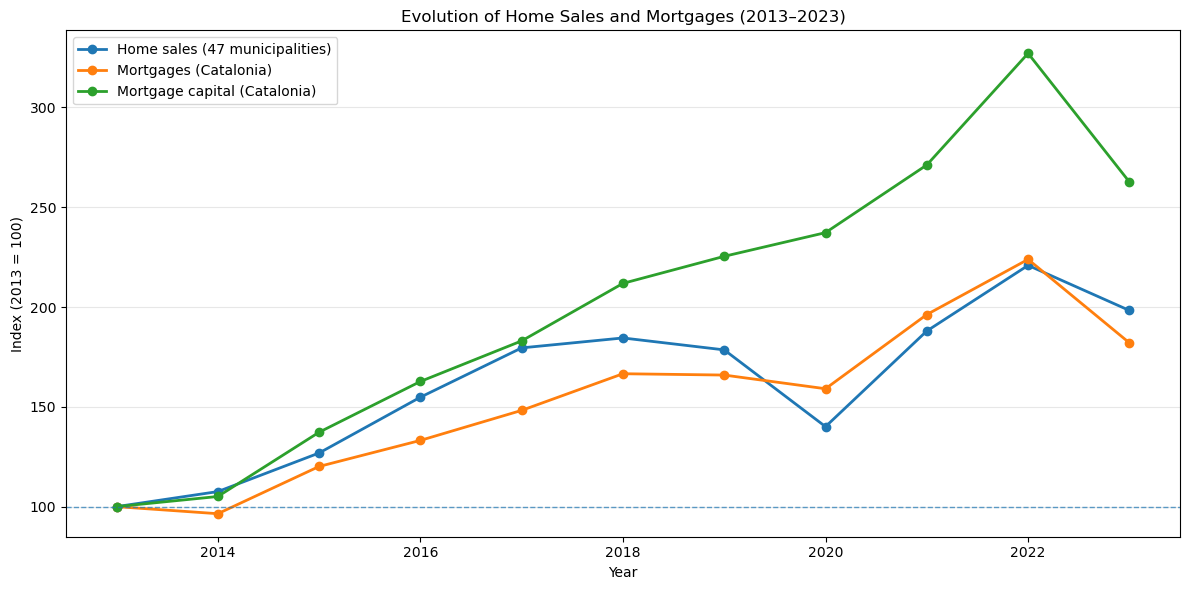

In [198]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

series = {
    "Home sales (47 municipalities)": "sales_total_index",
    "Mortgages (Catalonia)": "mortgages_estimated_index",
    "Mortgage capital (Catalonia)": "capital_billion_eur_index"
}

for label, col in series.items():
    ax.plot(
        sales_mortgages_comparison["year"],
        sales_mortgages_comparison[col],
        marker="o",
        linewidth=2,
        label=label
    )

ax.axhline(100, linestyle="--", linewidth=1, alpha=0.7)
ax.set_title("Evolution of Home Sales and Mortgages (2013–2023)")
ax.set_xlabel("Year")
ax.set_ylabel("Index (2013 = 100)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Mortgage Market Context: 2022 as a Turning Point

According to Fotocasa Pro (2026), 2022 marked a turning point in Spain's mortgage market. At the beginning of the year, historically low interest rates, a negative Euribor and strong competition among banks supported mortgage lending and housing purchases. From summer 2022, the European Central Bank began raising interest rates to control inflation, pushing the Euribor sharply upward.

These changes led to higher payments for variable-rate mortgages, stricter lending conditions and greater caution among buyers. In 2023, new mortgage lending declined temporarily, while fixed-rate mortgages became more prevalent as households sought greater payment stability.

This context suggests that mortgage activity is influenced not only by housing prices but also by interest rates and banks' lending conditions. However, the article does not establish that down-payment requirements decreased or that access to mortgage financing became more flexible during the period studied.

**Source:** Fotocasa Pro. (2026, February 24). *Cómo han evolucionado las hipotecas en España de 2022 a 2026*. https://blogprofesional.fotocasa.es/como-han-evolucionado-las-hipotecas-en-2022/

In [199]:

# Estimate monthly mortgage payments (2013–2023)
# Assumptions: 25-year term and constant monthly payments

# Approximate annual average mortgage rates for Spain (%)
# Calculated from quarterly averages published by Global Property Guide
annual_rates = {
    2013: 3.04,
    2014: 2.96,
    2015: 2.25,
    2016: 2.01,
    2017: 1.95,
    2018: 1.97,
    2019: 1.99,
    2020: 1.73,
    2021: 1.49,
    2022: 1.98,
    2023: 3.75
}

mortgage_payment_analysis = mortgages_analysis[
    mortgages_analysis["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
][["year", "average_mortgage_eur"]].copy()

mortgage_payment_analysis["interest_rate_pct"] = (
    mortgage_payment_analysis["year"].map(annual_rates)
)

# Mortgage assumptions
loan_term_years = 25
number_of_months = loan_term_years * 12

# Convert annual interest rate to monthly rate
monthly_rate = (
    mortgage_payment_analysis["interest_rate_pct"] / 100 / 12
)

# Calculate monthly payment (principal + interest)
mortgage_payment_analysis["monthly_payment_eur"] = (
    mortgage_payment_analysis["average_mortgage_eur"]
    * monthly_rate
    / (1 - (1 + monthly_rate) ** (-number_of_months))
)

# Total paid and interest over the full term
mortgage_payment_analysis["total_paid_eur"] = (
    mortgage_payment_analysis["monthly_payment_eur"]
    * number_of_months
)

mortgage_payment_analysis["total_interest_eur"] = (
    mortgage_payment_analysis["total_paid_eur"]
    - mortgage_payment_analysis["average_mortgage_eur"]
)

display(
    mortgage_payment_analysis.round(2)
)


,year,average_mortgage_eur,interest_rate_pct,monthly_payment_eur,total_paid_eur,total_interest_eur
0,2013,130530.97,3.04,621.71,186513.51,55982.54
1,2014,142201.83,2.96,671.38,201414.72,59212.89
2,2015,149171.27,2.25,650.58,195174.51,46003.24
3,2016,159468.44,2.01,676.69,203007.16,43538.72
4,2017,161194.03,1.95,679.31,203793.27,42599.24
5,2018,166002.66,1.97,701.19,210356.25,44353.59
6,2019,177333.33,1.99,750.77,225231.59,47898.26
7,2020,194714.88,1.73,799.95,239985.93,45271.05
8,2021,180383.31,1.49,720.57,216171.35,35788.04
9,2022,190711.46,1.98,806.48,241944.95,51233.49


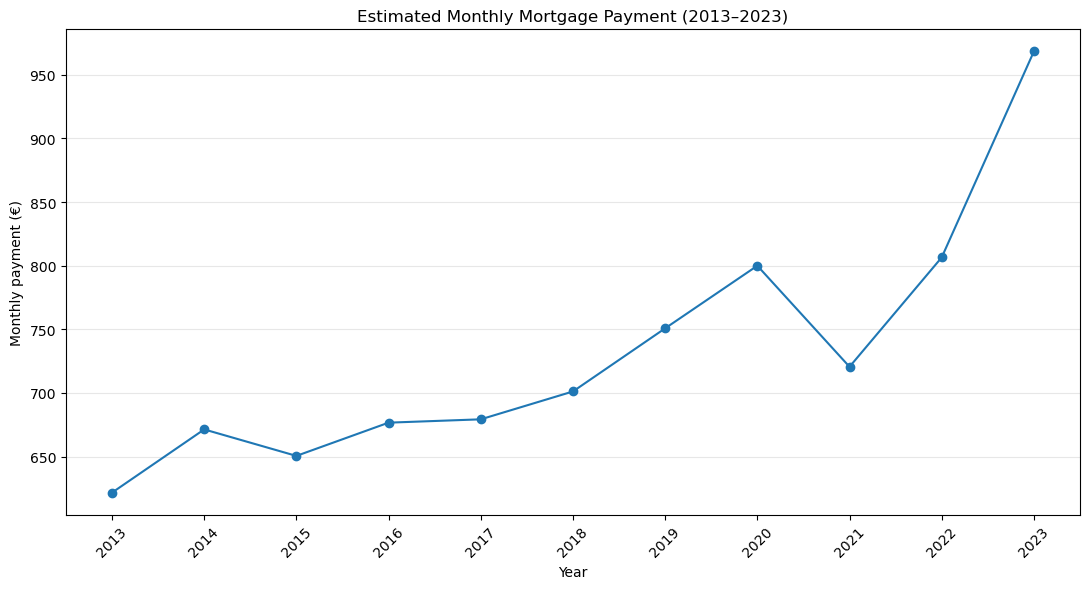

In [200]:

plt.figure(figsize=(11, 6))

plt.plot(
    mortgage_payment_analysis["year"],
    mortgage_payment_analysis["monthly_payment_eur"],
    marker="o"
)

plt.title("Estimated Monthly Mortgage Payment (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Monthly payment (€)")
plt.xticks(mortgage_payment_analysis["year"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [201]:

# Compare estimated monthly mortgage payments with rent

# Average monthly rent across the municipalities in the dataset
rent_by_year = (
    housing_analysis
    .groupby("year", as_index=False)
    .agg(mean_monthly_rent_eur=("rent_mean", "mean"))
)

# Keep mortgage payments and merge with rental data
mortgage_rent_comparison = (
    mortgage_payment_analysis[
        ["year", "monthly_payment_eur"]
    ]
    .merge(
        rent_by_year,
        on="year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("year")
)

# Absolute difference between estimated mortgage payment and rent
mortgage_rent_comparison["monthly_difference_eur"] = (
    mortgage_rent_comparison["monthly_payment_eur"]
    - mortgage_rent_comparison["mean_monthly_rent_eur"]
)

# Compare mortgage payment as a percentage of rent
mortgage_rent_comparison["mortgage_to_rent_pct"] = (
    mortgage_rent_comparison["monthly_payment_eur"]
    / mortgage_rent_comparison["mean_monthly_rent_eur"]
) * 100

display(mortgage_rent_comparison.round(2))


,year,monthly_payment_eur,mean_monthly_rent_eur,monthly_difference_eur,mortgage_to_rent_pct
0,2013,621.71,505.12,116.59,123.08
1,2014,671.38,500.35,171.03,134.18
2,2015,650.58,514.04,136.54,126.56
3,2016,676.69,542.89,133.80,124.65
4,2017,679.31,584.37,94.94,116.25
5,2018,701.19,624.21,76.98,112.33
6,2019,750.77,659.37,91.40,113.86
7,2020,799.95,671.27,128.68,119.17
8,2021,720.57,651.24,69.33,110.65
9,2022,806.48,704.40,102.08,114.49


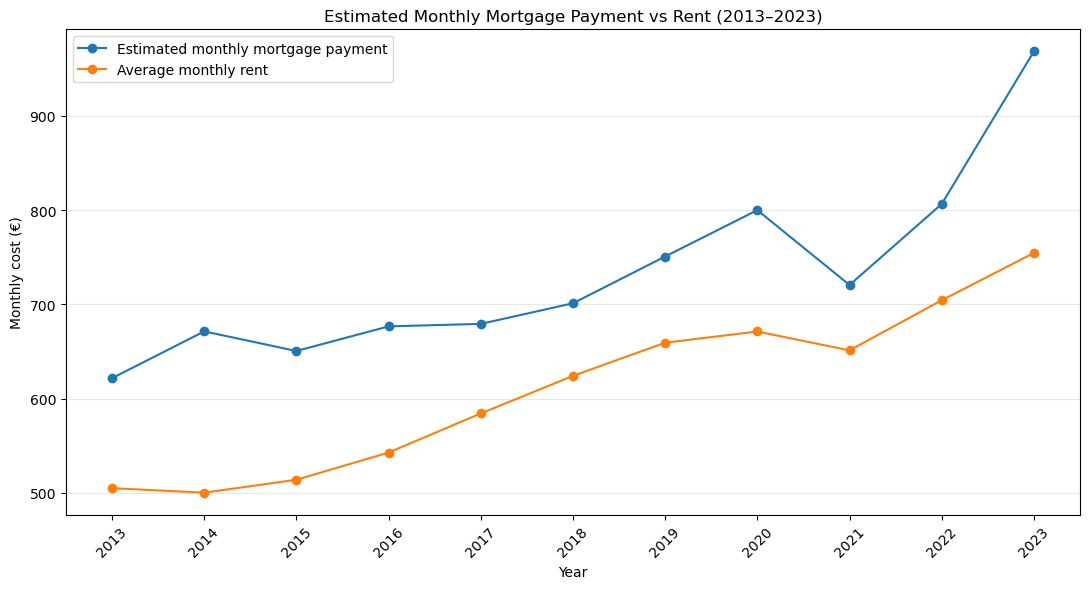

In [202]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    mortgage_rent_comparison["year"],
    mortgage_rent_comparison["monthly_payment_eur"],
    marker="o",
    label="Estimated monthly mortgage payment"
)

plt.plot(
    mortgage_rent_comparison["year"],
    mortgage_rent_comparison["mean_monthly_rent_eur"],
    marker="o",
    label="Average monthly rent"
)

plt.title("Estimated Monthly Mortgage Payment vs Rent (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Monthly cost (€)")
plt.xticks(mortgage_rent_comparison["year"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Recent evidence from the Banco de España suggests that mortgage lending conditions may become less favourable in the near term. In the second quarter of 2026, banks reported tighter credit standards and lower demand for housing loans. Market expectations also shifted towards higher policy interest rates in 2027, although future decisions remain dependent on inflation and economic developments.

These conditions could increase borrowing costs and make mortgage access more difficult for some households. However, higher interest rates do not necessarily imply falling house prices, particularly while housing supply remains constrained.

**Sources:** Banco de España (21 July 2026), *La oferta de crédito se endureció en el segundo trimestre de 2026 y la demanda siguió reduciéndose*; Banco de España (9 October 2026), *Proyecciones macroeconómicas e informe trimestral de la economía española. Tercer trimestre de 2026*.

In [203]:
# 1. Ingreso per cápita medio anual de los 47 municipios
income_by_year = (
    housing_analysis
    .groupby("year", as_index=False)
    .agg(income_per_capita_eur=("income_per_capita_eur", "mean"))
)

income_by_year["income_monthly_per_capita"] = (
    income_by_year["income_per_capita_eur"] / 12
)

# 2. Tipos de interés anuales utilizados anteriormente
interest_rates = {
    2013: 3.04, 2014: 2.96, 2015: 2.25,
    2016: 2.01, 2017: 1.95, 2018: 1.97,
    2019: 1.99, 2020: 1.73, 2021: 1.49,
    2022: 1.98, 2023: 3.75
}

mortgage_comparison = mortgages_analysis.copy()

mortgage_comparison["interest_rate_pct"] = (
    mortgage_comparison["year"].map(interest_rates)
)

# 3. Estimar la cuota mensual de una hipoteca a 25 años
monthly_rate = (
    mortgage_comparison["interest_rate_pct"] / 100 / 12
)
months = 25 * 12

mortgage_comparison["estimated_monthly_payment"] = (
    mortgage_comparison["average_mortgage_eur"]
    * monthly_rate
    / (1 - (1 + monthly_rate) ** (-months))
)

# 4. Unir hipoteca e ingresos por año
income_mortgage = income_by_year.merge(
    mortgage_comparison[
        ["year", "estimated_monthly_payment"]
    ],
    on="year",
    how="inner"
)

# 5. Indicadores de esfuerzo económico
income_mortgage["payment_to_income_1_person_pct"] = (
    income_mortgage["estimated_monthly_payment"]
    / income_mortgage["income_monthly_per_capita"] * 100
)

income_mortgage["payment_to_income_2_adults_pct"] = (
    income_mortgage["estimated_monthly_payment"]
    / (income_mortgage["income_monthly_per_capita"] * 2) * 100
)

income_mortgage.round(2)


,year,income_per_capita_eur,income_monthly_per_capita,estimated_monthly_payment,payment_to_income_1_person_pct,payment_to_income_2_adults_pct
0,2013,15114.49,1259.54,621.71,49.36,24.68
1,2014,15341.87,1278.49,671.38,52.51,26.26
2,2015,15946.66,1328.89,650.58,48.96,24.48
3,2016,16306.72,1358.89,676.69,49.80,24.90
4,2017,16520.17,1376.68,679.31,49.34,24.67
5,2018,16735.87,1394.66,701.19,50.28,25.14
6,2019,17451.49,1454.29,750.77,51.62,25.81
7,2020,16823.89,1401.99,799.95,57.06,28.53
8,2021,17781.30,1481.77,720.57,48.63,24.31
9,2022,18201.57,1516.80,806.48,53.17,26.59


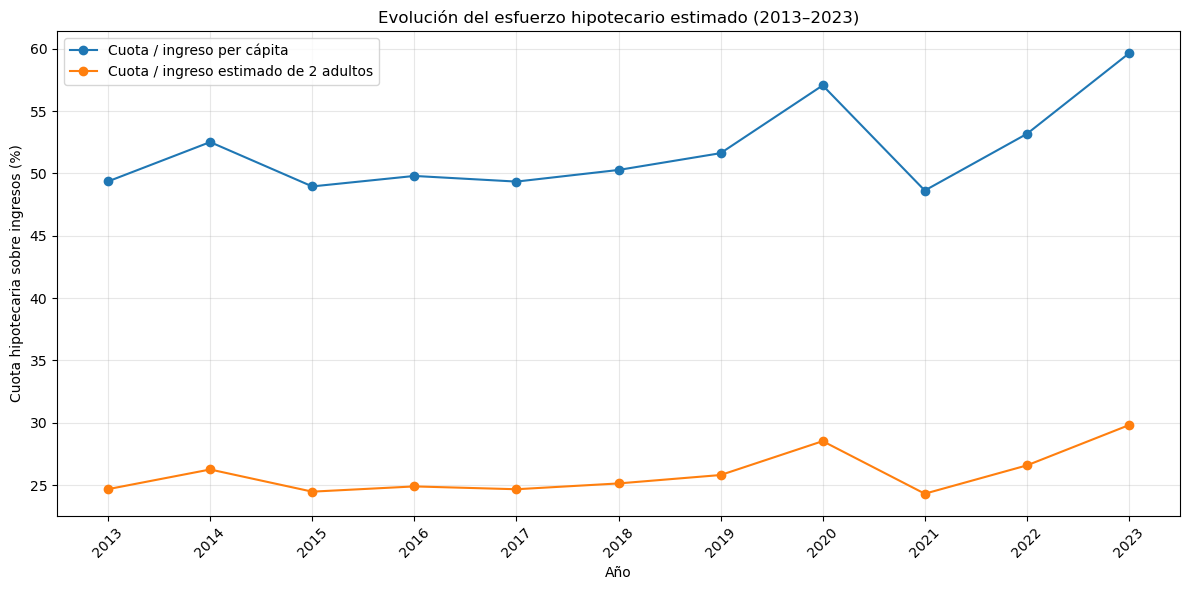

In [204]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    income_mortgage["year"],
    income_mortgage["payment_to_income_1_person_pct"],
    marker="o",
    label="Cuota / ingreso per cápita"
)

plt.plot(
    income_mortgage["year"],
    income_mortgage["payment_to_income_2_adults_pct"],
    marker="o",
    label="Cuota / ingreso estimado de 2 adultos"
)

plt.title("Evolución del esfuerzo hipotecario estimado (2013–2023)")
plt.xlabel("Año")
plt.ylabel("Cuota hipotecaria sobre ingresos (%)")
plt.xticks(income_mortgage["year"], rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [205]:

# Compare rental and mortgage affordability in Catalonia

rental_general = (
    affordability_analysis
    .groupby("year", as_index=False)
    .agg(
        average_monthly_rent=("rent_mean", "mean"),
        average_annual_income=("income_per_capita_eur", "mean")
    )
)

rental_general["rental_effort_pct"] = (
    rental_general["average_monthly_rent"]
    / (rental_general["average_annual_income"] / 12)
) * 100

mortgage_general = income_mortgage[
    ["year", "estimated_monthly_payment", "payment_to_income_1_person_pct"]
].copy()

affordability_general = rental_general.merge(
    mortgage_general,
    on="year",
    how="inner"
)

affordability_general = affordability_general.rename(
    columns={
        "payment_to_income_1_person_pct": "mortgage_effort_pct"
    }
)

display(affordability_general.round(2))



,year,average_monthly_rent,average_annual_income,rental_effort_pct,estimated_monthly_payment,mortgage_effort_pct
0,2013,505.12,15114.49,40.10,621.71,49.36
1,2014,500.35,15341.87,39.14,671.38,52.51
2,2015,514.04,15946.66,38.68,650.58,48.96
3,2016,542.89,16306.72,39.95,676.69,49.80
4,2017,584.37,16520.17,42.45,679.31,49.34
5,2018,624.21,16735.87,44.76,701.19,50.28
6,2019,659.37,17451.49,45.34,750.77,51.62
7,2020,671.27,16823.89,47.88,799.95,57.06
8,2021,651.24,17781.30,43.95,720.57,48.63
9,2022,704.40,18201.57,46.44,806.48,53.17


In [206]:

# Normalize rental and mortgage effort indices (2013 = 100)

affordability_general_index = affordability_general.copy()

base_year = affordability_general_index.loc[
    affordability_general_index["year"] == ANALYSIS_START_YEAR
].iloc[0]

affordability_general_index["rental_index"] = (
    affordability_general_index["rental_effort_pct"]
    / base_year["rental_effort_pct"]
) * 100

affordability_general_index["mortgage_index"] = (
    affordability_general_index["mortgage_effort_pct"]
    / base_year["mortgage_effort_pct"]
) * 100

display(
    affordability_general_index[
        ["year", "rental_index", "mortgage_index"]
    ].round(2)
)


,year,rental_index,mortgage_index
0,2013,100.00,100.00
1,2014,97.59,106.39
2,2015,96.46,99.18
3,2016,99.62,100.89
4,2017,105.85,99.97
5,2018,111.60,101.86
6,2019,113.06,104.59
7,2020,119.39,115.60
8,2021,109.59,98.52
9,2022,115.80,107.72


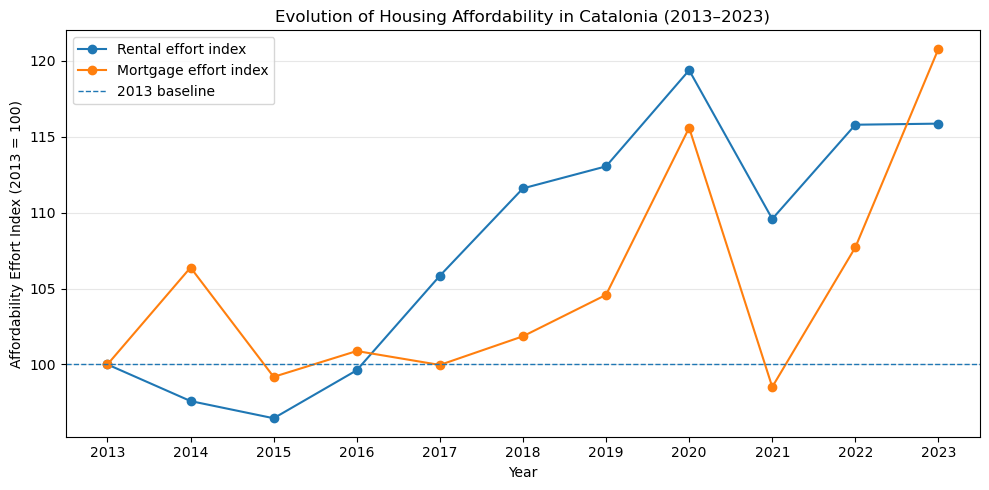

In [207]:
plt.figure(figsize=(10, 5))

plt.plot(
    affordability_general_index["year"],
    affordability_general_index["rental_index"],
    marker="o",
    label="Rental effort index"
)

plt.plot(
    affordability_general_index["year"],
    affordability_general_index["mortgage_index"],
    marker="o",
    label="Mortgage effort index"
)

plt.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    label="2013 baseline"
)

plt.title("Evolution of Housing Affordability in Catalonia (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Affordability Effort Index (2013 = 100)")
plt.xticks(affordability_general_index["year"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Housing Affordability Evolution in Catalonia (2013–2023)

The rental and mortgage effort indices show an overall deterioration in housing affordability between 2013 and 2023. Relative to the 2013 baseline, the rental effort index increased by **15.87%**, while the estimated mortgage effort index rose by **20.80%**.

Rental effort followed a more sustained upward trend from 2017, whereas mortgage effort fluctuated more substantially throughout the period, reaching its highest level in 2023.

These results suggest that both housing access options became more financially demanding relative to income. However, the comparison should be interpreted cautiously: rental effort is based on average rents across the 47 municipalities in the analysis, while mortgage effort relies on an estimated monthly payment and regional income data. The indices therefore compare relative trends rather than directly equivalent household costs.

## Affordability index
To have a simplified look up its important to take it into a simplee variable to see the evolution and try to predict the future. 
Also helps to understand opportunities so people can choose better.

In [208]:
# Compare municipality names using the canonical five-digit code from the first notebook.
sales_keys = (
    sales_analysis[["municipality_code", "municipality"]]
    .drop_duplicates()
)
income_keys = (
    income_analysis[["municipality_code", "municipality"]]
    .drop_duplicates()
)

municipality_matches = sales_keys.merge(
    income_keys,
    on="municipality_code",
    how="inner",
    suffixes=("_sales", "_income"),
    validate="one_to_one"
)

print("Matching municipalities:", len(municipality_matches))
print(
    "Different municipality names:",
    (
        municipality_matches["municipality_sales"]
        != municipality_matches["municipality_income"]
    ).sum()
)

municipality_matches.head(10)


Matching municipalities: 47
Different municipality names: 0


,municipality_code,municipality_sales,municipality_income
0,08015,Badalona,Badalona
1,08252,Barberà del Vallès,Barberà del Vallès
2,08019,Barcelona,Barcelona
3,17023,Blanes,Blanes
4,43037,Calafell,Calafell
5,43038,Cambrils,Cambrils
6,08056,Castelldefels,Castelldefels
7,08266,Cerdanyola del Vallès,Cerdanyola del Vallès
8,08073,Cornellà de Llobregat,Cornellà de Llobregat
9,08077,Esplugues de Llobregat,Esplugues de Llobregat


In [209]:
# Calculate the Price-to-Income Ratio using the canonical municipality_code directly.

sales_purchase = sales_analysis[
    ["municipality_code", "municipality", "year", "price_m2_total"]
].copy()

income_purchase = income_analysis[
    ["municipality_code", "year", "income_per_capita_eur"]
].copy()

purchase_affordability = sales_purchase.merge(
    income_purchase,
    on=["municipality_code", "year"],
    how="inner",
    validate="one_to_one"
)

purchase_affordability["estimated_dwelling_price_eur"] = (
    purchase_affordability["price_m2_total"] * 90
)

purchase_affordability["price_to_income_ratio"] = (
    purchase_affordability["estimated_dwelling_price_eur"]
    / purchase_affordability["income_per_capita_eur"]
)

print("Rows:", len(purchase_affordability))
print("Municipalities:", purchase_affordability["municipality"].nunique())
print(
    "Years:",
    purchase_affordability["year"].min(),
    "-",
    purchase_affordability["year"].max()
)

purchase_affordability[
    [
        "municipality",
        "year",
        "price_m2_total",
        "income_per_capita_eur",
        "price_to_income_ratio"
    ]
].head()


Rows: 517
Municipalities: 47
Years: 2013 - 2023


,municipality,year,price_m2_total,income_per_capita_eur,price_to_income_ratio
0,Badalona,2013,1786.94,15224.0,10.563886
1,Barberà del Vallès,2013,1398.38,16102.0,7.816060
2,Barcelona,2013,2718.96,19474.0,12.565801
3,Blanes,2013,2094.13,12785.0,14.741627
4,Calafell,2013,1405.08,13341.0,9.478840


In [210]:
# Calculate rental effort relative to monthly income per capita.
# The canonical municipality_code is used directly for the year-specific merge.

rental_data = rent_analysis[
    ["municipality_code", "municipality", "year", "rent_mean"]
].copy()

income_data = income_analysis[
    ["municipality_code", "year", "income_per_capita_eur"]
].copy()

rental_affordability = rental_data.merge(
    income_data,
    on=["municipality_code", "year"],
    how="inner",
    validate="one_to_one"
)

rental_affordability["income_monthly_per_capita"] = (
    rental_affordability["income_per_capita_eur"] / 12
)

rental_affordability["rental_effort_pct"] = (
    rental_affordability["rent_mean"]
    / rental_affordability["income_monthly_per_capita"]
) * 100

print("Rows:", len(rental_affordability))
print("Municipalities:", rental_affordability["municipality"].nunique())
print(
    "Years:",
    rental_affordability["year"].min(),
    "-",
    rental_affordability["year"].max()
)

rental_affordability[
    [
        "municipality",
        "year",
        "rent_mean",
        "income_per_capita_eur",
        "rental_effort_pct"
    ]
].head()


Rows: 517
Municipalities: 47
Years: 2013 - 2023


,municipality,year,rent_mean,income_per_capita_eur,rental_effort_pct
0,Badalona,2023,848.905793,19114.0,53.295331
1,Barberà del Vallès,2023,756.793780,20086.0,45.213210
2,Barcelona,2023,1136.399961,25898.0,52.655802
3,Blanes,2023,597.641958,16740.0,42.841717
4,Calafell,2023,679.071963,16248.0,50.153025


In [211]:
# Inspect the mortgage affordability indicators

mortgage_affordability = income_mortgage[
    [
        "year",
        "income_per_capita_eur",
        "estimated_monthly_payment",
        "payment_to_income_1_person_pct",
        "payment_to_income_2_adults_pct"
    ]
].copy()

mortgage_affordability = mortgage_affordability[
    mortgage_affordability["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].sort_values("year")

print("Rows:", len(mortgage_affordability))
print(
    "Years:",
    mortgage_affordability["year"].min(),
    "-",
    mortgage_affordability["year"].max()
)

mortgage_affordability


Rows: 11
Years: 2013 - 2023


,year,income_per_capita_eur,estimated_monthly_payment,payment_to_income_1_person_pct,payment_to_income_2_adults_pct
0,2013,15114.489362,621.711715,49.360189,24.680095
1,2014,15341.872340,671.382407,52.513727,26.256863
2,2015,15946.659574,650.581697,48.956838,24.478419
3,2016,16306.723404,676.690528,49.797167,24.898584
4,2017,16520.170213,679.310909,49.344110,24.672055
5,2018,16735.872340,701.187495,50.276734,25.138367
6,2019,17451.489362,750.771982,51.624613,25.812306
7,2020,16823.893617,799.953098,57.058356,28.529178
8,2021,17781.297872,720.571165,48.628925,24.314462
9,2022,18201.574468,806.483164,53.170114,26.585057


In [212]:
# Build the general affordability index for Catalonia (2013 = 100)

# Aggregate municipal purchase and rental indicators by year
purchase_general = (
    purchase_affordability
    .groupby("year")["price_to_income_ratio"]
    .mean()
    .rename("purchase_ratio")
)

rental_general = (
    rental_affordability
    .groupby("year")["rental_effort_pct"]
    .mean()
    .rename("rental_effort_pct")
)

# Use the regional mortgage indicator for one person
mortgage_general = (
    mortgage_affordability
    .set_index("year")["payment_to_income_1_person_pct"]
    .rename("mortgage_effort_pct")
)

general_affordability = pd.concat(
    [purchase_general, rental_general, mortgage_general],
    axis=1,
    join="inner"
).sort_index()

# Normalize all components to 2013 = 100
for column in general_affordability.columns:
    baseline = general_affordability.loc[ANALYSIS_START_YEAR, column]
    general_affordability[f"{column}_index"] = (
        general_affordability[column] / baseline * 100
    )

index_columns = [
    "purchase_ratio_index",
    "rental_effort_pct_index",
    "mortgage_effort_pct_index"
]

general_affordability["general_affordability_index"] = (
    general_affordability[index_columns].mean(axis=1)
)

general_affordability.round(2)


,purchase_ratio,rental_effort_pct,mortgage_effort_pct,purchase_ratio_index,rental_effort_pct_index,mortgage_effort_pct_index,general_affordability_index
year,,,,,,,
2013,10.05,40.03,49.36,100.00,100.00,100.00,100.00
2014,9.30,39.00,52.51,92.54,97.43,106.39,98.79
2015,9.05,38.46,48.96,90.01,96.07,99.18,95.09
2016,9.23,39.65,49.80,91.84,99.03,100.89,97.25
2017,9.69,42.05,49.34,96.45,105.03,99.97,100.48
2018,10.48,44.41,50.28,104.27,110.92,101.86,105.68
2019,10.74,45.05,51.62,106.90,112.53,104.59,108.01
2020,11.63,47.56,57.06,115.71,118.79,115.60,116.70
2021,11.39,43.65,48.63,113.32,109.03,98.52,106.96


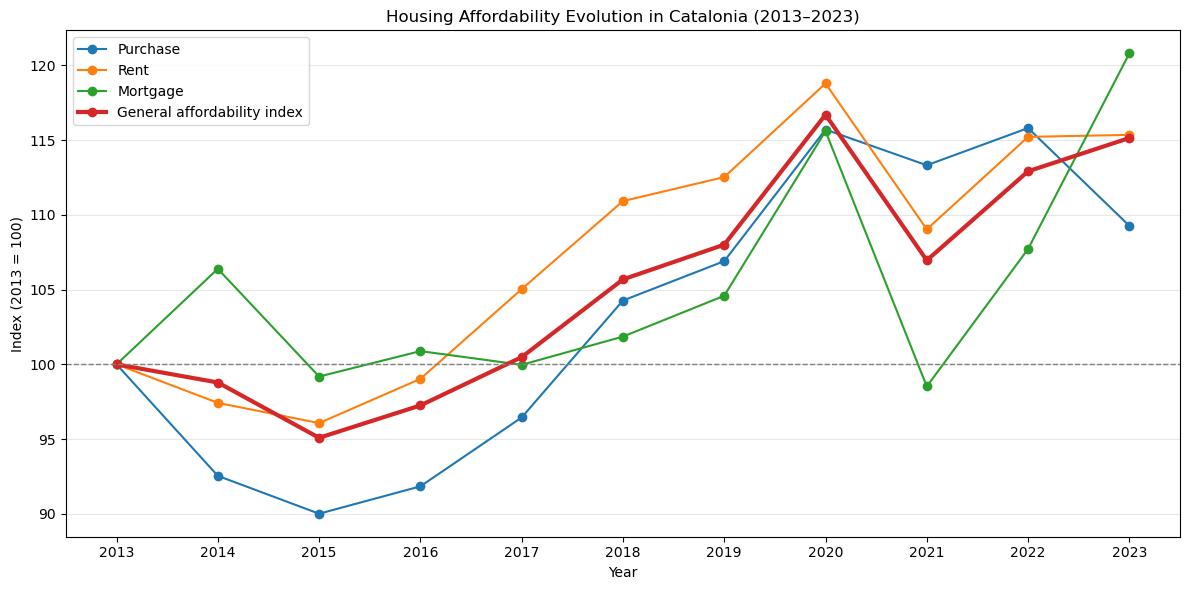

In [213]:
# Plot the general housing affordability index

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    general_affordability.index,
    general_affordability["purchase_ratio_index"],
    marker="o",
    label="Purchase"
)

plt.plot(
    general_affordability.index,
    general_affordability["rental_effort_pct_index"],
    marker="o",
    label="Rent"
)

plt.plot(
    general_affordability.index,
    general_affordability["mortgage_effort_pct_index"],
    marker="o",
    label="Mortgage"
)

plt.plot(
    general_affordability.index,
    general_affordability["general_affordability_index"],
    marker="o",
    linewidth=3,
    label="General affordability index"
)

plt.axhline(100, color="gray", linestyle="--", linewidth=1)

plt.title("Housing Affordability Evolution in Catalonia (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Index (2013 = 100)")
plt.xticks(general_affordability.index)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [214]:
# Inspect annual changes in the three affordability components

components = [
    "purchase_ratio",
    "rental_effort_pct",
    "mortgage_effort_pct"
]

annual_changes = general_affordability[components].copy()

for column in components:
    annual_changes[f"{column}_change_pct"] = (
        annual_changes[column].pct_change() * 100
    )

annual_changes.round(2)


,purchase_ratio,rental_effort_pct,mortgage_effort_pct,purchase_ratio_change_pct,rental_effort_pct_change_pct,mortgage_effort_pct_change_pct
year,,,,,,
2013,10.05,40.03,49.36,NaN,NaN,NaN
2014,9.30,39.00,52.51,-7.46,-2.57,6.39
2015,9.05,38.46,48.96,-2.74,-1.39,-6.77
2016,9.23,39.65,49.80,2.03,3.08,1.72
2017,9.69,42.05,49.34,5.02,6.06,-0.91
2018,10.48,44.41,50.28,8.11,5.61,1.89
2019,10.74,45.05,51.62,2.53,1.45,2.68
2020,11.63,47.56,57.06,8.23,5.57,10.53
2021,11.39,43.65,48.63,-2.06,-8.22,-14.77


In [215]:
# Inspect mortgage assumptions and annual changes

mortgage_check = mortgage_payment_analysis[
    [
        "year",
        "average_mortgage_eur",
        "interest_rate_pct",
        "monthly_payment_eur"
    ]
].copy()

mortgage_check = mortgage_check[
    mortgage_check["year"].between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)
].sort_values("year")

mortgage_check["payment_change_pct"] = (
    mortgage_check["monthly_payment_eur"].pct_change() * 100
)

mortgage_check.round(2)


,year,average_mortgage_eur,interest_rate_pct,monthly_payment_eur,payment_change_pct
0,2013,130530.97,3.04,621.71,NaN
1,2014,142201.83,2.96,671.38,7.99
2,2015,149171.27,2.25,650.58,-3.10
3,2016,159468.44,2.01,676.69,4.01
4,2017,161194.03,1.95,679.31,0.39
5,2018,166002.66,1.97,701.19,3.22
6,2019,177333.33,1.99,750.77,7.07
7,2020,194714.88,1.73,799.95,6.55
8,2021,180383.31,1.49,720.57,-9.92
9,2022,190711.46,1.98,806.48,11.92


### Evolution of Housing Affordability in Catalonia

Between 2013 and 2023, the general housing affordability index increased by **15.14%**, indicating a deterioration in affordability compared with the 2013 baseline.

The three indicators evolved differently:
- **Purchase affordability index:** increased by 9.27%.
- **Rental affordability index:** increased by 15.35%.
- **Mortgage affordability index:** increased by 20.80%.

Mortgage affordability showed the largest deterioration over the period, reflecting the impact of changes in estimated mortgage payments. These results should be interpreted with caution because the indicators rely on different assumptions and data sources, and the mortgage indicator is based on regional estimates rather than municipality-specific mortgage conditions.

The indices are normalized to 100 in 2013. Therefore, they describe relative changes over time rather than directly comparable affordability levels.

### Impact of the COVID-19 Pandemic on Rental Prices

The COVID-19 pandemic marked a potential turning point in the rental housing market. Average registered rental prices declined between 2019 and 2021, before recovering and increasing in subsequent years.

This period provides relevant context for interpreting rental affordability trends. However, the pandemic's causal effect cannot be established through this descriptive analysis alone.

The findings should also be interpreted in light of the rental indicator used. Average registered contract prices may differ substantially from advertised prices for individual properties, so specific rental experiences should not be directly compared with municipal or city-wide averages.

## Afordability analysis by municipality (2013–2023)

In [216]:
# Build the existing component indices from the purchase and rental affordability ratios.
# Each municipality retains 2013 = 100; the combined index below remains unchanged.
purchase_index = purchase_affordability[
    ["municipality_code", "municipality", "year", "price_to_income_ratio"]
].copy()
purchase_baseline = (
    purchase_index.loc[
        purchase_index["year"].eq(ANALYSIS_START_YEAR),
        ["municipality_code", "price_to_income_ratio"],
    ]
    .rename(columns={"price_to_income_ratio": "baseline_purchase_ratio"})
)
if purchase_baseline["municipality_code"].duplicated().any():
    raise ValueError("Purchase index has multiple baseline rows for a municipality.")
purchase_index = purchase_index.merge(
    purchase_baseline, on="municipality_code", how="left", validate="many_to_one"
)
purchase_index["purchase_affordability_index"] = (
    purchase_index["price_to_income_ratio"]
    .div(purchase_index["baseline_purchase_ratio"].where(purchase_index["baseline_purchase_ratio"].ne(0)))
    * 100
)

rental_index = rental_affordability[
    ["municipality_code", "municipality", "year", "rental_effort_pct"]
].copy()
rental_baseline = (
    rental_index.loc[
        rental_index["year"].eq(ANALYSIS_START_YEAR),
        ["municipality_code", "rental_effort_pct"],
    ]
    .rename(columns={"rental_effort_pct": "baseline_rental_effort_pct"})
)
if rental_baseline["municipality_code"].duplicated().any():
    raise ValueError("Rental index has multiple baseline rows for a municipality.")
rental_index = rental_index.merge(
    rental_baseline, on="municipality_code", how="left", validate="many_to_one"
)
rental_index["rental_affordability_index"] = (
    rental_index["rental_effort_pct"]
    .div(rental_index["baseline_rental_effort_pct"].where(rental_index["baseline_rental_effort_pct"].ne(0)))
    * 100
)

# Validate the municipality-specific baseline without resetting it in later subperiods.
purchase_baseline_check = purchase_index.loc[
    purchase_index["year"].eq(ANALYSIS_START_YEAR), "purchase_affordability_index"
].dropna()
rental_baseline_check = rental_index.loc[
    rental_index["year"].eq(ANALYSIS_START_YEAR), "rental_affordability_index"
].dropna()
print("Purchase index baseline values (expected 100):", purchase_baseline_check.round(6).unique()[:5])
print("Rental index baseline values (expected 100):", rental_baseline_check.round(6).unique()[:5])
assert len(purchase_baseline_check) == purchase_index["municipality_code"].nunique(), "Some municipalities lack a purchase baseline."
assert len(rental_baseline_check) == rental_index["municipality_code"].nunique(), "Some municipalities lack a rental baseline."
assert np.allclose(purchase_baseline_check.to_numpy(), 100), "Purchase index baseline is not 100."
assert np.allclose(rental_baseline_check.to_numpy(), 100), "Rental index baseline is not 100."


Purchase index baseline values (expected 100): [100.]
Rental index baseline values (expected 100): [100.]


In [217]:
# Create a combined purchase and rental affordability index

combined_affordability = (
    purchase_index[
        ["municipality_code", "municipality", "year",
         "purchase_affordability_index"]
    ]
    .merge(
        rental_index[
            ["municipality_code", "year",
             "rental_affordability_index"]
        ],
        on=["municipality_code", "year"],
        how="inner",
        validate="one_to_one"
    )
)

combined_affordability["combined_affordability_index"] = (
    combined_affordability["purchase_affordability_index"]
    + combined_affordability["rental_affordability_index"]
) / 2

combined_affordability = combined_affordability.sort_values(
    ["municipality", "year"]
).reset_index(drop=True)

combined_affordability.head()


,municipality_code,municipality,year,purchase_affordability_index,rental_affordability_index,combined_affordability_index
0,08015,Badalona,2013,100.000000,100.000000,100.000000
1,08015,Badalona,2014,103.098044,97.609420,100.353732
2,08015,Badalona,2015,90.712949,95.793282,93.253115
3,08015,Badalona,2016,92.605479,101.155318,96.880399
4,08015,Badalona,2017,101.883267,109.691979,105.787623


In [218]:
# Validate the existing combined index and its municipality-specific 2013 baseline.
expected_years = set(range(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR + 1))
observed_years = set(combined_affordability["year"].dropna().astype(int))
missing_years = sorted(expected_years - observed_years)
duplicate_keys = combined_affordability.duplicated(["municipality_code", "year"]).sum()
baseline_values = combined_affordability.loc[
    combined_affordability["year"].eq(ANALYSIS_START_YEAR), "combined_affordability_index"
].dropna()

print("Combined index rows:", len(combined_affordability))
print("Municipalities:", combined_affordability["municipality_code"].nunique())
print("Years:", min(observed_years), "-", max(observed_years))
print("Missing expected years:", missing_years)
print("Duplicate municipality-year keys:", duplicate_keys)
print("Combined index baseline values (expected 100):", baseline_values.round(6).unique()[:5])

assert not missing_years, f"Combined affordability index is missing years: {missing_years}"
assert duplicate_keys == 0, "Combined affordability index has duplicate municipality-year keys"
assert np.allclose(baseline_values.to_numpy(), 100), "Combined index does not retain the 2013 = 100 baseline"
assert combined_affordability["municipality_code"].nunique() == 47, "Combined index does not contain 47 municipalities"


Combined index rows: 517
Municipalities: 47
Years: 2013 - 2023
Missing expected years: []
Duplicate municipality-year keys: 0
Combined index baseline values (expected 100): [100.]


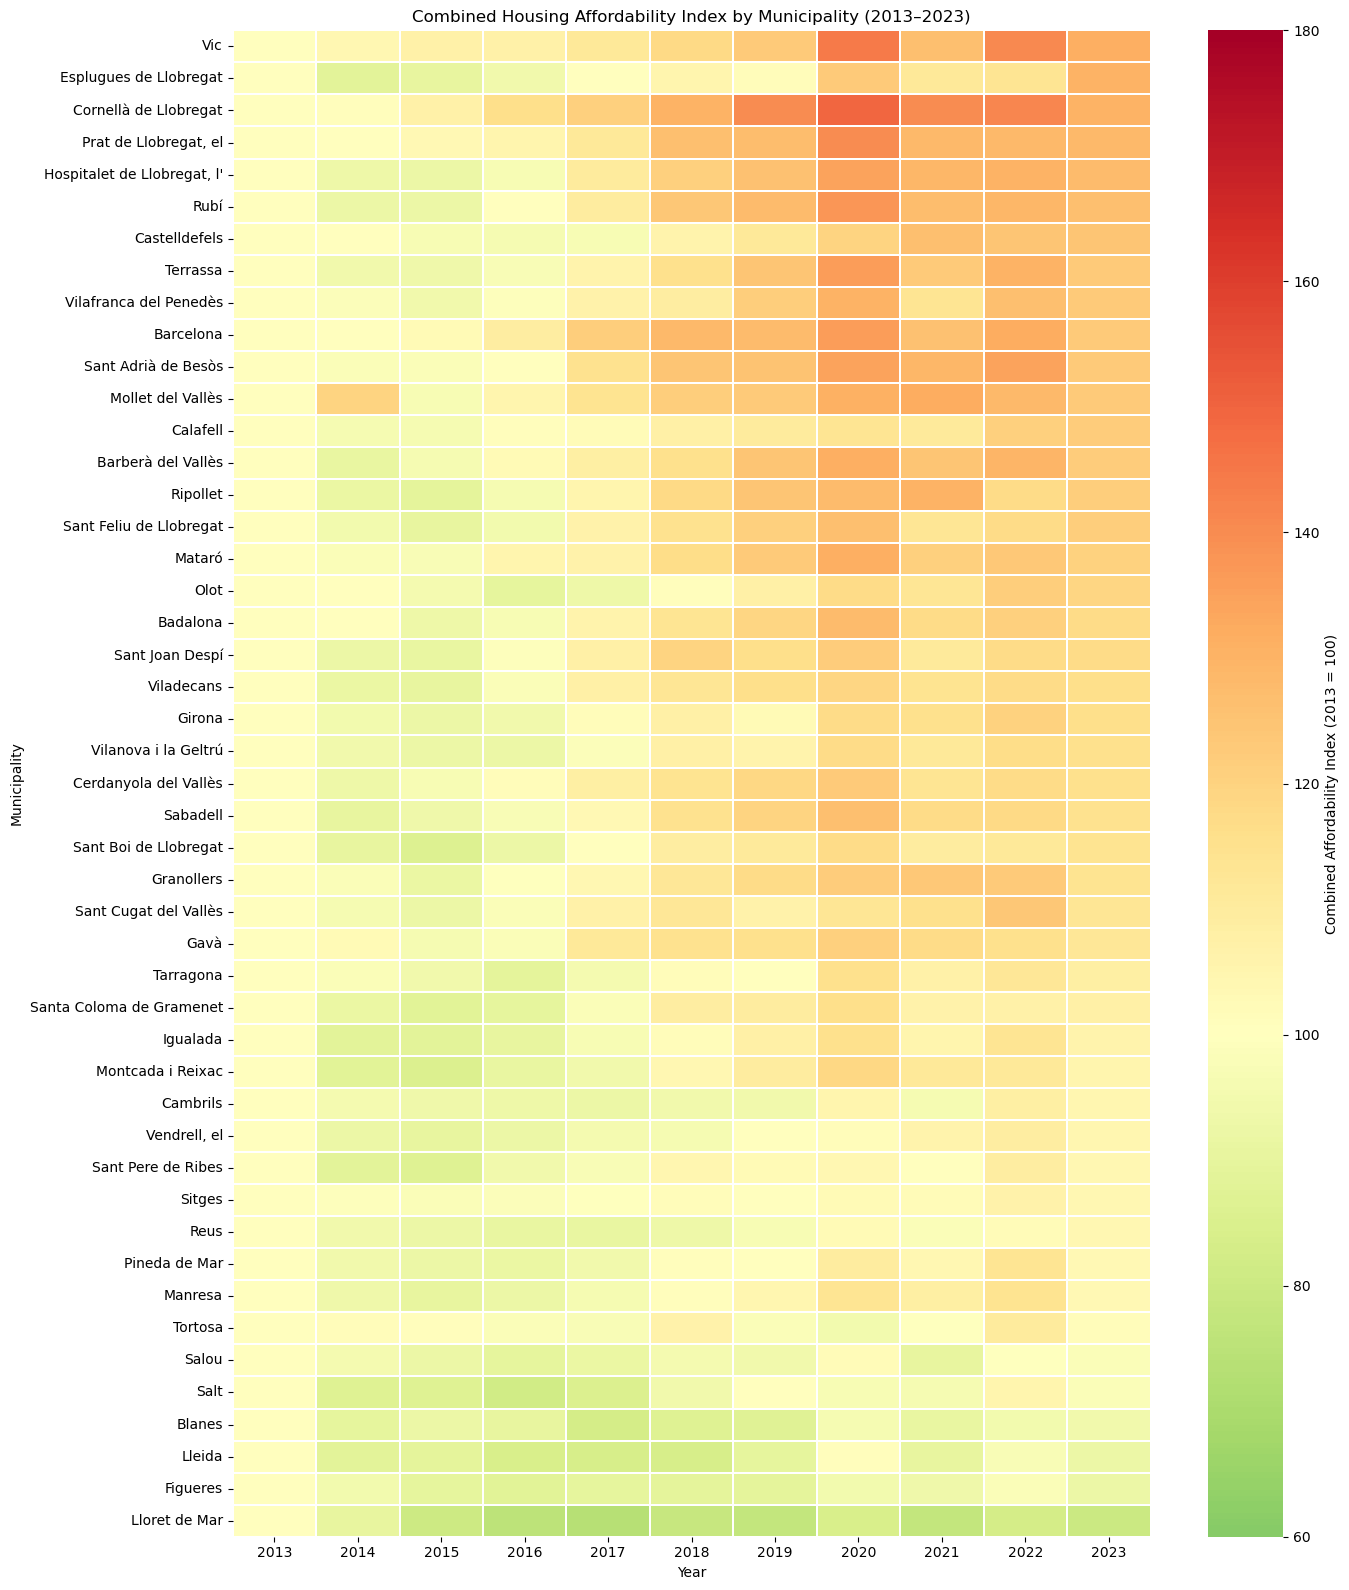

In [219]:
# Heatmap of the combined affordability index by municipality

combined_heatmap = combined_affordability.pivot(
    index="municipality",
    columns="year",
    values="combined_affordability_index"
)

combined_heatmap = combined_heatmap.sort_values(
    by=ANALYSIS_END_YEAR,
    ascending=False
) 

plt.figure(figsize=(14, 16))

sns.heatmap(
    combined_heatmap,
    cmap="RdYlGn_r",
    center=100,
    vmin=60,
    vmax=180,
    annot=False,
    linewidths=0.2,
    cbar_kws={"label": "Combined Affordability Index (2013 = 100)"}
)

plt.title("Combined Housing Affordability Index by Municipality (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Municipality")
plt.tight_layout()
plt.show()


In [220]:
# Compare the existing combined municipal affordability index over the full analysis period.
# The component indices retain their original municipality-specific 2013 = 100 baseline.
combined_period = combined_affordability.pivot(
    index=["municipality_code", "municipality"],
    columns="year",
    values="combined_affordability_index",
)

required_years = [ANALYSIS_START_YEAR, ANALYSIS_END_YEAR]
missing_years = set(required_years) - set(combined_period.columns)
if missing_years:
    raise ValueError(f"Combined affordability index is missing endpoint years: {sorted(missing_years)}")

start_index = combined_period[ANALYSIS_START_YEAR]
end_index = combined_period[ANALYSIS_END_YEAR]
elapsed_years = ELAPSED_ANALYSIS_YEARS
index_ratio = end_index.div(start_index.where(start_index.ne(0)))

period_comparison = combined_period[[]].copy()
period_comparison["absolute_change_index_points"] = end_index - start_index
period_comparison["cumulative_change_pct"] = (index_ratio - 1) * 100
period_comparison["annualized_change_pct"] = (index_ratio.pow(1 / elapsed_years) - 1) * 100
period_comparison = period_comparison.reset_index()

display(period_comparison.head())


year,municipality_code,municipality,absolute_change_index_points,cumulative_change_pct,annualized_change_pct
0,08015,Badalona,17.354464,17.354464,1.613161
1,08019,Barcelona,23.129726,23.129726,2.102480
2,08056,Castelldefels,24.263571,24.263571,2.196114
3,08073,Cornellà de Llobregat,30.056091,30.056091,2.662792
4,08077,Esplugues de Llobregat,30.520728,30.520728,2.699410


In [221]:
# Top and bottom municipal rankings use the same combined index and 2013–2023 endpoints.
print("Top 10 municipalities by cumulative affordability deterioration:")
display(
    period_comparison.nlargest(10, "cumulative_change_pct")[
        ["municipality", "absolute_change_index_points", "cumulative_change_pct", "annualized_change_pct"]
    ].reset_index(drop=True).style.format({
        "absolute_change_index_points": "{:+.2f}",
        "cumulative_change_pct": "{:+.2f}%",
        "annualized_change_pct": "{:+.2f}%",
    })
)

print("Bottom 10 municipalities by cumulative affordability deterioration:")
display(
    period_comparison.nsmallest(10, "cumulative_change_pct")[
        ["municipality", "absolute_change_index_points", "cumulative_change_pct", "annualized_change_pct"]
    ].reset_index(drop=True).style.format({
        "absolute_change_index_points": "{:+.2f}",
        "cumulative_change_pct": "{:+.2f}%",
        "annualized_change_pct": "{:+.2f}%",
    })
)


Top 10 municipalities by cumulative affordability deterioration:


year,municipality,absolute_change_index_points,cumulative_change_pct,annualized_change_pct
0,Vic,+31.41,+31.41%,+2.77%
1,Esplugues de Llobregat,+30.52,+30.52%,+2.70%
2,Cornellà de Llobregat,+30.06,+30.06%,+2.66%
3,"Prat de Llobregat, el",+28.51,+28.51%,+2.54%
4,"Hospitalet de Llobregat, l'",+27.59,+27.59%,+2.47%
5,Rubí,+26.27,+26.27%,+2.36%
6,Castelldefels,+24.26,+24.26%,+2.20%
7,Terrassa,+23.25,+23.25%,+2.11%
8,Vilafranca del Penedès,+23.19,+23.19%,+2.11%
9,Barcelona,+23.13,+23.13%,+2.10%


Bottom 10 municipalities by cumulative affordability deterioration:


year,municipality,absolute_change_index_points,cumulative_change_pct,annualized_change_pct
0,Lloret de Mar,-20.26,-20.26%,-2.24%
1,Figueres,-7.98,-7.98%,-0.83%
2,Lleida,-7.41,-7.41%,-0.77%
3,Blanes,-5.69,-5.69%,-0.58%
4,Salt,-2.11,-2.11%,-0.21%
5,Salou,-1.97,-1.97%,-0.20%
6,Tortosa,+1.72,+1.72%,+0.17%
7,Manresa,+3.16,+3.16%,+0.31%
8,Pineda de Mar,+3.56,+3.56%,+0.35%
9,Reus,+3.64,+3.64%,+0.36%


In [222]:
# Rank using the annualized full-period rate; duration is ANALYSIS_END_YEAR - ANALYSIS_START_YEAR.
print("Top 10 municipalities by annualized affordability deterioration:")
display(
    period_comparison.nlargest(10, "annualized_change_pct")[
        ["municipality", "annualized_change_pct", "cumulative_change_pct"]
    ].reset_index(drop=True).style.format({
        "annualized_change_pct": "{:+.2f}%",
        "cumulative_change_pct": "{:+.2f}%",
    })
)

print("Bottom 10 municipalities by annualized affordability deterioration:")
display(
    period_comparison.nsmallest(10, "annualized_change_pct")[
        ["municipality", "annualized_change_pct", "cumulative_change_pct"]
    ].reset_index(drop=True).style.format({
        "annualized_change_pct": "{:+.2f}%",
        "cumulative_change_pct": "{:+.2f}%",
    })
)


Top 10 municipalities by annualized affordability deterioration:


year,municipality,annualized_change_pct,cumulative_change_pct
0,Vic,+2.77%,+31.41%
1,Esplugues de Llobregat,+2.70%,+30.52%
2,Cornellà de Llobregat,+2.66%,+30.06%
3,"Prat de Llobregat, el",+2.54%,+28.51%
4,"Hospitalet de Llobregat, l'",+2.47%,+27.59%
5,Rubí,+2.36%,+26.27%
6,Castelldefels,+2.20%,+24.26%
7,Terrassa,+2.11%,+23.25%
8,Vilafranca del Penedès,+2.11%,+23.19%
9,Barcelona,+2.10%,+23.13%


Bottom 10 municipalities by annualized affordability deterioration:


year,municipality,annualized_change_pct,cumulative_change_pct
0,Lloret de Mar,-2.24%,-20.26%
1,Figueres,-0.83%,-7.98%
2,Lleida,-0.77%,-7.41%
3,Blanes,-0.58%,-5.69%
4,Salt,-0.21%,-2.11%
5,Salou,-0.20%,-1.97%
6,Tortosa,+0.17%,+1.72%
7,Manresa,+0.31%,+3.16%
8,Pineda de Mar,+0.35%,+3.56%
9,Reus,+0.36%,+3.64%


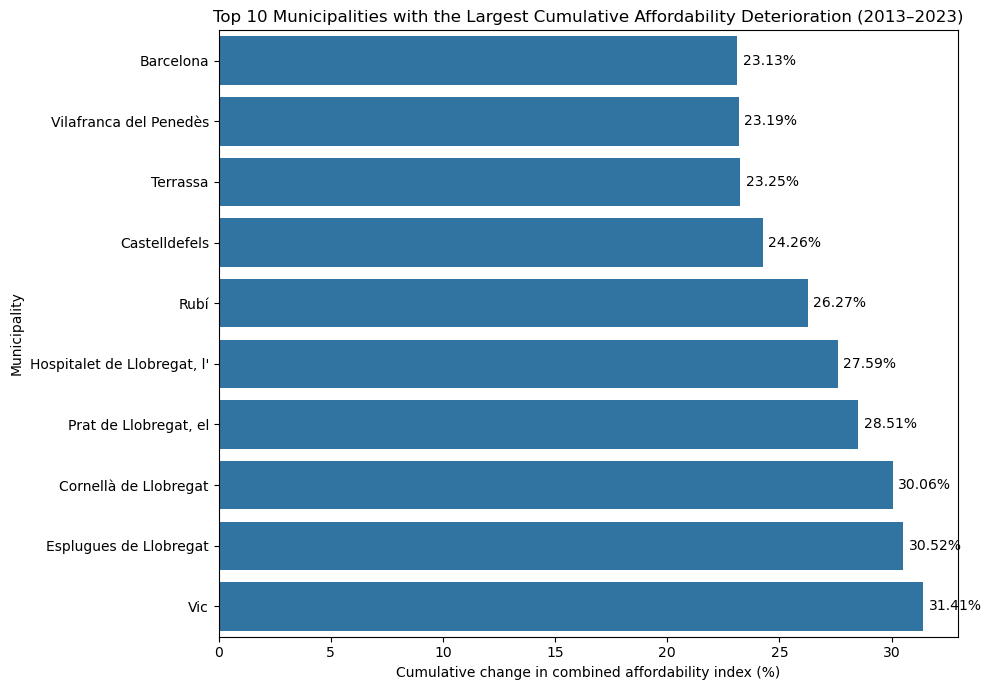

In [223]:
# Visualize cumulative change in the existing combined affordability index over 2013–2023.
top_10_cumulative = period_comparison.nlargest(10, "cumulative_change_pct").sort_values("cumulative_change_pct")

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=top_10_cumulative, x="cumulative_change_pct", y="municipality", orient="h", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_title(f"Top 10 Municipalities with the Largest Cumulative Affordability Deterioration ({ANALYSIS_START_YEAR}–{ANALYSIS_END_YEAR})")
ax.set_xlabel("Cumulative change in combined affordability index (%)")
ax.set_ylabel("Municipality")
plt.tight_layout()
plt.show()


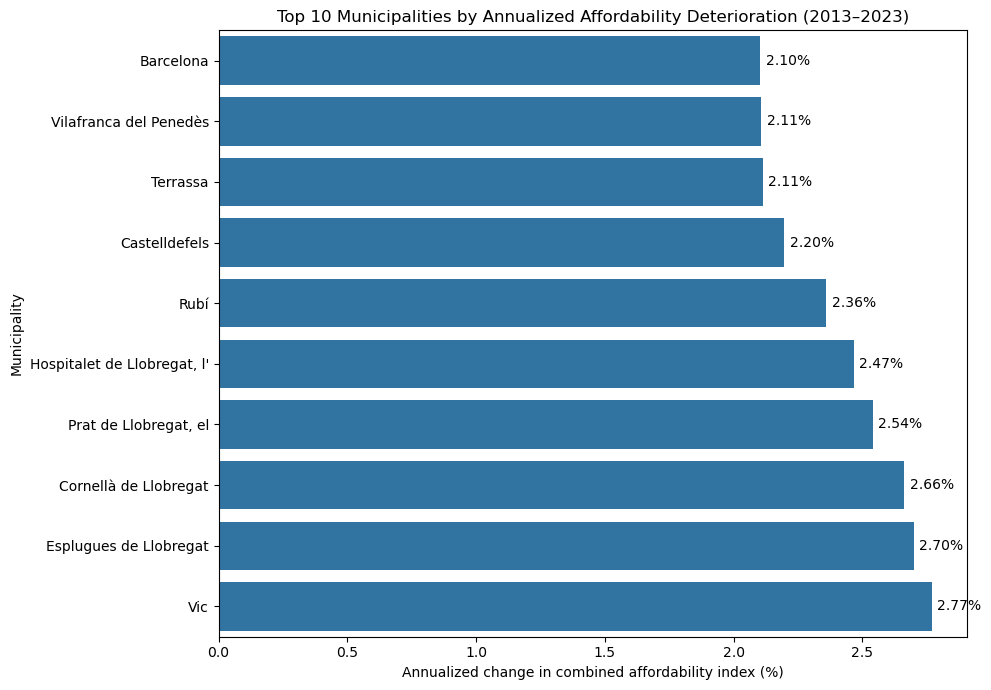

In [224]:
# Visualize annualized change in the existing combined affordability index over the full period.
top_10_full_period = period_comparison.nlargest(10, "annualized_change_pct").sort_values("annualized_change_pct")

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=top_10_full_period, x="annualized_change_pct", y="municipality", orient="h", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_title(f"Top 10 Municipalities by Annualized Affordability Deterioration ({ANALYSIS_START_YEAR}–{ANALYSIS_END_YEAR})")
ax.set_xlabel("Annualized change in combined affordability index (%)")
ax.set_ylabel("Municipality")
plt.tight_layout()
plt.show()


In [225]:
# Define municipality distance quartiles for the final affordability comparison.
# This grouping uses distance to Barcelona, matching the title of the following analysis.
distance_quartiles = distance_analysis[
    ["municipality_code", "municipality", "distance_to_barcelona_km"]
].drop_duplicates().copy()

if distance_quartiles["municipality_code"].duplicated().any():
    raise ValueError("Distance data contains multiple rows per municipality code.")
if distance_quartiles["distance_to_barcelona_km"].isna().any():
    raise ValueError("Distance to Barcelona is missing for one or more municipalities.")

distance_quartiles["distance_quartile"] = pd.qcut(
    distance_quartiles["distance_to_barcelona_km"],
    q=4,
    labels=["Q1 - Closest", "Q2", "Q3", "Q4 - Farthest"],
)

print("Municipalities assigned to distance quartiles:",
      distance_quartiles["municipality_code"].nunique())
print(distance_quartiles["distance_quartile"].value_counts().sort_index())

assert distance_quartiles["municipality_code"].nunique() == 47
assert distance_quartiles["distance_quartile"].notna().all()


Municipalities assigned to distance quartiles: 47
distance_quartile
Q1 - Closest     12
Q2               12
Q3               11
Q4 - Farthest    12
Name: count, dtype: int64


In [226]:
# Merge distance quartiles with the combined affordability index

combined_affordability_distance = combined_affordability.merge(
    distance_quartiles[
        ["municipality_code", "distance_quartile"]
    ],
    on="municipality_code",
    how="left",
    validate="many_to_one"
)

print("Shape:", combined_affordability_distance.shape)
print(
    "Municipalities:",
    combined_affordability_distance["municipality"].nunique()
)
print(
    "Missing distance quartiles:",
    combined_affordability_distance["distance_quartile"].isna().sum()
)

combined_affordability_distance.head()

Shape: (517, 7)
Municipalities: 47
Missing distance quartiles: 0


,municipality_code,municipality,year,purchase_affordability_index,rental_affordability_index,combined_affordability_index,distance_quartile
0,08015,Badalona,2013,100.000000,100.000000,100.000000,Q1 - Closest
1,08015,Badalona,2014,103.098044,97.609420,100.353732,Q1 - Closest
2,08015,Badalona,2015,90.712949,95.793282,93.253115,Q1 - Closest
3,08015,Badalona,2016,92.605479,101.155318,96.880399,Q1 - Closest
4,08015,Badalona,2017,101.883267,109.691979,105.787623,Q1 - Closest


In [227]:
# Calculate average combined affordability index by distance quartile and year

affordability_by_distance = (
    combined_affordability_distance
    .groupby(
        ["year", "distance_quartile"],
        observed=False
    )["combined_affordability_index"]
    .mean()
    .reset_index()
)

affordability_by_distance.head(12)

,year,distance_quartile,combined_affordability_index
0,2013,Q1 - Closest,100.000000
1,2013,Q2,100.000000
2,2013,Q3,100.000000
3,2013,Q4 - Farthest,100.000000
4,2014,Q1 - Closest,94.753237
5,2014,Q2,97.096280
6,2014,Q3,94.946887
7,2014,Q4 - Farthest,94.247399
8,2015,Q1 - Closest,94.076733
9,2015,Q2,94.113452


In [233]:

# Summarize municipality-level affordability changes by distance quartile

quartile_change_summary = (
    municipality_changes
    .groupby("distance_quartile", observed=False)
    .agg(
        municipality_count=("municipality", "nunique"),
        mean_change_pct=("change_pct", "mean"),
        median_change_pct=("change_pct", "median"),
        std_change_pct=("change_pct", "std"),
        min_change_pct=("change_pct", "min"),
        max_change_pct=("change_pct", "max")
    )
    .reset_index()
)

quartile_change_summary




,distance_quartile,municipality_count,mean_change_pct,median_change_pct,std_change_pct,min_change_pct,max_change_pct
0,Q1 - Closest,12,20.503901,22.327447,8.416537,5.208208,30.520728
1,Q2,12,18.483137,18.130155,4.866404,12.141955,26.269895
2,Q3,11,12.793862,6.012901,10.513216,3.162296,31.405631
3,Q4 - Farthest,12,0.686263,-0.126211,10.841199,-20.259492,19.139987


In [234]:

# Test differences in affordability changes across distance quartiles

from scipy.stats import kruskal

quartile_groups = [
    group["change_pct"].dropna().to_numpy()
    for _, group in municipality_changes.groupby(
        "distance_quartile",
        observed=False,
        sort=True
    )
]

kruskal_statistic, kruskal_p_value = kruskal(*quartile_groups)

print(f"Kruskal-Wallis statistic: {kruskal_statistic:.4f}")
print(f"P-value: {kruskal_p_value:.6f}")

alpha = 0.05

if kruskal_p_value < alpha:
    print(
        "Result: Evidence of differences in affordability-change "
        "distributions across at least two distance quartiles."
    )
else:
    print(
        "Result: Insufficient evidence to conclude that affordability-change "
        "distributions differ across distance quartiles."
    )


Kruskal-Wallis statistic: 18.6017
P-value: 0.000330
Result: Evidence of differences in affordability-change distributions across at least two distance quartiles.


In [235]:

# Perform pairwise Mann-Whitney U tests with Holm correction

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

quartile_order = [
    "Q1 - Closest",
    "Q2",
    "Q3",
    "Q4 - Farthest"
]

pairwise_results = []

for group_1, group_2 in combinations(quartile_order, 2):
    values_1 = municipality_changes.loc[
        municipality_changes["distance_quartile"] == group_1,
        "change_pct"
    ].dropna()

    values_2 = municipality_changes.loc[
        municipality_changes["distance_quartile"] == group_2,
        "change_pct"
    ].dropna()

    statistic, p_value = mannwhitneyu(
        values_1,
        values_2,
        alternative="two-sided"
    )

    pairwise_results.append({
        "group_1": group_1,
        "group_2": group_2,
        "n_1": len(values_1),
        "n_2": len(values_2),
        "u_statistic": statistic,
        "p_value": p_value
    })

pairwise_results = pd.DataFrame(pairwise_results)

pairwise_results["p_value_holm"] = multipletests(
    pairwise_results["p_value"],
    method="holm"
)[1]

pairwise_results["significant"] = (
    pairwise_results["p_value_holm"] < 0.05
)

pairwise_results.sort_values("p_value_holm")


,group_1,group_2,n_1,n_2,u_statistic,p_value,p_value_holm,significant
2,Q1 - Closest,Q4 - Farthest,12,12,134.0,0.000384,0.002305,True
4,Q2,Q4 - Farthest,12,12,133.0,0.000478,0.002388,True
5,Q3,Q4 - Farthest,11,12,105.0,0.017812,0.071246,False
1,Q1 - Closest,Q3,12,11,94.0,0.090549,0.271647,False
0,Q1 - Closest,Q2,12,12,90.0,0.312321,0.460168,False
3,Q2,Q3,12,11,86.0,0.230084,0.460168,False


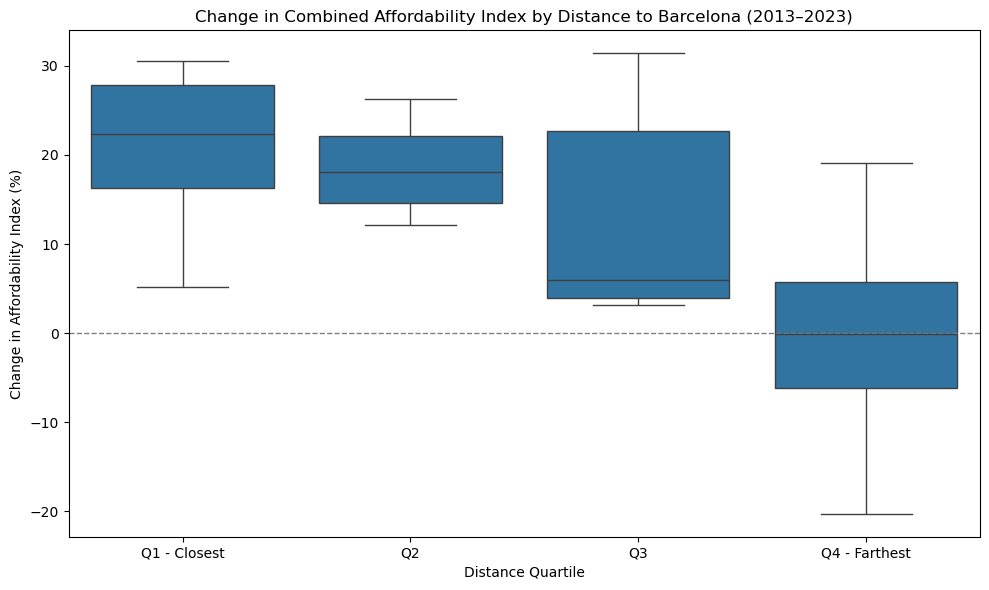

In [236]:

# Compare municipality-level affordability changes by distance quartile

import seaborn as sns
import matplotlib.pyplot as plt

quartile_order = [
    "Q1 - Closest",
    "Q2",
    "Q3",
    "Q4 - Farthest"
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=municipality_changes,
    x="distance_quartile",
    y="change_pct",
    order=quartile_order
)

plt.axhline(0, linestyle="--", linewidth=1, color="gray")

plt.title("Change in Combined Affordability Index by Distance to Barcelona (2013–2023)")
plt.xlabel("Distance Quartile")
plt.ylabel("Change in Affordability Index (%)")
plt.tight_layout()
plt.show()


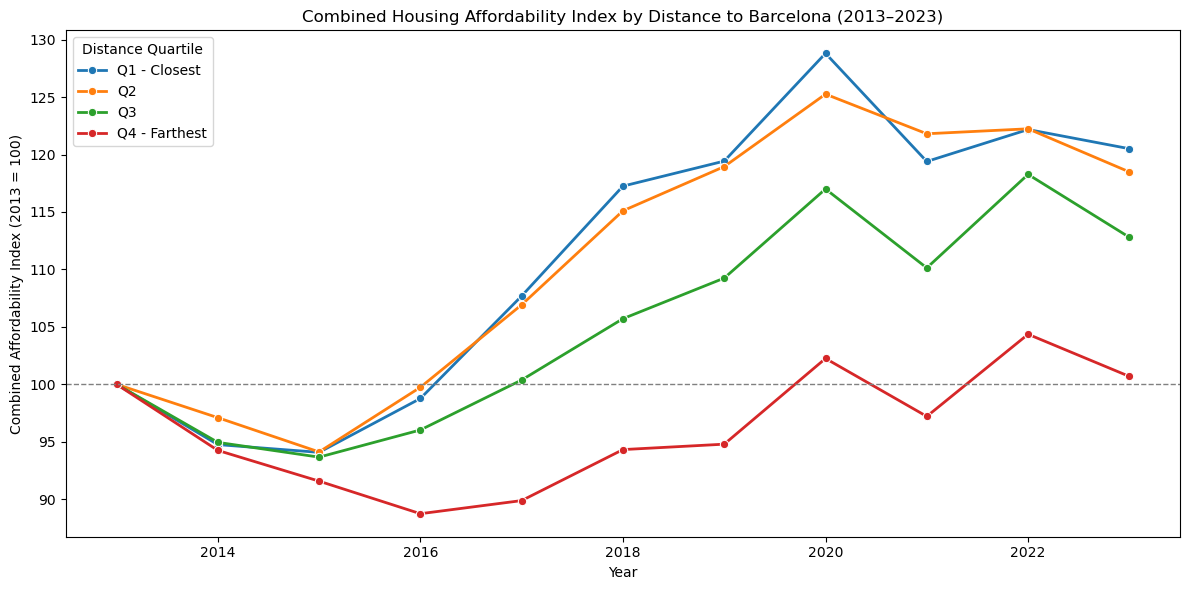

In [228]:
# Plot combined affordability index by distance quartile

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=affordability_by_distance,
    x="year",
    y="combined_affordability_index",
    hue="distance_quartile",
    marker="o",
    linewidth=2
)

plt.axhline(100, color="gray", linestyle="--", linewidth=1)

plt.title("Combined Housing Affordability Index by Distance to Barcelona (2013–2023)")
plt.xlabel("Year")
plt.ylabel("Combined Affordability Index (2013 = 100)")
plt.legend(title="Distance Quartile")
plt.tight_layout()
plt.show()


In [229]:
# Compare combined affordability changes by distance quartile and period

quartile_yearly = affordability_by_distance.pivot(
    index="distance_quartile",
    columns="year",
    values="combined_affordability_index"
)

period_definitions = {
    "2014-2016": (2014, 2016),
    "2017-2019": (2017, 2019),
    "2020-2023": (2020, 2023),
    "Full period (2013-2023)": (
        ANALYSIS_START_YEAR,
        ANALYSIS_END_YEAR
    )
}

quartile_period_results = []

for period, (start_year, end_year) in period_definitions.items():
    for quartile in quartile_yearly.index:
        start_value = quartile_yearly.loc[quartile, start_year]
        end_value = quartile_yearly.loc[quartile, end_year]

        cumulative_change_pct = (
            (end_value / start_value) - 1
        ) * 100

        quartile_period_results.append({
            "Period": period,
            "Distance quartile": quartile,
            "Start index": start_value,
            "End index": end_value,
            "Cumulative change (%)": cumulative_change_pct
        })

quartile_period_comparison = pd.DataFrame(
    quartile_period_results
)

quartile_period_comparison.round(2)

,Period,Distance quartile,Start index,End index,Cumulative change (%)
0,2014-2016,Q1 - Closest,94.75,98.77,4.23
1,2014-2016,Q2,97.10,99.74,2.72
2,2014-2016,Q3,94.95,96.03,1.14
3,2014-2016,Q4 - Farthest,94.25,88.74,-5.85
4,2017-2019,Q1 - Closest,107.69,119.43,10.90
5,2017-2019,Q2,106.92,118.95,11.25
6,2017-2019,Q3,100.38,109.24,8.83
7,2017-2019,Q4 - Farthest,89.88,94.79,5.46
8,2020-2023,Q1 - Closest,128.80,120.50,-6.44
9,2020-2023,Q2,125.25,118.48,-5.41


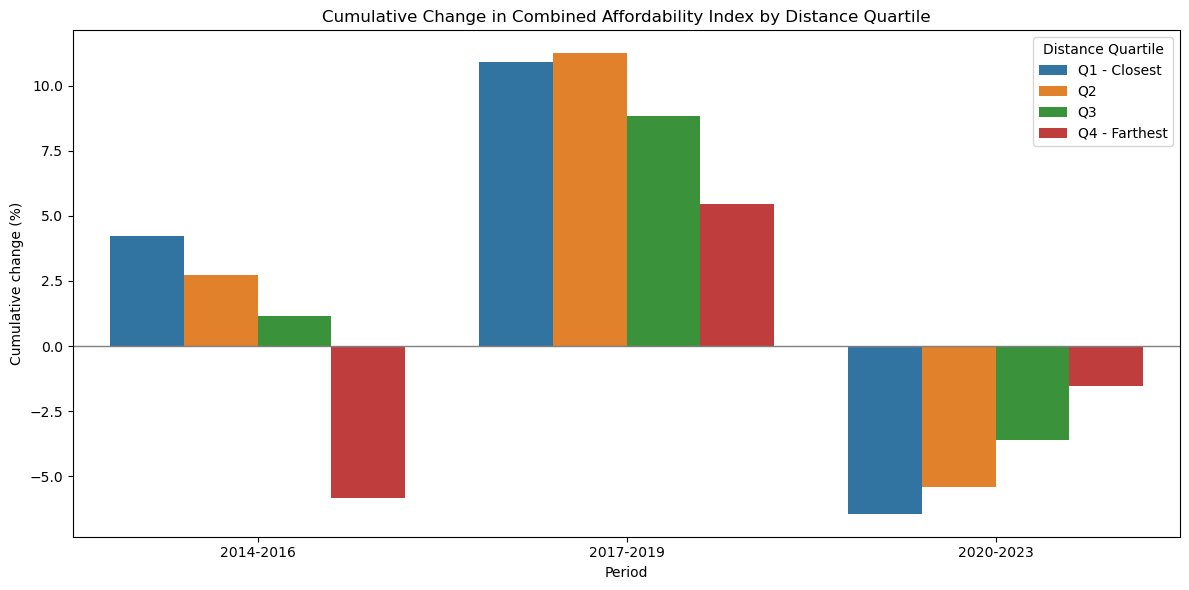

In [230]:
# Plot cumulative affordability changes by period and distance quartile

plt.figure(figsize=(12, 6))

sns.barplot(
    data=quartile_period_comparison[
        quartile_period_comparison["Period"] != "Full period (2013-2023)"
    ],
    x="Period",
    y="Cumulative change (%)",
    hue="Distance quartile"
)

plt.axhline(0, color="gray", linewidth=1)
plt.title("Cumulative Change in Combined Affordability Index by Distance Quartile")
plt.xlabel("Period")
plt.ylabel("Cumulative change (%)")
plt.legend(title="Distance Quartile")
plt.tight_layout()
plt.show()

### Distance to Barcelona and Housing Affordability, 2013–2023

Municipalities closer to Barcelona experienced a greater average deterioration in the combined affordability index between 2013 and 2023. The mean change ranged from +20.50% in the closest distance quartile to +0.69% in the farthest quartile.

A Kruskal–Wallis test identified statistically significant differences across distance groups (H = 18.60, p < 0.001). Pairwise comparisons with Holm correction showed significant differences between the closest and farthest quartiles and between the second-closest and farthest quartiles.

These findings indicate a territorial association between distance to Barcelona and changes in relative housing affordability. They do not establish causality, and substantial variation between municipalities remains, particularly in the third distance quartile.